# 1. Setup & Data Loading


**Packages used by the models and explanations.** Installed here once, so the whole notebook runs top to bottom:
- `xgboost`: gradient-boosted trees (5.2.3), also used in the ablation (6) and explanations (7)
- `tensorflow`: the shallow neural network (5.3)
- `shap`: SHAP explanations, global and for one prediction (7)
- `lime`: LIME explanation for one prediction (7)

The cell installs only what is missing, and keeps the installed numpy version fixed so that nothing else in the environment changes. On Kaggle the first three are already installed, so only `lime` is added (internet must be switched on in the notebook settings).


In [ ]:
import importlib.util
import numpy as np

# Install only the packages that are missing. The installed numpy version is pinned so pip cannot
# upgrade or downgrade it (a numpy change can break pandas and other already-installed packages).
missing = [p for p in ["xgboost", "tensorflow", "shap", "lime"] if importlib.util.find_spec(p) is None]
if missing:
    %pip install -q {" ".join(missing)} numpy=={np.__version__}
print("Installed now:", missing if missing else "nothing, all packages were already available")


Installed now: nothing, all packages were already available


In [ ]:
# Core data manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# General utilities
import os
import warnings

# Notebook settings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

# Reproducibility
RANDOM_STATE = 42

print("Setup complete.")

Setup complete.


colab's

In [ ]:
import os
from google.colab import userdata

os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
!pip install -q kaggle
!mkdir -p /content/f1_data

!kaggle datasets download \
    -d rohanrao/formula-1-world-championship-1950-2020 \
    -p /content/f1_data \
    --unzip

DATA_PATH = "/content/f1_data"

sorted(os.listdir(DATA_PATH))

Dataset URL: https://www.kaggle.com/datasets/rohanrao/formula-1-world-championship-1950-2020
License(s): CC0-1.0
100% 6.28M/6.28M [00:00<00:00, 150MB/s]



['circuits.csv',
 'constructor_results.csv',
 'constructor_standings.csv',
 'constructors.csv',
 'driver_standings.csv',
 'drivers.csv',
 'lap_times.csv',
 'pit_stops.csv',
 'qualifying.csv',
 'races.csv',
 'results.csv',
 'seasons.csv',
 'sprint_results.csv',
 'status.csv']

kaggle's

In [ ]:
# On Colab / Kaggle: uncomment these lines and delete the LOCAL cell below.
# import os
# import pandas as pd

# # Updated path for Google Colab environment
# DATA_PATH = "/content/f1_data"

# files = os.listdir(DATA_PATH)
# files

local (this computer only: delete this cell and the next one before uploading to Kaggle / Colab)

In [ ]:
# # LOCAL ONLY: read the 14 CSVs from this computer
# import os
# import pandas as pd

# DATA_PATH = r"C:\Users\alaaa\Downloads\f1_data"

# files = sorted(os.listdir(DATA_PATH))


In [ ]:

# Initial reading of raw data
raw_races = pd.read_csv(f"{DATA_PATH}/races.csv") #alaa
raw_results = pd.read_csv(f"{DATA_PATH}/results.csv")
raw_drivers = pd.read_csv(f"{DATA_PATH}/drivers.csv") #yasmeen
raw_constructors = pd.read_csv(f"{DATA_PATH}/constructors.csv")
raw_circuits = pd.read_csv(f"{DATA_PATH}/circuits.csv") #mai
raw_qualifying = pd.read_csv(f"{DATA_PATH}/qualifying.csv")
raw_status = pd.read_csv(f"{DATA_PATH}/status.csv") #esraa
raw_driver_standings = pd.read_csv(f"{DATA_PATH}/driver_standings.csv")
raw_constructor_standings = pd.read_csv(f"{DATA_PATH}/constructor_standings.csv")

#skip?
raw_sprint_results = pd.read_csv(f"{DATA_PATH}/sprint_results.csv")

#skip lap_times.csv, pit.stops
raw_lap_times = pd.read_csv(f"{DATA_PATH}/lap_times.csv")
raw_pit_stops = pd.read_csv(f"{DATA_PATH}/pit_stops.csv")

# 2 extra missed during the meeting
raw_constructor_results = pd.read_csv(f"{DATA_PATH}/constructor_results.csv")
# points = points earned in that specific race
# constructor_standings
# points = total championship points accumulated up to that race

raw_seasons = pd.read_csv(f"{DATA_PATH}/seasons.csv")


print("All 14 raw tables loaded")


All 14 raw tables loaded


In [ ]:
# Create working copies with the original variable names
races = raw_races.copy()
results = raw_results.copy()
drivers = raw_drivers.copy()
constructors = raw_constructors.copy()
circuits = raw_circuits.copy()
qualifying = raw_qualifying.copy()
status = raw_status.copy()
driver_standings = raw_driver_standings.copy()
constructor_standings = raw_constructor_standings.copy()
sprint_results = raw_sprint_results.copy()
lap_times = raw_lap_times.copy()
pit_stops = raw_pit_stops.copy()
constructor_results = raw_constructor_results.copy()
seasons = raw_seasons.copy()

print("working copies created successfully.")


working copies created successfully.


In [ ]:

# Standardize missing-value representations across all tables

tables = {
    "races": races,
    "results": results,
    "drivers": drivers,
    "constructors": constructors,
    "circuits": circuits,
    "qualifying": qualifying,
    "status": status,
    "driver_standings": driver_standings,
    "constructor_standings": constructor_standings,
    "sprint_results": sprint_results,
    "lap_times": lap_times,
    "pit_stops": pit_stops,
    "constructor_results": constructor_results,
    "seasons": seasons,
}

print(f"Number of tables loaded: {len(tables)}")


Number of tables loaded: 14


In [ ]:
try:
    import missingno as msno
except ModuleNotFoundError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "missingno"])
    import missingno as msno
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def inspect_df(name, df):
    print(f"\n{name}")
    print("-" * 50)

    # -----------------------------
    # Basic structure
    # -----------------------------
    print("\nShape:")
    print(df.shape)

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nInfo:")
    df.info()

    print("\nDtypes:")
    print(df.dtypes)

    print("\nDescriptive Statistics:")
    display(df.describe(include="all"))

    # -----------------------------
    # Duplicate rows
    # -----------------------------
    print("\nFull duplicate rows:")
    print(df.duplicated().sum())

    # -----------------------------
    # Preview
    # -----------------------------
    print("\nFirst 5 rows:")
    display(df.head())

    # -----------------------------
    # Missing values
    # -----------------------------
    print("\nMissing values (actual NaN):")
    print(df.isna().sum())

    missing_tokens = [
        r"\N",
        "NaN",
        "nan",
        "None",
        "NULL",
        "null",
        "N/A",
        "NA",
        ""
    ]

    print("\nPlaceholder missing values:")

    placeholder_counts = {}

    for col in df.columns:
        if df[col].dtype == "object":
            count = (
                df[col]
                .astype(str)
                .str.strip()
                .isin(missing_tokens)
                .sum()
            )

            if count > 0:
                placeholder_counts[col] = count
                print(f"{col}: {count}")

    if not placeholder_counts:
        print("No placeholder missing values found.")

    # -----------------------------
    # Missing-value visualization
    # Includes both NaN and sentinels
    # -----------------------------
    df_missing_view = df.replace(
        missing_tokens,
        np.nan
    )

    msno.matrix(df_missing_view)
    plt.title(
        f"{name} - Missing Values "
        "(NaN + Placeholder Values)"
    )
    plt.show()

    # -----------------------------
    # Numeric distributions
    # -----------------------------
    numeric_cols = (
        df.select_dtypes(include=np.number)
        .columns
        .tolist()
    )

    # Remove ID-like columns and year
    numeric_cols = [
        col for col in numeric_cols
        if not (
            col.lower().endswith("id")
            or col.lower() == "year"
        )
    ]

    if numeric_cols:
        print("\nNumeric Distributions:")

        for col in numeric_cols:

            values = df[col].dropna()

            if len(values) == 0:
                continue

            plt.figure(figsize=(8, 4))

            plt.hist(
                values,
                bins=30,
                edgecolor="black"
            )

            # Log scale makes very rare values/outliers visible
            plt.yscale("log")

            plt.xlabel(col)
            plt.ylabel("Frequency (log scale)")
            plt.title(
                f"{name} - Distribution of {col}"
            )

            plt.show()

## 1.1 Initial Inspection


In [ ]:
# Missing values per COLUMN (raw data): only columns with at least one missing cell,
# grouped by table (table with the most missing cells first), most missing column first.
# A cell counts as missing if it holds the "\N" placeholder or a real NaN.
def missing_by_column(tables):
    rows = []
    for name, df in tables.items():
        for col in df.columns:
            n_sentinel = int((df[col].astype(str) == r"\N").sum())
            n_nan = int(df[col].isna().sum())
            if n_sentinel + n_nan > 0:
                rows.append({
                    "table": name,
                    "column": col,
                    r"\N cells": n_sentinel,
                    "NaN cells": n_nan,
                    "missing": n_sentinel + n_nan,
                    "rows in table": len(df),
                    "missing %": 100 * (n_sentinel + n_nan) / len(df),
                })
    out = pd.DataFrame(rows)
    out["table total"] = out.groupby("table")["missing"].transform("sum")
    return (
        out.sort_values(["table total", "table", "missing"], ascending=[False, True, False])
        .drop(columns="table total")
        .reset_index(drop=True)
    )

missing_by_column_raw = missing_by_column(tables)

n_columns = sum(df.shape[1] for df in tables.values())
complete_tables = [name for name in tables if name not in set(missing_by_column_raw["table"])]
print(f"Columns with missing values: {len(missing_by_column_raw)} of {n_columns}")
print("Tables with no missing values at all:", ", ".join(complete_tables))
display(missing_by_column_raw.round(1))

Columns with missing values: 30 of 120
Tables with no missing values at all: constructors, circuits, status, driver_standings, constructor_standings, lap_times, pit_stops, seasons


,table,column,\N cells,NaN cells,missing,rows in table,missing %
0,results,time,19079,0,19079,26759,71.300
1,results,milliseconds,19079,0,19079,26759,71.300
2,results,fastestLap,18507,0,18507,26759,69.200
3,results,fastestLapTime,18507,0,18507,26759,69.200
4,results,fastestLapSpeed,18507,0,18507,26759,69.200
5,results,rank,18249,0,18249,26759,68.200
6,results,position,10953,0,10953,26759,40.900
7,results,number,6,0,6,26759,0.000
8,constructor_results,status,12608,0,12608,12625,99.900
9,qualifying,q3,6819,46,6865,10494,65.400


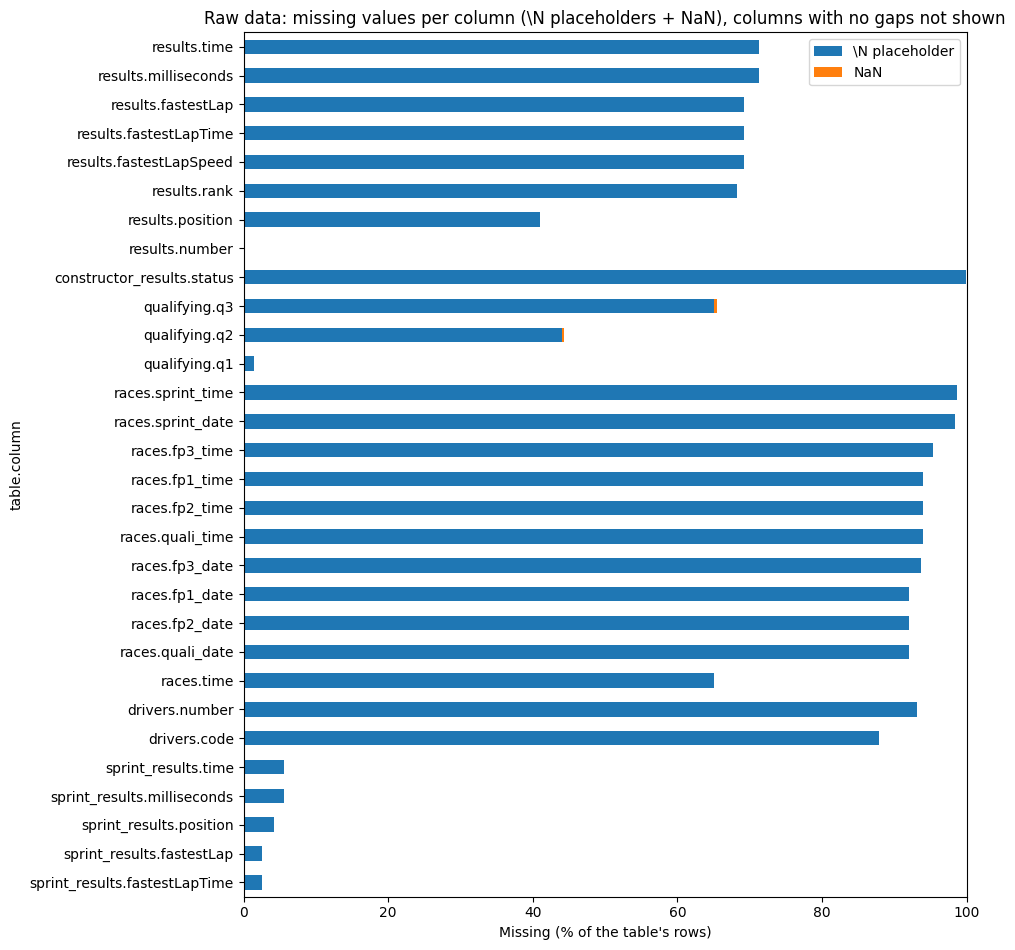

In [ ]:
# Raw data: share of missing rows in every column that has gaps (\N placeholder vs real NaN)
plot_df = missing_by_column_raw.assign(label=lambda d: d["table"] + "." + d["column"]).set_index("label")
missing_pct = pd.DataFrame({
    r"\N placeholder": 100 * plot_df[r"\N cells"] / plot_df["rows in table"],
    "NaN": 100 * plot_df["NaN cells"] / plot_df["rows in table"],
}).iloc[::-1]   # reversed so the first row of the table is drawn at the top

missing_pct.plot(kind="barh", stacked=True, figsize=(10, max(4, 0.32 * len(missing_pct))))
plt.xlabel("Missing (% of the table's rows)")
plt.ylabel("table.column")
plt.xlim(0, 100)
plt.title(r"Raw data: missing values per column (\N placeholders + NaN), columns with no gaps not shown")
plt.tight_layout()
plt.show()

**What the raw data shows.** Missing values are stored as the text `\N`, not as real missing values, so pandas does not see them as missing. `races`, `results`, `drivers`, `constructor_results` and `qualifying` have the most. Most of these are columns that simply did not exist in early seasons (practice and qualifying times, fastest laps, car numbers). Section 2 replaces `\N`, fixes types, and decides column by column what to keep.

# 2. Data Cleaning & Auditing

## 2.1 \N Values

The CSVs mark missing values with the literal string `\N`. We replace it with a real missing value (pd.NA) in all 14 tables, then count missing values again to confirm no \N is left.

In [ ]:
for name, df in tables.items():
    tables[name] = df.replace(r"\N", pd.NA)

# Update the original DataFrame variables
races = tables["races"]
results = tables["results"]
drivers = tables["drivers"]
constructors = tables["constructors"]
circuits = tables["circuits"]
qualifying = tables["qualifying"]
status = tables["status"]
driver_standings = tables["driver_standings"]
constructor_standings = tables["constructor_standings"]
sprint_results = tables["sprint_results"]
lap_times = tables["lap_times"]
pit_stops = tables["pit_stops"]
constructor_results = tables["constructor_results"]
seasons = tables["seasons"]

print("Standardized '\\N' missing values across all 14 tables.")

Standardized '\N' missing values across all 14 tables.


Any column per table that has at least one missing value (NaN) is listed below

In [ ]:
# After the replacement: the same per-column table. Every \N placeholder is now a real missing value.
missing_by_column_after = missing_by_column(tables)

print(r"\N cells left in all 14 tables:", int(missing_by_column_after[r"\N cells"].sum()))
same = (
    missing_by_column_raw.set_index(["table", "column"])["missing"]
    .equals(missing_by_column_after.set_index(["table", "column"])["missing"])
)
print("Same missing cells per column as before the replacement (nothing lost or added):", same)
assert missing_by_column_after[r"\N cells"].sum() == 0 and same

display(missing_by_column_after.round(1))

\N cells left in all 14 tables: 0
Same missing cells per column as before the replacement (nothing lost or added): True


,table,column,\N cells,NaN cells,missing,rows in table,missing %
0,results,time,0,19079,19079,26759,71.300
1,results,milliseconds,0,19079,19079,26759,71.300
2,results,fastestLap,0,18507,18507,26759,69.200
3,results,fastestLapTime,0,18507,18507,26759,69.200
4,results,fastestLapSpeed,0,18507,18507,26759,69.200
5,results,rank,0,18249,18249,26759,68.200
6,results,position,0,10953,10953,26759,40.900
7,results,number,0,6,6,26759,0.000
8,constructor_results,status,0,12608,12608,12625,99.900
9,qualifying,q3,0,6865,6865,10494,65.400


## 2.2 Semantic Typing of Dates and Durations


In [ ]:
import re

NULL_TOKENS = {r"\N", "", "nan", "NaN", "None", "NULL"}

TIME_COLUMNS = {
    "date": [
        ("drivers", "dob"),
        ("races", "date"),
        ("races", "fp1_date"),
        ("races", "fp2_date"),
        ("races", "fp3_date"),
        ("races", "quali_date"),
        ("races", "sprint_date"),
    ],
    "time_of_day": [
        ("races", "time"),
        ("races", "fp1_time"),
        ("races", "fp2_time"),
        ("races", "fp3_time"),
        ("races", "quali_time"),
        ("races", "sprint_time"),
        ("pit_stops", "time"),
    ],
    "duration": [
        ("results", "time"),
        ("results", "fastestLapTime"),
        ("sprint_results", "time"),
        ("sprint_results", "fastestLapTime"),
        ("lap_times", "time"),
        ("pit_stops", "duration"),
        ("qualifying", "q1"),
        ("qualifying", "q2"),
        ("qualifying", "q3"),
    ],
}

# Expected formats
EXPECTED = {
    "date": r"^\d{4}-\d{2}-\d{2}$",
    "time_of_day": r"^\d{2}:\d{2}:\d{2}$",
    # h:mm:ss.fff, m:ss.fff, ss.fff,
    # optional leading + for race gaps
    "duration": r"^\+?(\d+:){0,2}\d+(\.\d+)?$",
}


def is_null_token(v):
    return pd.isna(v) or str(v).strip() in NULL_TOKENS


def signature(v):
    t = str(v).strip()
    t = re.sub(r"\d", "9", t)
    return re.sub(r"[A-Za-z]", "A", t)


audit_rows = []

for kind, cols in TIME_COLUMNS.items():
    for table, col in cols:

        if table not in tables \
                or col not in tables[table].columns:
            audit_rows.append({
                "table": table, "column": col,
                "kind": kind,
                "note": "missing table or column",
            })
            continue

        s = tables[table][col]
        null_mask = s.map(is_null_token)
        strings = s[~null_mask].astype(str).str.strip()

        bad = strings[
            ~strings.str.match(EXPECTED[kind])
        ]
        patterns = strings.map(signature) \
                          .value_counts()

        audit_rows.append({
            "table": table,
            "column": col,
            "kind": kind,
            "dtype": str(s.dtype),
            "rows": len(s),
            "null_like": int(null_mask.sum()),
            "null_pct": round(
                100 * null_mask.mean(), 1
            ),
            "distinct_patterns": len(patterns),
            "bad_format_count": len(bad),
            "bad_examples":
                bad.unique()[:5].tolist(),
            "top_patterns": ", ".join(
                f"{p} ({n})"
                for p, n in patterns.head(6).items()
            ),
        })

format_audit_df = pd.DataFrame(audit_rows)

pd.set_option("display.max_colwidth", 120)

print("=== Format audit (all time columns) ===")
display(format_audit_df)

print("=== Columns with unexpected formats ===")
display(format_audit_df[
    format_audit_df["bad_format_count"] > 0
][["table", "column", "kind",
   "bad_format_count", "bad_examples"]])

print("=== Columns with more than one pattern ===")
display(format_audit_df[
    format_audit_df["distinct_patterns"] > 1
][["table", "column", "top_patterns"]])

=== Format audit (all time columns) ===


,table,column,kind,dtype,rows,null_like,null_pct,distinct_patterns,bad_format_count,bad_examples,top_patterns
0,drivers,dob,date,object,861,0,0.000,1,0,[],9999-99-99 (861)
1,races,date,date,object,1125,0,0.000,1,0,[],9999-99-99 (1125)
2,races,fp1_date,date,object,1125,1035,92.000,1,0,[],9999-99-99 (90)
3,races,fp2_date,date,object,1125,1035,92.000,1,0,[],9999-99-99 (90)
4,races,fp3_date,date,object,1125,1053,93.600,1,0,[],9999-99-99 (72)
5,races,quali_date,date,object,1125,1035,92.000,1,0,[],9999-99-99 (90)
6,races,sprint_date,date,object,1125,1107,98.400,1,0,[],9999-99-99 (18)
7,races,time,time_of_day,object,1125,731,65.000,1,0,[],99:99:99 (394)
8,races,fp1_time,time_of_day,object,1125,1057,94.000,1,0,[],99:99:99 (68)
9,races,fp2_time,time_of_day,object,1125,1057,94.000,1,0,[],99:99:99 (68)


=== Columns with unexpected formats ===


,table,column,kind,bad_format_count,bad_examples


=== Columns with more than one pattern ===


,table,column,top_patterns
14,results,time,"+99.999 (2973), +9:99.999 (1614), 9:99:99.999 (765), +9.999 (732), +9:99.99 (281), +9:99.9 (279)"
16,sprint_results,time,"+99.999 (259), +9.999 (38), +9:99.999 (25), 99:99.999 (18)"
18,lap_times,time,"9:99.999 (588455), 99:99.999 (583), 9:99:99.999 (43)"
19,pit_stops,duration,"99.999 (10854), 99:99.999 (460), 9:99.999 (57)"
20,qualifying,q1,"9:99.999 (10337), 99:99.999 (1)"


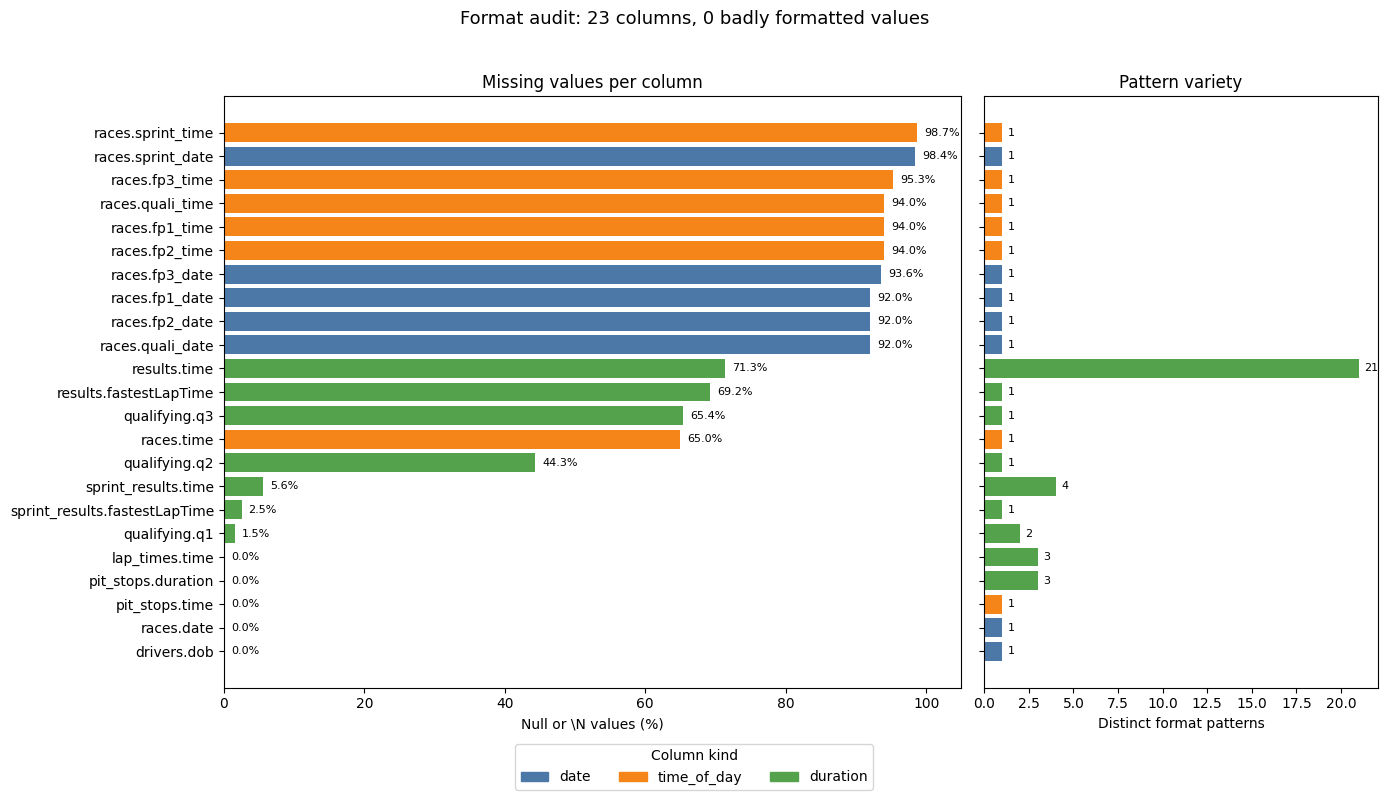

In [ ]:

df = format_audit_df.copy()
df["label"] = df["table"] + "." + df["column"]
df = df.sort_values("null_pct")

colors = {
    "date": "#4C78A8",
    "time_of_day": "#F58518",
    "duration": "#54A24B",
}
bar_colors = df["kind"].map(colors)

fig, axes = plt.subplots(
    1, 2, figsize=(14, 8), sharey=True,
    gridspec_kw={"width_ratios": [3, 1.6]},
)

# Panel 1: missing values
ax = axes[0]
ax.barh(df["label"], df["null_pct"],
        color=bar_colors)
ax.set_xlabel("Null or \\N values (%)")
ax.set_title("Missing values per column")
ax.set_xlim(0, 105)
for y, v in enumerate(df["null_pct"]):
    ax.text(v + 1, y, f"{v:.1f}%",
            va="center", fontsize=8)

# Panel 2: distinct patterns
ax = axes[1]
ax.barh(df["label"], df["distinct_patterns"],
        color=bar_colors)
ax.set_xlabel("Distinct format patterns")
ax.set_title("Pattern variety")
for y, v in enumerate(df["distinct_patterns"]):
    ax.text(v + 0.3, y, str(v),
            va="center", fontsize=8)

handles = [
    plt.Rectangle((0, 0), 1, 1, color=c)
    for c in colors.values()
]
fig.legend(handles, colors.keys(),
           loc="lower center", ncol=3,
           title="Column kind")

bad_total = int(df["bad_format_count"].sum())
fig.suptitle(
    f"Format audit: {len(df)} columns, "
    f"{bad_total} badly formatted values",
    fontsize=13,
)

plt.tight_layout(rect=[0, 0.06, 1, 0.96])
plt.show()

Dropped columns (Mostly missing, 44–99%):

Session dates & times (fp1–fp3, quali_, sprint_, and races.time): Dropped because they're only available for recent seasons and aren't model inputs or tied to podium finishes.

Race results & lap metrics (results.time, results.fastestLapTime): Dropped to prevent data leakage (they are post-race measurements). They're mostly missing because only lead-lap finishers get times and fastest laps are a recent addition.

Qualifying segments (qualifying.q2, qualifying.q3): Dropped because they only apply to the post-2005/2006 knockout format and drivers who made it to those rounds.

Kept columns (Complete or almost complete, 0–6%):

qualifying.q1: Kept (98.5% complete). We remove one impossible outlier here (Mark Blundell's 16-minute lap at the 1995 Japanese GP). It's not a model feature since qualifying_position already ranks the laps.

Sprint results (sprint_results.time, sprint_results.fastestLapTime): Kept, though missing for DNFs/no lap. (Sprint results aren't model inputs anyway).

Dates (races.date, drivers.dob): Kept to determine race order for form features and calculate driver age.

In-race data (lap_times.time, pit_stops.time, pit_stops.duration): Race data is kept for analysis but never used as features to avoid leakage. (pit_stops.duration is eventually dropped because it's just an exact copy of pit_stops.milliseconds).

Multi-format columns handled during conversion:

results.time & sprint_results.time (21 and 4 patterns): Winners have full times, while others have gaps to the winner (plus older races recording only fractional seconds). Gaps are added back to the winner's time.

lap_times.time (3 patterns): Standard laps are m:ss.sss, but a handful of red-flagged races include laps over 10 minutes or an hour.

pit_stops.duration (3 patterns): Usually ss.sss, but includes multi-minute stops during red-flag pit lane suspensions.

qualifying.q1 (2 patterns): Standard formats plus the single 1995 outlier mentioned above, which gets set to missing.

- Dates: each date column keeps its name and becomes datetime64.
- Times of day: each time-of-day column keeps its name and becomes datetime.time.
- Durations: each duration column keeps its name but now holds float seconds.
- Gaps: results.time and sprint_results.time hold both the winner’s total time and + gaps. Each gap was added to the winner's total time of its
race, so `time` holds a finish time for every driver.



In [ ]:
def to_seconds(value):
    """'1:32.501' -> 92.501 and '+5.478' -> 5.478. Missing values stay NaN."""
    if pd.isna(value):
        return np.nan
    seconds = 0.0
    for part in str(value).lstrip("+").split(":"):
        seconds = seconds * 60 + float(part)
    return seconds


for kind, cols in TIME_COLUMNS.items():
    for table, col in cols:
        df = tables[table]

        if kind == "date":
            df[col] = pd.to_datetime(df[col], format="%Y-%m-%d", errors="coerce")

        elif kind == "time_of_day":
            df[col] = pd.to_datetime(df[col], format="%H:%M:%S", errors="coerce").dt.time

        else:  # duration -> seconds
            seconds = df[col].map(to_seconds)
            is_gap = df[col].astype(str).str.startswith("+")

            # "+5.478" is a gap to the winner: add the winner's time of that race
            if is_gap.any():
                full_times = df.loc[~is_gap & seconds.notna(), ["raceId", "positionOrder"]]
                full_times["seconds"] = seconds
                winner_time = full_times.sort_values("positionOrder").groupby("raceId")["seconds"].first()
                seconds = seconds.where(~is_gap, seconds + df["raceId"].map(winner_time))

            df[col] = seconds

# Check: the converted finish times should equal the milliseconds column
ms = pd.to_numeric(results["milliseconds"], errors="coerce") / 1000
both = results["time"].notna() & ms.notna()
print("results.time matches milliseconds:",
      (abs(results.loc[both, "time"] - ms[both]) < 0.01).sum(), "of", both.sum(), "rows")

results.time matches milliseconds: 7651 of 7680 rows


**Result.**
- Dates are now `datetime64`, durations are seconds (`float`), times of day are `datetime.time`.
- In `results.time` and `sprint_results.time`, the winner has a full race time and everyone else a gap such as `+5.478` (5.478 s behind the winner). Each gap is added to the winner's time of the same race, so `time` holds every driver's own finish time in seconds.
- The check confirms this: the converted times match the `milliseconds` column in almost every row (7651 of 7680). The 29 exceptions come from 7 races: 19 from the 2024 Belgian GP, where the winner on the road was disqualified and the `milliseconds` column for that race holds the gaps instead of total times, and the rest from post-race time penalties, which are included in the printed gap but not always in `milliseconds`. These columns are post-race and dropped in 2.5.2, so this does not affect the model.

## 2.3 Primary / Foreign Keys


**Primary Key Check**

In [ ]:
primary_keys = {
    "circuits": ["circuitId"],
    "constructors": ["constructorId"],
    "constructor_results": ["constructorResultsId"],
    "constructor_standings": ["constructorStandingsId"],
    "drivers": ["driverId"],
    "driver_standings": ["driverStandingsId"],
    "races": ["raceId"],
    "results": ["resultId"],
    "qualifying": ["qualifyId"],
    "seasons": ["year"],
    "status": ["statusId"],
    "sprint_results": ["resultId"],
    #combined
    "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"]
}

def audit_primary_key(df, key_columns):

    null_rows = df[key_columns].isna().any(axis=1).sum()

    duplicate_rows = df.duplicated(
        subset=key_columns
    ).sum()

    return null_rows, duplicate_rows

pk_audit = []

for table_name, key_columns in primary_keys.items():

    null_rows, duplicate_rows = audit_primary_key(
        tables[table_name],
        key_columns
    )

    pk_audit.append({
        "table": table_name,
        "primary_key": ", ".join(key_columns),
        "null_PK_rows": int(null_rows),
        "duplicate_PK_rows": int(duplicate_rows)
    })

pk_audit_df = pd.DataFrame(pk_audit)

display(pk_audit_df)
print("All primary keys unique and non-null:",
      (pk_audit_df[["null_PK_rows", "duplicate_PK_rows"]] == 0).all().all())


,table,primary_key,null_PK_rows,duplicate_PK_rows
0,circuits,circuitId,0,0
1,constructors,constructorId,0,0
2,constructor_results,constructorResultsId,0,0
3,constructor_standings,constructorStandingsId,0,0
4,drivers,driverId,0,0
5,driver_standings,driverStandingsId,0,0
6,races,raceId,0,0
7,results,resultId,0,0
8,qualifying,qualifyId,0,0
9,seasons,year,0,0


All primary keys unique and non-null: True


checking if foreign key exist but it has no pk from parent match

In [ ]:
# Foreign keys: (child table, column) -> (parent table, key it must exist in)
foreign_keys = [
    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),
    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),
    ("lap_times", "raceId", "races", "raceId"),
    ("lap_times", "driverId", "drivers", "driverId"),
    ("pit_stops", "raceId", "races", "raceId"),
    ("pit_stops", "driverId", "drivers", "driverId"),
    ("sprint_results", "raceId", "races", "raceId"),
    ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "statusId", "status", "statusId"),
    ("driver_standings", "raceId", "races", "raceId"),
    ("driver_standings", "driverId", "drivers", "driverId"),
    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),
    ("constructor_results", "raceId", "races", "raceId"),
    ("constructor_results", "constructorId", "constructors", "constructorId"),
    ("races", "circuitId", "circuits", "circuitId"),
    ("races", "year", "seasons", "year"),
]

fk_audit = pd.DataFrame([
    {"link": f"{child}.{ck} -> {parent}.{pk}",
     "orphan_rows": int((~tables[child][ck].isin(tables[parent][pk])).sum())}
    for child, ck, parent, pk in foreign_keys
])
display(fk_audit)
print("All foreign keys valid:", (fk_audit["orphan_rows"] == 0).all())


,link,orphan_rows
0,results.raceId -> races.raceId,0
1,results.driverId -> drivers.driverId,0
2,results.constructorId -> constructors.constructorId,0
3,results.statusId -> status.statusId,0
4,qualifying.raceId -> races.raceId,0
5,qualifying.driverId -> drivers.driverId,0
6,qualifying.constructorId -> constructors.constructorId,0
7,lap_times.raceId -> races.raceId,0
8,lap_times.driverId -> drivers.driverId,0
9,pit_stops.raceId -> races.raceId,0


All foreign keys valid: True


## 2.4 Excluding Indianapolis 500 Races (405 rows)


**Why exclude the Indianapolis 500?** From 1950 to 1960 the Indianapolis 500, an American oval race, officially counted as a round of the World Championship. Before removing it, we compare it with the other championship races of the same years: field size, nationality of the entrants, and how many drivers took part in both.

,Indianapolis 500,Other Grands Prix
Races (1950-1960),11,83
Entries per race,36.8,22.0
American entries,99.8%,9.0%
Distinct drivers,107,251


Drivers who raced both the Indianapolis 500 and another Grand Prix in 1950-1960: 3 of 107 Indy drivers (Rodger Ward, Troy Ruttman, Alberto Ascari)


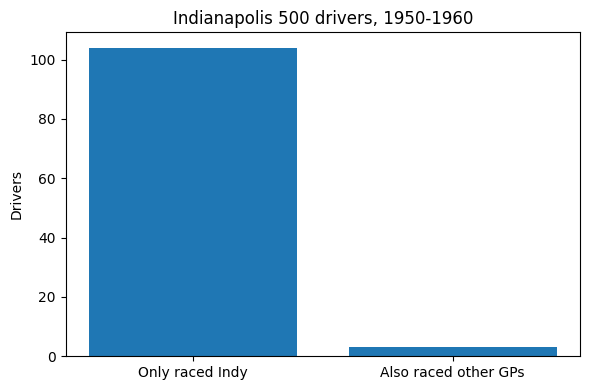

In [ ]:
# Why exclude the Indianapolis 500? Compare it with the other championship races of 1950-1960
era_races = raw_races[raw_races["year"].between(1950, 1960)].copy()
era_races["is_indy"] = era_races["name"].eq("Indianapolis 500")

era_results = (
    raw_results.merge(era_races[["raceId", "is_indy"]], on="raceId")
    .merge(raw_drivers[["driverId", "nationality"]], on="driverId")
)

# Which drivers raced at Indy, and which raced in the other Grands Prix
indy_drivers = set(era_results.loc[era_results["is_indy"], "driverId"])
gp_drivers = set(era_results.loc[~era_results["is_indy"], "driverId"])

def indy_vs_gp(is_indy):
    part = era_results[era_results["is_indy"] == is_indy]
    drivers_set = indy_drivers if is_indy else gp_drivers
    return [
        f'{int((era_races["is_indy"] == is_indy).sum())}',
        f'{part.groupby("raceId").size().mean():.1f}',
        f'{part["nationality"].eq("American").mean():.1%}',
        f'{len(drivers_set)}',
    ]

# Formatted as text so counts show as whole numbers and shares as percentages
indy_check = pd.DataFrame(
    {"Indianapolis 500": indy_vs_gp(True), "Other Grands Prix": indy_vs_gp(False)},
    index=["Races (1950-1960)", "Entries per race", "American entries", "Distinct drivers"],
)
display(indy_check)

# Drivers who appear in both: one number for both groups, with their names as proof
both_names = (
    raw_drivers[raw_drivers["driverId"].isin(indy_drivers & gp_drivers)]
    .assign(name=lambda d: d["forename"] + " " + d["surname"])["name"].tolist()
)
print(f"Drivers who raced both the Indianapolis 500 and another Grand Prix in 1950-1960: "
      f"{len(both_names)} of {len(indy_drivers)} Indy drivers ({', '.join(both_names)})")

# Plot: share of Indy drivers who ever raced a normal Grand Prix in the same era
both = len(indy_drivers & gp_drivers)
only_indy = len(indy_drivers - gp_drivers)
plt.figure(figsize=(6, 4))
plt.bar(["Only raced Indy", "Also raced other GPs"], [only_indy, both])
plt.ylabel("Drivers")
plt.title("Indianapolis 500 drivers, 1950-1960")
plt.tight_layout()
plt.show()

**Result.** The Indianapolis 500 was effectively a separate competition:
- **Different drivers:** only 3 of its 107 drivers ever raced a normal Grand Prix in 1950–1960, so it adds almost no information about F1 drivers.
- **Almost all Americans** (99.8% of entries, against 9% in the other races). In Question 2 this would add hundreds of "home race" rows from a race that has nothing to do with F1 home advantage.
- **Bigger fields** (about 37 entries against 22), on an oval track with its own qualifying rules, so grid and podium patterns are not comparable with the other races.

We therefore remove the 11 Indianapolis 500 races from every table. Their points also counted in the championship standings, so we subtract them there. Standings are a running total within one season, so each driver's (or team's) Indy points are subtracted only in that season and only from races after that season's Indy 500.

In [ ]:
# Before dropping: how big is the Indianapolis 500 part of the data?
indy_ids = raw_races.loc[raw_races["name"].eq("Indianapolis 500") & raw_races["year"].between(1950, 1960), "raceId"]
n_indy_results = int(results["raceId"].isin(indy_ids).sum())
print(f"Indianapolis 500 rows before dropping: {len(indy_ids)} races, {n_indy_results:,} of {len(results):,} result rows "
      f"({n_indy_results / len(results):.1%})")

Indianapolis 500 rows before dropping: 11 races, 405 of 26,759 result rows (1.5%)


In [ ]:

# 1. Identify the Indianapolis 500 races from the original data
indy_races = raw_races.loc[
    raw_races["name"].eq("Indianapolis 500")
    & raw_races["year"].between(1950, 1960),
    ["raceId", "year", "date"]
].copy()

indy_race_ids = set(indy_races["raceId"])

print(f"Indianapolis 500 races identified: {len(indy_race_ids)}")

# 2. Remove these races from every table containing raceId
for name, df in tables.items():
    if "raceId" in df.columns:
        before = len(df)

        tables[name] = df.loc[
            ~df["raceId"].isin(indy_race_ids)
        ].copy()

        print(f"{name}: {before:,} -> {len(tables[name]):,} rows ({before - len(tables[name]):,} removed)")

# 3. Update working variables to reference the filtered tables
for name, df in tables.items():
    globals()[name] = df

# 4-7. Remove the Indy points from the championship standings.
# Standings are a running total within ONE season, so a driver's (or team's) Indy points
# are subtracted only in that season, and only from races held after that season's Indy 500.
indy_dates = raw_races.loc[raw_races["raceId"].isin(indy_race_ids), ["raceId", "year", "date"]]
indy_dates["date"] = pd.to_datetime(indy_dates["date"])
race_dates = races[["raceId", "year", "date"]].assign(date=lambda d: pd.to_datetime(d["date"]))

def remove_indy_points(standings, raw_points_table, key):
    indy_points = (
        raw_points_table[raw_points_table["raceId"].isin(indy_race_ids)]
        .merge(indy_dates, on="raceId")
        .groupby([key, "year"], as_index=False)
        .agg(indy_points=("points", "sum"), indy_date=("date", "first"))
    )
    rows = (
        standings.merge(race_dates, on="raceId", how="left")
        .merge(indy_points, on=[key, "year"], how="left")
    )
    after_indy = rows["date"] >= rows["indy_date"]
    standings["points"] = (rows["points"] - rows["indy_points"].where(after_indy, 0).fillna(0)).to_numpy()
    return standings

# Start from the raw standings (without the Indy rows), so re-running this cell never subtracts twice
driver_standings = raw_driver_standings[~raw_driver_standings["raceId"].isin(indy_race_ids)].copy()
constructor_standings = raw_constructor_standings[~raw_constructor_standings["raceId"].isin(indy_race_ids)].copy()

driver_standings = remove_indy_points(driver_standings, raw_results, "driverId")
constructor_standings = remove_indy_points(constructor_standings, raw_constructor_results, "constructorId")
tables["driver_standings"], tables["constructor_standings"] = driver_standings, constructor_standings

# 8. Recalculate championship positions from corrected points
driver_standings["position"] = (
    driver_standings.groupby("raceId")["points"]
    .rank(method="min", ascending=False)
    .astype("Int64")
)

constructor_standings["position"] = (
    constructor_standings.groupby("raceId")["points"]
    .rank(method="min", ascending=False)
    .astype("Int64")
)

# 9. Verify exclusion
print("\nVerification:")
for name, df in tables.items():
    if "raceId" in df.columns:
        remaining = df["raceId"].isin(indy_race_ids).sum()
        print(f"{name}: excluded race rows remaining = {remaining}")

print("Standings rows with negative points:",
      int((driver_standings["points"] < 0).sum() + (constructor_standings["points"] < 0).sum()))
print("\nIndianapolis 500 exclusion completed.")

Indianapolis 500 races identified: 11
races: 1,125 -> 1,114 rows (11 removed)
results: 26,759 -> 26,354 rows (405 removed)
qualifying: 10,494 -> 10,494 rows (0 removed)
driver_standings: 34,863 -> 34,194 rows (669 removed)
constructor_standings: 13,391 -> 13,365 rows (26 removed)
sprint_results: 360 -> 360 rows (0 removed)
lap_times: 589,081 -> 589,081 rows (0 removed)
pit_stops: 11,371 -> 11,371 rows (0 removed)
constructor_results: 12,625 -> 12,604 rows (21 removed)

Verification:
races: excluded race rows remaining = 0
results: excluded race rows remaining = 0
qualifying: excluded race rows remaining = 0
driver_standings: excluded race rows remaining = 0
constructor_standings: excluded race rows remaining = 0
sprint_results: excluded race rows remaining = 0
lap_times: excluded race rows remaining = 0
pit_stops: excluded race rows remaining = 0
constructor_results: excluded race rows remaining = 0
Standings rows with negative points: 0

Indianapolis 500 exclusion completed.


## 2.5 Missing Values and Data Types


### 2.5.1 Races



races
--------------------------------------------------

Shape:
(1114, 18)

Columns:
['raceId', 'year', 'round', 'circuitId', 'name', 'date', 'time', 'url', 'fp1_date', 'fp1_time', 'fp2_date', 'fp2_time', 'fp3_date', 'fp3_time', 'quali_date', 'quali_time', 'sprint_date', 'sprint_time']

Info:
<class 'pandas.core.frame.DataFrame'>
Index: 1114 entries, 0 to 1124
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   raceId       1114 non-null   int64         
 1   year         1114 non-null   int64         
 2   round        1114 non-null   int64         
 3   circuitId    1114 non-null   int64         
 4   name         1114 non-null   object        
 5   date         1114 non-null   datetime64[ns]
 6   time         394 non-null    object        
 7   url          1114 non-null   object        
 8   fp1_date     90 non-null     datetime64[ns]
 9   fp1_time     68 non-null     object        
 10  fp2_date 

,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
count,1114.000,1114.000,1114.000,1114.000,1114,1114,394,1114,90,68,90,68,72,53,90,68,18,15
unique,NaN,NaN,NaN,NaN,53,NaN,34,1114,NaN,20,NaN,19,NaN,18,NaN,15,NaN,12
top,NaN,NaN,NaN,NaN,British Grand Prix,NaN,12:00:00,https://en.wikipedia.org/wiki/2024_Abu_Dhabi_Grand_Prix,NaN,11:30:00,NaN,15:00:00,NaN,10:30:00,NaN,14:00:00,NaN,14:30:00
freq,NaN,NaN,NaN,NaN,75,NaN,113,1,NaN,18,NaN,22,NaN,14,NaN,24,NaN,4
mean,563.469,1993.075,8.638,23.938,NaN,1993-08-08 23:07:00.107719936,NaN,NaN,2023-02-06 03:28:00,NaN,2023-02-06 06:40:00,NaN,2023-01-05 11:40:00,NaN,2023-02-07 00:16:00,NaN,2023-06-17 18:40:00,NaN
min,1.000,1950.000,1.000,1.000,NaN,1950-05-13 00:00:00,NaN,NaN,2021-03-26 00:00:00,NaN,2021-03-26 00:00:00,NaN,2021-03-27 00:00:00,NaN,2021-03-27 00:00:00,NaN,2021-07-17 00:00:00,NaN
25%,279.250,1977.000,4.000,9.000,NaN,1977-07-19 18:00:00,NaN,NaN,2022-03-19 18:00:00,NaN,2022-03-19 18:00:00,NaN,2021-12-09 06:00:00,NaN,2022-03-20 18:00:00,NaN,2022-08-09 12:00:00,NaN
50%,557.500,1995.000,8.000,18.000,NaN,1995-05-21 00:00:00,NaN,NaN,2023-03-10 00:00:00,NaN,2023-03-10 00:00:00,NaN,2022-10-25 12:00:00,NaN,2023-03-11 00:00:00,NaN,2023-09-02 00:00:00,NaN
75%,847.750,2011.000,13.000,34.000,NaN,2011-06-22 12:00:00,NaN,NaN,2024-03-05 06:00:00,NaN,2024-03-05 06:00:00,NaN,2023-12-19 06:00:00,NaN,2024-03-06 06:00:00,NaN,2024-04-30 12:00:00,NaN
max,1144.000,2024.000,24.000,80.000,NaN,2024-12-08 00:00:00,NaN,NaN,2024-12-06 00:00:00,NaN,2024-12-06 00:00:00,NaN,2024-12-07 00:00:00,NaN,2024-12-07 00:00:00,NaN,2024-11-30 00:00:00,NaN



Full duplicate rows:
0

First 5 rows:


,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_Grand_Prix,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Grand_Prix,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Grand_Prix,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT
3,4,2009,4,3,Bahrain Grand Prix,2009-04-26,12:00:00,http://en.wikipedia.org/wiki/2009_Bahrain_Grand_Prix,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT
4,5,2009,5,4,Spanish Grand Prix,2009-05-10,12:00:00,http://en.wikipedia.org/wiki/2009_Spanish_Grand_Prix,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT



Missing values (actual NaN):
raceId            0
year              0
round             0
circuitId         0
name              0
date              0
time            720
url               0
fp1_date       1024
fp1_time       1046
fp2_date       1024
fp2_time       1046
fp3_date       1042
fp3_time       1061
quali_date     1024
quali_time     1046
sprint_date    1096
sprint_time    1099
dtype: int64

Placeholder missing values:
No placeholder missing values found.


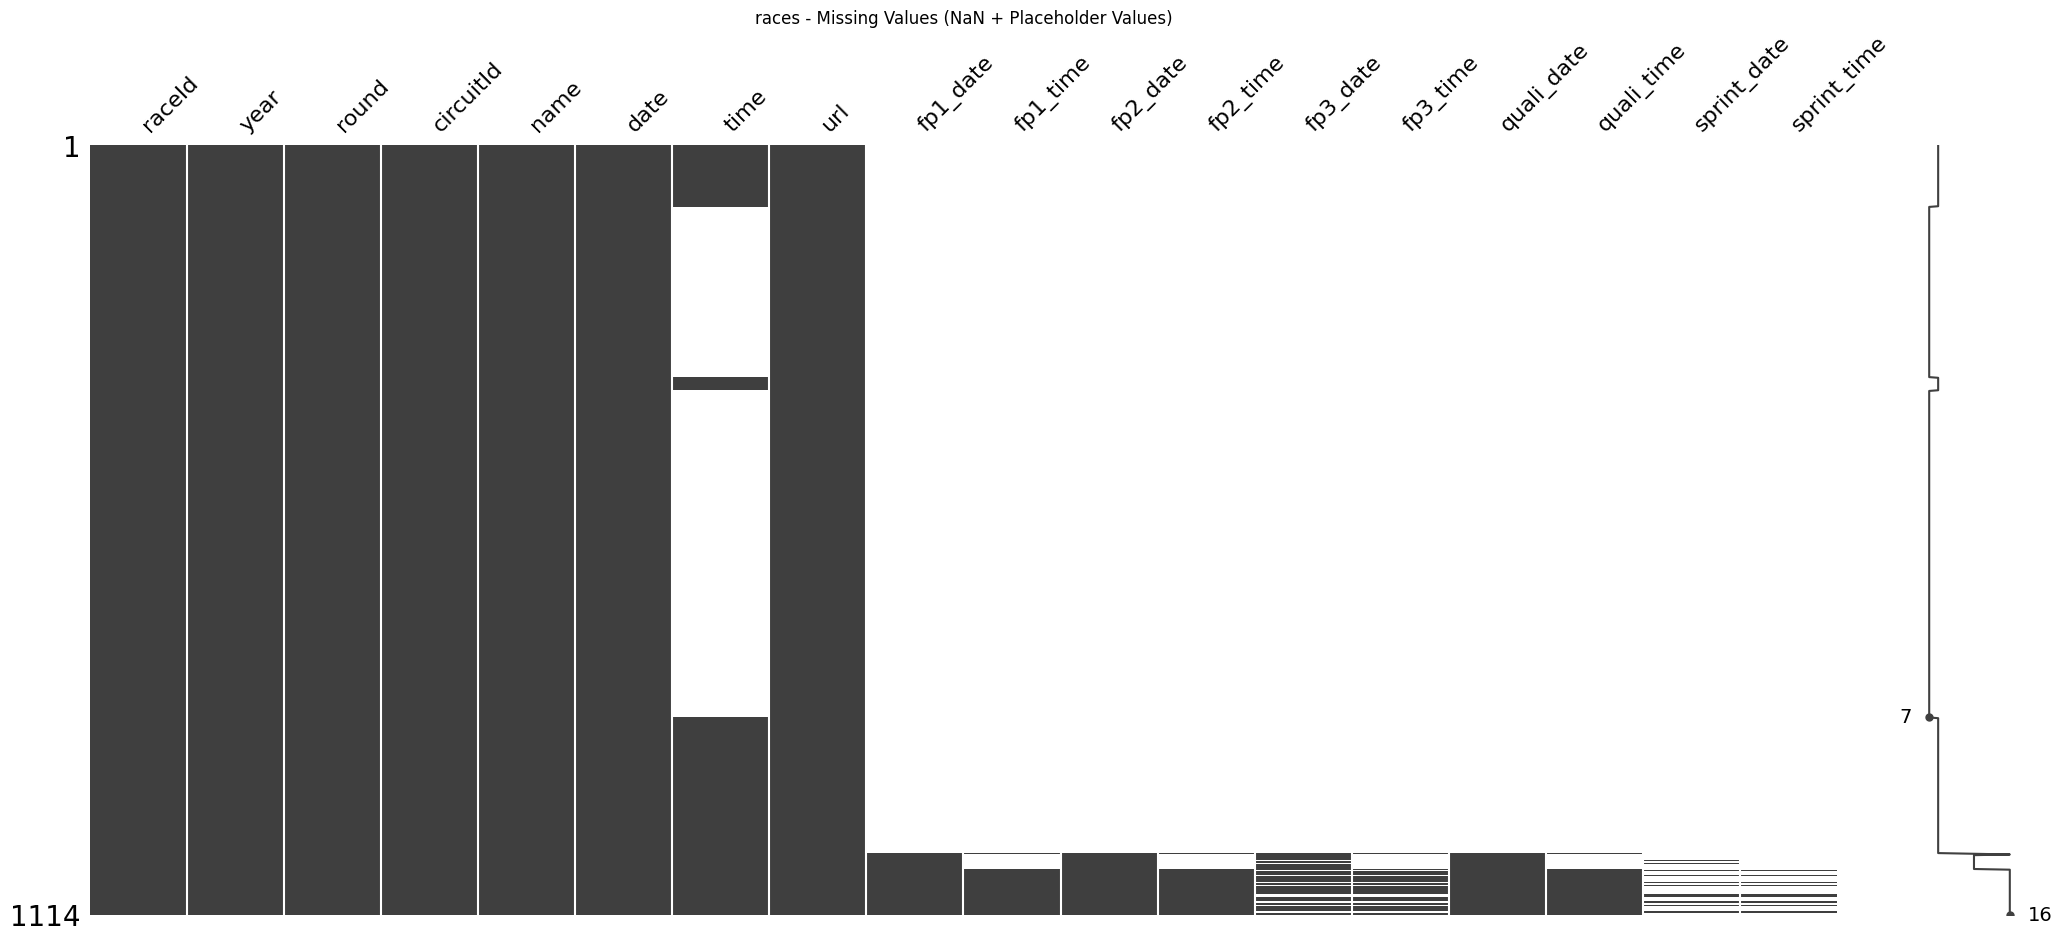


Numeric Distributions:


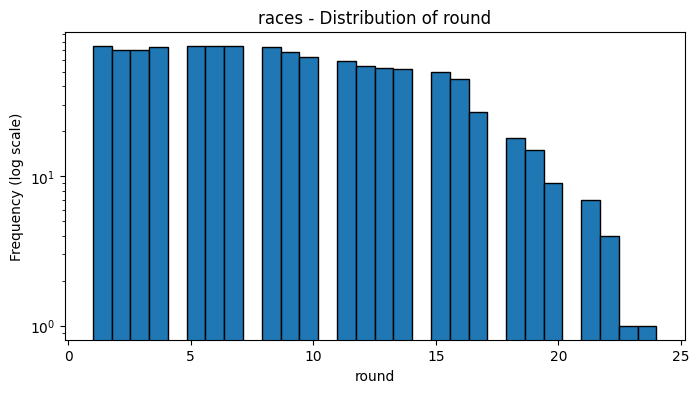

In [ ]:
inspect_df("races", races)


In [ ]:
races["date"].duplicated().sum()

np.int64(0)

In [ ]:
races = races.drop(columns=[

    "fp1_date", "fp1_time",
    "fp2_date", "fp2_time",
    "fp3_date", "fp3_time",
    "quali_date", "quali_time",
    "sprint_time",	"sprint_date","time"
])

**Why the session dates and times are dropped.** The per-column missing table in 1.1 shows the reason: the race start `time` is missing for 65% of races, and the practice, qualifying and sprint dates and times for 92–99%. They are only recorded for recent seasons, so they cannot be a feature for most of the data, and none of them is needed for any question. `date` (complete) is kept: it orders the races for the leakage-safe form features.

In [ ]:
races["date"] = pd.to_datetime(
    races["date"],
    errors="coerce"
)

In [ ]:
races.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1114 entries, 0 to 1124
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   raceId     1114 non-null   int64         
 1   year       1114 non-null   int64         
 2   round      1114 non-null   int64         
 3   circuitId  1114 non-null   int64         
 4   name       1114 non-null   object        
 5   date       1114 non-null   datetime64[ns]
 6   url        1114 non-null   object        
dtypes: datetime64[ns](1), int64(4), object(2)
memory usage: 69.6+ KB


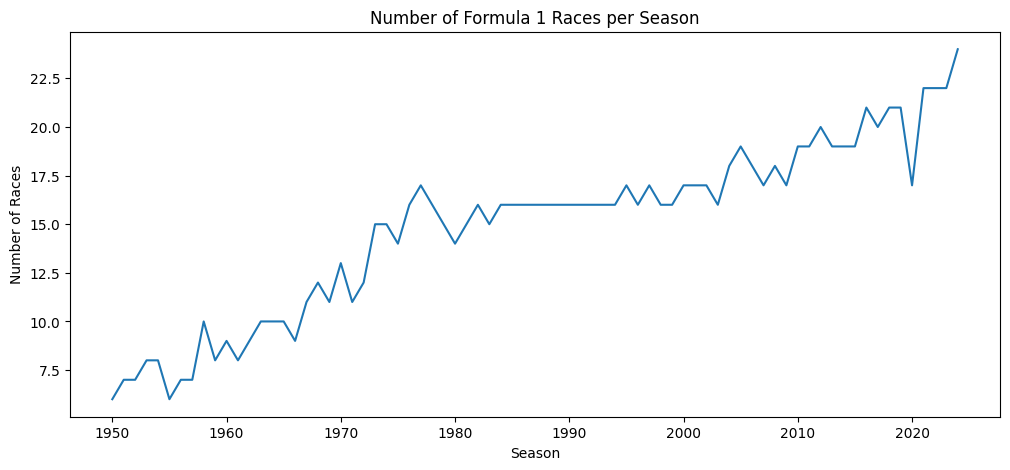

In [ ]:
races_per_year = (
    races.groupby("year")["raceId"]
    .count()
)

plt.figure(figsize=(12, 5))
plt.plot(races_per_year.index, races_per_year.values)

plt.xlabel("Season")
plt.ylabel("Number of Races")
plt.title("Number of Formula 1 Races per Season")

plt.show()

The main pattern is that Formula 1 seasons generally became longer over time. Early seasons had roughly 7–10 races, while recent seasons are around 20–24 races


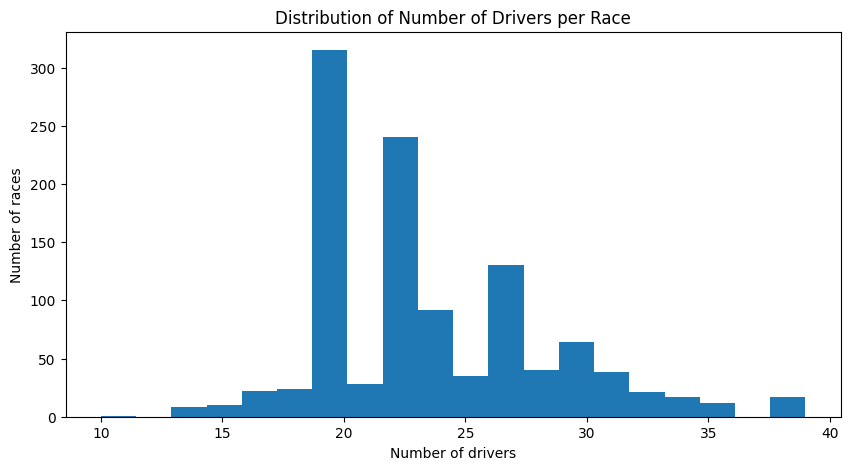

In [ ]:
# Drivers per Race
drivers_per_race = (
    results
    .groupby("raceId")["driverId"]
    .nunique()
)

plt.figure(figsize=(10, 5))

plt.hist(
    drivers_per_race,
    bins=20
)

plt.xlabel("Number of drivers")
plt.ylabel("Number of races")
plt.title("Distribution of Number of Drivers per Race")

plt.show()

around 20 driver per race

### 2.5.2 Results



results
--------------------------------------------------

Shape:
(26354, 18)

Columns:
['resultId', 'raceId', 'driverId', 'constructorId', 'number', 'grid', 'position', 'positionText', 'positionOrder', 'points', 'laps', 'time', 'milliseconds', 'fastestLap', 'rank', 'fastestLapTime', 'fastestLapSpeed', 'statusId']

Info:
<class 'pandas.core.frame.DataFrame'>
Index: 26354 entries, 0 to 26758
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         26354 non-null  int64  
 1   raceId           26354 non-null  int64  
 2   driverId         26354 non-null  int64  
 3   constructorId    26354 non-null  int64  
 4   number           26348 non-null  object 
 5   grid             26354 non-null  int64  
 6   position         15578 non-null  object 
 7   positionText     26354 non-null  object 
 8   positionOrder    26354 non-null  int64  
 9   points           26354 non-null  float64
 10  laps          

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
count,26354.000,26354.000,26354.000,26354.000,26348,26354.000,15578,26354,26354.000,26354.000,26354.000,7556.000,7556,8252,8510,8252.000,8252,26354.000
unique,NaN,NaN,NaN,NaN,122,NaN,24,30,NaN,NaN,NaN,NaN,7526,80,25,NaN,7724,NaN
top,NaN,NaN,NaN,NaN,4,NaN,4,R,NaN,NaN,NaN,NaN,10928200,50,2,NaN,207.069,NaN
freq,NaN,NaN,NaN,NaN,1011,NaN,1122,8721,NaN,NaN,NaN,NaN,3,309,410,NaN,4,NaN
mean,13291.205,547.965,273.872,49.168,NaN,11.047,NaN,NaN,12.732,2.008,44.824,6069.995,NaN,NaN,NaN,90.828,NaN,17.106
std,7750.564,314.193,281.997,61.455,NaN,7.126,NaN,NaN,7.620,4.376,26.012,1319.130,NaN,NaN,NaN,12.339,NaN,25.823
min,1.000,1.000,1.000,1.000,NaN,0.000,NaN,NaN,1.000,0.000,0.000,207.071,NaN,NaN,NaN,55.404,NaN,1.000
25%,6589.250,297.000,57.000,6.000,NaN,5.000,NaN,NaN,6.000,0.000,22.000,5368.655,NaN,NaN,NaN,80.848,NaN,1.000
50%,13177.500,524.000,166.000,25.000,NaN,11.000,NaN,NaN,12.000,0.000,52.000,5772.440,NaN,NaN,NaN,90.267,NaN,10.000
75%,20128.750,811.000,374.000,58.000,NaN,17.000,NaN,NaN,18.000,2.000,66.000,6352.074,NaN,NaN,NaN,99.477,NaN,14.000



Full duplicate rows:
0

First 5 rows:


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.000,58,5690.616,5690616,39,2,87.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.000,58,5696.094,5696094,41,3,87.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.000,58,5698.779,5698779,41,5,88.090,216.719,1
3,4,18,4,4,5,11,4,4,4,5.000,58,5707.797,5707797,58,7,88.603,215.464,1
4,5,18,5,1,23,3,5,5,5,4.000,58,5708.630,5708630,43,1,87.418,218.385,1



Missing values (actual NaN):
resultId               0
raceId                 0
driverId               0
constructorId          0
number                 6
grid                   0
position           10776
positionText           0
positionOrder          0
points                 0
laps                   0
time               18798
milliseconds       18798
fastestLap         18102
rank               17844
fastestLapTime     18102
fastestLapSpeed    18102
statusId               0
dtype: int64

Placeholder missing values:
No placeholder missing values found.


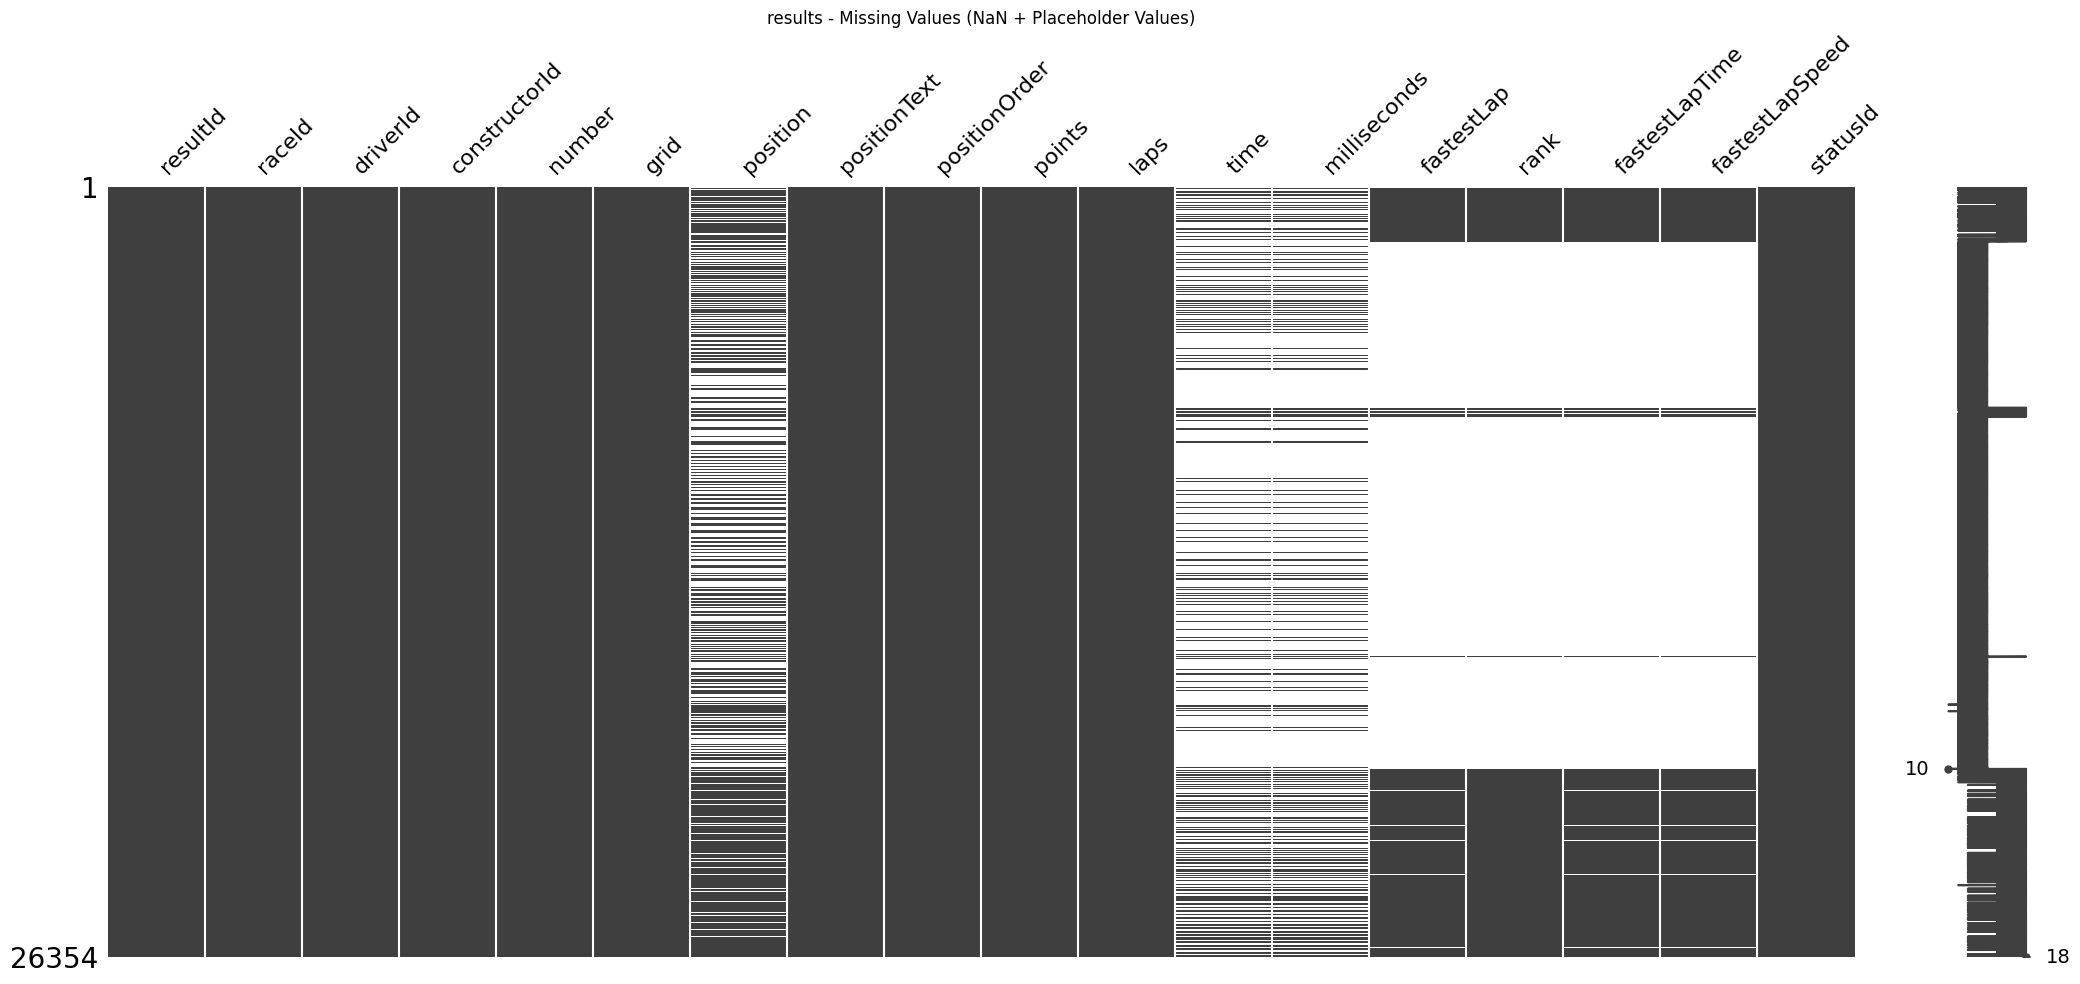


Numeric Distributions:


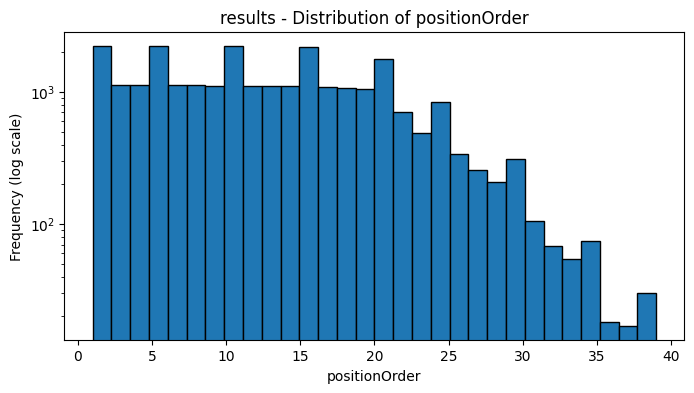

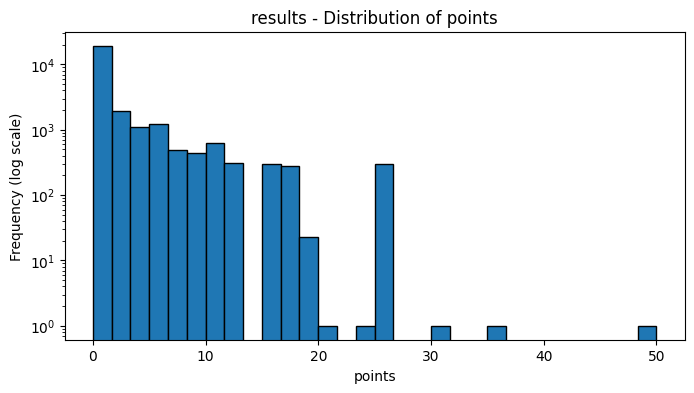

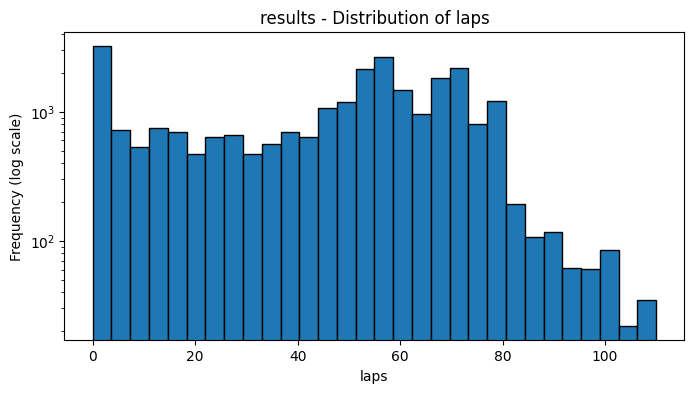

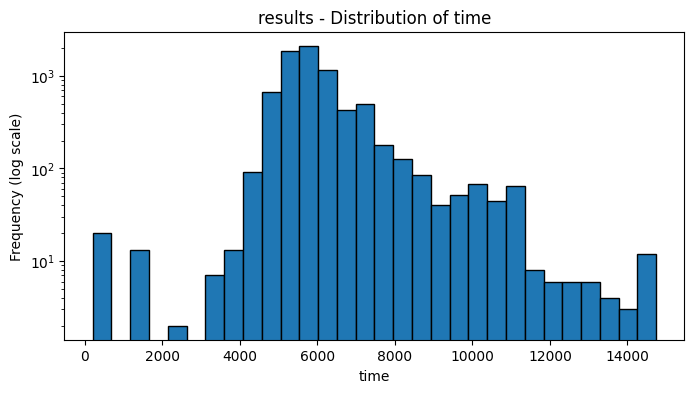

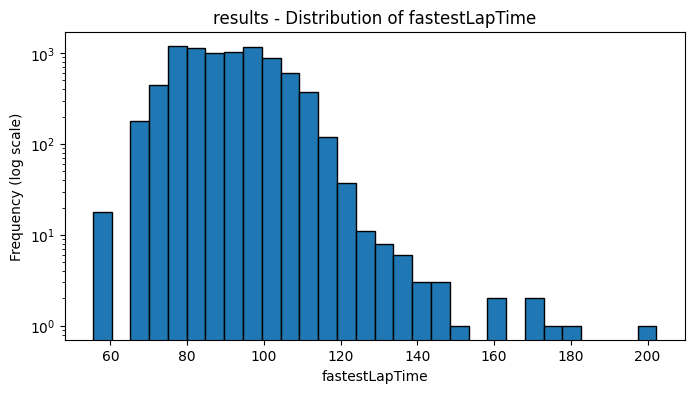

In [ ]:
inspect_df("results", results)

position can be missing for drivers who were not classified, while positionOrder gives a complete ordering of entrants. That's why target is  "positionOrder <= 3"

the columns with the most missingness are primarily post-race measurements that are not eligible as pre-race predictive features anyway.

In [ ]:
results = results.drop(columns=[
    "position",
    "time",
    "milliseconds",
    "fastestLap",
    "rank",
    "fastestLapTime",
    "fastestLapSpeed",
])

The isolated values around 25, 30+, 36, and 50 are not automatically errors because F1 scoring systems changed historically and some races awarded unusual point totals

In [ ]:
print("Minimum points:", results["points"].min())
print("Maximum points:", results["points"].max())

Minimum points: 0.0
Maximum points: 50.0


In [ ]:
display(
    results[
        results["points"] > 25
    ][
        [
            "raceId",
            "driverId",
            "positionOrder",
            "points"
        ]
    ].sort_values("points")
)

,raceId,driverId,positionOrder,points
24197,1010,822,1,26.000
24380,1019,1,1,26.000
24360,1018,830,1,26.000
24277,1014,1,1,26.000
24400,1020,830,1,26.000
24660,1033,1,1,26.000
24601,1030,1,1,26.000
24500,1025,1,1,26.000
24800,1040,822,1,26.000
24840,1042,1,1,26.000


high values mostly winners

To answer question 1

In [ ]:
results["front_row"] = results["grid"].isin([1, 2])

For The Model

In [ ]:
results["podium"] = (
    results["positionOrder"] <= 3
)

**grid** → valid model feature
**positionOrder**→ target construction only, then remove before training
**statusId**→ needed for mechanical-retirement analysis, not as a model feature
**raceId**, driverId, constructorId → join keys / identifiers
**number** → not useful as a feature.

podium
False    22993
True      3361
Name: count, dtype: int64
Podium rate: 12.75%


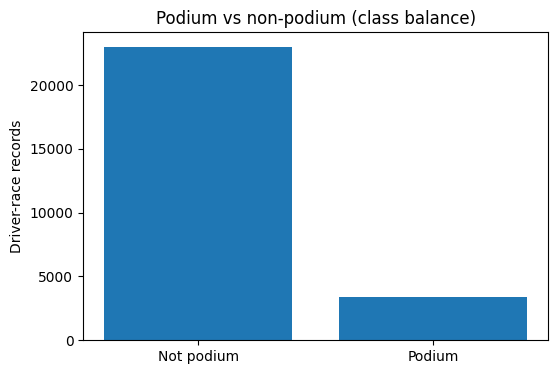

In [ ]:
# Target balance: podium (finished 1st-3rd) vs not
podium_counts = results["podium"].value_counts().sort_index()
print(podium_counts)
print(f"Podium rate: {results['podium'].mean():.2%}")

plt.figure(figsize=(6, 4))
plt.bar(["Not podium", "Podium"], podium_counts.values)
plt.ylabel("Driver-race records")
plt.title("Podium vs non-podium (class balance)")
plt.show()

The target is imbalanced because each race contains only three podium positions while substantially more drivers participate. This supports the later use of PR-AUC in addition to ROC-AUC and F1.

In [ ]:
results["grid"].value_counts().sort_index()

,count
grid,
0,1638
1,1125
2,1112
3,1118
4,1119
5,1120
6,1112
7,1121
8,1115


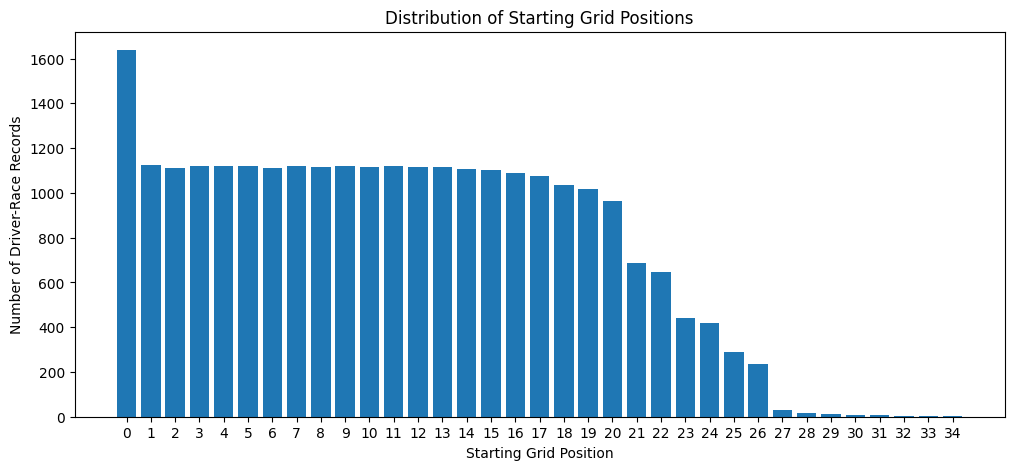

In [ ]:
grid_counts = (
    results["grid"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12, 5))

plt.bar(
    grid_counts.index,
    grid_counts.values
)

plt.xlabel("Starting Grid Position")
plt.ylabel("Number of Driver-Race Records")
plt.title("Distribution of Starting Grid Positions")

plt.xticks(grid_counts.index)

plt.show()

In [ ]:
grid_zero = results[
    results["grid"] == 0
].copy()

print("Number of grid = 0 rows:", len(grid_zero))

Number of grid = 0 rows: 1638


In [ ]:
grid_zero_status = (
    results[results["grid"] == 0]
    .merge(
        status[["statusId", "status"]],
        on="statusId",
        how="left"
    )
)

print(
    grid_zero_status[
        ["status", "positionText"]
    ]
    .value_counts()
)

status              positionText
Did not qualify     F               1013
Did not prequalify  F                331
Withdrew            W                164
Accident            W                 18
Disqualified        D                  6
Engine              W                  6
Excluded            E                  6
Injury              W                  6
+1 Lap              17                 4
                    15                 4
                    10                 4
                    13                 4
+2 Laps             17                 3
Finished            10                 3
Retired             R                  3
Finished            5                  3
                    11                 3
                    13                 3
+1 Lap              16                 3
                    18                 3
107% Rule           F                  2
Accident            R                  2
+1 Lap              12                 2
Collision damage    R   

**Failed-to-qualify rows (`positionText` = "F").** In eras with more entrants than grid places, drivers who were too slow in (pre-)qualifying still have a result row, although they never started the race. The check below shows what these rows are before we remove them.

Failed-to-qualify rows: 1,368 of 26,354 result rows (5.2%)
Grid position of these rows: {0: 1348, 22: 6, 21: 5, 25: 2, 27: 2, 23: 1, 20: 1, 24: 1, 28: 1, 26: 1}
Podiums among them: 0


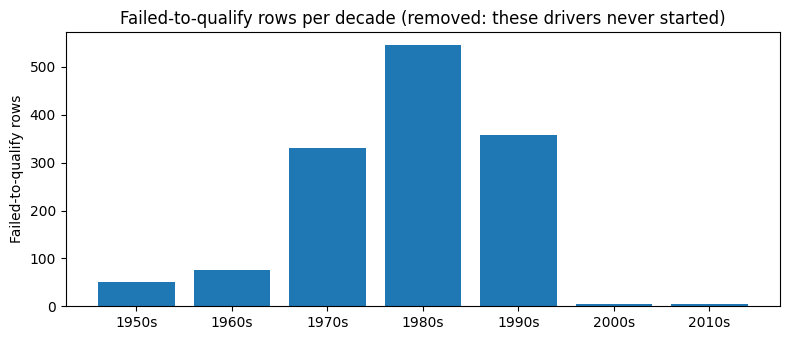

In [ ]:
# Before removing them: what are the failed-to-qualify (F) rows?
f_rows = results[results["positionText"] == "F"].merge(races[["raceId", "year"]], on="raceId")
print(f"Failed-to-qualify rows: {len(f_rows):,} of {len(results):,} result rows ({len(f_rows) / len(results):.1%})")
print("Grid position of these rows:", f_rows["grid"].value_counts().to_dict())
print("Podiums among them:", int((f_rows["positionOrder"] <= 3).sum()))

decade_f = (f_rows["year"] // 10 * 10).value_counts().sort_index()
plt.figure(figsize=(8, 3.5))
plt.bar(decade_f.index.astype(str) + "s", decade_f.values)
plt.ylabel("Failed-to-qualify rows")
plt.title("Failed-to-qualify rows per decade (removed: these drivers never started)")
plt.tight_layout()
plt.show()

**Decision: remove them.** 1,368 rows (5.2%): 1,348 have grid 0 and the other 20 only a placeholder slot at the very back (20–28), and none was ever a podium: the drivers did not take part in the race, and at the prediction cutoff it is already known that they will not start. They are not "a driver entering a race", our unit of analysis. Keeping them would add guaranteed non-podium rows, mostly from the oversubscribed 1980s and early 1990s (plot), and lower the podium base rate in those years for a reason that has nothing to do with racing.

In [ ]:
results = results[
    results["positionText"] != "F"
].copy()

In [ ]:
grid_zero_status = (
    results[results["grid"] == 0]
    .merge(
        status[["statusId", "status"]],
        on="statusId",
        how="left"
    )
)

print(
    grid_zero_status[
        ["status", "positionText"]
    ]
    .value_counts()
)

status            positionText
Withdrew          W               164
Accident          W                18
Engine            W                 6
Excluded          E                 6
Disqualified      D                 6
Injury            W                 6
+1 Lap            15                4
                  10                4
                  17                4
                  13                4
+2 Laps           17                3
+1 Lap            18                3
Finished          10                3
                  11                3
                  13                3
+1 Lap            16                3
Retired           R                 3
Finished          5                 3
+2 Laps           16                2
+1 Lap            12                2
Fuel system       W                 2
Accident          R                 2
Finished          18                2
Power Unit        R                 2
Finished          9                 2
Injured           W

In this dataset, grid = 0 usually means the driver did not take a normal grid slot, often because they failed to qualify, failed pre-qualifying, or withdrew. A smaller number of grid = 0 rows correspond to unusual starts or classified finishes.

**How we encode it.** Left as 0, the grid would tell every model that these drivers start *ahead* of pole position (0 < 1). So `grid_numeric` puts them one place behind the last normal starter of their race, and the flag `non_standard_start` marks them. The evidence that this is right: none of these rows reaches the podium (0% in the binary table of 4.2), exactly like the back of the grid.

In [ ]:
grid_zero_qualifying = (
    results[
        results["grid"] == 0
    ][["raceId", "driverId", "grid", "positionText", "positionOrder", "laps", "statusId"]]
    .merge(
        qualifying[
            ["raceId", "driverId", "position"]
        ].rename(
            columns={"position": "qualifying_position"}
        ),
        on=["raceId", "driverId"],
        how="left"
    )
    .merge(
        races[
            ["raceId", "year", "name"]
        ],
        on="raceId",
        how="left"
    )
    .merge(
        drivers[
            ["driverId", "forename", "surname"]
        ],
        on="driverId",
        how="left"
    )
    .merge(
        status[
            ["statusId", "status"]
        ],
        on="statusId",
        how="left"
    )
)

grid_zero_qualifying["driver_name"] = (
    grid_zero_qualifying["forename"]
    + " "
    + grid_zero_qualifying["surname"]
)

display(
    grid_zero_qualifying[
        [
            "year",
            "name",
            "driver_name",
            "qualifying_position",
            "grid",
            "positionText",
            "positionOrder",
            "laps",
            "status"
        ]
    ]
    .sort_values(["year", "name", "driver_name"])
    .reset_index(drop=True)
)

,year,name,driver_name,qualifying_position,grid,positionText,positionOrder,laps,status
0,1952,British Grand Prix,Bill Aston,NaN,0,W,32,0,Withdrew
1,1954,French Grand Prix,Sergio Mantovani,NaN,0,W,22,0,Withdrew
2,1954,Spanish Grand Prix,Peter Collins,NaN,0,W,22,0,Accident
3,1954,Swiss Grand Prix,Robert Manzon,NaN,0,W,17,0,Accident
4,1955,Belgian Grand Prix,Harry Schell,NaN,0,W,16,0,Withdrew
...,...,...,...,...,...,...,...,...,...
285,2024,Hungarian Grand Prix,Pierre Gasly,20.000,0,R,20,33,Hydraulics
286,2024,Las Vegas Grand Prix,Franco Colapinto,14.000,0,14,14,50,Finished
287,2024,Mexico City Grand Prix,Esteban Ocon,19.000,0,13,13,70,+1 Lap
288,2024,Spanish Grand Prix,Alexander Albon,19.000,0,18,18,65,+1 Lap


In [ ]:
# Flag non-standard starts
results["non_standard_start"] = results["grid"].eq(0)

# Find the worst normal grid position in each race
race_max_grid = (
    results.loc[results["grid"] > 0]
    .groupby("raceId")["grid"]
    .max()
)

# Map race-specific maximum back to each row
results["max_grid_in_race"] = results["raceId"].map(race_max_grid)

# grid=0 becomes one position worse than the worst normal starter in that race
results["grid_numeric"] = results["grid"]

results.loc[
    results["grid"] == 0,
    "grid_numeric"
] = (
    results.loc[
        results["grid"] == 0,
        "max_grid_in_race"
    ] + 1
)

In [ ]:
results[
    [
        "raceId",
        "grid",
        "max_grid_in_race",
        "grid_numeric",
        "non_standard_start"
    ]
].head(5)

,raceId,grid,max_grid_in_race,grid_numeric,non_standard_start
0,18,1,22,1,False
1,18,5,22,5,False
2,18,7,22,7,False
3,18,11,22,11,False
4,18,3,22,3,False


In [ ]:
# 1. Check all non-standard starts
check_non_standard = results[
    results["non_standard_start"]
][
    [
        "raceId",
        "grid",
        "max_grid_in_race",
        "grid_numeric",
        "non_standard_start"
    ]
]

display(check_non_standard.head(10))

,raceId,grid,max_grid_in_race,grid_numeric,non_standard_start
2972,159,0,20,21,True
2973,159,0,20,21,True
4313,220,0,21,22,True
4357,222,0,22,23,True
5113,255,0,23,24,True
5219,259,0,25,26,True
5246,260,0,24,25,True
5247,260,0,24,25,True
5274,261,0,26,27,True
6270,297,0,26,27,True


In [ ]:
def check_position_order_sequence(group):
    vals = sorted(group["positionOrder"].tolist())
    expected = list(range(1, len(vals) + 1))
    return vals == expected

sequence_check = (
    results
    .groupby("raceId")
    .apply(check_position_order_sequence)
)

print("Races with correct sequential positionOrder:",
      sequence_check.sum())

print("Races with problems:",
      (~sequence_check).sum())

Races with correct sequential positionOrder: 1052
Races with problems: 62


In [ ]:
problem_races = sequence_check[
    ~sequence_check
].index

display(
    results[
        results["raceId"].isin(problem_races)
    ][
        [
            "raceId",
            "driverId",
            "grid",
            "positionText",
            "positionOrder"
        ]
    ]
    .sort_values(
        ["raceId", "positionOrder"]
    )
)

,raceId,driverId,grid,positionText,positionOrder
6241,297,95,1,1,1
6242,297,119,2,2,2
6243,297,84,6,3,3
6244,297,30,4,4,4
6245,297,77,5,5,5
...,...,...,...,...,...
20171,839,763,4,R,23
20172,839,626,10,R,24
20173,839,669,15,R,25
20174,839,756,27,R,26


**Result.** 62 races fail this check, for three reasons, none of which affects the target:
- **36 races** contain shared-drive duplicates (the same driver in two cars), handled in 2.6.
- **22 races** have gaps at the bottom of the order, because the failed-to-qualify (F) rows were removed above. The gaps never reach positions 1–3.
- **4 races** have true ties: two drivers credited with the same position because they shared one car.

`positionOrder <= 3` (the podium) is therefore still correct in every race.

### 2.5.3 Drivers



drivers
--------------------------------------------------

Shape:
(861, 9)

Columns:
['driverId', 'driverRef', 'number', 'code', 'forename', 'surname', 'dob', 'nationality', 'url']

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 861 entries, 0 to 860
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   driverId     861 non-null    int64         
 1   driverRef    861 non-null    object        
 2   number       59 non-null     object        
 3   code         104 non-null    object        
 4   forename     861 non-null    object        
 5   surname      861 non-null    object        
 6   dob          861 non-null    datetime64[ns]
 7   nationality  861 non-null    object        
 8   url          861 non-null    object        
dtypes: datetime64[ns](1), int64(1), object(7)
memory usage: 60.7+ KB

Dtypes:
driverId                int64
driverRef              object
number                 objec

,driverId,driverRef,number,code,forename,surname,dob,nationality,url
count,861.000,861,59,104,861,861,861,861,861
unique,NaN,861,48,97,478,802,NaN,43,861
top,NaN,doohan,6,ALB,John,Taylor,NaN,British,http://en.wikipedia.org/wiki/Jack_Doohan
freq,NaN,1,2,2,14,5,NaN,166,1
mean,431.062,NaN,NaN,NaN,NaN,NaN,1941-09-24 08:28:25.923344896,NaN,NaN
min,1.000,NaN,NaN,NaN,NaN,NaN,1896-12-28 00:00:00,NaN,NaN
25%,216.000,NaN,NaN,NaN,NaN,NaN,1923-01-11 00:00:00,NaN,NaN
50%,431.000,NaN,NaN,NaN,NaN,NaN,1937-02-02 00:00:00,NaN,NaN
75%,646.000,NaN,NaN,NaN,NaN,NaN,1957-11-27 00:00:00,NaN,NaN
max,862.000,NaN,NaN,NaN,NaN,NaN,2005-05-08 00:00:00,NaN,NaN



Full duplicate rows:
0

First 5 rows:


,driverId,driverRef,number,code,forename,surname,dob,nationality,url
0,1,hamilton,44,HAM,Lewis,Hamilton,1985-01-07,British,http://en.wikipedia.org/wiki/Lewis_Hamilton
1,2,heidfeld,<NA>,HEI,Nick,Heidfeld,1977-05-10,German,http://en.wikipedia.org/wiki/Nick_Heidfeld
2,3,rosberg,6,ROS,Nico,Rosberg,1985-06-27,German,http://en.wikipedia.org/wiki/Nico_Rosberg
3,4,alonso,14,ALO,Fernando,Alonso,1981-07-29,Spanish,http://en.wikipedia.org/wiki/Fernando_Alonso
4,5,kovalainen,<NA>,KOV,Heikki,Kovalainen,1981-10-19,Finnish,http://en.wikipedia.org/wiki/Heikki_Kovalainen



Missing values (actual NaN):
driverId         0
driverRef        0
number         802
code           757
forename         0
surname          0
dob              0
nationality      0
url              0
dtype: int64

Placeholder missing values:
No placeholder missing values found.


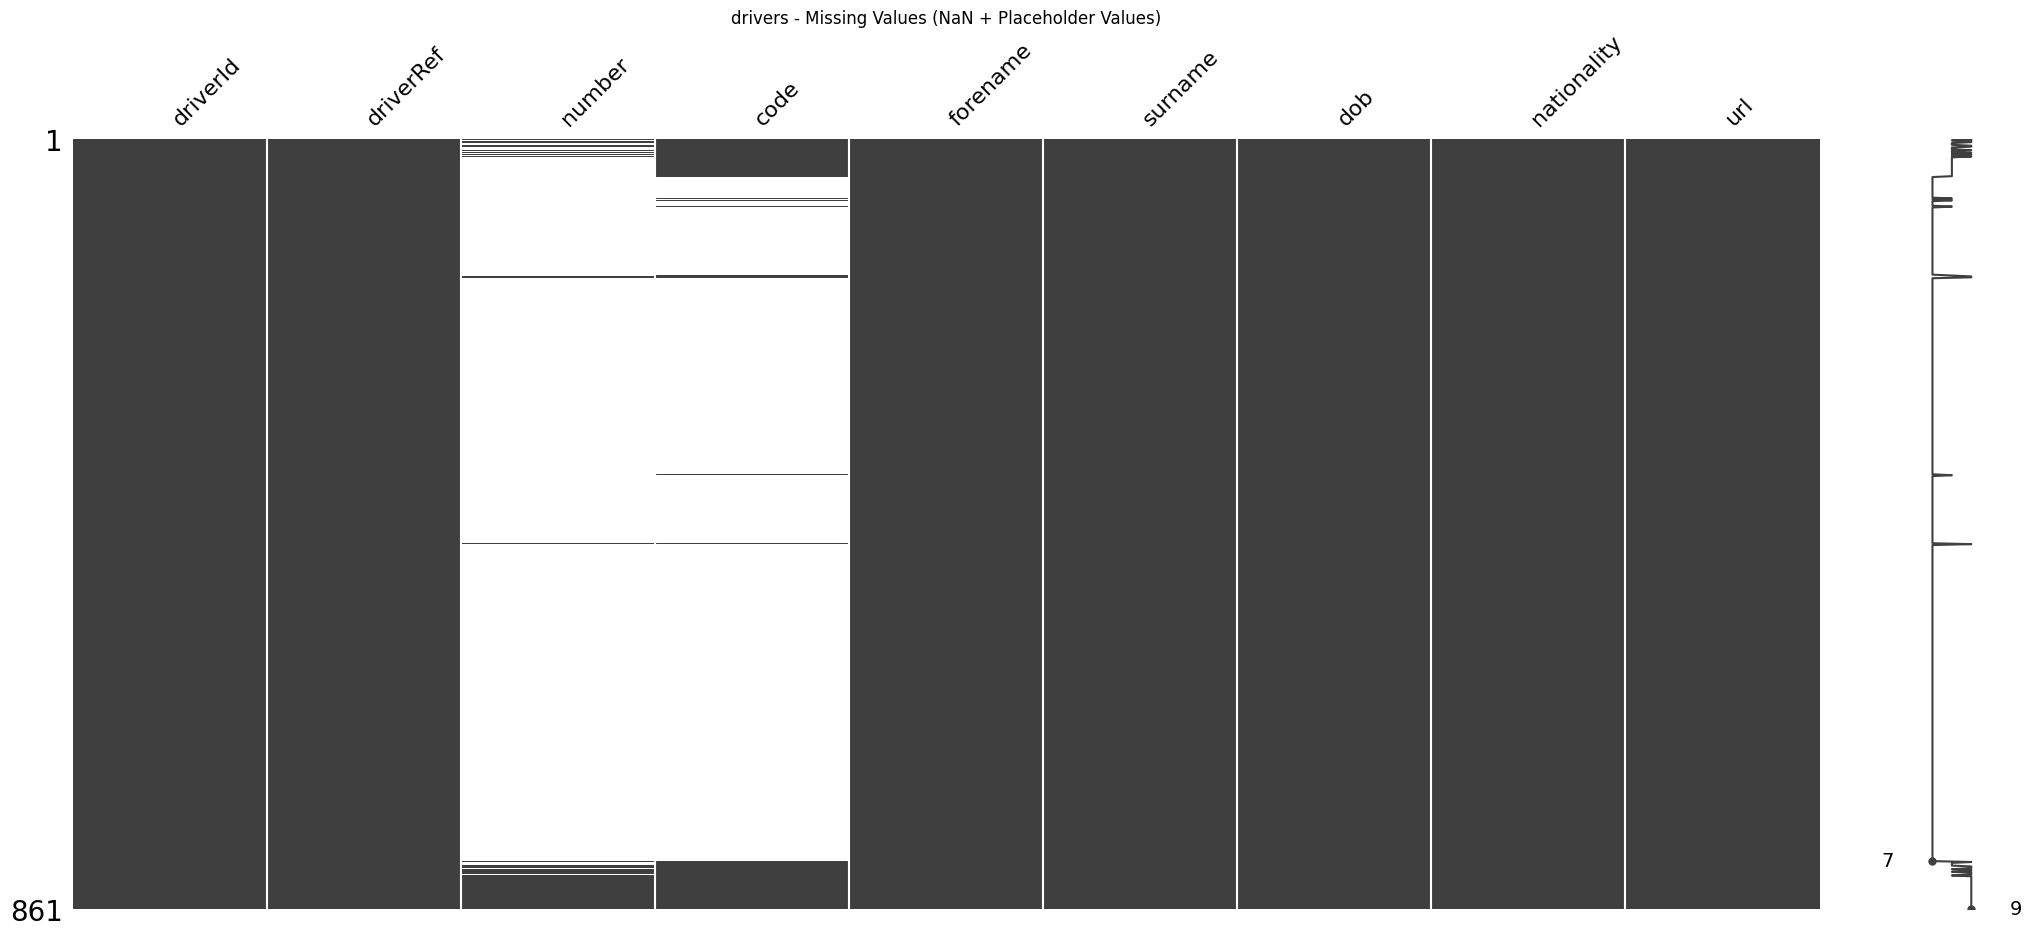

In [ ]:
inspect_df("drivers", drivers)

In [ ]:
drivers=drivers.drop(columns=["number","code"])

In [ ]:
drivers["dob"] = pd.to_datetime(
    drivers["dob"],
    errors="coerce"
)

### 2.5.4 Constructors



constructors
--------------------------------------------------

Shape:
(212, 5)

Columns:
['constructorId', 'constructorRef', 'name', 'nationality', 'url']

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 212 entries, 0 to 211
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   constructorId   212 non-null    int64 
 1   constructorRef  212 non-null    object
 2   name            212 non-null    object
 3   nationality     212 non-null    object
 4   url             212 non-null    object
dtypes: int64(1), object(4)
memory usage: 8.4+ KB

Dtypes:
constructorId      int64
constructorRef    object
name              object
nationality       object
url               object
dtype: object

Descriptive Statistics:


,constructorId,constructorRef,name,nationality,url
count,212.000,212,212,212,212
unique,NaN,212,212,24,175
top,NaN,mclaren,McLaren,British,http://en.wikipedia.org/wiki/Cooper_Car_Company
freq,NaN,1,1,86,11
mean,107.547,NaN,NaN,NaN,NaN
std,61.953,NaN,NaN,NaN,NaN
min,1.000,NaN,NaN,NaN,NaN
25%,54.750,NaN,NaN,NaN,NaN
50%,107.500,NaN,NaN,NaN,NaN
75%,160.250,NaN,NaN,NaN,NaN



Full duplicate rows:
0

First 5 rows:


,constructorId,constructorRef,name,nationality,url
0,1,mclaren,McLaren,British,http://en.wikipedia.org/wiki/McLaren
1,2,bmw_sauber,BMW Sauber,German,http://en.wikipedia.org/wiki/BMW_Sauber
2,3,williams,Williams,British,http://en.wikipedia.org/wiki/Williams_Grand_Prix_Engineering
3,4,renault,Renault,French,http://en.wikipedia.org/wiki/Renault_in_Formula_One
4,5,toro_rosso,Toro Rosso,Italian,http://en.wikipedia.org/wiki/Scuderia_Toro_Rosso



Missing values (actual NaN):
constructorId     0
constructorRef    0
name              0
nationality       0
url               0
dtype: int64

Placeholder missing values:
No placeholder missing values found.


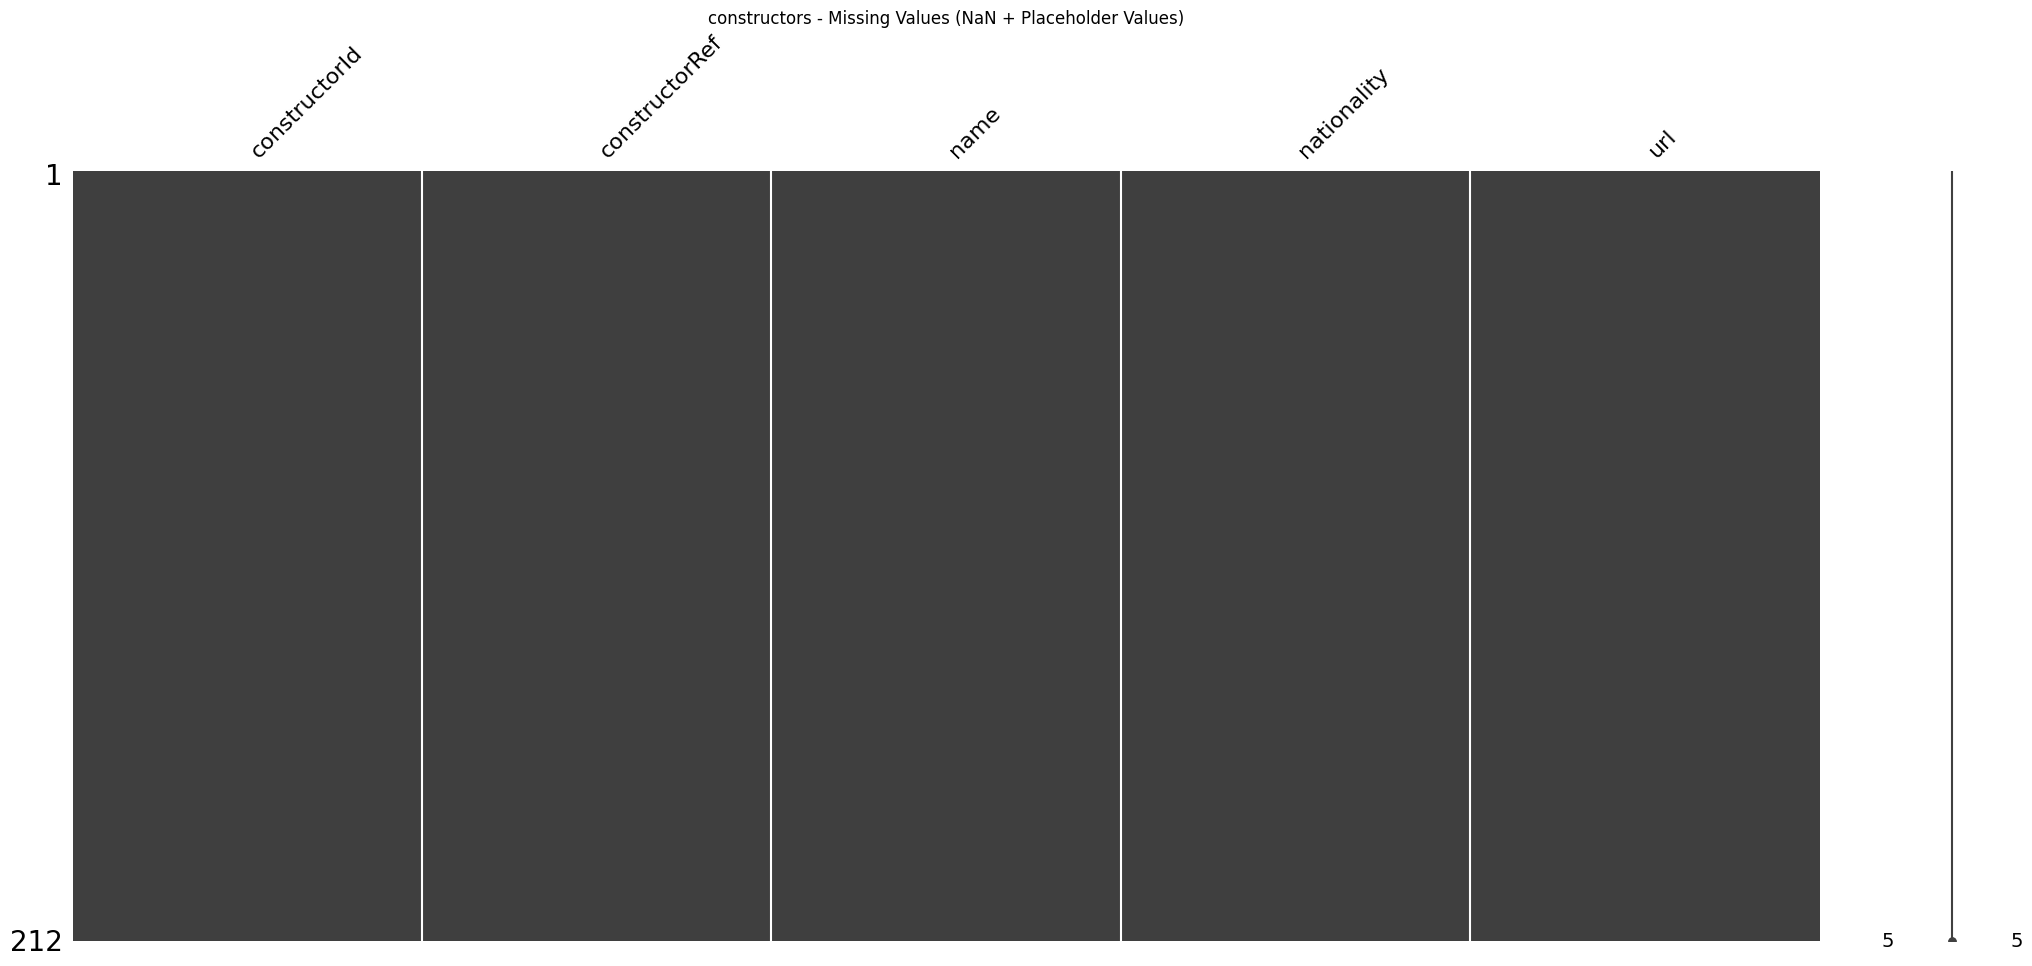

In [ ]:
inspect_df("constructors", constructors)

In [ ]:
# Each constructorId should have exactly one name (empty output = no conflicts)
constructor_name_check = (
    constructors
    .groupby("constructorId")["name"]
    .nunique()
)

print(
    constructor_name_check[
        constructor_name_check != 1
    ]
)

Series([], Name: name, dtype: int64)


### 2.5.5 Circuits



circuits
--------------------------------------------------

Shape:
(77, 9)

Columns:
['circuitId', 'circuitRef', 'name', 'location', 'country', 'lat', 'lng', 'alt', 'url']

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     object 
 2   name        77 non-null     object 
 3   location    77 non-null     object 
 4   country     77 non-null     object 
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 5.5+ KB

Dtypes:
circuitId       int64
circuitRef     object
name           object
location       object
country        object
lat           float64
lng           float64
alt             int64
url            obje

,circuitId,circuitRef,name,location,country,lat,lng,alt,url
count,77.000,77,77,77,77,77.000,77.000,77.000,77
unique,NaN,77,77,75,35,NaN,NaN,NaN,77
top,NaN,albert_park,Albert Park Grand Prix Circuit,California,USA,NaN,NaN,NaN,http://en.wikipedia.org/wiki/Melbourne_Grand_Prix_Circuit
freq,NaN,1,1,2,11,NaN,NaN,NaN,1
mean,39.883,NaN,NaN,NaN,NaN,33.443,1.077,247.013,NaN
std,23.002,NaN,NaN,NaN,NaN,22.809,65.517,362.738,NaN
min,1.000,NaN,NaN,NaN,NaN,-37.850,-118.189,-7.000,NaN
25%,20.000,NaN,NaN,NaN,NaN,32.777,-9.394,18.000,NaN
50%,40.000,NaN,NaN,NaN,NaN,40.952,3.931,129.000,NaN
75%,59.000,NaN,NaN,NaN,NaN,46.959,19.249,332.000,NaN



Full duplicate rows:
0

First 5 rows:


,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.850,144.968,10,http://en.wikipedia.org/wiki/Melbourne_Grand_Prix_Circuit
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.761,101.738,18,http://en.wikipedia.org/wiki/Sepang_International_Circuit
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.032,50.511,7,http://en.wikipedia.org/wiki/Bahrain_International_Circuit
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.570,2.261,109,http://en.wikipedia.org/wiki/Circuit_de_Barcelona-Catalunya
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.952,29.405,130,http://en.wikipedia.org/wiki/Istanbul_Park



Missing values (actual NaN):
circuitId     0
circuitRef    0
name          0
location      0
country       0
lat           0
lng           0
alt           0
url           0
dtype: int64

Placeholder missing values:
No placeholder missing values found.


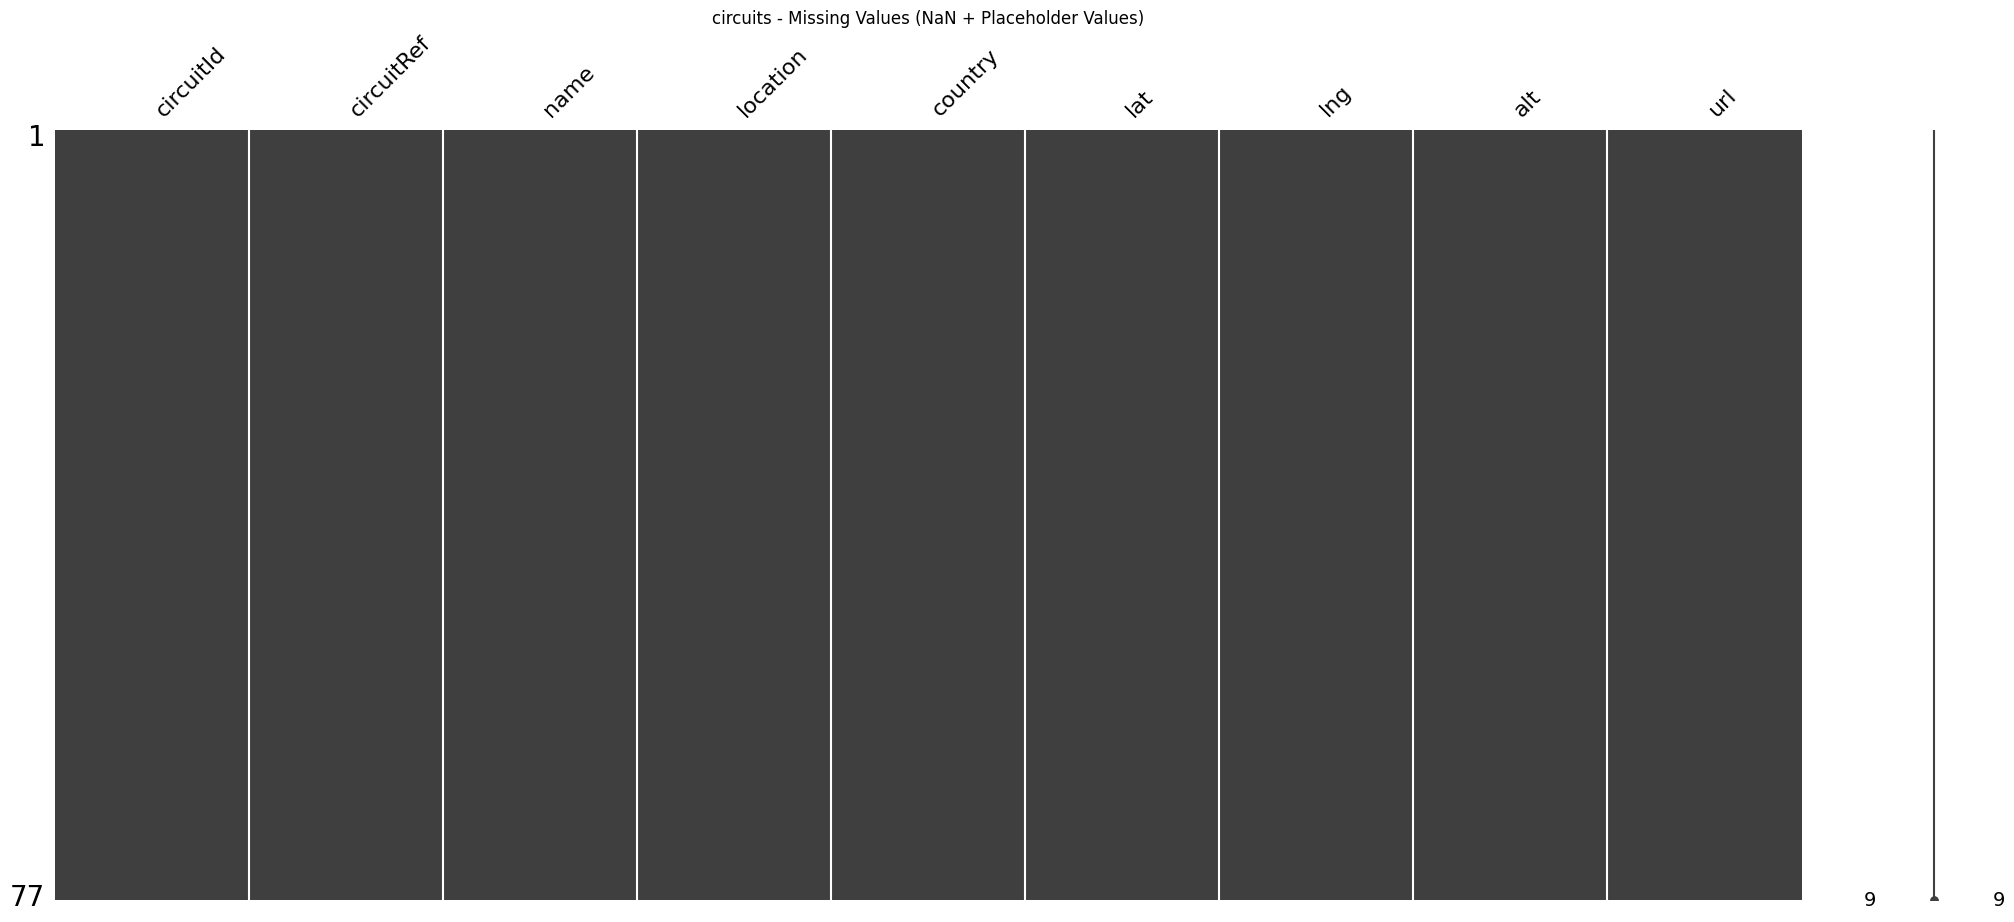


Numeric Distributions:


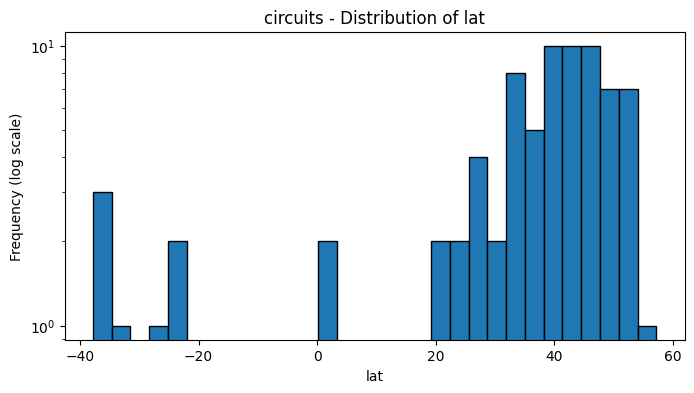

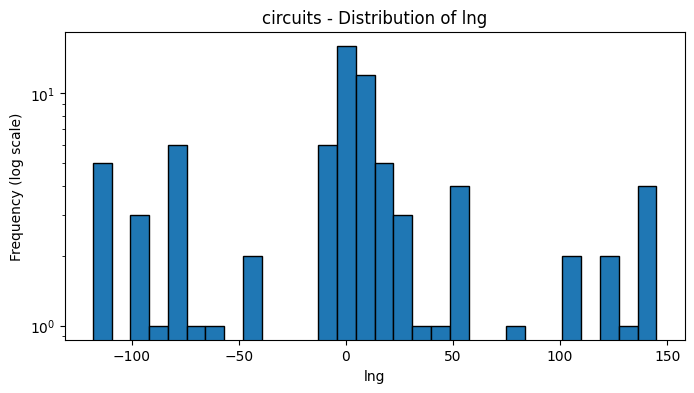

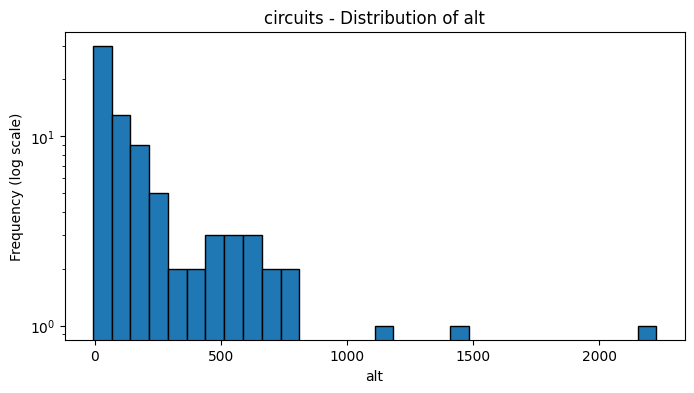

In [ ]:
inspect_df("circuits", circuits)

Investigating Country Name Consistency

Before standardizing the `country` column, we first inspect the unique country values and their frequencies to identify possible inconsistencies in how countries are represented.

This is important because inconsistent country naming can affect comparisons and joins with other datasets or lookup tables.

In [ ]:
# Count the occurrences of each country
country_counts = (
    circuits['country']
    .value_counts()
    .sort_index()
)

print(f"Number of unique countries: {circuits['country'].nunique()}")
display(country_counts.to_frame('number_of_circuits'))

Number of unique countries: 35


,number_of_circuits
country,
Argentina,1
Australia,2
Austria,2
Azerbaijan,1
Bahrain,1
Belgium,3
Brazil,2
Canada,3
China,1


Finding

The frequency table shows that the country **United States** appears once, while **USA** appears 11 times.

These two values refer to the same country but are represented differently in the dataset. This inconsistency could cause incorrect country comparisons, so `United States` will be standardized to `USA`.

In [ ]:
# Standardize the country name
circuits['country'] = circuits['country'].replace(
    'United States',
    'USA'
)
# Verify the standardization
print(
    circuits['country']
    .value_counts()
    .loc[lambda x: x.index.isin(['USA', 'United States'])]
)

country
USA    12
Name: count, dtype: int64


**Result.** Apart from the `United States` → `USA` fix above, the circuits table needed no cleaning: no missing values, no `\N` entries, no duplicate rows, and all columns have suitable types.

### 2.5.6 Qualifying



qualifying
--------------------------------------------------

Shape:
(10494, 9)

Columns:
['qualifyId', 'raceId', 'driverId', 'constructorId', 'number', 'position', 'q1', 'q2', 'q3']

Info:
<class 'pandas.core.frame.DataFrame'>
Index: 10494 entries, 0 to 10493
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   qualifyId      10494 non-null  int64  
 1   raceId         10494 non-null  int64  
 2   driverId       10494 non-null  int64  
 3   constructorId  10494 non-null  int64  
 4   number         10494 non-null  int64  
 5   position       10494 non-null  int64  
 6   q1             10338 non-null  float64
 7   q2             5847 non-null   float64
 8   q3             3629 non-null   float64
dtypes: float64(3), int64(6)
memory usage: 819.8 KB

Dtypes:
qualifyId          int64
raceId             int64
driverId           int64
constructorId      int64
number             int64
position           int64
q1        

,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
count,10494.000,10494.000,10494.000,10494.000,10494.000,10494.000,10338.000,5847.000,3629.000
mean,5262.483,624.601,343.002,47.918,18.786,11.196,88.531,87.770,87.406
std,3046.588,428.298,389.586,73.218,18.448,6.260,15.393,12.111,12.260
min,1.000,1.000,1.000,1.000,0.000,1.000,53.904,53.647,53.377
25%,2625.250,160.000,17.000,4.000,7.000,6.000,78.773,77.942,77.238
50%,5249.500,870.000,60.000,9.000,14.000,11.000,87.141,87.125,87.039
75%,7893.750,1006.000,822.000,31.000,22.000,16.000,95.909,95.956,95.626
max,10551.000,1144.000,862.000,215.000,99.000,28.000,1002.640,132.470,129.776



Full duplicate rows:
0

First 5 rows:


,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,86.572,85.187,86.714
1,2,18,9,2,4,2,86.103,85.315,86.869
2,3,18,5,1,23,3,85.664,85.452,87.079
3,4,18,13,6,2,4,85.994,85.691,87.178
4,5,18,2,2,3,5,85.960,85.518,87.236



Missing values (actual NaN):
qualifyId           0
raceId              0
driverId            0
constructorId       0
number              0
position            0
q1                156
q2               4647
q3               6865
dtype: int64

Placeholder missing values:
No placeholder missing values found.


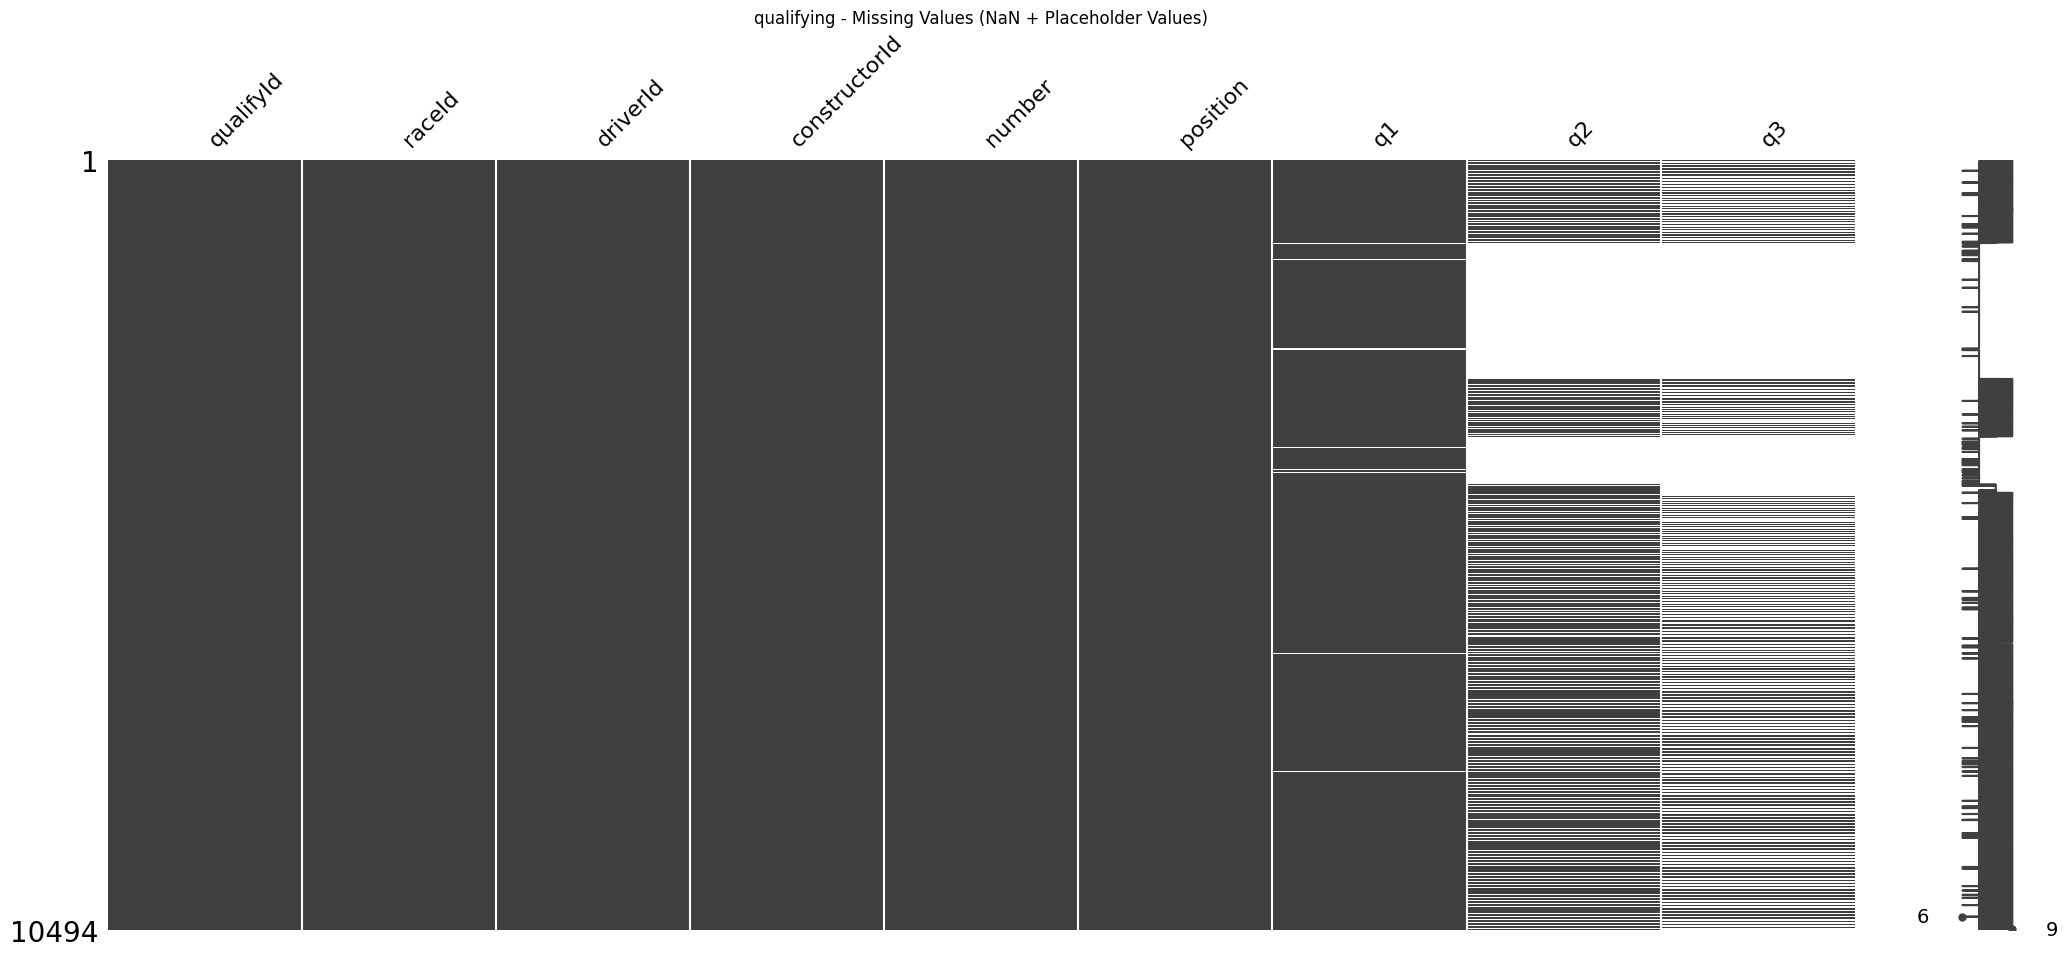


Numeric Distributions:


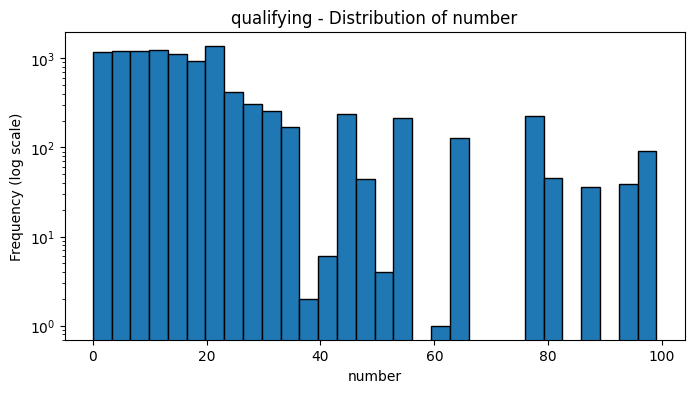

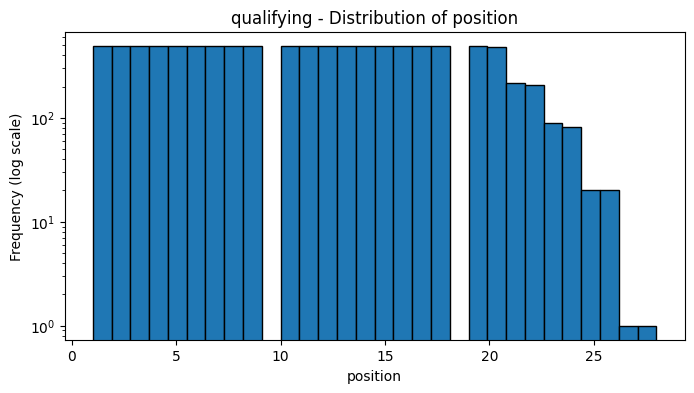

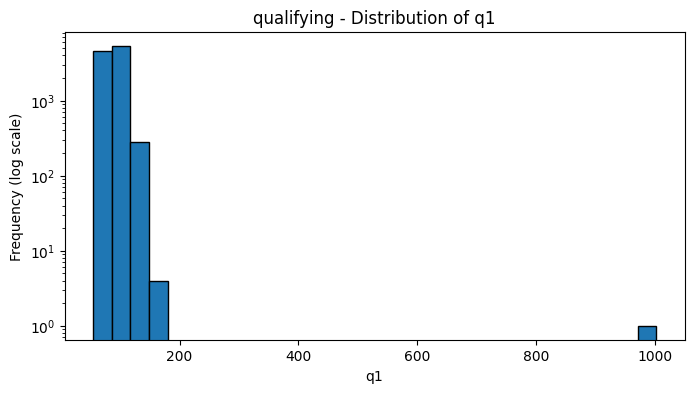

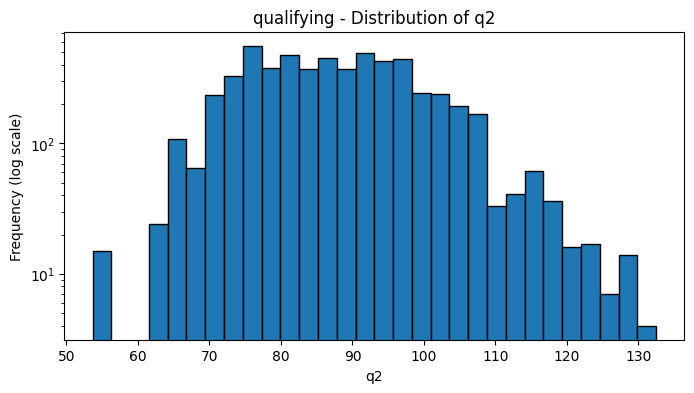

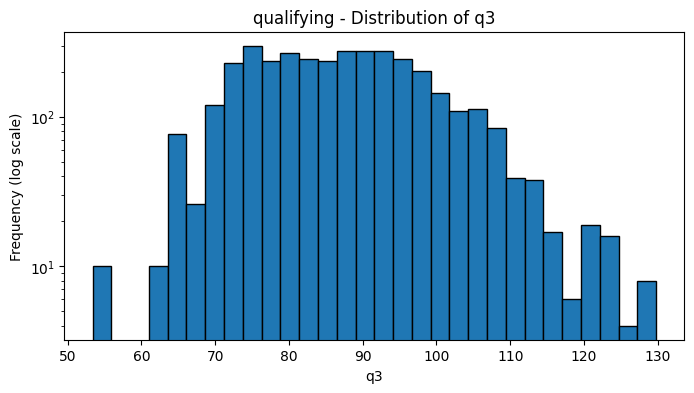

In [ ]:
inspect_df("qualifying", qualifying)

The table contains no duplicate rows. Missing values are present in the qualifying time columns (q1, q2, and q3).

In [ ]:

# Join qualifying records with the season of each race
q = qualifying.merge(
    races[["raceId", "year"]],
    on="raceId",
    how="left"
).copy()

# Ensure missing values are handled consistently
lap_columns = ["q1", "q2", "q3"]

# Convert blank strings to missing values, if present
q[lap_columns] = q[lap_columns].replace(r"^\s*$", pd.NA, regex=True)

# Calculate yearly coverage
coverage = q.groupby("year").agg(
    total_entries=("raceId", "size"),
    q1_available=("q1", "count"),
    q2_available=("q2", "count"),
    q3_available=("q3", "count"),
    position_available=("position", "count")
)

for col in ["q1", "q2", "q3", "position"]:
    coverage[f"{col}_coverage_pct"] = (
        coverage[f"{col}_available"] / coverage["total_entries"] * 100
    )

display(coverage.round(2))


,total_entries,q1_available,q2_available,q3_available,position_available,q1_coverage_pct,q2_coverage_pct,q3_coverage_pct,position_coverage_pct
year,,,,,,,,,
1994,392,391,0,0,392,99.740,0.000,0.000,100.000
1995,418,394,0,0,418,94.260,0.000,0.000,100.000
1996,148,145,0,0,148,97.970,0.000,0.000,100.000
1997,220,219,0,0,220,99.550,0.000,0.000,100.000
1998,153,151,0,0,153,98.690,0.000,0.000,100.000
1999,65,64,0,0,65,98.460,0.000,0.000,100.000
2000,88,88,0,0,88,100.000,0.000,0.000,100.000
2001,22,22,0,0,22,100.000,0.000,0.000,100.000
2002,42,42,0,0,42,100.000,0.000,0.000,100.000


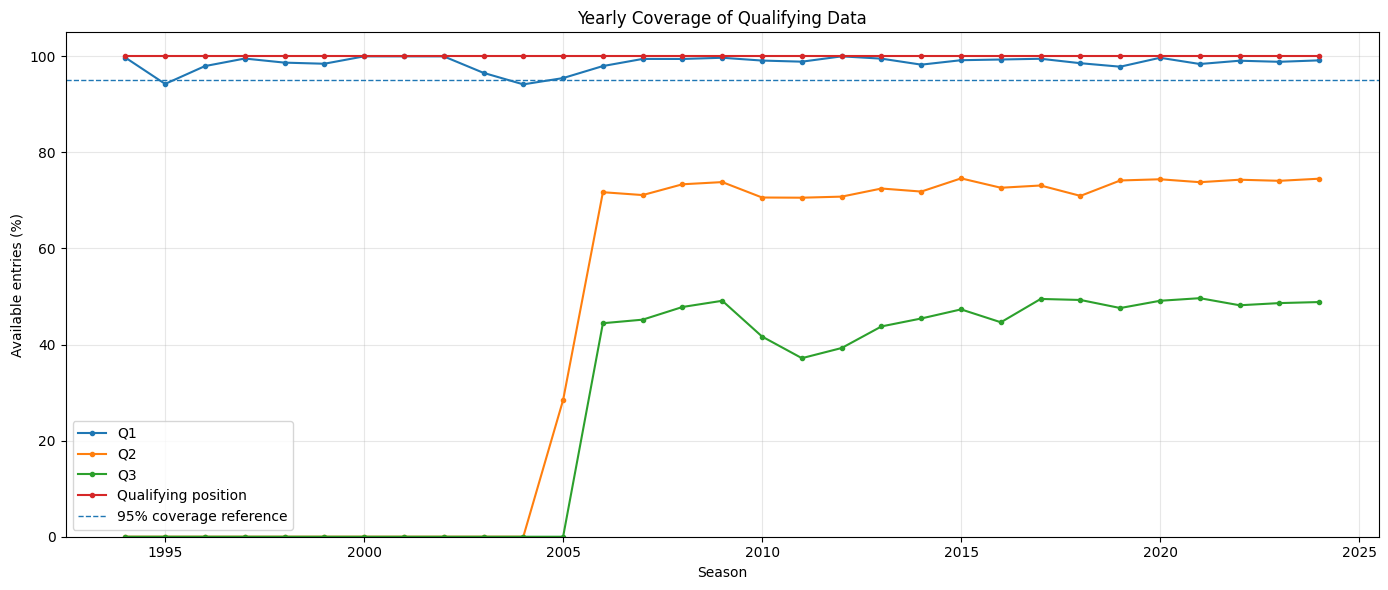

In [ ]:

plt.figure(figsize=(14, 6))

for col in ["q1", "q2", "q3", "position"]:
    plt.plot(
        coverage.index,
        coverage[f"{col}_coverage_pct"],
        marker="o",
        markersize=3,
        label=col.upper() if col != "position" else "Qualifying position"
    )

plt.axhline(95, linestyle="--", linewidth=1, label="95% coverage reference")
plt.xlabel("Season")
plt.ylabel("Available entries (%)")
plt.title("Yearly Coverage of Qualifying Data")
plt.ylim(0, 105)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Qualifying data coverage varies substantially across seasons, confirming the historical coverage drift highlighted in the milestone. Q1 has high coverage throughout the available period, while Q2 and Q3 have very low or zero coverage in the earlier years and increase sharply from around 2005–2006 onward.The graph also indicates that the qualifying dataset begins around 1994.

In [ ]:

end_year = int(q["year"].max())
candidate_starts = [1994, 2000, 2006, 2010, 2015, 2020]

window_rows = []

for start_year in candidate_starts:
    subset = q[q["year"].between(start_year, end_year)]

    row = {
        "start_year": start_year,
        "end_year": end_year,
        "entries": len(subset),
    }

    for col in ["q1", "q2", "q3", "position"]:
        row[f"{col}_coverage_pct"] = (
            subset[col].count() / len(subset) * 100
            if len(subset) else 0
        )

    window_rows.append(row)

window_coverage = pd.DataFrame(window_rows).set_index("start_year")

display(window_coverage.round(2))



,end_year,entries,q1_coverage_pct,q2_coverage_pct,q3_coverage_pct,position_coverage_pct
start_year,,,,,,
1994,2024,10494,98.510,55.720,34.580,100.000
2000,2024,9098,98.640,64.270,39.890,100.000
2006,2024,7890,99.050,72.750,45.990,100.000
2010,2024,6412,99.030,72.820,45.870,100.000
2015,2024,4205,98.950,73.650,48.250,100.000
2020,2024,2138,99.020,74.230,48.880,100.000


**Handling Missing and Inconsistent Qualifying Lap Times**

The `q1`, `q2`, and `q3` columns contain substantial amounts of missing data. Our initial inspection identified 156 missing values in `q1`, 4,647 in `q2`, and 6,865 in `q3`.

**Why We Will Not Impute Missing Lap Times**

We will not fill missing lap times with the mean, median, or artificially generated values. Lap times are actual performance measurements, and even small differences can affect comparisons between drivers. Furthermore, values missing because of historical format differences or qualifying elimination cannot be reliably reconstructed using simple statistical imputation.

**Investigating the Training Window**

To determine whether restricting the training window could improve qualifying-data consistency, we examined the availability of qualifying data across several candidate periods, from 1994–2024 to 2020–2024.

The results showed that Q1 coverage was already consistently high, ranging from approximately 98.5% to 99.1%. Although Q2 coverage increased from 55.72% for 1994–2024 to 72.75% for 2006–2024, and Q3 coverage increased from 34.58% to 45.99%, both columns remained substantially incomplete. Restricting the window further to 2020–2024 provided only modest additional improvements: Q2 coverage reached 74.23% and Q3 coverage reached 48.88%. However, the number of qualifying entries decreased from 7,890 for 2006–2024 to 2,138 for 2020–2024.

Based on these findings, we decided **not to restrict the training window**. Although a more recent period improves Q2 and Q3 coverage, the improvement is limited relative to the amount of historical data lost, and the remaining missingness would still require handling. Since we can avoid relying on these incomplete lap-time columns, retaining the full historical dataset is a more suitable starting point for our project.

**Our Approach: Use Qualifying Position Instead**

Instead of using lap times as model features, we will use the `position` column from the qualifying table as our main qualifying-related feature. This column records each driver's final qualifying position and had 100% coverage across all the candidate windows examined during EDA.

During cleaning, we remove `q2` and `q3` (44% and 65% missing). We **keep `q1`**, because it is 98.5% complete, but it is not a model feature: raw lap times depend on the circuit (a Monaco lap is far shorter than a Spa lap), so they cannot be compared between races, and `q1` exists for exactly the same races as `position`, so it adds no coverage. One impossible `q1` value (more than twice its race's median) is set to missing in the cell below. We keep all available seasons and do not impute artificial lap times.

When joining qualifying data with race results, we will rename qualifying `position` to `qualifying_position` to distinguish it from the finishing position in the results table. We will match records using both `raceId` and `driverId`.

Although qualifying position does not capture actual lap times or the performance gaps between drivers, it provides a direct summary of their qualifying order without requiring the use of incomplete lap-time measurements. We will use it as our initial qualifying-related feature and evaluate its usefulness during model development.

,raceId,driverId,position,q1,times_the_race_median,year,name,surname
0,255,87,24,1002.640,9.900,1995,Japanese Grand Prix,Blundell


Largest ratio among all other rows (a slow but real lap): 1.43


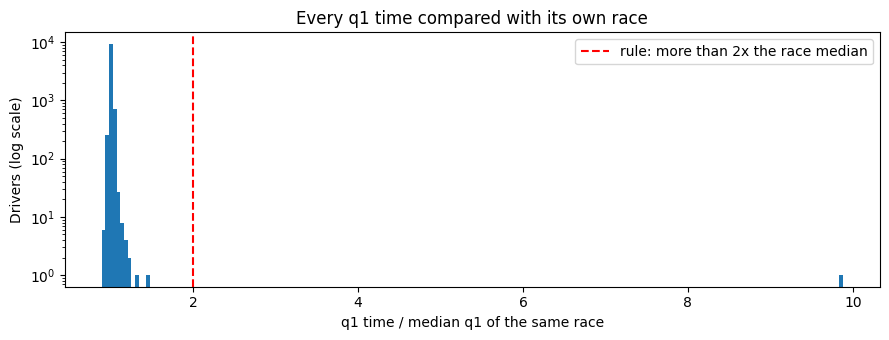

Shape: (10494, 7)
Columns: ['qualifyId', 'raceId', 'driverId', 'constructorId', 'number', 'position', 'q1']
q1 missing: 157 of 10494


,qualifyId,raceId,driverId,constructorId,number,position,q1
0,1,18,1,1,22,1,86.572
1,2,18,9,2,4,2,86.103
2,3,18,5,1,23,3,85.664
3,4,18,13,6,2,4,85.994
4,5,18,2,2,3,5,85.960


In [ ]:
# Drop q2 and q3 (44% and 65% missing, and they only exist since 2005-2006).
# Keep q1: it is 98.5% complete (2.2). It stays in the cleaned table but is not a model feature.
qualifying = qualifying.drop(columns=["q2", "q3"])

# One q1 time is impossible. Rule: a q1 more than twice the median q1 of the same race cannot be a flying lap.
q1_ratio = qualifying["q1"] / qualifying.groupby("raceId")["q1"].transform("median")
impossible_q1 = q1_ratio > 2

display(
    qualifying.loc[impossible_q1, ["raceId", "driverId", "position", "q1"]]
    .assign(times_the_race_median=q1_ratio[impossible_q1].round(1))
    .merge(races[["raceId", "year", "name"]], on="raceId")
    .merge(drivers[["driverId", "surname"]], on="driverId")
)
print("Largest ratio among all other rows (a slow but real lap):", round(q1_ratio[~impossible_q1].max(), 2))

plt.figure(figsize=(9, 3.5))
plt.hist(q1_ratio.dropna(), bins=200, log=True)
plt.axvline(2, color="red", ls="--", label="rule: more than 2x the race median")
plt.xlabel("q1 time / median q1 of the same race")
plt.ylabel("Drivers (log scale)")
plt.title("Every q1 time compared with its own race")
plt.legend()
plt.tight_layout()
plt.show()

qualifying.loc[impossible_q1, "q1"] = np.nan

print("Shape:", qualifying.shape)
print("Columns:", qualifying.columns.tolist())
print("q1 missing:", int(qualifying["q1"].isna().sum()), "of", len(qualifying))
qualifying.head()

### 2.5.7 Status



status
--------------------------------------------------

Shape:
(139, 2)

Columns:
['statusId', 'status']

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 139 entries, 0 to 138
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   statusId  139 non-null    int64 
 1   status    139 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.3+ KB

Dtypes:
statusId     int64
status      object
dtype: object

Descriptive Statistics:


,statusId,status
count,139.000,139
unique,NaN,139
top,NaN,Finished
freq,NaN,1
mean,71.237,NaN
std,41.092,NaN
min,1.000,NaN
25%,35.500,NaN
50%,72.000,NaN
75%,106.500,NaN



Full duplicate rows:
0

First 5 rows:


,statusId,status
0,1,Finished
1,2,Disqualified
2,3,Accident
3,4,Collision
4,5,Engine



Missing values (actual NaN):
statusId    0
status      0
dtype: int64

Placeholder missing values:
No placeholder missing values found.


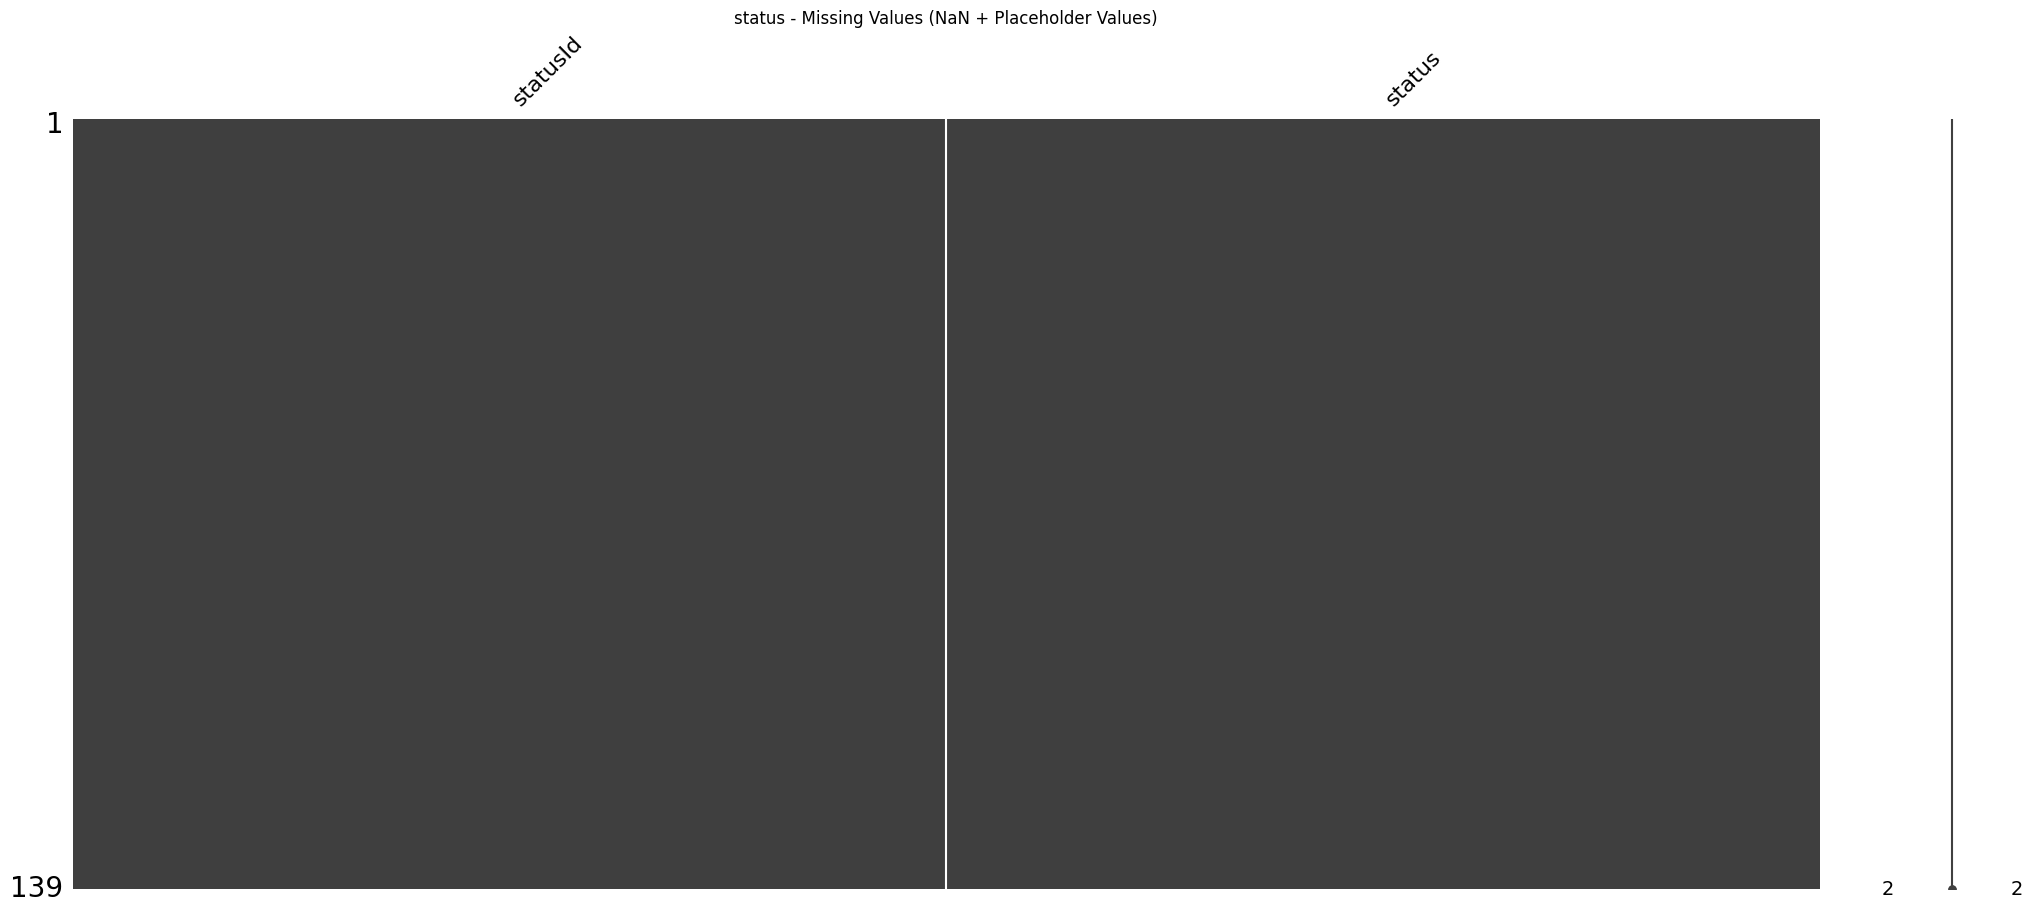

In [ ]:
inspect_df("status", status)

In [ ]:
# Add a column to determine wheather the retirement is mechanical or not
status["retirement_type"] = r"\N"

#Mechanical
mechanical_statuses = [
    "Engine", "Gearbox", "Transmission", "Clutch", "Hydraulics",
    "Electrical", "Radiator", "Suspension", "Brakes", "Differential",
    "Overheating", "Mechanical", "Tyre", "Puncture", "Driveshaft",
    "Fuel pressure", "Water pressure", "Wheel", "Steering", "Technical",
    "Electronics", "Exhaust", "Oil leak", "Wheel rim", "Water leak",
    "Fuel pump", "Oil pressure", "Engine fire", "Turbo", "Ignition",
    "Throttle", "Fuel system", "Out of fuel", "Halfshaft", "Injection",
    "Alternator", "Chassis", "Magneto", "Battery", "Power loss",
    "Distributor", "Oil pump", "Oil pipe", "Fuel leak", "Fuel pipe",
    "Water pump", "Water pipe", "Drivetrain", "Pneumatics",
    "Supercharger", "ERS", "Spark plugs", "Fuel", "Fuel rig",
    "Track rod", "Stalled", "Oil line", "Launch control",
    "Tyre puncture", "Engine misfire", "CV joint", "Brake duct",
    "Cooling system","Wheel nut", "Power Unit", "Axle" ,"Crankshaft",
    "Wheel bearing", "Undertray", "Vibrations", "Rear wing", "Heat shield fire",
    "Broken wing", "Driver Seat", "Seat", "Front wing", "Undertray",

]

status.loc[
    status["status"].isin(mechanical_statuses),
    "retirement_type"
] = "Mechanical"

# Non mechanical
non_mechanical_statuses = [
    "Accident",
    "Collision",
    "Spun off",
    "Fatal accident",
    "Injury",
    "Injured",
    "Physical",
    "Driver unwell",
    "Eye injury",
    "Illness",
    "Collision damage",
    "Disqualified",
    "Retired",
    "Handling",
    "Fire",
    "Safety",
    "Safety concerns",
    "Safety belt",
    "Not restarted",
    "Damage",
    "Debris",
    "Refuelling"
]

status.loc[
    status["status"].isin(non_mechanical_statuses),
    "retirement_type"
] = "Non-mechanical"

# Not a retirmenet

not_retirement_statuses = [
    "Finished",
    "Did not qualify",
    "Did not prequalify",
    "Excluded",
    "Withdrew",
    "107% Rule",
    "Underweight",
    "Not classified"
]
status.loc[
    status["status"].isin(not_retirement_statuses),
    "retirement_type"
] = "Not retirement"

status.loc[
    status["status"].str.match(r"^\+\d+ Lap[s]?$"),
    "retirement_type"
] = "Not retirement"

# check
print(
    status[
        ["statusId", "status", "retirement_type"]
    ].to_string(index=False)
)
print("\nClassification counts:")
print(status["retirement_type"].value_counts())

 statusId             status retirement_type
        1           Finished  Not retirement
        2       Disqualified  Non-mechanical
        3           Accident  Non-mechanical
        4          Collision  Non-mechanical
        5             Engine      Mechanical
        6            Gearbox      Mechanical
        7       Transmission      Mechanical
        8             Clutch      Mechanical
        9         Hydraulics      Mechanical
       10         Electrical      Mechanical
       11             +1 Lap  Not retirement
       12            +2 Laps  Not retirement
       13            +3 Laps  Not retirement
       14            +4 Laps  Not retirement
       15            +5 Laps  Not retirement
       16            +6 Laps  Not retirement
       17            +7 Laps  Not retirement
       18            +8 Laps  Not retirement
       19            +9 Laps  Not retirement
       20           Spun off  Non-mechanical
       21           Radiator      Mechanical
       22 

### 2.5.8 Lap Times



lap_times
--------------------------------------------------

Shape:
(589081, 6)

Columns:
['raceId', 'driverId', 'lap', 'position', 'time', 'milliseconds']

Info:
<class 'pandas.core.frame.DataFrame'>
Index: 589081 entries, 0 to 589080
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   raceId        589081 non-null  int64  
 1   driverId      589081 non-null  int64  
 2   lap           589081 non-null  int64  
 3   position      589081 non-null  int64  
 4   time          589081 non-null  float64
 5   milliseconds  589081 non-null  int64  
dtypes: float64(1), int64(5)
memory usage: 31.5 MB

Dtypes:
raceId            int64
driverId          int64
lap               int64
position          int64
time            float64
milliseconds      int64
dtype: object

Descriptive Statistics:


,raceId,driverId,lap,position,time,milliseconds
count,589081.000,589081.000,589081.000,589081.000,589081.000,589081.000
mean,600.544,325.796,30.018,9.662,95.799,95799.445
std,434.376,387.562,18.407,5.529,76.400,76399.730
min,1.000,1.000,1.000,1.000,55.404,55404.000
25%,140.000,16.000,14.000,5.000,82.041,82041.000
50%,861.000,48.000,29.000,9.000,90.608,90608.000
75%,1003.000,822.000,44.000,14.000,101.930,101930.000
max,1144.000,862.000,87.000,24.000,7507.547,7507547.000



Full duplicate rows:
0

First 5 rows:


,raceId,driverId,lap,position,time,milliseconds
0,841,20,1,1,98.109,98109
1,841,20,2,1,93.006,93006
2,841,20,3,1,92.713,92713
3,841,20,4,1,92.803,92803
4,841,20,5,1,92.342,92342



Missing values (actual NaN):
raceId          0
driverId        0
lap             0
position        0
time            0
milliseconds    0
dtype: int64

Placeholder missing values:
No placeholder missing values found.


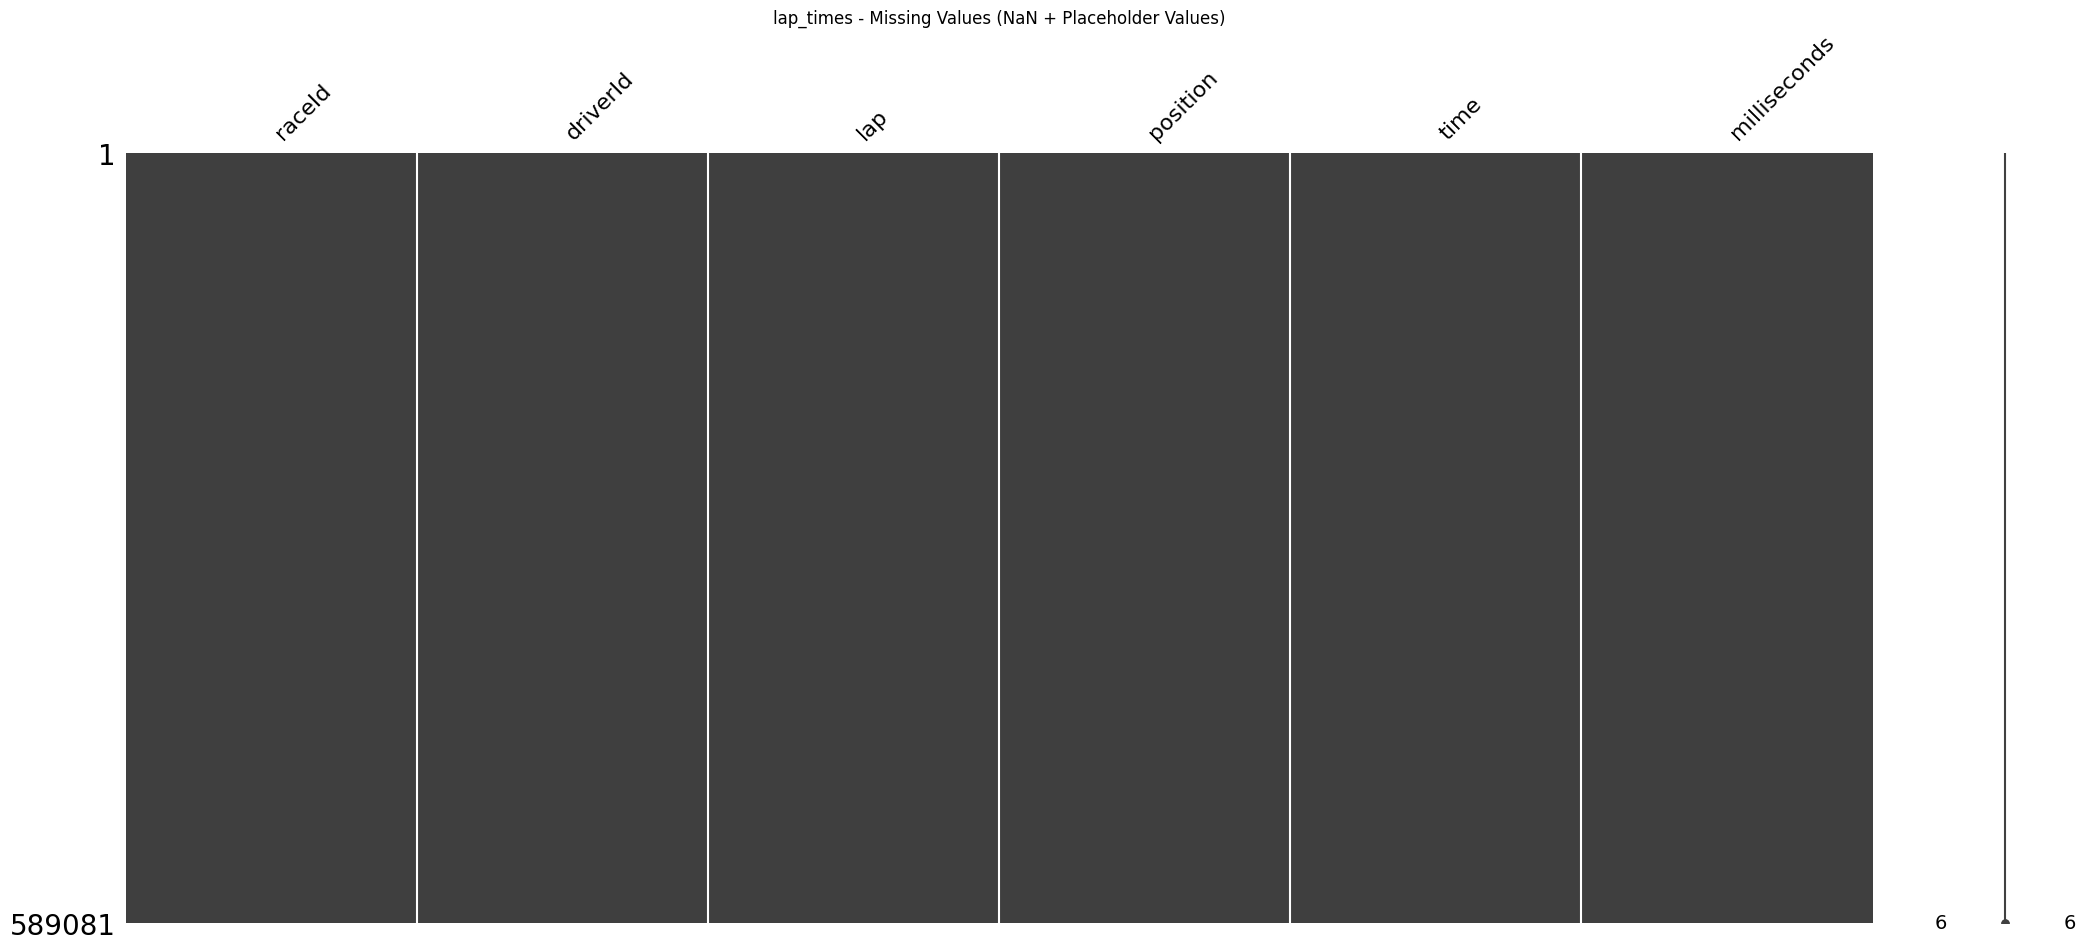


Numeric Distributions:


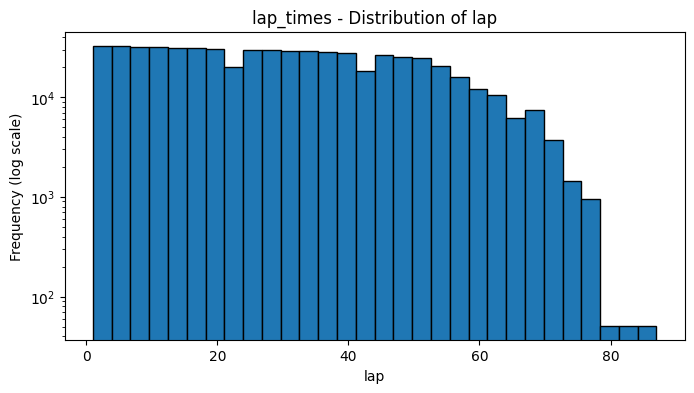

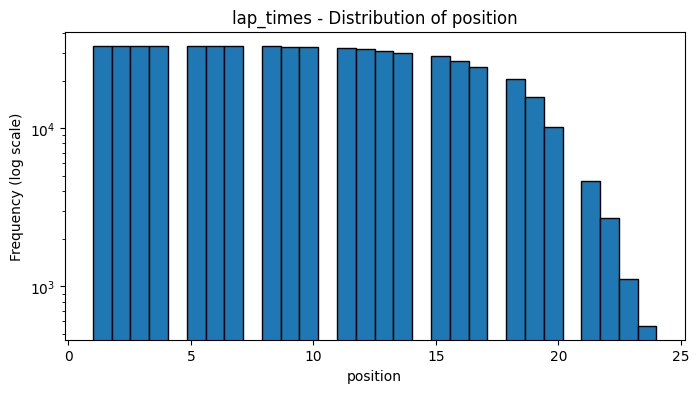

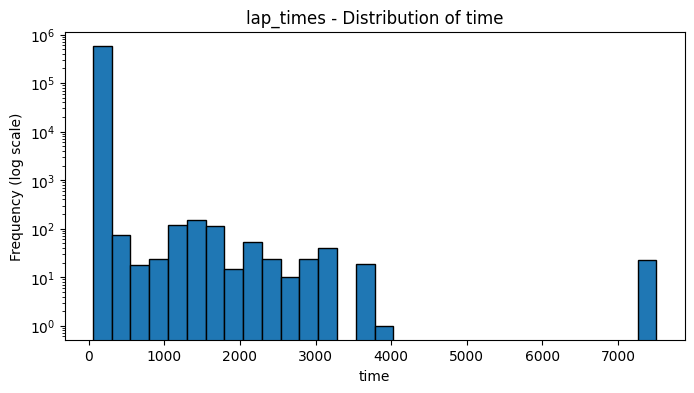

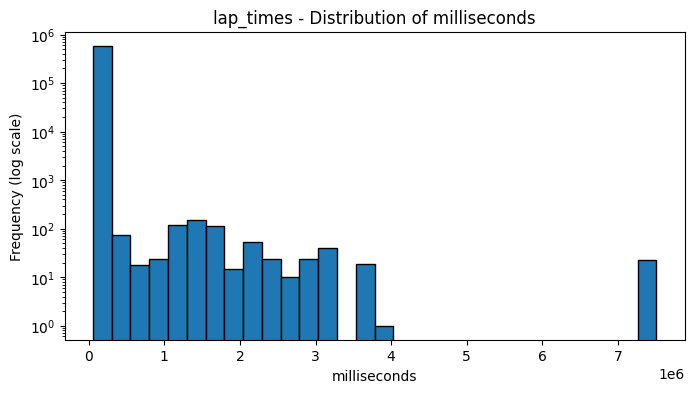

In [ ]:
inspect_df("lap_times", lap_times)

In [ ]:
extreme_laps = (
    lap_times[
        lap_times["milliseconds"] > 30 * 60 * 1000
    ]
    .merge(
        races[
            ["raceId", "year", "round", "name"]
        ],
        on="raceId",
        how="left"
    )
)

display(
    extreme_laps[
        [
            "raceId",
            "year",
            "name",
            "driverId",
            "lap",
            "position",
            "time",
            "milliseconds"
        ]
    ].sort_values(
        ["raceId", "lap", "position"]
    )
)

,raceId,year,name,driverId,lap,position,time,milliseconds
66,78,2005,Canadian Grand Prix,11,22,20,1921.214,1921214
67,87,2005,Brazilian Grand Prix,17,2,18,2022.173,2022173
72,353,2010,Korean Grand Prix,20,4,1,2941.672,2941672
73,353,2010,Korean Grand Prix,17,4,2,2942.501,2942501
75,353,2010,Korean Grand Prix,4,4,3,2942.253,2942253
...,...,...,...,...,...,...,...,...
203,1128,2024,Monaco Grand Prix,817,1,12,2507.607,2507607
204,1128,2024,Monaco Grand Prix,4,1,13,2513.184,2513184
205,1128,2024,Monaco Grand Prix,858,1,14,2516.858,2516858
206,1128,2024,Monaco Grand Prix,822,1,15,2521.748,2521748


raceId = 847: almost every driver has an enormous time on lap 25, around 125 minutes.

raceId = 908: many drivers have enormous times on lap 1 or 2, around 61–63 minutes.

Within each race, the drivers all have very similar huge lap times.

**Decision:** these are red-flag stoppages (the race was suspended and the clock kept running), so the times are real, not errors. We keep them. `lap_times` is not used for any model feature.


### 2.5.9 Driver Standings



driver_standings
--------------------------------------------------

Shape:
(34194, 7)

Columns:
['driverStandingsId', 'raceId', 'driverId', 'points', 'position', 'positionText', 'wins']

Info:
<class 'pandas.core.frame.DataFrame'>
Index: 34194 entries, 0 to 34862
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   driverStandingsId  34194 non-null  int64  
 1   raceId             34194 non-null  int64  
 2   driverId           34194 non-null  int64  
 3   points             34194 non-null  float64
 4   position           34194 non-null  Int64  
 5   positionText       34194 non-null  object 
 6   wins               34194 non-null  int64  
dtypes: Int64(1), float64(1), int64(4), object(1)
memory usage: 2.1+ MB

Dtypes:
driverStandingsId      int64
raceId                 int64
driverId               int64
points               float64
position               Int64
positionText          object
wins           

,driverStandingsId,raceId,driverId,points,position,positionText,wins
count,34194.000,34194.000,34194.000,34194.000,34194.000,34194,34194.000
unique,NaN,NaN,NaN,NaN,<NA>,109,NaN
top,NaN,NaN,NaN,NaN,<NA>,1,NaN
freq,NaN,NaN,NaN,NaN,<NA>,1114,NaN
mean,43082.194,580.354,311.764,14.926,12.402,NaN,0.282
std,22126.556,293.638,274.492,39.323,6.099,NaN,1.042
min,1.000,1.000,1.000,0.000,1.000,NaN,0.000
25%,19667.250,348.000,84.000,0.000,7.000,NaN,0.000
50%,50263.500,596.000,221.000,1.000,13.000,NaN,0.000
75%,62221.750,804.000,512.000,10.000,17.000,NaN,0.000



Full duplicate rows:
0

First 5 rows:


,driverStandingsId,raceId,driverId,points,position,positionText,wins
0,1,18,1,10.000,1,1,1
1,2,18,2,8.000,2,2,0
2,3,18,3,6.000,3,3,0
3,4,18,4,5.000,4,4,0
4,5,18,5,4.000,5,5,0



Missing values (actual NaN):
driverStandingsId    0
raceId               0
driverId             0
points               0
position             0
positionText         0
wins                 0
dtype: int64

Placeholder missing values:
No placeholder missing values found.


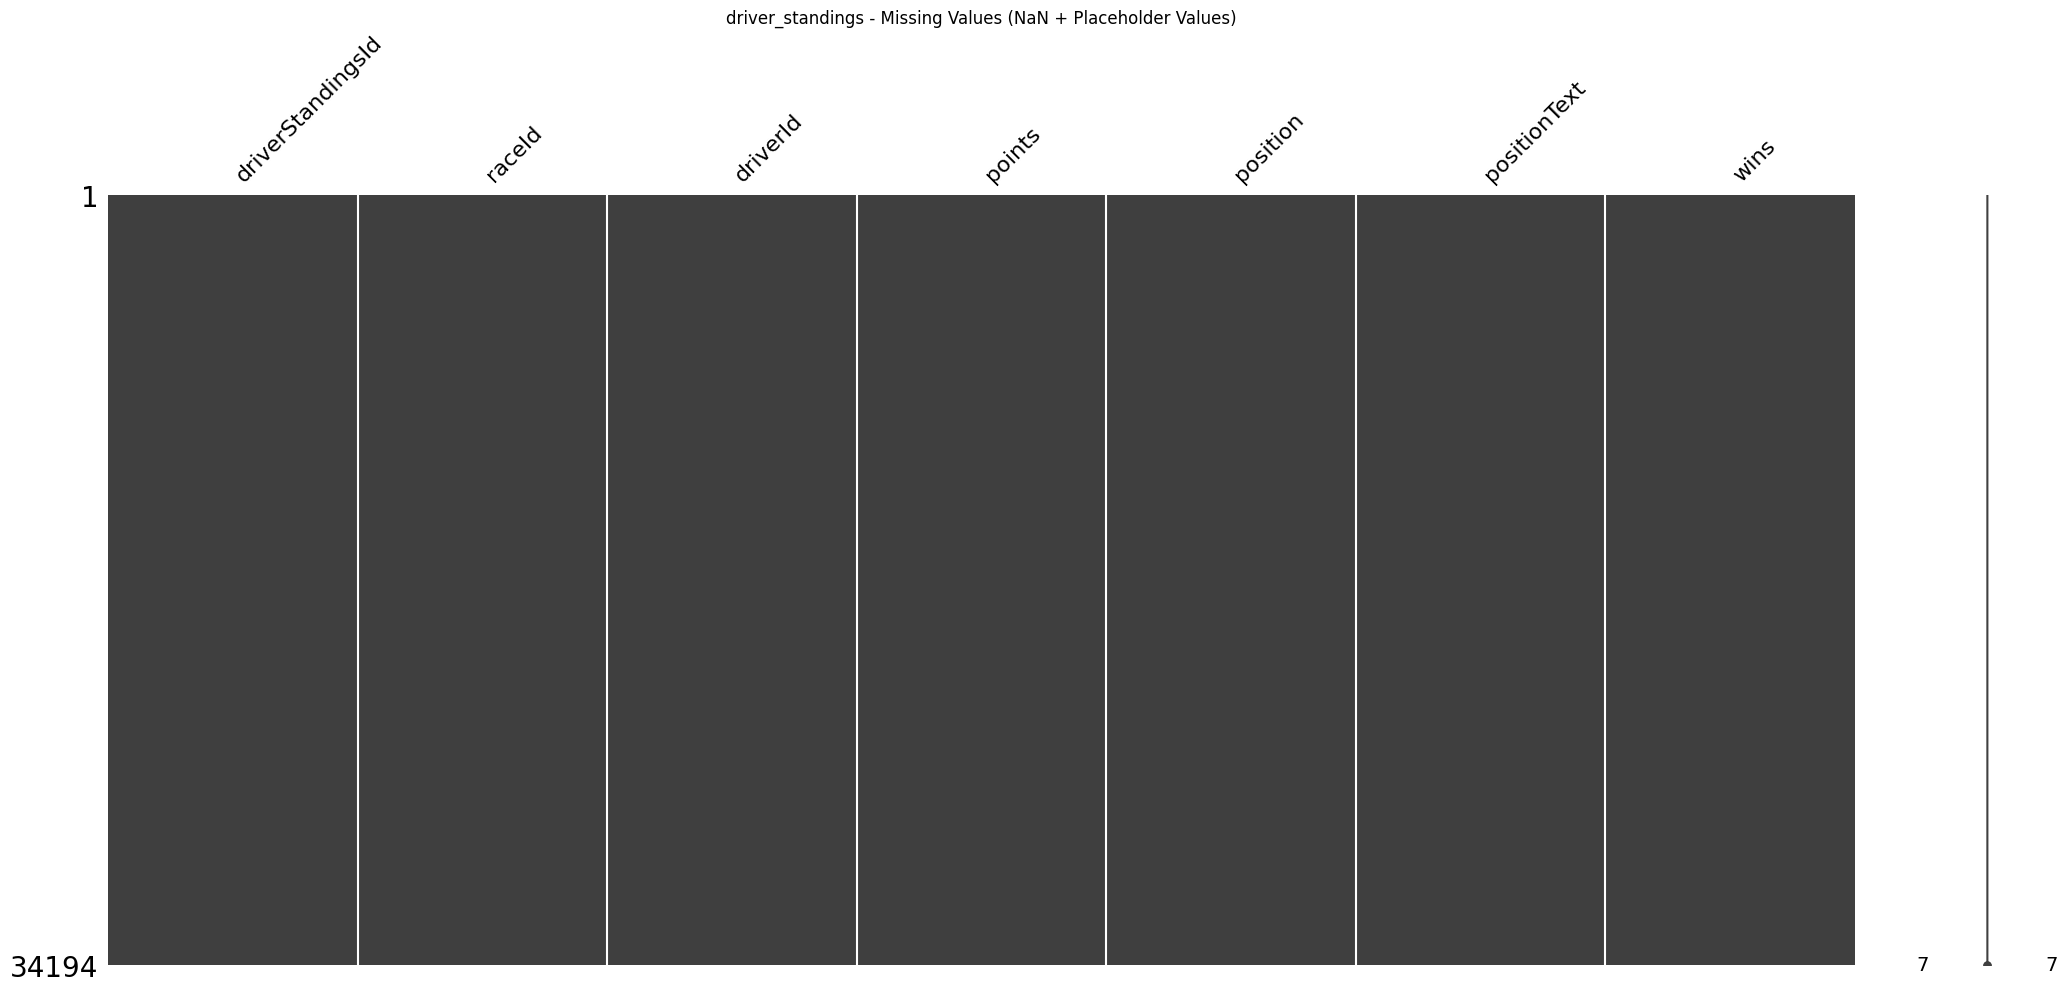


Numeric Distributions:


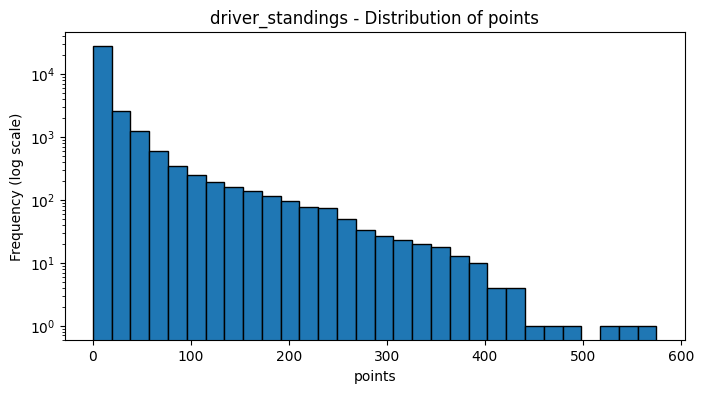

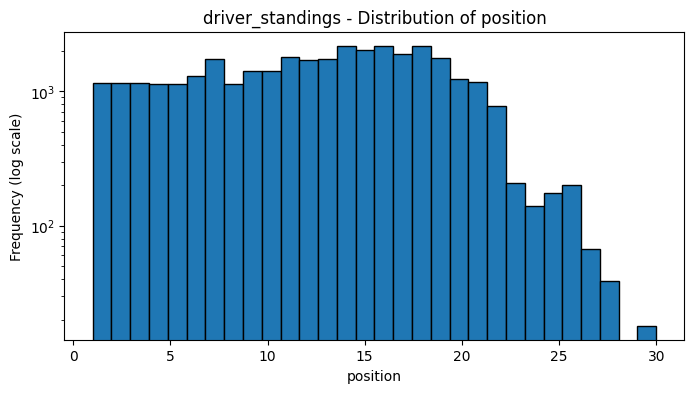

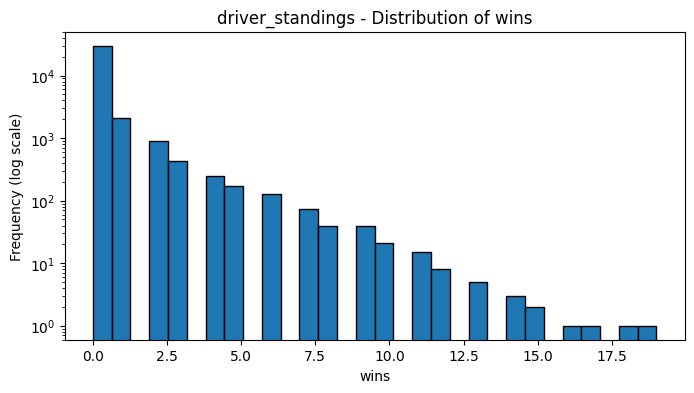

In [ ]:
inspect_df("driver_standings", driver_standings)


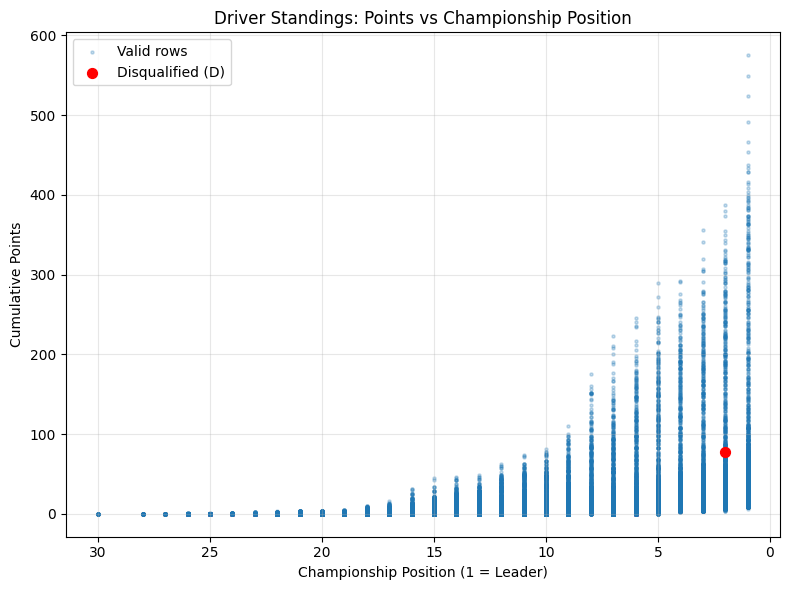

In [ ]:
special = driver_standings["positionText"].astype(str).eq("D")

plt.figure(figsize=(8, 6))

plt.scatter(
    driver_standings.loc[~special, "position"],
    driver_standings.loc[~special, "points"],
    s=5,
    alpha=0.25,
    label="Valid rows"
)

plt.scatter(
    driver_standings.loc[special, "position"],
    driver_standings.loc[special, "points"],
    color="red",
    s=50,
    label="Disqualified (D)",
    zorder=3
)

plt.gca().invert_xaxis()
plt.title("Driver Standings: Points vs Championship Position")
plt.xlabel("Championship Position (1 = Leader)")
plt.ylabel("Cumulative Points")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**points** → cumulative championship points after that race.
**position** → championship rank after that race.
**positionText** → same rank as text, sometimes useful for special cases.
**wins** → cumulative number of wins in that season after that race.

In [ ]:
driver_standings[
    driver_standings["positionText"].astype(str)
    != driver_standings["position"].astype(str)
]


,driverStandingsId,raceId,driverId,points,position,positionText,wins
9,10,19,2,11.000,2,3,0
11,12,19,4,6.000,6,7,0
18,19,19,17,2.000,10,11,0
20,21,19,18,0.000,12,13,0
21,22,19,12,0.000,12,14,0
...,...,...,...,...,...,...,...
34838,73246,1143,859,4.000,20,21,0
34851,73259,1144,817,12.000,16,17,0
34858,73266,1144,858,0.000,22,23,0
34861,73269,1144,859,4.000,20,21,0


The only non-numeric positionText value is 'D', a rare case that applied to a single driver (Michael Schumacher, disqualified from the 1997 championship). This is not a data inconsistency within that row, since 'D' carries a real meaning.

### 2.5.10 Constructor Standings



constructor_standings 
--------------------------------------------------

Shape:
(13365, 7)

Columns:
['constructorStandingsId', 'raceId', 'constructorId', 'points', 'position', 'positionText', 'wins']

Info:
<class 'pandas.core.frame.DataFrame'>
Index: 13365 entries, 0 to 13390
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   constructorStandingsId  13365 non-null  int64  
 1   raceId                  13365 non-null  int64  
 2   constructorId           13365 non-null  int64  
 3   points                  13365 non-null  float64
 4   position                13365 non-null  Int64  
 5   positionText            13365 non-null  object 
 6   wins                    13365 non-null  int64  
dtypes: Int64(1), float64(1), int64(4), object(1)
memory usage: 848.4+ KB

Dtypes:
constructorStandingsId      int64
raceId                      int64
constructorId               int64
points                  

,constructorStandingsId,raceId,constructorId,points,position,positionText,wins
count,13365.000,13365.000,13365.000,13365.000,13365.000,13365,13365.000
unique,NaN,NaN,NaN,NaN,<NA>,23,NaN
top,NaN,NaN,NaN,NaN,<NA>,1,NaN
freq,NaN,NaN,NaN,NaN,<NA>,1058,NaN
mean,16979.048,534.968,49.518,37.243,6.449,NaN,0.698
std,8876.761,307.849,61.201,84.415,3.446,NaN,1.881
min,1.000,1.000,1.000,0.000,1.000,NaN,0.000
25%,8877.000,302.000,6.000,0.000,4.000,NaN,0.000
50%,20647.000,507.000,25.000,7.000,6.000,NaN,0.000
75%,25054.000,737.000,58.000,33.000,9.000,NaN,0.000



Full duplicate rows:
0

First 5 rows:


,constructorStandingsId,raceId,constructorId,points,position,positionText,wins
0,1,18,1,14.000,1,1,1
1,2,18,2,8.000,3,3,0
2,3,18,3,9.000,2,2,0
3,4,18,4,5.000,4,4,0
4,5,18,5,2.000,5,5,0



Missing values (actual NaN):
constructorStandingsId    0
raceId                    0
constructorId             0
points                    0
position                  0
positionText              0
wins                      0
dtype: int64

Placeholder missing values:
No placeholder missing values found.


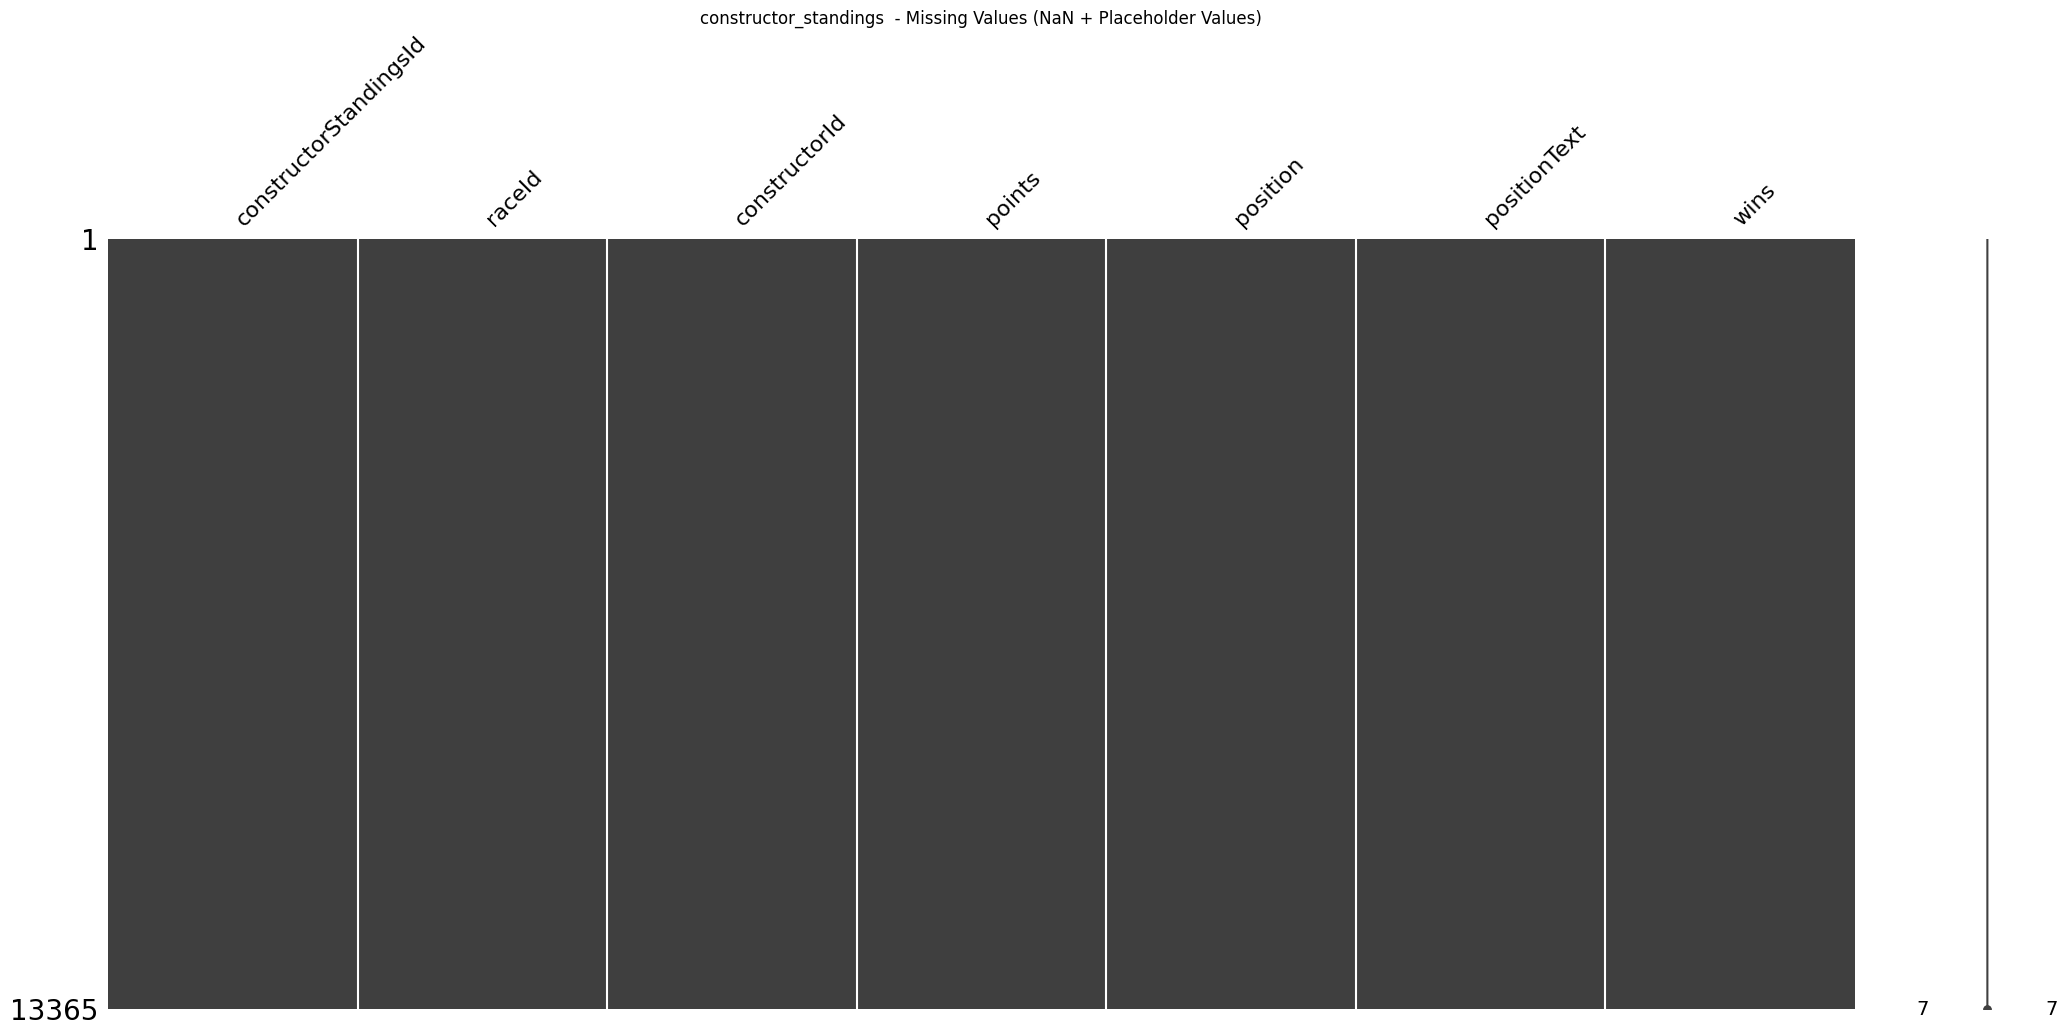


Numeric Distributions:


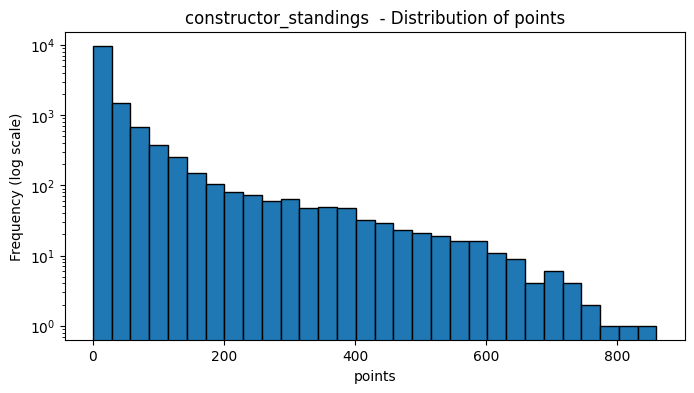

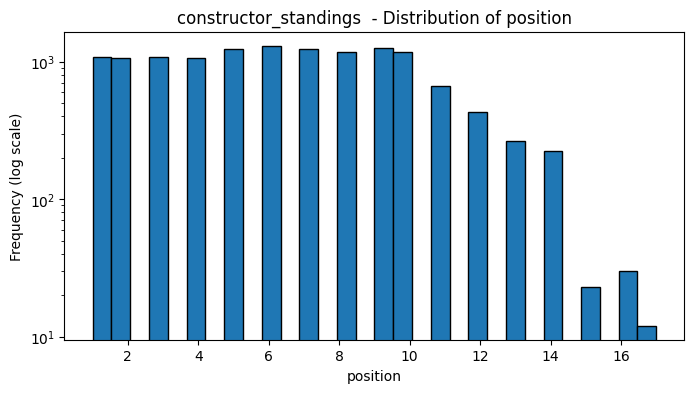

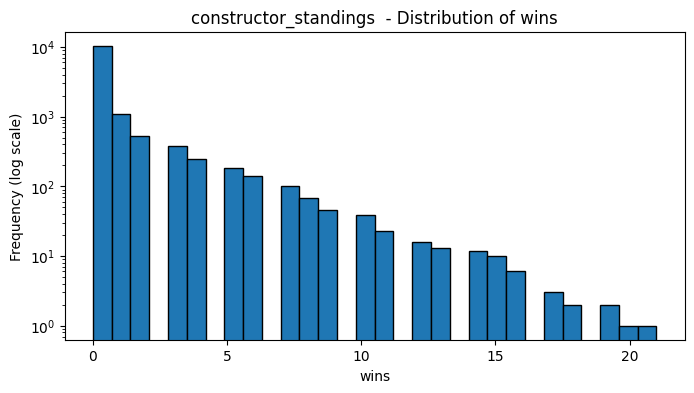

In [ ]:
inspect_df("constructor_standings ", constructor_standings )

In [ ]:
constructor_standings[
    constructor_standings["positionText"].astype(str)
    != constructor_standings["position"].astype(str)
]

,constructorStandingsId,raceId,constructorId,points,position,positionText,wins
10,11,19,5,2.000,7,8,0
15,16,19,10,0.000,9,10,0
16,17,19,8,0.000,9,11,0
26,27,20,10,0.000,9,10,0
27,28,20,8,0.000,9,11,0
...,...,...,...,...,...,...,...
13193,28782,1125,214,0.000,8,9,0
13196,28778,1125,15,0.000,8,10,0
13206,28788,1126,15,0.000,9,10,0
13216,28798,1127,15,0.000,9,10,0


The only non-numeric positionText value in constructor_standings is 'E' (excluded), a special case that applies to McLaren's 2007 season after the Spygate decision, so it is a meaningful value rather than a data inconsistency. The rows are kept as they are

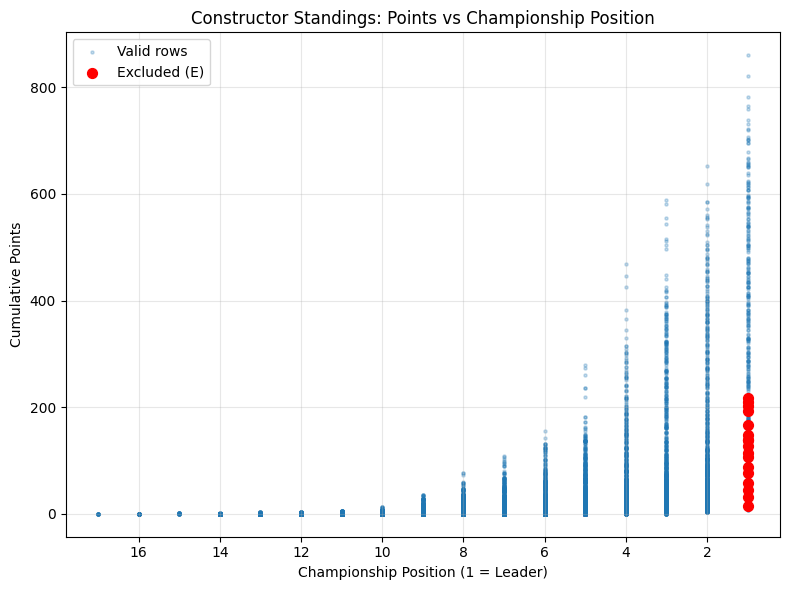

In [ ]:
special = constructor_standings["positionText"].astype(str).eq("E")

plt.figure(figsize=(8, 6))

plt.scatter(
    constructor_standings.loc[~special, "position"],
    constructor_standings.loc[~special, "points"],
    s=5,
    alpha=0.25,
    label="Valid rows"
)

plt.scatter(
    constructor_standings.loc[special, "position"],
    constructor_standings.loc[special, "points"],
    color="red",
    s=50,
    label="Excluded (E)",
    zorder=3
)

plt.gca().invert_xaxis()
plt.title("Constructor Standings: Points vs Championship Position")
plt.xlabel("Championship Position (1 = Leader)")
plt.ylabel("Cumulative Points")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Each panel plots cumulative championship points against championship position, one dot per post-race standings snapshot. Points fall as position worsens, and the red dots (the D driver row and McLaren's E rows) break that pattern because their positions are placeholders, not real ranks.

### 2.5.11 Seasons



seasons
--------------------------------------------------

Shape:
(75, 2)

Columns:
['year', 'url']

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 75 entries, 0 to 74
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   year    75 non-null     int64 
 1   url     75 non-null     object
dtypes: int64(1), object(1)
memory usage: 1.3+ KB

Dtypes:
year     int64
url     object
dtype: object

Descriptive Statistics:


,year,url
count,75.000,75
unique,NaN,75
top,NaN,http://en.wikipedia.org/wiki/2009_Formula_One_season
freq,NaN,1
mean,1987.000,NaN
std,21.794,NaN
min,1950.000,NaN
25%,1968.500,NaN
50%,1987.000,NaN
75%,2005.500,NaN



Full duplicate rows:
0

First 5 rows:


,year,url
0,2009,http://en.wikipedia.org/wiki/2009_Formula_One_season
1,2008,http://en.wikipedia.org/wiki/2008_Formula_One_season
2,2007,http://en.wikipedia.org/wiki/2007_Formula_One_season
3,2006,http://en.wikipedia.org/wiki/2006_Formula_One_season
4,2005,http://en.wikipedia.org/wiki/2005_Formula_One_season



Missing values (actual NaN):
year    0
url     0
dtype: int64

Placeholder missing values:
No placeholder missing values found.


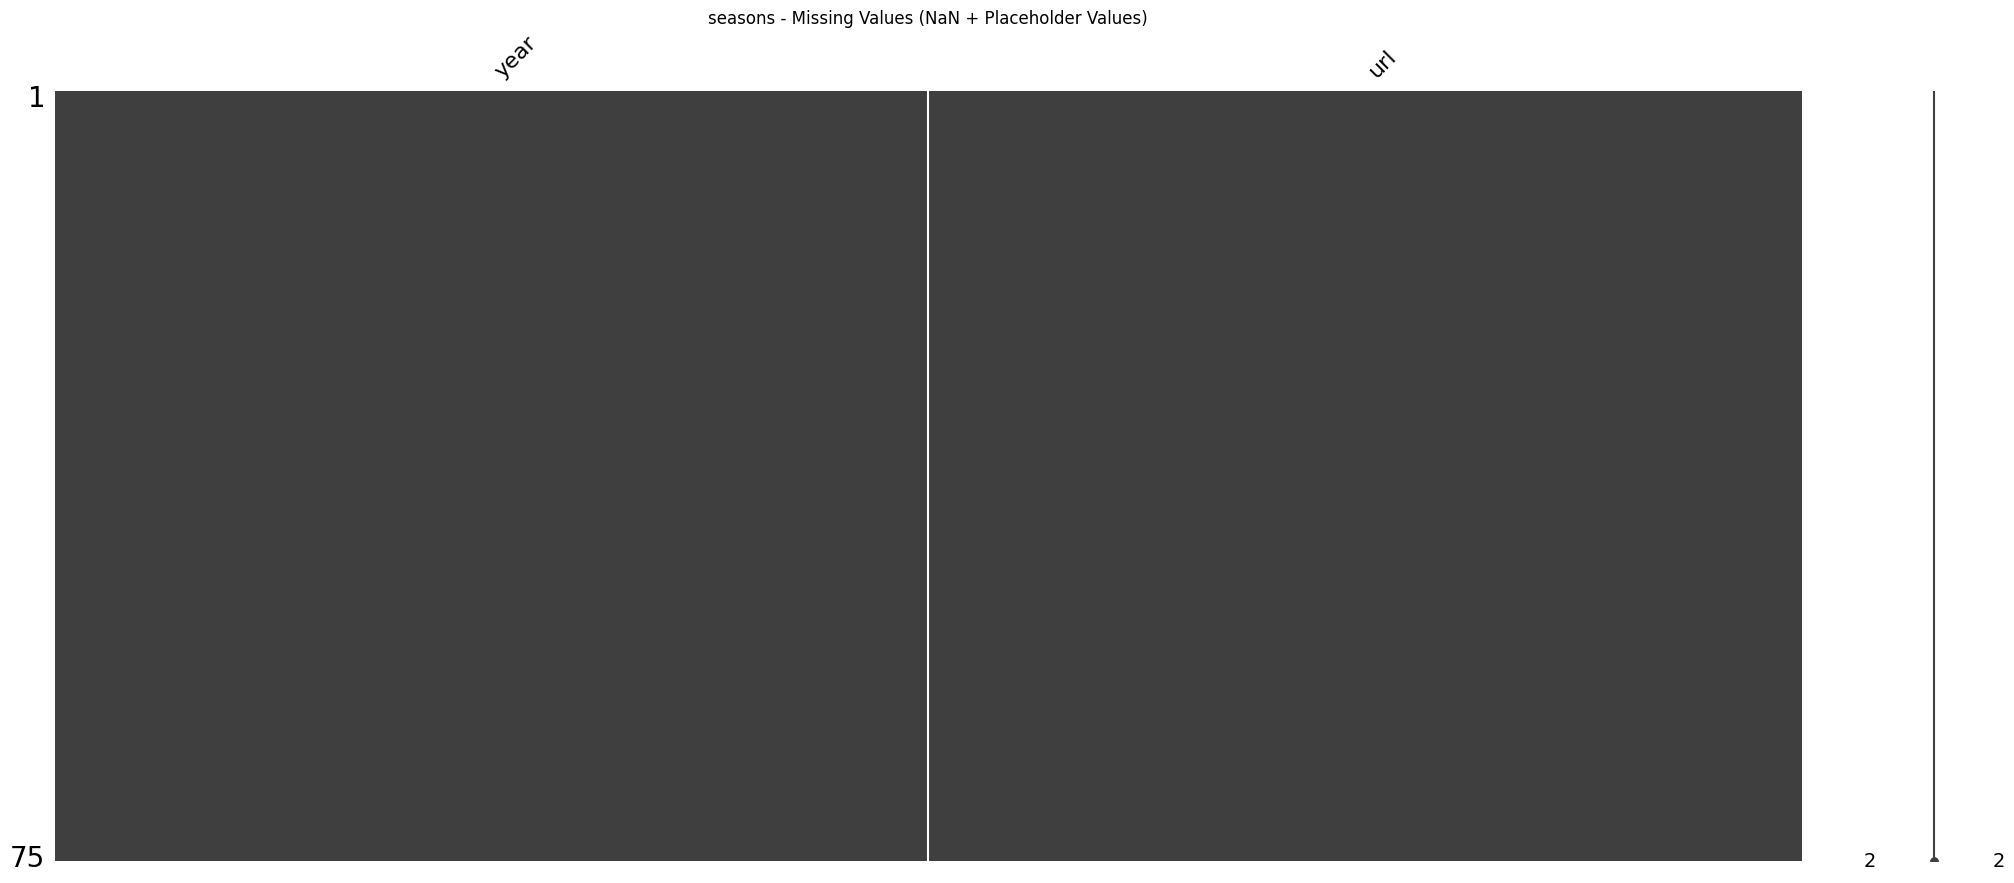

In [ ]:
inspect_df("seasons", seasons)

### 2.5.12 Sprint Results



sprint_results
--------------------------------------------------

Shape:
(360, 16)

Columns:
['resultId', 'raceId', 'driverId', 'constructorId', 'number', 'grid', 'position', 'positionText', 'positionOrder', 'points', 'laps', 'time', 'milliseconds', 'fastestLap', 'fastestLapTime', 'statusId']

Info:
<class 'pandas.core.frame.DataFrame'>
Index: 360 entries, 0 to 359
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   resultId        360 non-null    int64  
 1   raceId          360 non-null    int64  
 2   driverId        360 non-null    int64  
 3   constructorId   360 non-null    int64  
 4   number          360 non-null    int64  
 5   grid            360 non-null    int64  
 6   position        345 non-null    object 
 7   positionText    360 non-null    object 
 8   positionOrder   360 non-null    int64  
 9   points          360 non-null    int64  
 10  laps            360 non-null    int64  
 11  time   

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId
count,360.000,360.000,360.000,360.000,360.000,360.000,345,360,360.000,360.000,360.000,340.000,340,351,351.000,360.000
unique,NaN,NaN,NaN,NaN,NaN,NaN,20,23,NaN,NaN,NaN,NaN,340,23,NaN,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,1,1,NaN,NaN,NaN,NaN,1697381,4,NaN,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,18,18,NaN,NaN,NaN,NaN,1,42,NaN,NaN
mean,180.500,1106.944,734.658,94.367,28.178,9.922,NaN,NaN,10.500,1.550,19.583,1806.263,NaN,NaN,86.570,3.336
std,104.067,25.636,276.412,89.166,23.796,5.842,NaN,NaN,5.774,2.496,4.753,154.999,NaN,NaN,14.409,13.448
min,1.000,1061.000,1.000,1.000,1.000,0.000,NaN,NaN,1.000,0.000,0.000,1498.433,NaN,NaN,68.321,1.000
25%,90.750,1084.000,822.000,6.000,11.000,5.000,NaN,NaN,5.750,0.000,18.000,1649.334,NaN,NaN,74.144,1.000
50%,180.500,1112.500,840.000,84.000,22.000,10.000,NaN,NaN,10.500,0.000,19.000,1842.414,NaN,NaN,84.892,1.000
75%,270.250,1126.000,848.000,210.000,44.000,15.000,NaN,NaN,15.250,3.000,24.000,1909.140,NaN,NaN,98.791,1.000



Full duplicate rows:
0

First 5 rows:


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId
0,1,1061,830,9,33,2,1,1,1,3,17,1538.426,1538426,14,90.013,1
1,2,1061,1,131,44,1,2,2,2,2,17,1539.856,1539856,17,89.937,1
2,3,1061,822,131,77,3,3,3,3,1,17,1545.928,1545928,17,89.958,1
3,4,1061,844,6,16,4,4,4,4,0,17,1549.704,1549704,16,90.163,1
4,5,1061,846,1,4,6,5,5,5,0,17,1562.537,1562537,16,90.566,1



Missing values (actual NaN):
resultId           0
raceId             0
driverId           0
constructorId      0
number             0
grid               0
position          15
positionText       0
positionOrder      0
points             0
laps               0
time              20
milliseconds      20
fastestLap         9
fastestLapTime     9
statusId           0
dtype: int64

Placeholder missing values:
No placeholder missing values found.


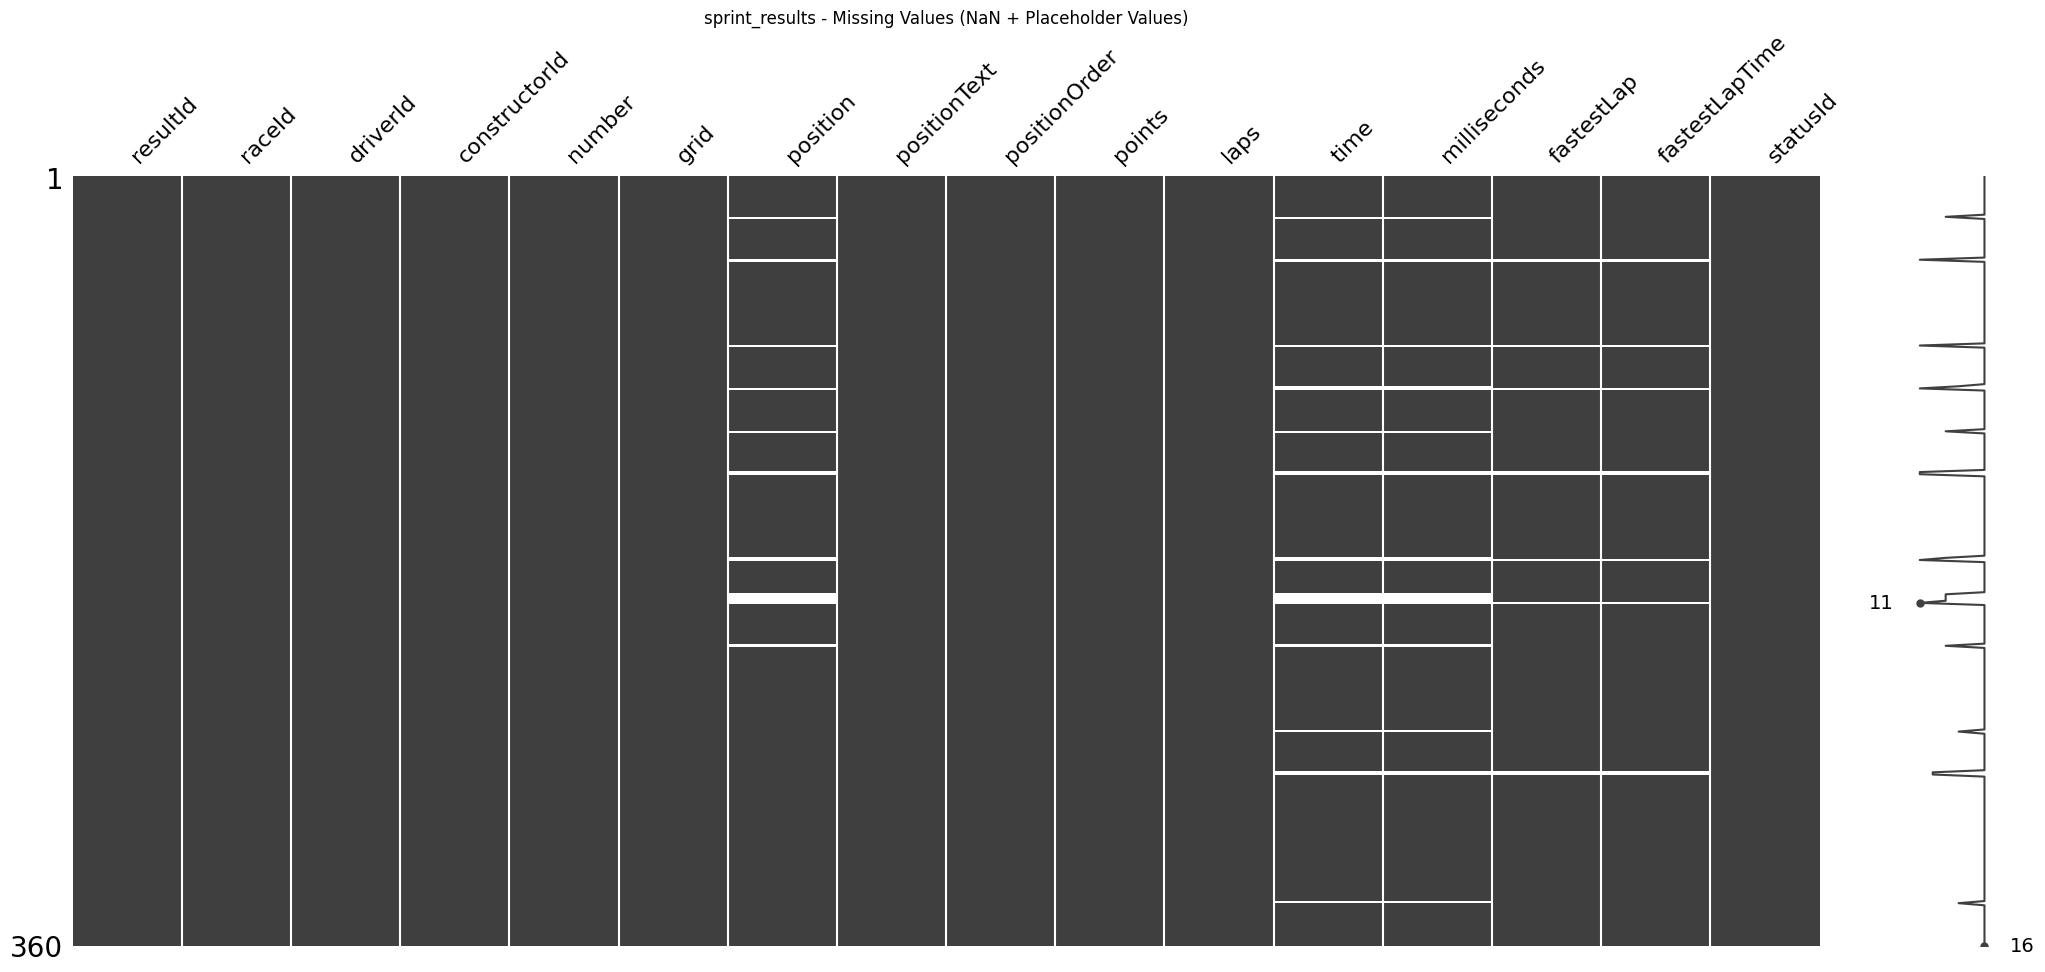


Numeric Distributions:


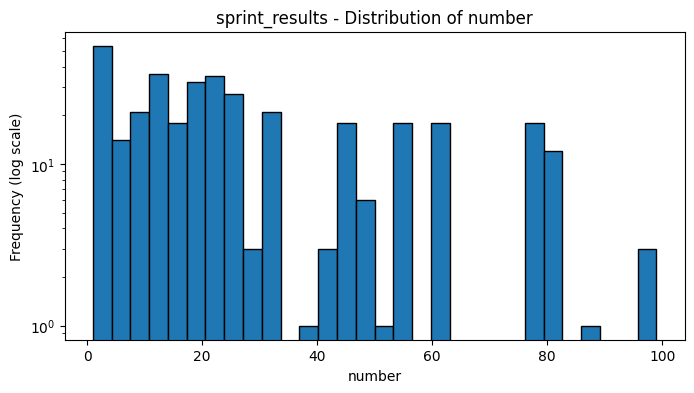

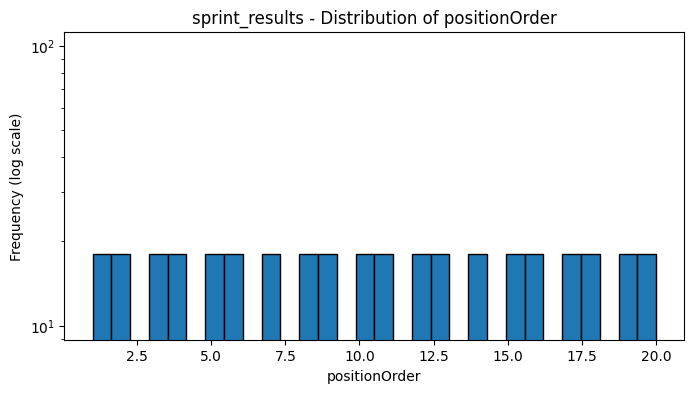

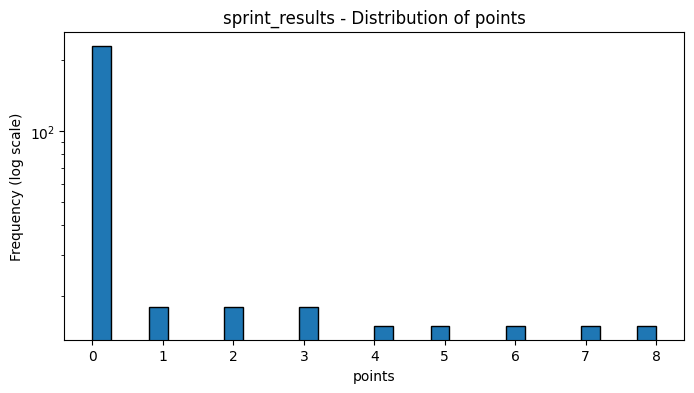

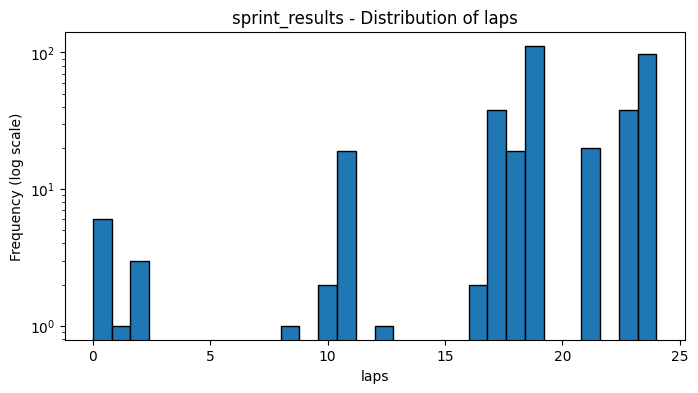

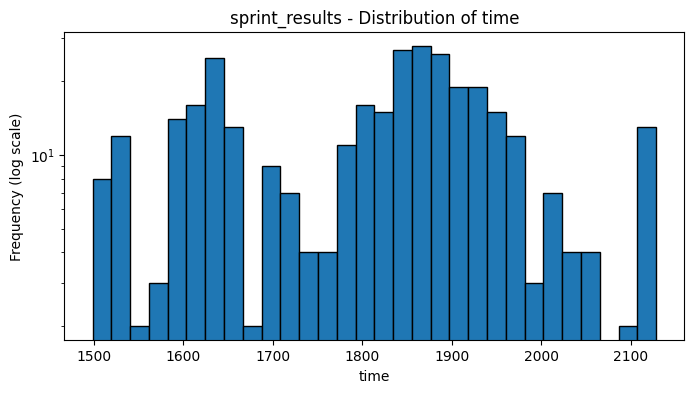

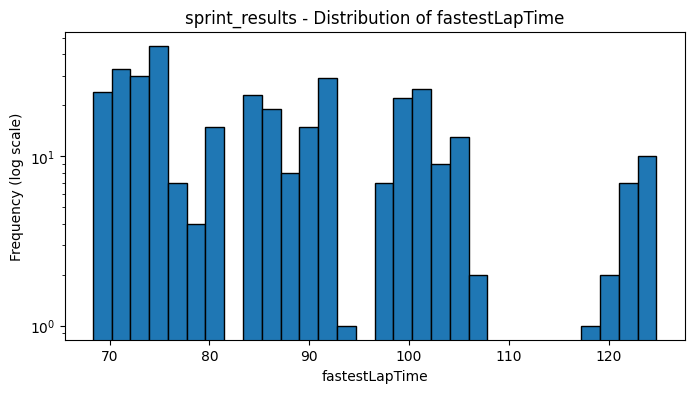

In [ ]:
inspect_df("sprint_results", sprint_results)

In [ ]:
sprint_years = (
    sprint_results
    .merge(
        races[["raceId", "year"]],
        on="raceId",
        how="left"
    )
)
print("First sprint season:", sprint_years["year"].min())
print("Last sprint season:", sprint_years["year"].max())
print("Number of sprint races:", sprint_years["raceId"].nunique())

First sprint season: 2021
Last sprint season: 2024
Number of sprint races: 18


Sprint results are safely excluded from the baseline because they exist only from 2021 onward and would be missing for almost the entire historical dataset. Their effect on the Sunday race is also largely captured by grid in 2021–2022, while their role changes from 2023 onward.

In [ ]:
# Get 2021-2022 races
races_21_22 = races[
    races["year"].isin([2021, 2022])
][["raceId", "year", "name"]]

# Keep only races that actually had a Sprint
sprint_race_ids = sprint_results["raceId"].unique()

sprint_races_21_22 = races_21_22[
    races_21_22["raceId"].isin(sprint_race_ids)
]

sprint_races_21_22

,raceId,year,name
1046,1061,2021,British Grand Prix
1050,1065,2021,Italian Grand Prix
1055,1071,2021,São Paulo Grand Prix
1060,1077,2022,Emilia Romagna Grand Prix
1067,1084,2022,Austrian Grand Prix
1077,1095,2022,São Paulo Grand Prix


### 2.5.13 Pit Stops


In [ ]:
pit_stops.head()

,raceId,driverId,stop,lap,time,duration,milliseconds
0,841,153,1,1,17:05:23,26.898,26898
1,841,30,1,1,17:05:52,25.021,25021
2,841,17,1,11,17:20:48,23.426,23426
3,841,4,1,12,17:22:34,23.251,23251
4,841,13,1,13,17:24:10,23.842,23842


stop = the pit-stop sequence number for that driver in that race.- 1 = first pit stop
- 2 = second pit stop
- 3 = third pit stop
- and so on

lap = the race lap on which that pit stop happened

milliseconds = the duration of that pit stop, in milliseconds


pit_stops
--------------------------------------------------

Shape:
(11371, 7)

Columns:
['raceId', 'driverId', 'stop', 'lap', 'time', 'duration', 'milliseconds']

Info:
<class 'pandas.core.frame.DataFrame'>
Index: 11371 entries, 0 to 11370
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   raceId        11371 non-null  int64  
 1   driverId      11371 non-null  int64  
 2   stop          11371 non-null  int64  
 3   lap           11371 non-null  int64  
 4   time          11371 non-null  object 
 5   duration      11371 non-null  float64
 6   milliseconds  11371 non-null  int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 710.7+ KB

Dtypes:
raceId            int64
driverId          int64
stop              int64
lap               int64
time             object
duration        float64
milliseconds      int64
dtype: object

Descriptive Statistics:


,raceId,driverId,stop,lap,time,duration,milliseconds
count,11371.000,11371.000,11371.000,11371.000,11371,11371.000,11371.000
unique,NaN,NaN,NaN,NaN,8227,NaN,NaN
top,NaN,NaN,NaN,NaN,15:06:11,NaN,NaN
freq,NaN,NaN,NaN,NaN,6,NaN,NaN
mean,981.195,549.735,1.788,25.387,NaN,85.230,85230.496
std,92.327,383.735,1.521,14.831,NaN,310.427,310427.261
min,841.000,1.000,1.000,1.000,NaN,12.897,12897.000
25%,895.000,20.000,1.000,13.000,NaN,21.938,21937.500
50%,971.000,817.000,2.000,25.000,NaN,23.606,23606.000
75%,1065.000,835.000,2.000,36.000,NaN,26.544,26544.000



Full duplicate rows:
0

First 5 rows:


,raceId,driverId,stop,lap,time,duration,milliseconds
0,841,153,1,1,17:05:23,26.898,26898
1,841,30,1,1,17:05:52,25.021,25021
2,841,17,1,11,17:20:48,23.426,23426
3,841,4,1,12,17:22:34,23.251,23251
4,841,13,1,13,17:24:10,23.842,23842



Missing values (actual NaN):
raceId          0
driverId        0
stop            0
lap             0
time            0
duration        0
milliseconds    0
dtype: int64

Placeholder missing values:
No placeholder missing values found.


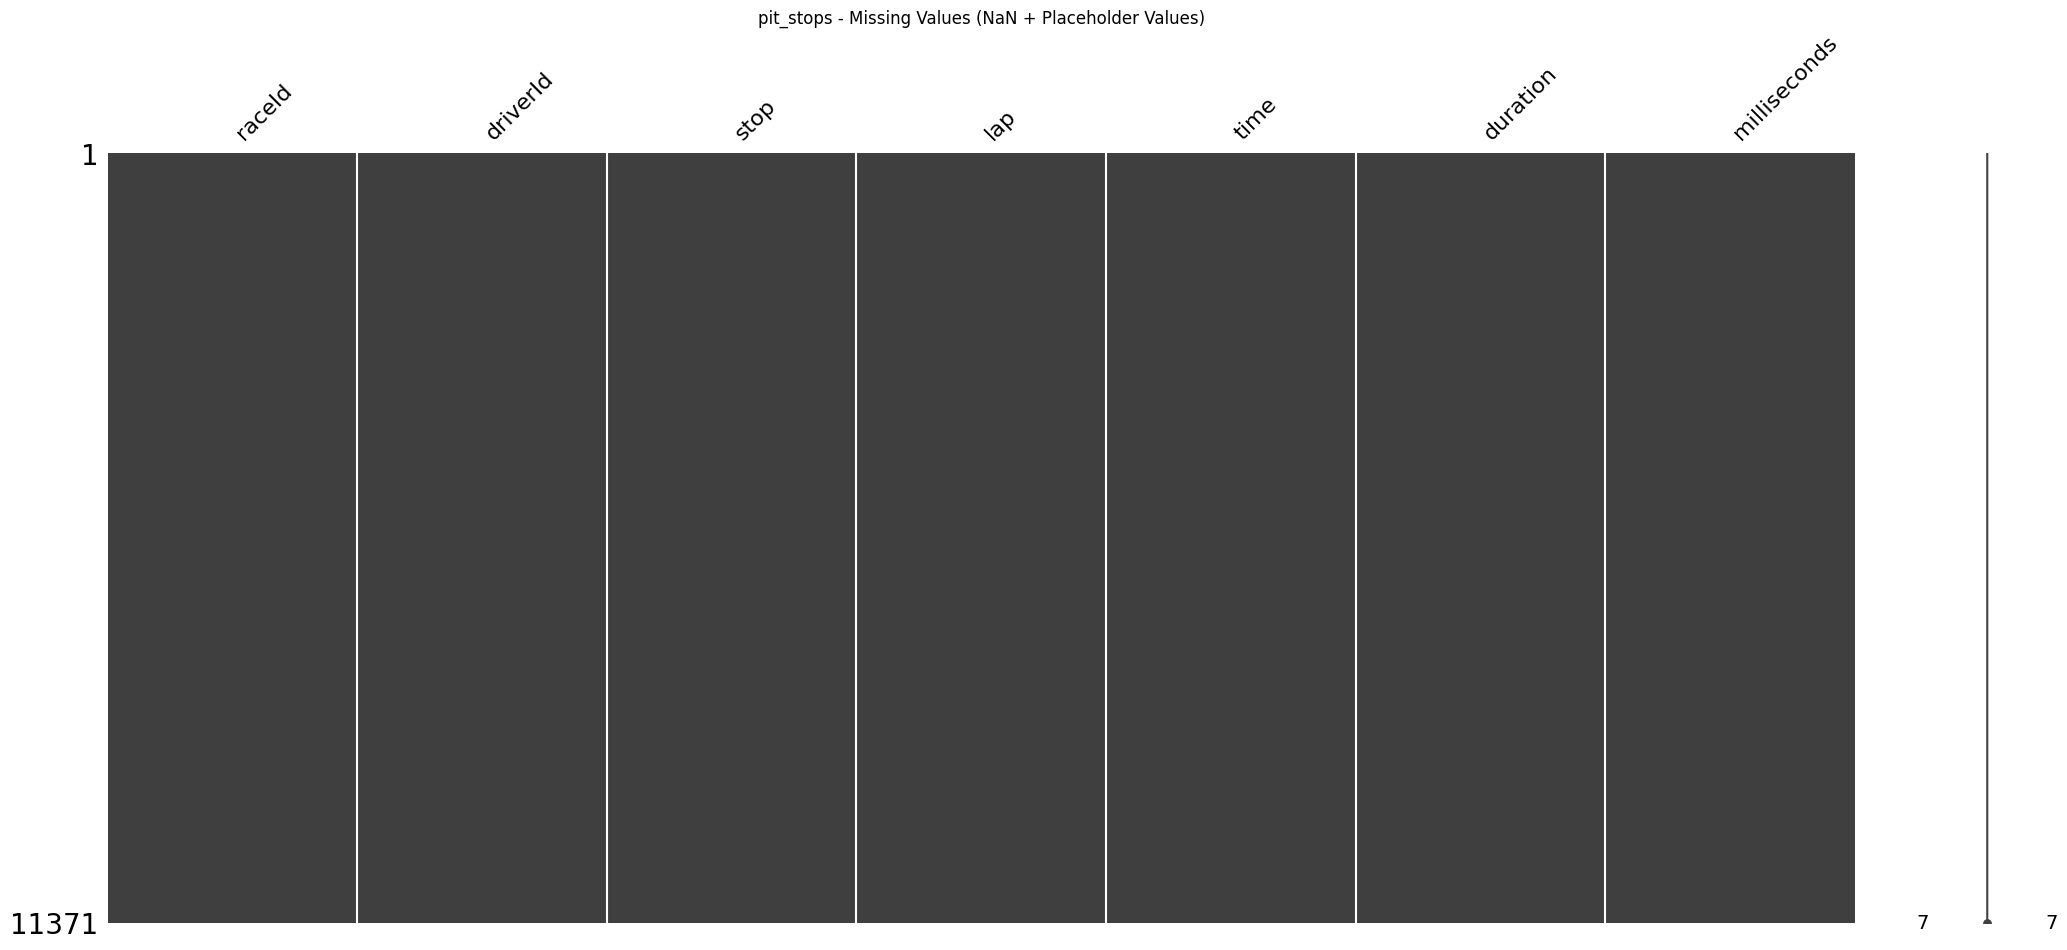


Numeric Distributions:


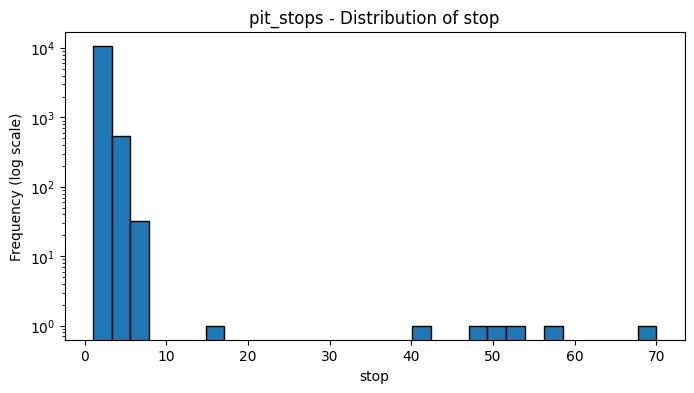

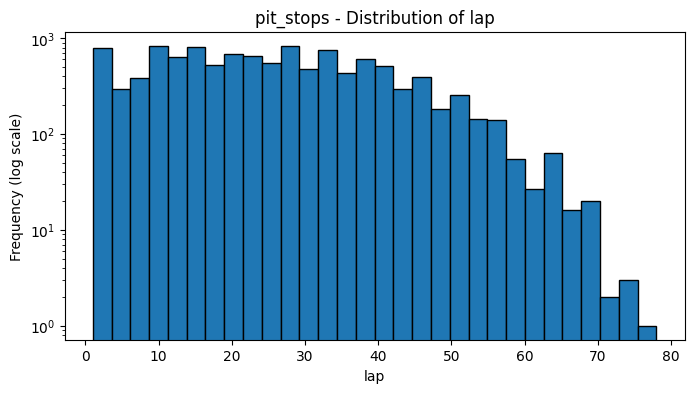

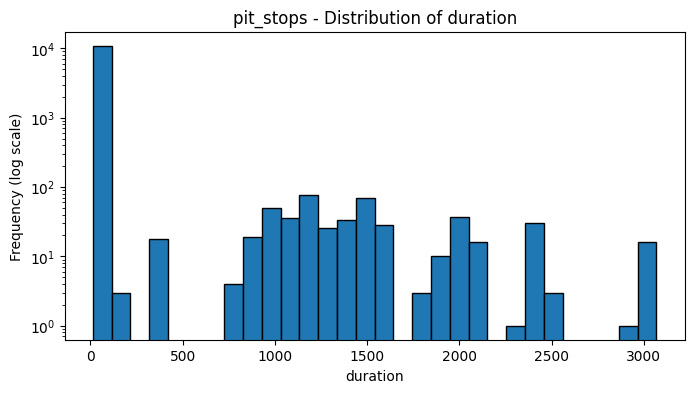

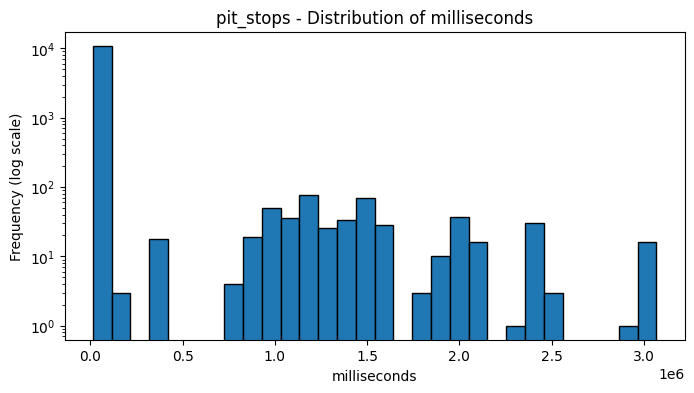

In [ ]:
inspect_df("pit_stops", pit_stops)

In [ ]:
pit_stops["time"] = pd.to_datetime(
    pit_stops["time"],
    format="%H:%M:%S",
    errors="coerce"
).dt.time

In [ ]:
# duration (seconds, converted in 2.2) and milliseconds hold the same value: check on every row, then drop duration
same_value = (pit_stops["duration"] - pit_stops["milliseconds"] / 1000).abs() < 0.0015
print("Rows where duration == milliseconds / 1000:", int(same_value.sum()), "of", len(pit_stops))
assert same_value.all()

pit_stops = pit_stops.drop(columns=["duration"])

Rows where duration == milliseconds / 1000: 11371 of 11371


`duration` is dropped because it is an exact copy of `milliseconds` (the check above matches every row), not because of missing values.

In [ ]:
suspected_swaps = pit_stops[
    pit_stops["stop"] > pit_stops["lap"]
].copy()

display(
    suspected_swaps.sort_values(
        ["raceId", "driverId", "lap", "stop"]
    )
)

print("Suspicious rows:", len(suspected_swaps))
print("Affected races:", suspected_swaps["raceId"].nunique())

,raceId,driverId,stop,lap,time,milliseconds
10854,1128,1,51,2,16:52:10,24232
10851,1128,822,15,2,16:04:57,24239
10855,1128,830,52,2,16:53:26,23813
10852,1128,840,42,2,16:41:05,24132
10853,1128,840,48,3,16:49:27,28211
10857,1128,855,70,2,17:19:04,24367
10856,1128,858,57,2,17:01:43,24384


Suspicious rows: 7
Affected races: 1


This is anamoly stop and lap got swapped in raceid=1128

In [ ]:
swap_mask = (
    (pit_stops["raceId"] == 1128) &
    (pit_stops["stop"] > pit_stops["lap"])
)

pit_stops.loc[
    swap_mask,
    ["stop", "lap"]
] = (
    pit_stops.loc[
        swap_mask,
        ["lap", "stop"]
    ].to_numpy()
)


pit_stops
--------------------------------------------------

Shape:
(11371, 6)

Columns:
['raceId', 'driverId', 'stop', 'lap', 'time', 'milliseconds']

Info:
<class 'pandas.core.frame.DataFrame'>
Index: 11371 entries, 0 to 11370
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   raceId        11371 non-null  int64 
 1   driverId      11371 non-null  int64 
 2   stop          11371 non-null  int64 
 3   lap           11371 non-null  int64 
 4   time          11371 non-null  object
 5   milliseconds  11371 non-null  int64 
dtypes: int64(5), object(1)
memory usage: 621.9+ KB

Dtypes:
raceId           int64
driverId         int64
stop             int64
lap              int64
time            object
milliseconds     int64
dtype: object

Descriptive Statistics:


,raceId,driverId,stop,lap,time,milliseconds
count,11371.000,11371.000,11371.000,11371.000,11371,11371.000
unique,NaN,NaN,NaN,NaN,8227,NaN
top,NaN,NaN,NaN,NaN,15:06:11,NaN
freq,NaN,NaN,NaN,NaN,6,NaN
mean,981.195,549.735,1.760,25.416,NaN,85230.496
std,92.327,383.735,0.926,14.836,NaN,310427.261
min,841.000,1.000,1.000,1.000,NaN,12897.000
25%,895.000,20.000,1.000,13.000,NaN,21937.500
50%,971.000,817.000,2.000,25.000,NaN,23606.000
75%,1065.000,835.000,2.000,36.000,NaN,26544.000



Full duplicate rows:
0

First 5 rows:


,raceId,driverId,stop,lap,time,milliseconds
0,841,153,1,1,17:05:23,26898
1,841,30,1,1,17:05:52,25021
2,841,17,1,11,17:20:48,23426
3,841,4,1,12,17:22:34,23251
4,841,13,1,13,17:24:10,23842



Missing values (actual NaN):
raceId          0
driverId        0
stop            0
lap             0
time            0
milliseconds    0
dtype: int64

Placeholder missing values:
No placeholder missing values found.


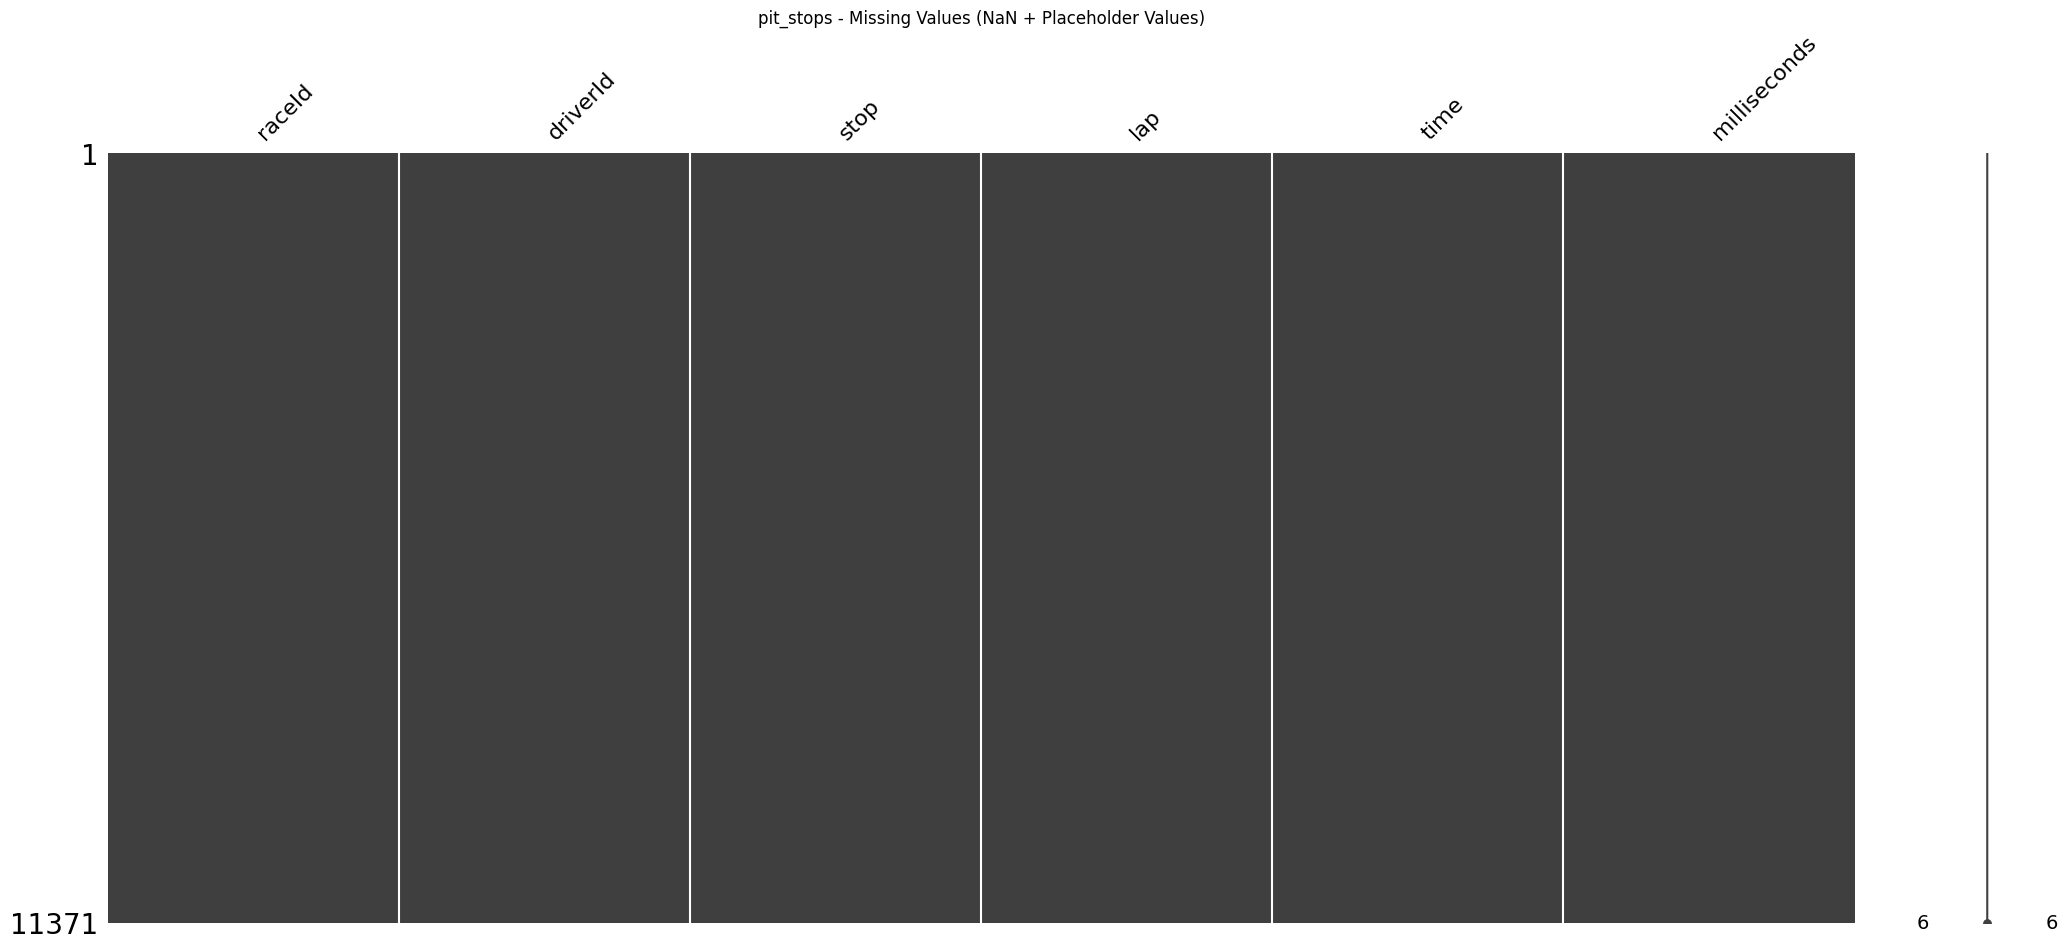


Numeric Distributions:


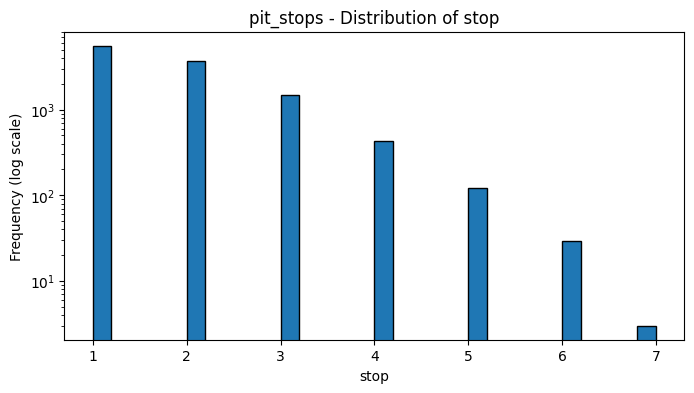

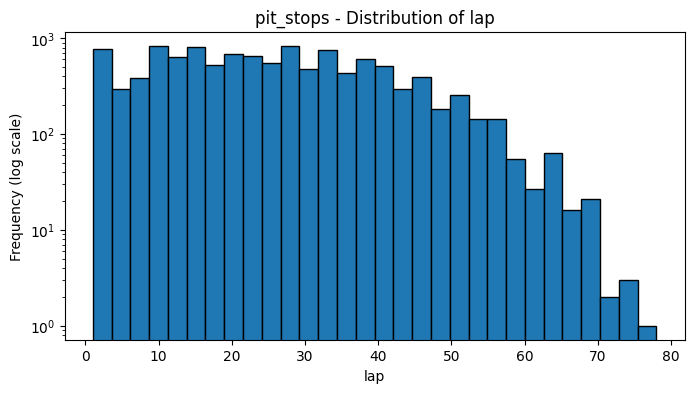

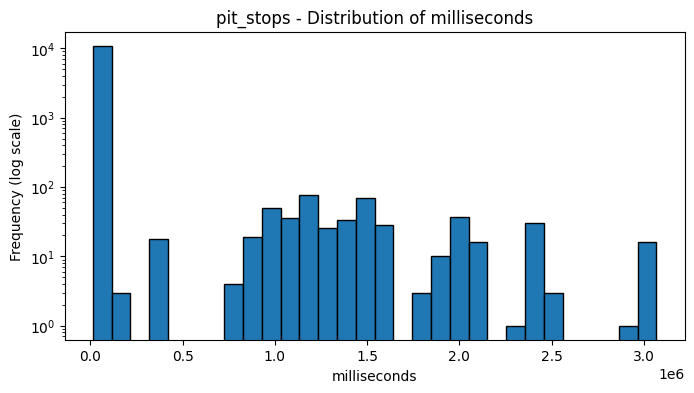

In [ ]:
inspect_df("pit_stops", pit_stops)

### 2.5.14 Constructor Results


**Constuctor_results**
*   points = points earned in that specific race

**constructor_standings**
*   points = total championship points accumulated up to that race



constuctor_results
--------------------------------------------------

Shape:
(12604, 5)

Columns:
['constructorResultsId', 'raceId', 'constructorId', 'points', 'status']

Info:
<class 'pandas.core.frame.DataFrame'>
Index: 12604 entries, 0 to 12624
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   constructorResultsId  12604 non-null  int64  
 1   raceId                12604 non-null  int64  
 2   constructorId         12604 non-null  int64  
 3   points                12604 non-null  float64
 4   status                17 non-null     object 
dtypes: float64(1), int64(3), object(1)
memory usage: 590.8+ KB

Dtypes:
constructorResultsId      int64
raceId                    int64
constructorId             int64
points                  float64
status                   object
dtype: object

Descriptive Statistics:


,constructorResultsId,raceId,constructorId,points,status
count,12604.000,12604.000,12604.000,12604.000,17
unique,NaN,NaN,NaN,NaN,1
top,NaN,NaN,NaN,NaN,D
freq,NaN,NaN,NaN,NaN,17
mean,8421.950,527.862,45.844,4.058,NaN
std,5670.684,314.922,59.455,7.867,NaN
min,1.000,1.000,1.000,0.000,NaN
25%,3151.750,287.000,6.000,0.000,NaN
50%,6302.500,487.000,22.000,0.000,NaN
75%,13970.250,750.000,54.000,5.000,NaN



Full duplicate rows:
0

First 5 rows:


,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.000,<NA>
1,2,18,2,8.000,<NA>
2,3,18,3,9.000,<NA>
3,4,18,4,5.000,<NA>
4,5,18,5,2.000,<NA>



Missing values (actual NaN):
constructorResultsId        0
raceId                      0
constructorId               0
points                      0
status                  12587
dtype: int64

Placeholder missing values:
No placeholder missing values found.


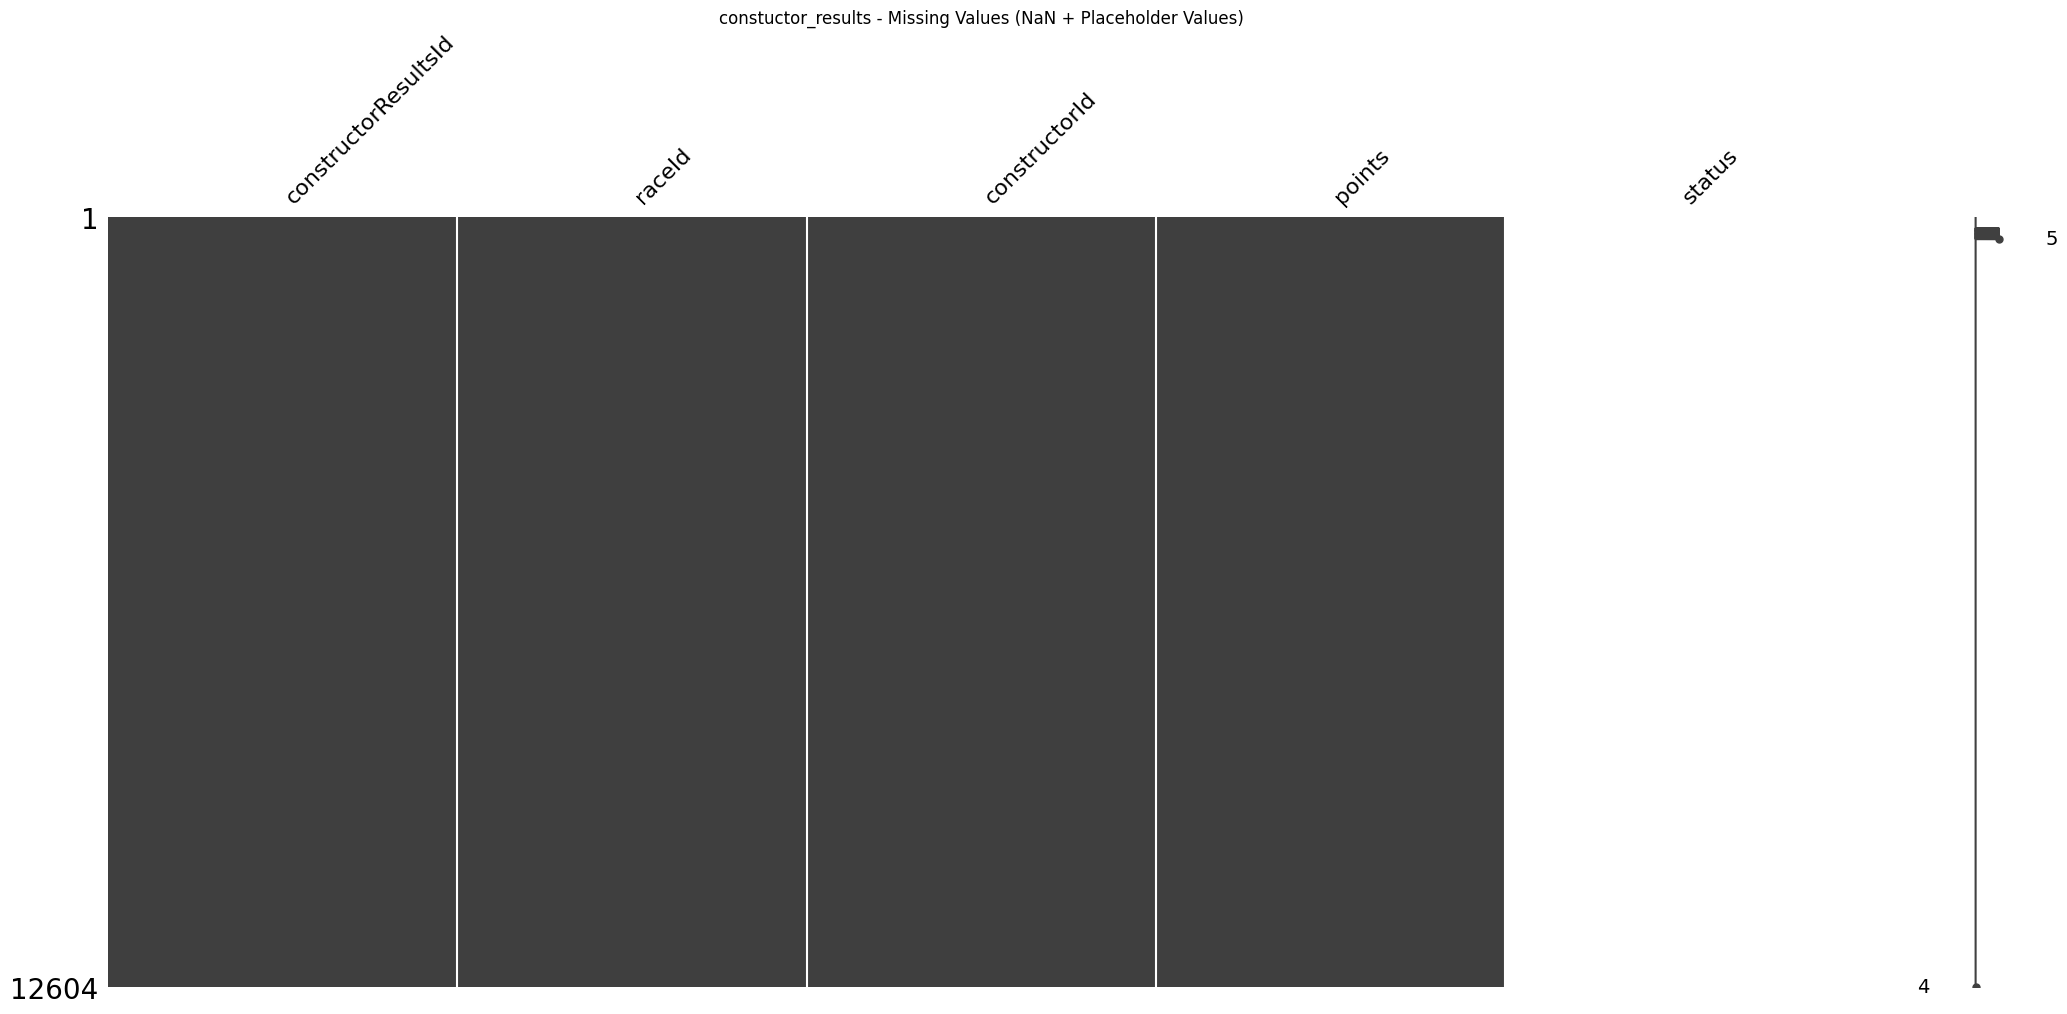


Numeric Distributions:


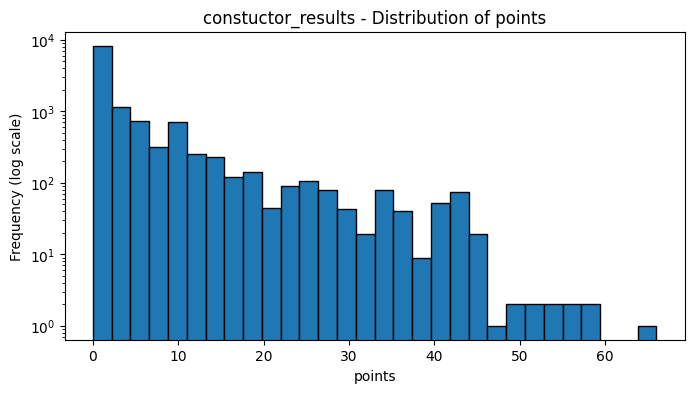

In [ ]:
inspect_df("constuctor_results", constructor_results)

In [ ]:
constructor_id = 1

print("\nRESULTS:")
print(
    constructor_results
    [constructor_results["constructorId"] == constructor_id]
    [["raceId", "points"]]
    .head(10)
)

print("\nSTANDINGS:")

print(
    constructor_standings
    [constructor_standings["constructorId"] == constructor_id]
    [["raceId", "points", "position", "wins"]]
    .head(10)
)


RESULTS:
    raceId  points
0       18  14.000
13      19  10.000
24      20   4.000
34      21   6.000
45      22   8.000
54      23  11.000
70      24   0.000
76      25   5.000
84      26  14.000
94      27  14.000

STANDINGS:
    raceId  points  position  wins
0       18  14.000         1     1
6       19  24.000         1     1
17      20  28.000         3     1
28      21  34.000         3     1
39      22  42.000         3     1
50      23  53.000         2     2
61      24  53.000         3     2
72      25  58.000         3     2
83      26  72.000         3     3
94      27  86.000         3     4


## 2.6 Duplicates


In [ ]:
duplicate_summary = []

for name, df in tables.items():

    duplicate_summary.append({
        "table": name,
        "exact_duplicate_rows": int(
            df.duplicated().sum()
        )
    })

duplicate_summary_df = pd.DataFrame(
    duplicate_summary
)

duplicate_summary_df

,table,exact_duplicate_rows
0,races,0
1,results,0
2,drivers,0
3,constructors,0
4,circuits,0
5,qualifying,0
6,status,0
7,driver_standings,0
8,constructor_standings,0
9,sprint_results,0


**Natural-key duplicates.** The primary-key check (2.3) and the exact-duplicate check above only catch rows with the same ID or identical values. A table can still describe the same thing twice under different IDs, e.g. the same driver twice in one qualifying session, or the same person entered as two drivers. So we also check each table's **natural key**: the columns that should be unique by meaning.

In [ ]:
natural_keys = [
    ("races", races, ["year", "round"]),
    ("races", races, ["year", "circuitId"]),
    ("results", results, ["raceId", "driverId"]),
    ("results", results, ["raceId", "positionOrder"]),
    ("qualifying", qualifying, ["raceId", "driverId"]),
    ("qualifying", qualifying, ["raceId", "position"]),
    ("sprint_results", sprint_results, ["raceId", "driverId"]),
    ("sprint_results", sprint_results, ["raceId", "positionOrder"]),
    ("driver_standings", driver_standings, ["raceId", "driverId"]),
    ("constructor_standings", constructor_standings, ["raceId", "constructorId"]),
    ("constructor_results", constructor_results, ["raceId", "constructorId"]),
    ("drivers", drivers, ["driverRef"]),
    ("drivers", drivers, ["forename", "surname", "dob"]),
    ("constructors", constructors, ["constructorRef"]),
    ("constructors", constructors, ["name"]),
    ("circuits", circuits, ["circuitRef"]),
    ("circuits", circuits, ["lat", "lng"]),
    ("status", status, ["status"]),
]

natural_key_audit = pd.DataFrame(
    [
        {"table": name, "natural_key": " + ".join(key),
         "duplicate_rows": int(df.duplicated(key, keep=False).sum())}
        for name, df, key in natural_keys
    ]
)
display(natural_key_audit)

# 1. Same circuit twice in one season
same_circuit = races[races.duplicated(["year", "circuitId"], keep=False)]
display(same_circuit[["raceId", "year", "round", "name", "date"]])

# 2. Where the results duplicates come from: raw file vs the working copy at this point
raw_dup_pairs = raw_results[raw_results.duplicated(["raceId", "driverId"], keep=False)][["raceId", "driverId"]].drop_duplicates()
now_dup_pairs = results[results.duplicated(["raceId", "driverId"], keep=False)][["raceId", "driverId"]].drop_duplicates()
print("Duplicated driver-race pairs in the raw results file:", len(raw_dup_pairs))
print("Duplicated driver-race pairs now (after the Indy 500 and failed-to-qualify removals):", len(now_dup_pairs))

,table,natural_key,duplicate_rows
0,races,year + round,0
1,races,year + circuitId,8
2,results,raceId + driverId,127
3,results,raceId + positionOrder,155
4,qualifying,raceId + driverId,0
5,qualifying,raceId + position,0
6,sprint_results,raceId + driverId,0
7,sprint_results,raceId + positionOrder,0
8,driver_standings,raceId + driverId,0
9,constructor_standings,raceId + constructorId,0


,raceId,year,round,name,date
1018,1031,2020,1,Austrian Grand Prix,2020-07-05
1019,1032,2020,2,Styrian Grand Prix,2020-07-12
1021,1034,2020,4,British Grand Prix,2020-08-02
1022,1035,2020,5,70th Anniversary Grand Prix,2020-08-09
1032,1045,2020,15,Bahrain Grand Prix,2020-11-29
1033,1046,2020,16,Sakhir Grand Prix,2020-12-06
1043,1058,2021,8,Styrian Grand Prix,2021-06-27
1045,1060,2021,9,Austrian Grand Prix,2021-07-04


Duplicated driver-race pairs in the raw results file: 85
Duplicated driver-race pairs now (after the Indy 500 and failed-to-qualify removals): 62


**Findings.**

- **All natural keys are unique except two, both in `races` and `results`.** No driver appears twice in a qualifying session, standings table or sprint, and no person, team or circuit is entered twice under different IDs.
- **Same circuit twice in one season (`races`, year + circuit):** these are the 2020–21 COVID double-headers (Austrian + Styrian GP, British + 70th Anniversary GP, Bahrain + Sakhir GP). They are separate races with their own date and round, so nothing is changed. In circuit-level analysis (Question 1), these circuits contribute two races in those seasons.
- **Same driver twice in one race (`results`, race + driver):** the shared drives handled in 2.6.1. The raw file has more of these pairs than the working copy, because earlier steps already removed some. The Indianapolis 500 exclusion removed Indy's own shared drives, and the failed-to-qualify (F) removal resolved two more (1958 Monaco GP, 1978 Italian GP), where one of the driver's two rows was an F. The order of these steps matters: run after 2.6.1, those pairs would appear as duplicates.
- **Two drivers with the same finishing position (`results`, race + positionOrder):** also caused by shared drives, where one car's result is copied onto each driver who drove it. The count left after cleaning is reported at the end of 2.6.1.

### 2.6.1 Driver-Race Grain

The analysis needs exactly one row per driver per race**: one start (grid position) and one result (podium or not). Some drivers appear more than once in the same race. This section finds out why, then fixes it.

A "car" below means one race + constructor + car number. A shared car is one car driven by two (or more) drivers one after the othe during the same race


**Step 1: count the duplicates and test what they are.**

In [ ]:
car_keys = ["raceId", "constructorId", "number"]

# Readable audit table: results plus race, driver, constructor and status names
audit = (
    results
    .merge(races[["raceId", "year", "name"]].rename(columns={"name": "race"}), on="raceId", how="left")
    .merge(drivers[["driverId", "forename", "surname"]], on="driverId", how="left")
    .merge(constructors[["constructorId", "name"]].rename(columns={"name": "constructor_name"}),
           on="constructorId", how="left")
    .merge(status[["statusId", "status"]], on="statusId", how="left")
)
audit["driver_name"] = audit["forename"].str.strip() + " " + audit["surname"].str.strip()

# Per car: how many drivers are recorded in it, and which row is its main (lowest resultId) row
# (rows with no car number cannot be matched to a car, so they count as unshared)
audit["car_drivers"] = audit.groupby(car_keys)["driverId"].transform("nunique").fillna(1).astype(int)
audit["main_row_of_car"] = audit["resultId"] == audit.groupby(car_keys)["resultId"].transform("min")

# Rows that belong to a duplicated driver-race pair
audit["is_dup"] = audit.duplicated(["raceId", "driverId"], keep=False)
dup_rows = audit[audit["is_dup"]]
n_pairs = dup_rows[["raceId", "driverId"]].drop_duplicates().shape[0]

# Every car the duplicated drivers are recorded in, and the shared ones among them
cars = (
    audit.merge(dup_rows[car_keys].drop_duplicates(), on=car_keys)
    .groupby(car_keys)
    .agg(n_drivers=("driverId", "nunique"), n_grid=("grid", "nunique"), n_laps=("laps", "nunique"),
         n_finish=("positionOrder", "nunique"), points=("points", list))
)
shared = cars[cars["n_drivers"] > 1]

summary = pd.DataFrame(
    [
        ("Driver-race pairs recorded more than once", n_pairs),
        ("Extra rows to remove", len(dup_rows) - n_pairs),
        ("Years affected", f"{dup_rows['year'].min()}-{dup_rows['year'].max()}"),
        ("... of which shared (more than one driver recorded)", len(shared)),
    ],
    columns=["check", "result"],
)
display(summary)

,check,result
0,Driver-race pairs recorded more than once,62
1,Extra rows to remove,65
2,Years affected,1950-1964
3,... of which shared (more than one driver recorded),59


**What these numbers mean.**

- 59 of those cars have more than one driver recorded in them.
- one car's result written under each driver who drove it.
- The one exception is the 1962 British GP #48: Keith Greene was entered in it but withdrew, and Tony Shelly raced it.
- points split between all drivers sharing a car (We know from the data. Every driver who finished 2nd alone in 1950 scored 6 points)


| Case | What the data shows | What happened |
|---|---|---|
| **A. Takeover** | The driver has one car of their own, plus a car shared with a teammate | Their car broke and they took over a teammate's car |
| **B. Swap** | All of the driver's cars are shared | Two (or three) drivers exchanged cars |
| **C. Single driver, two cars** | None of the driver's cars are shared | Recorded in two cars with no co-driver; needs a manual decision |

In [ ]:
# Classify each duplicated driver-race pair by how many of their cars are their own (unshared)
pairs = (
    dup_rows.groupby(["raceId", "driverId"])
    .agg(n_cars=("resultId", "size"), n_own_cars=("car_drivers", lambda s: (s == 1).sum()))
    .reset_index()
)

def classify(row):
    if row["n_own_cars"] == 0:
        return "B. Swap"
    if row["n_own_cars"] == row["n_cars"]:
        return "C. Single driver, two cars"
    return "A. Takeover"

pairs["case"] = pairs.apply(classify, axis=1)
audit = audit.merge(pairs[["raceId", "driverId", "case"]], on=["raceId", "driverId"], how="left")

display(
    pairs.groupby("case")
    .agg(driver_race_pairs=("case", "size"), rows_to_remove=("n_cars", lambda s: (s - 1).sum()))
    .reset_index()
)

# Helpers used by every case below ------------------------------------------
# Short description of one row: car, grid, result, laps, points, status
def car_label(r):
    return (f"#{r['number']} {r['constructor_name']} | grid {r['grid']} | {r['positionText']} | "
            f"{r['laps']} laps | {r['points']:g} pts | {r['status']}")

# Other drivers recorded in the same car
def co_drivers(r):
    same_car = ((audit["raceId"] == r["raceId"]) & (audit["constructorId"] == r["constructorId"])
                & (audit["number"] == r["number"]) & (audit["driverId"] != r["driverId"]))
    return ", ".join(audit.loc[same_car, "driver_name"])

# Keep one row per driver-race: rows where `prefer` is True first, then sort by `then` (ascending)
def resolve(case_rows, prefer, then=("resultId",)):
    ranked = case_rows.assign(prefer=prefer).sort_values(
        ["raceId", "driverId", "prefer", *then], ascending=[True, True, False] + [True] * len(then)
    )
    keep = ranked.drop_duplicates(["raceId", "driverId"])
    drop = case_rows[~case_rows["resultId"].isin(keep["resultId"])]
    return keep, drop

# One line per driver-race: the kept car and the dropped car(s)
def decision_table(keep, drop):
    dropped = (
        drop.assign(label=drop.apply(
            lambda r: car_label(r) + (f"  (also driven by {co_drivers(r)})" if co_drivers(r) else ""), axis=1))
        .groupby(["raceId", "driverId"])["label"].agg("\n".join)
        .rename("dropped car(s)")
    )
    return (
        keep.assign(kept_car=keep.apply(car_label, axis=1))
        .set_index(["raceId", "driverId"])
        .join(dropped)
        .sort_values(["year", "race", "driver_name"])
        [["year", "race", "driver_name", "kept_car", "dropped car(s)"]]
        .reset_index(drop=True)
    )

rows_to_drop = []   # resultIds removed by Cases A, B and C

,case,driver_race_pairs,rows_to_remove
0,A. Takeover,44,46
1,B. Swap,17,18
2,"C. Single driver, two cars",1,1


Case1: Takeover (44 pairs).  The driver has one car that nobody else drove (their own car), which broke down, and a teammate's car that they took over. We keep the taken-over car, because that is the car the driver finished the race in and the result they were credited with (shared points). We drop their own car's row and the row for a driver who didnt finish.


Notes on this choice:
- The kept row stays consistent: its grid and its result belong to the same car (#48 started 6th and finished 2nd). Grid 6 is the car's starting position, not Ascari's own qualifying (2nd in #16), and the car's start is the starting position his result came from which is okay cause grid hepls to know where car starts since it is a place advantge and qualifying is the thing assoiciated with the driver to tell his skills.


 one example (1950 Italian GP, Alberto Ascari). Ascari started in car #16, which failed after 21 laps. He then took over Dorino Serafini's car #48 and finished 2nd. Car #48's result (grid 6, 2nd, 80 laps) appears under both Serafini and Ascari, and 2nd place's 6 points are split 3 + 3.

In [ ]:
# Example: 1950 Italian GP, Alberto Ascari took over Dorino Serafini's car #48
example = audit[
    (audit["year"] == 1950)
    & (audit["race"] == "Italian Grand Prix")
    & (audit["constructor_name"] == "Ferrari")
    & (audit["number"].isin(["16", "48"]))
]

display(
    example.sort_values(["number", "resultId"])
    [["resultId", "driver_name", "number", "grid", "laps", "positionText",
      "status", "points", "car_drivers"]]
)

# Why 3 + 3 is a split: every driver who finished 2nd ALONE in 1950 scored 6 points
second_alone_1950 = audit[
    (audit["year"] == 1950)
    & (audit["positionOrder"] == 2)
    & (audit["car_drivers"] == 1)
]

display(second_alone_1950[["race", "driver_name", "points"]])


,resultId,driver_name,number,grid,laps,positionText,status,points,car_drivers
18438,20166,Alberto Ascari,16,2,21,R,Engine,0.000,1
18423,20151,Dorino Serafini,48,6,80,2,Finished,3.000,2
18453,20183,Alberto Ascari,48,6,80,2,Finished,3.000,2


,race,driver_name,points
18331,British Grand Prix,Luigi Fagioli,6.000
18352,Monaco Grand Prix,Alberto Ascari,6.000
18373,Swiss Grand Prix,Luigi Fagioli,6.000
18391,Belgian Grand Prix,Luigi Fagioli,6.000
18405,French Grand Prix,Luigi Fagioli,6.000


In [ ]:
case_a = audit[audit["case"] == "A. Takeover"]

# Rule: keep the taken-over (shared) car; if there are several, the one with the best finish
keep_a, drop_a = resolve(case_a, prefer=case_a["car_drivers"] > 1, then=("positionOrder", "resultId"))
rows_to_drop += drop_a["resultId"].tolist()

# Full decision table saved for inspection; only the first 5 rows are shown
case_a_decisions = decision_table(keep_a, drop_a)

print("Case A pairs:", len(keep_a), "| rows dropped:", len(drop_a))
with pd.option_context("display.max_colwidth", None):
    display(case_a_decisions.head(5))

Case A pairs: 44 | rows dropped: 46


,year,race,driver_name,kept_car,dropped car(s)
0,1950,French Grand Prix,Louis Rosier,#26 Talbot-Lago | grid 15 | 6 | 56 laps | 0 pts | +8 Laps,#20 Talbot-Lago | grid 6 | R | 10 laps | 0 pts | Overheating
1,1950,Italian Grand Prix,Alberto Ascari,#48 Ferrari | grid 6 | 2 | 80 laps | 3 pts | Finished,#16 Ferrari | grid 2 | R | 21 laps | 0 pts | Engine
2,1950,Italian Grand Prix,Juan Fangio,#60 Alfa Romeo | grid 7 | R | 34 laps | 0 pts | Engine,#18 Alfa Romeo | grid 1 | R | 23 laps | 1 pts | Gearbox
3,1951,French Grand Prix,Alberto Ascari,#14 Ferrari | grid 6 | 2 | 77 laps | 3 pts | Finished,#12 Ferrari | grid 3 | R | 10 laps | 0 pts | Gearbox
4,1951,Italian Grand Prix,Nino Farina,#40 Alfa Romeo | grid 7 | 3 | 79 laps | 3 pts | +1 Lap,#34 Alfa Romeo | grid 2 | R | 6 laps | 0 pts | Engine


**Step 4B: Swap (17 pairs).** Two (or three) drivers exchanged cars, so every car the driver is recorded in is shared. As in Case A, we keep the car the driver **finished in** (the car they took over), with that car's grid and result.

**How we tell which car that is.** Grid, laps and finish are copied onto every driver in a car, so those columns cannot tell us. The `resultId` can:
- Each car has one **main row** (its lowest `resultId`), in the race's normal block of IDs. The other drivers were added later, with much higher IDs.
- The main row belongs to the driver who **started** the car. We checked this on the takeovers, where the starter is known (the teammate who appears only in that car): it holds in 36 of 40 cars.
- So a driver's **added row** marks the car they took over, and that is the row we keep. If a driver has more than one added row (only Harry Schell, 1955 Argentine GP), we keep the one with the best finish, as in Case A.

**Example: 1951 French GP.** Fangio started #24 from pole and Fagioli started #8 from 7th. Mid-race they swapped cars, and Fangio won in #8.

| resultId | Driver | Car | Grid | Final position | Row type | Decision |
|---|---|---|---|---|---|---|
| 19918 | Fagioli | #8 | 7 | 1st | main (started #8) | drop |
| 19928 | Fangio | #24 | 1 | 11th | main (started #24) | drop |
| 20186 | Fangio | #8 | 7 | 1st | added (took over #8) | **keep** |
| 20188 | Fagioli | #24 | 1 | 11th | added (took over #24) | **keep** |

Result: Fangio keeps #8 (grid 7, 1st) and Fagioli keeps #24 (grid 1, 11th). Each kept row's grid and result come from the same car, and each car ends up with one driver, so no result is counted twice.

Caveat: the main-row pattern held in 36 of 40 checkable cars, not all, so roughly 1–2 of the 17 swap decisions may pick the wrong car. These rows are flagged `shared_drive = 1`.

**Validating the `resultId` rule.** The dataset does not label shared drives, so this rule is our inference, and we test it here:

1. **Two kinds of rows.** Each race lists one row per car, for the driver the car was entered for. Drivers who joined a car mid-race were added later, with IDs **above** the race's normal range.
2. **Checked on known cases.** In takeovers we know who started the taken-over car: the teammate who appears only in that car. If the rule is right, the original (lowest ID) row belongs to that starter.
3. **History.** Famous swaps come out right: Fangio–Fagioli (1951 French GP) and Moss–Brooks (1957 British GP).

So the higher-ID row marks the car a driver took over and finished in. The rule is about 90% reliable, so 1–2 of the 17 swaps could be wrong. Those rows are flagged `shared_drive = 1`.

In [ ]:
# 1. Added rows (not a car's main row) of drivers who actually drove: are their IDs above the race's normal range?
added = audit[(audit["car_drivers"] > 1) & ~audit["main_row_of_car"]]
drove = added[added["positionText"] != "W"]
normal_max = audit[~audit["resultId"].isin(added["resultId"])].groupby("raceId")["resultId"].max()
above = (drove["resultId"] > drove["raceId"].map(normal_max)).sum()
print(f"1. Added rows of drivers who drove the car, with an ID above the race's normal range: {above} of {len(drove)}")

# 2. Takeover cars: does the main (lowest ID) row belong to the known starter?
taken_over = case_a.loc[case_a["car_drivers"] > 1, car_keys].drop_duplicates()
car_rows = audit.merge(taken_over, on=car_keys)

def main_row_owner(car):
    if car["is_dup"].all():
        return "can't tell (no known starter)"
    starter_holds_main = not car.loc[car["resultId"].idxmin(), "is_dup"]
    return "starter" if starter_holds_main else "driver who took over"

owners = car_rows.groupby(car_keys).apply(main_row_owner, include_groups=False)
print("2. Taken-over cars, owner of the main row:")
print(owners.value_counts().to_string())

1. Added rows of drivers who drove the car, with an ID above the race's normal range: 81 of 81
2. Taken-over cars, owner of the main row:
starter                          36
can't tell (no known starter)     5
driver who took over              4


In [ ]:
case_b = audit[audit["case"] == "B. Swap"]

# Rule: keep the car the driver took over = their added (not main) row; if several, the best finish
keep_b, drop_b = resolve(case_b, prefer=~case_b["main_row_of_car"], then=("positionOrder", "resultId"))
rows_to_drop += drop_b["resultId"].tolist()

# Full decision table saved for inspection; only the first 5 rows are shown
case_b_decisions = decision_table(keep_b, drop_b)

print("Case B pairs:", len(keep_b), "| rows dropped:", len(drop_b))
with pd.option_context("display.max_colwidth", None):
    display(case_b_decisions.head(5))

Case B pairs: 17 | rows dropped: 18


,year,race,driver_name,kept_car,dropped car(s)
0,1951,French Grand Prix,Juan Fangio,#8 Alfa Romeo | grid 7 | 1 | 77 laps | 5 pts | Finished,#24 Alfa Romeo | grid 1 | 11 | 55 laps | 0 pts | +22 Laps (also driven by Luigi Fagioli)
1,1951,French Grand Prix,Luigi Fagioli,#24 Alfa Romeo | grid 1 | 11 | 55 laps | 0 pts | +22 Laps,#8 Alfa Romeo | grid 7 | 1 | 77 laps | 4 pts | Finished (also driven by Juan Fangio)
2,1953,German Grand Prix,Alberto Ascari,#4 Ferrari | grid 6 | R | 15 laps | 1 pts | Engine,#1 Ferrari | grid 1 | 8 | 17 laps | 0 pts | +1 Lap (also driven by Luigi Villoresi)
3,1953,German Grand Prix,Luigi Villoresi,#1 Ferrari | grid 1 | 8 | 17 laps | 0 pts | +1 Lap,#4 Ferrari | grid 6 | R | 15 laps | 0 pts | Engine (also driven by Alberto Ascari)
4,1953,Swiss Grand Prix,Felice Bonetto,#32 Maserati | grid 1 | 4 | 64 laps | 1.5 pts | +1 Lap,#30 Maserati | grid 10 | R | 29 laps | 0 pts | Engine (also driven by Juan Fangio)


**Step 4C: Single driver, two cars (1 pair).** Hernando da Silva Ramos (1956 French GP) is recorded alone in a Gordini (#32, finished 8th) and alone in a Maserati (#8, engine failure). There is no teammate to explain it. We keep his first entry, the Gordini, which was his regular team that season, and drop the Maserati.

In [ ]:
case_c = audit[audit["case"] == "C. Single driver, two cars"]

# Rule: keep the first recorded entry (lowest resultId)
keep_c, drop_c = resolve(case_c, prefer=pd.Series(False, index=case_c.index))
rows_to_drop += drop_c["resultId"].tolist()

print("Case C pairs:", len(keep_c), "| rows dropped:", len(drop_c))
with pd.option_context("display.max_colwidth", None):
    display(decision_table(keep_c, drop_c))

Case C pairs: 1 | rows dropped: 1


,year,race,driver_name,kept_car,dropped car(s)
0,1956,French Grand Prix,Hernando da Silva Ramos,#32 Gordini | grid 14 | 8 | 57 laps | 0 pts | +4 Laps,#8 Maserati | grid 16 | R | 40 laps | 0 pts | Engine


**Step 5: apply the removals and check the grain.**

We also add a `shared_drive` flag (1 = more than one driver was recorded in this row's car). It marks the teammates who handed their car over, like Serafini. They were never duplicates, but their result was partly driven by someone else. We keep these rows and only flag them.

Rows are kept or dropped whole. We never mix columns from two rows, so the grid and the result in a kept row always come from the same car.

In [ ]:
rows_before = len(results)

# Flag shared drives using the car counts from before the removal
results["shared_drive"] = results["resultId"].map(
    audit.set_index("resultId")["car_drivers"].gt(1).astype(int)
)

results = results[~results["resultId"].isin(rows_to_drop)].copy()

print("Rows removed:", rows_before - len(results), "(expected", len(dup_rows) - n_pairs, ")")
print("Rows remaining:", len(results))
print("Duplicate driver-race pairs remaining:", results.duplicated(["raceId", "driverId"]).sum())
print("Rows flagged as shared drives:", results["shared_drive"].sum())

# Rows that share a finishing position with another driver in the same race (copied shared-drive results)
ties = results.duplicated(["raceId", "positionOrder"], keep=False)
print("Rows sharing a finishing position with another driver:", ties.sum(),
      "| of which shared drives:", results.loc[ties, "shared_drive"].sum())

Rows removed: 65 (expected 65 )
Rows remaining: 24921
Duplicate driver-race pairs remaining: 0
Rows flagged as shared drives: 175
Rows sharing a finishing position with another driver: 119 | of which shared drives: 119


**Outcome.** `results` now has exactly one row per driver per race. The 65 removed rows were:

- **A. Takeover:** the driver's own car that broke down (the taken-over car is kept).
- **B. Swap:** the car the driver started in (the car they took over is kept).
- **C. Single driver, two cars:** the Maserati.

The 175 rows flagged `shared_drive = 1` are almost all from 1950–1966, out of about 25,000 rows. That is too few to change the results, but the flag lets us exclude them later if needed.

**Extra check: shared cars that never became duplicates.** A driver only becomes a duplicate if they appear in **two** cars in one race. Two drivers can also share one car while each appears only once, and that never shows up in the duplicate check. So we look at every car in the dataset with more than one driver recorded, not only the 59 linked to duplicates.

These other cars fall into two groups:
- **Shared drive:** both drivers have the same grid, laps and finish. One car was driven by both in turn (e.g. 1956 Argentine GP: Landi and Gerini, 4th, points split 1.5 + 1.5).
- **Entered, did not race:** one driver raced the car, while the other was entered in it but withdrew (grid 0, "W", 0 laps). E.g. 1979 Canadian GP: Niki Lauda quit during the weekend and Ricardo Zunino raced his Brabham.

In [ ]:
# All cars with more than one driver, excluding the ones already handled above
audit["car_has_dup"] = audit.groupby(car_keys)["is_dup"].transform("max").astype(bool)
other_shared = audit[(audit["car_drivers"] > 1) & ~audit["car_has_dup"]]

def car_group(car):
    if (car["positionText"] == "W").any():
        return "Entered, did not race"
    if car[["grid", "laps", "positionOrder"]].nunique().eq(1).all():
        return "Shared drive (same result)"
    return "Other"

other_cars = (
    other_shared.groupby(car_keys)
    .apply(lambda car: pd.Series({
        "year": car["year"].iat[0],
        "race": car["race"].iat[0],
        "constructor": car["constructor_name"].iat[0],
        "drivers": ", ".join(car["driver_name"]),
        "grid": list(car["grid"]),
        "finish": list(car["positionText"]),
        "laps": list(car["laps"]),
        "points": list(car["points"]),
        "group": car_group(car),
        "podium": (car["positionOrder"] <= 3).any() and car_group(car) == "Shared drive (same result)",
    }), include_groups=False)
    .reset_index(drop=True)
    .sort_values(["group", "year", "race"])
    .reset_index(drop=True)
)

print("Cars with more than one driver in the whole dataset:",
      audit.loc[audit["car_drivers"] > 1].groupby(car_keys).ngroups)
print("... already handled with the duplicates:",
      audit.loc[audit["car_has_dup"] & (audit["car_drivers"] > 1)].groupby(car_keys).ngroups)
print("... not linked to any duplicate:", len(other_cars))
print(other_cars["group"].value_counts().to_string())
print("Shared drives that were a podium (one podium counted for two drivers):", other_cars["podium"].sum())
print("Rows still in results and flagged shared_drive:",
      results.loc[results["resultId"].isin(other_shared["resultId"]), "shared_drive"].sum(),
      "of", len(other_shared))

# Full table saved in other_cars; show a few examples of each group
with pd.option_context("display.max_colwidth", None):
    display(other_cars.drop(columns="podium").groupby("group").head(3))

Cars with more than one driver in the whole dataset: 94
... already handled with the duplicates: 59
... not linked to any duplicate: 35
group
Entered, did not race         19
Shared drive (same result)    16
Shared drives that were a podium (one podium counted for two drivers): 0
Rows still in results and flagged shared_drive: 70 of 70


,year,race,constructor,drivers,grid,finish,laps,points,group
0,1954,British Grand Prix,Cooper,"Eric Brandon, Rodney Nuckey","[25, 29]","[R, W]","[2, 0]","[0.0, 0.0]","Entered, did not race"
1,1954,Swiss Grand Prix,Ferrari,"Umberto Maglioli, Robert Manzon","[11, 0]","[7, W]","[61, 0]","[0.0, 0.0]","Entered, did not race"
2,1955,Belgian Grand Prix,Ferrari,"Maurice Trintignant, Harry Schell","[10, 0]","[6, W]","[35, 0]","[0.0, 0.0]","Entered, did not race"
19,1950,British Grand Prix,Maserati,"Brian Shawe Taylor, Joe Fry","[20, 20]","[10, 10]","[64, 64]","[0.0, 0.0]",Shared drive (same result)
20,1950,British Grand Prix,ERA,"Peter Walker, Tony Rolt","[10, 10]","[R, R]","[5, 5]","[0.0, 0.0]",Shared drive (same result)
21,1950,French Grand Prix,Talbot-Lago,"Philippe Étancelin, Eugène Chaboud","[4, 4]","[5, 5]","[59, 59]","[1.0, 1.0]",Shared drive (same result)


**What this means for the data.**

- **Grain:** not affected. Each of these drivers has only one row in that race.
- **Double-counted podiums:** none. No shared drive in this group finished in the top 3, so no podium is credited to two drivers.
- **Flag:** all of these rows are already marked `shared_drive = 1` (part of the 175 flagged rows).
- **Withdrawn entries:** the "entered, did not race" rows have grid 0, so they are also marked `non_standard_start = True`, the same as a pit-lane start, although these drivers never started. We keep them, treated separately through `non_standard_start`: a withdrawal is announced before the start, so it is known at the prediction cutoff, and none of the 335 withdrawn rows ever reaches the podium, which the model learns from the flag (in 6.1, removing the weak features, this flag included, lowers the validation score).

## 2.7 Mapping Driver Nationality to Circuit Country


To answer **Question 2 — “Do drivers podium more often when racing at a circuit in their home country than elsewhere, after controlling for starting position?”**, we need to identify whether each driver is racing in their home country.

The raw `drivers` table contains the driver's **nationality** (e.g., `"British"`), while the `circuits` table contains the circuit's **country** (e.g., `"UK"`). These fields use different naming conventions, so they cannot be compared directly.

We therefore create a small manually defined lookup table:

**`nationality_country(nationality, country)`**

The mapping is kept in a separate table because `home` is a property of a **driver–race pair**, not a permanent property of a driver or a circuit. Later home will be computed during the analysis at the driver–race level

Keeping the mapping separate also:

- Leaves the raw dataset unchanged.
- Makes the manual mapping explicit and traceable.
- Handles nationalities that may correspond to multiple countries.
- Allows unmapped nationalities to be identified clearly.

Step 1 — Get all unique driver nationalities

In [ ]:
# Clean whitespace from nationality values
drivers['nationality'] = drivers['nationality'].str.strip()

# Get all unique nationalities
nationalities = sorted(drivers['nationality'].dropna().unique())

print(f"Number of unique nationalities: {len(nationalities)}")
print(nationalities)

Number of unique nationalities: 43
['American', 'American-Italian', 'Argentine', 'Argentine-Italian', 'Argentinian', 'Australian', 'Austrian', 'Belgian', 'Brazilian', 'British', 'Canadian', 'Chilean', 'Chinese', 'Colombian', 'Czech', 'Danish', 'Dutch', 'East German', 'Finnish', 'French', 'German', 'Hungarian', 'Indian', 'Indonesian', 'Irish', 'Italian', 'Japanese', 'Liechtensteiner', 'Malaysian', 'Mexican', 'Monegasque', 'New Zealander', 'Polish', 'Portuguese', 'Rhodesian', 'Russian', 'South African', 'Spanish', 'Swedish', 'Swiss', 'Thai', 'Uruguayan', 'Venezuelan']


Create manual nationality -> country mapping

In [ ]:

nationality_country_mapping = {
    'American': ['USA'],
    'American-Italian': ['USA', 'Italy'],
    'Argentine': ['Argentina'],
    'Argentine-Italian': ['Argentina', 'Italy'],
    'Argentinian': ['Argentina'],
    'Australian': ['Australia'],
    'Austrian': ['Austria'],
    'Belgian': ['Belgium'],
    'Brazilian': ['Brazil'],
    'British': ['UK'],
    'Canadian': ['Canada'],
    'Chilean': ['Chile'],
    'Chinese': ['China'],
    'Colombian': ['Colombia'],
    'Czech': ['Czech Republic'],
    'Danish': ['Denmark'],
    'Dutch': ['Netherlands'],
    'East German': ['Germany'],
    'Finnish': ['Finland'],
    'French': ['France'],
    'German': ['Germany'],
    'Hungarian': ['Hungary'],
    'Indian': ['India'],
    'Indonesian': ['Indonesia'],
    'Irish': ['Ireland'],
    'Italian': ['Italy'],
    'Japanese': ['Japan'],
    'Liechtensteiner': ['Liechtenstein'],
    'Malaysian': ['Malaysia'],
    'Mexican': ['Mexico'],
    'Monegasque': ['Monaco'],
    'New Zealander': ['New Zealand'],
    'Polish': ['Poland'],
    'Portuguese': ['Portugal'],
    'Rhodesian': ['Zimbabwe'],
    'Russian': ['Russia'],
    'South African': ['South Africa'],
    'Spanish': ['Spain'],
    'Swedish': ['Sweden'],
    'Swiss': ['Switzerland'],
    'Thai': ['Thailand'],
    'Uruguayan': ['Uruguay'],
    'Venezuelan': ['Venezuela']
}


Create the lookup table & Check that every nationality has been mapped

In [ ]:

nationality_country = pd.DataFrame(
    [
        (nationality, country)
        for nationality, countries in nationality_country_mapping.items()
        for country in countries
    ],
    columns=['nationality', 'country']
)

print("\nNationality → Country Lookup Table:")
display(nationality_country)

mapped_nationalities = set(nationality_country['nationality'])

unmapped = sorted(set(nationalities) - mapped_nationalities)

print(f"\nNumber of unmapped nationalities: {len(unmapped)}")

if unmapped:
    print("Unmapped nationalities:")
    print(unmapped)
else:
    print("All driver nationalities have been mapped successfully.")


Nationality → Country Lookup Table:


,nationality,country
0,American,USA
1,American-Italian,USA
2,American-Italian,Italy
3,Argentine,Argentina
4,Argentine-Italian,Argentina
5,Argentine-Italian,Italy
6,Argentinian,Argentina
7,Australian,Australia
8,Austrian,Austria
9,Belgian,Belgium



Number of unmapped nationalities: 0
All driver nationalities have been mapped successfully.


Check circuit country values against nationality-country map

In [ ]:

# Get unique countries from both tables
circuit_countries = sorted(circuits['country'].dropna().unique())
mapped_countries = sorted(nationality_country['country'].unique())

print(f"Number of unique circuit countries: {len(circuit_countries)}")
print(circuit_countries)

print(f"\nNumber of unique mapped countries: {len(mapped_countries)}")
print(mapped_countries)


# ------------------------------------------------------------
# Find circuit countries that are not in our mapping
# ------------------------------------------------------------

unmatched_circuit_countries = sorted(
    set(circuit_countries) - set(mapped_countries)
)

print("\nCircuit countries not found in nationality_country:")
print(unmatched_circuit_countries)

Number of unique circuit countries: 34
['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Morocco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'UAE', 'UK', 'USA']

Number of unique mapped countries: 39
['Argentina', 'Australia', 'Austria', 'Belgium', 'Brazil', 'Canada', 'Chile', 'China', 'Colombia', 'Czech Republic', 'Denmark', 'Finland', 'France', 'Germany', 'Hungary', 'India', 'Indonesia', 'Ireland', 'Italy', 'Japan', 'Liechtenstein', 'Malaysia', 'Mexico', 'Monaco', 'Netherlands', 'New Zealand', 'Poland', 'Portugal', 'Russia', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Thailand', 'UK', 'USA', 'Uruguay', 'Venezuela', 'Zimbabwe']

Circuit countries not found in nationality_country:
['Azerbaijan', 'Bahrain', 'Korea', 'Morocco', 'Qatar', '

Checking Country Compatibility

After standardizing the country names in the `circuits` table, the circuit countries were compared with the countries in the `nationality_country` lookup table.

Nine circuit countries do not appear in the lookup table:

- Azerbaijan
- Bahrain
- Korea
- Morocco
- Qatar
- Saudi Arabia
- Singapore
- Turkey
- UAE

These are not naming inconsistencies. They represent countries for which no corresponding driver nationality exists in the dataset. Therefore, no additional nationality mappings are required.

The lookup table is based on the driver nationalities present in the dataset, while the circuit table contains all countries where races have been held.

## 2.8 Data After Cleaning (Before vs After)

The same checks as in 1.1, repeated on the cleaned tables, to show the effect of every cleaning step in one place: rows and columns per table, the share of missing cells, and the podium rate (our target) before and after cleaning.

,rows_raw,rows_clean,columns_raw,columns_clean,missing_%_raw,missing_%_clean,rows_removed
table,,,,,,,
races,1125,1114,18,7,56.040,0.000,11
results,26759,24921,18,17,25.510,0.000,1838
drivers,861,861,9,7,20.120,0.000,0
constructors,212,212,5,5,0.000,0.000,0
circuits,77,77,9,9,0.000,0.000,0
qualifying,10494,10494,9,7,12.350,0.210,0
status,139,139,2,3,0.000,0.000,0
driver_standings,34863,34194,7,7,0.000,0.000,669
constructor_standings,13391,13365,7,7,0.000,0.000,26


Podium rate in results: 12.69% raw -> 13.46% cleaned


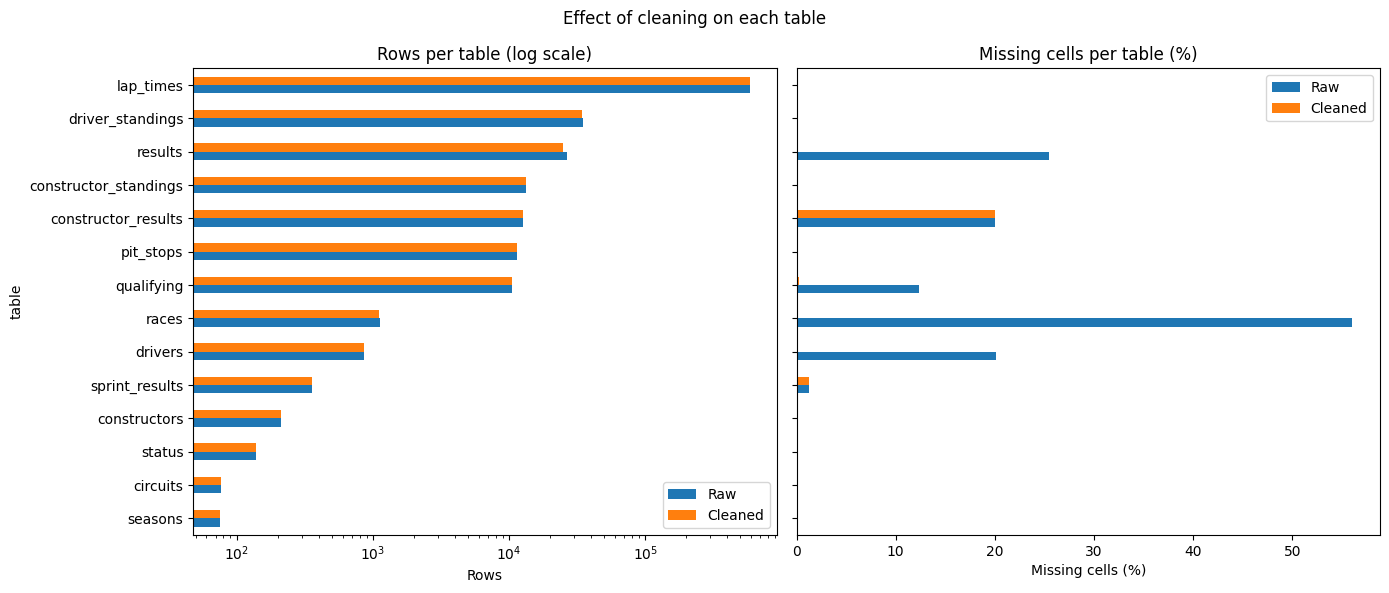

In [ ]:
# Raw vs cleaned: rows, columns and missing cells for every table
def missing_pct(df):
    """Share of missing cells: real NaN plus the '\\N' placeholder used in the raw CSVs."""
    missing = df.isna().to_numpy() | (df.astype(str).to_numpy() == r"\N")
    return 100 * missing.sum() / df.size

cleaning_impact = pd.DataFrame([
    {
        "table": name,
        "rows_raw": len(globals()[f"raw_{name}"]),
        "rows_clean": len(globals()[name]),
        "columns_raw": globals()[f"raw_{name}"].shape[1],
        "columns_clean": globals()[name].shape[1],
        "missing_%_raw": missing_pct(globals()[f"raw_{name}"]),
        "missing_%_clean": missing_pct(globals()[name]),
    }
    for name in tables
]).set_index("table")
cleaning_impact["rows_removed"] = cleaning_impact["rows_raw"] - cleaning_impact["rows_clean"]
display(cleaning_impact.round(2))

# Target before and after cleaning
podium_before = (raw_results["positionOrder"] <= 3).mean()
podium_after = results["podium"].mean()
print(f"Podium rate in results: {podium_before:.2%} raw -> {podium_after:.2%} cleaned")

fig, ax = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
order = cleaning_impact.sort_values("rows_raw").index
cleaning_impact.loc[order, ["rows_raw", "rows_clean"]].plot(kind="barh", ax=ax[0], logx=True)
ax[0].set_title("Rows per table (log scale)")
ax[0].set_xlabel("Rows")
ax[0].legend(["Raw", "Cleaned"])
cleaning_impact.loc[order, ["missing_%_raw", "missing_%_clean"]].plot(kind="barh", ax=ax[1])
ax[1].set_title("Missing cells per table (%)")
ax[1].set_xlabel("Missing cells (%)")
ax[1].legend(["Raw", "Cleaned"])
plt.suptitle("Effect of cleaning on each table")
plt.tight_layout()
plt.show()

**Effect of cleaning.**

- **Rows removed** only where we removed data on purpose. In `results`: the Indianapolis 500 rows (2.4), the failed-to-qualify (F) rows (2.5.2) and the 65 shared-drive duplicate rows (2.6.1). The standings, `races` and `constructor_results` tables lost their Indianapolis 500 rows. All other tables keep every row.
- **Missing cells drop to 0%** in `races` and `results`, and almost to 0% in `qualifying`. Mostly this is because the columns that were mostly missing were dropped: practice and session times in `races`, post-race timing columns in `results`, and the q2/q3 lap times in `qualifying`. `qualifying.q1` is kept with its 1.5% gaps. The reasons are in each table's section.
- **Still missing:** `drivers` (car number and code, which do not exist for early drivers; cell 2.5.3 calls `drop` on them without saving the result, so they are still in the table), `constructor_results` (the `status` column is almost always empty), and a few `sprint_results` timing fields. None of these columns are used as model features.
- **Podium rate rises from 12.7% to 13.5%**, because the removed rows (Indianapolis 500 entrants, non-qualifiers, duplicate shared-drive rows) were almost never podiums. Every remaining row is now one real race entry.

# 3. Data-Engineering Questions

## 3.1 Front-Row Start → Podium Conversion by Circuit

### 3.1.1 Front-Row Podium Conversion by Circuit

In [ ]:
q1 = (
    results[
        [
            "raceId",
            "driverId",
            "grid",
            "front_row",
            "podium"
        ]
    ]
    .merge(
        races[
            ["raceId", "year", "circuitId"]
        ],
        on="raceId",
        how="left"
    )
    .merge(
        circuits[
            ["circuitId", "name"]
        ].rename(
            columns={"name": "circuit_name"}
        ),
        on="circuitId",
        how="left"
    )
)

In [ ]:
display(q1.head())
print(q1.shape)
print(q1.isna().sum())

,raceId,driverId,grid,front_row,podium,year,circuitId,circuit_name
0,18,1,1,True,True,2008,1,Albert Park Grand Prix Circuit
1,18,2,5,False,True,2008,1,Albert Park Grand Prix Circuit
2,18,3,7,False,True,2008,1,Albert Park Grand Prix Circuit
3,18,4,11,False,False,2008,1,Albert Park Grand Prix Circuit
4,18,5,3,False,False,2008,1,Albert Park Grand Prix Circuit


(24921, 8)
raceId          0
driverId        0
grid            0
front_row       0
podium          0
year            0
circuitId       0
circuit_name    0
dtype: int64


In [ ]:
front_row = q1[
    q1["front_row"]
].copy()

print("Front-row driver-race records:", len(front_row))

Front-row driver-race records: 2220


In [ ]:
print(
    "Unique circuits:",
    circuits["circuitId"].nunique()
)

Unique circuits: 77


In [ ]:
circuit_conversion = (
    front_row
    .groupby(
        ["circuitId", "circuit_name"]
    )
    .agg(
        number_of_races=("raceId", "nunique"),
        front_row_starts=("driverId", "size"),
        podiums=("podium", "sum")
    )
    .reset_index()
)

# Divide by the actual number of front-row starts (not races x 2): a few races have
# only one front-row entry recorded, or extra ones from 1950s shared cars
circuit_conversion["podium_rate"] = (
    circuit_conversion["podiums"]
    / circuit_conversion["front_row_starts"]
)

circuit_conversion = (
    circuit_conversion
    .sort_values(
        ["podium_rate", "number_of_races"],
        ascending=[False, False]
    )
)

display(circuit_conversion.head(10))

,circuitId,circuit_name,number_of_races,front_row_starts,podiums,podium_rate
75,79,Miami International Autodrome,3,6,6,1.000
71,75,Autódromo Internacional do Algarve,2,4,4,1.000
76,80,Las Vegas Strip Street Circuit,2,4,4,1.000
29,31,Donington Park,1,2,2,1.000
62,64,Ain Diab,1,2,2,1.000
63,65,Pescara Circuit,1,2,2,1.000
72,76,Autodromo Internazionale del Mugello,1,2,2,1.000
73,77,Jeddah Corniche Circuit,4,8,7,0.875
67,69,Circuit of the Americas,12,24,20,0.833
66,68,Buddh International Circuit,3,6,5,0.833


**Note: circuits that hosted two races in one season.** In 2020–21 (COVID calendar) some circuits held two races in the same season, under different race names:
- Red Bull Ring: Austrian GP + Styrian GP (2020 and 2021)
- Silverstone: British GP + 70th Anniversary GP (2020)
- Bahrain International Circuit: Bahrain GP + Sakhir GP (2020)

These are separate races with their own date, round and starting grid, so `number_of_races` counts each one (it counts unique `raceId`s). As a result, these circuits have one or two extra races in the 2014+ era compared with a normal calendar. This was found in the natural-key check in 2.6 (`races`: year + circuit).

In [ ]:

top_circuits = (
    circuit_conversion
    .sort_values(
        ["podium_rate", "number_of_races"],
        ascending=[False, False]
    )
)

display(top_circuits.head(15))

,circuitId,circuit_name,number_of_races,front_row_starts,podiums,podium_rate
75,79,Miami International Autodrome,3,6,6,1.000
71,75,Autódromo Internacional do Algarve,2,4,4,1.000
76,80,Las Vegas Strip Street Circuit,2,4,4,1.000
29,31,Donington Park,1,2,2,1.000
62,64,Ain Diab,1,2,2,1.000
63,65,Pescara Circuit,1,2,2,1.000
72,76,Autodromo Internazionale del Mugello,1,2,2,1.000
73,77,Jeddah Corniche Circuit,4,8,7,0.875
67,69,Circuit of the Americas,12,24,20,0.833
66,68,Buddh International Circuit,3,6,5,0.833


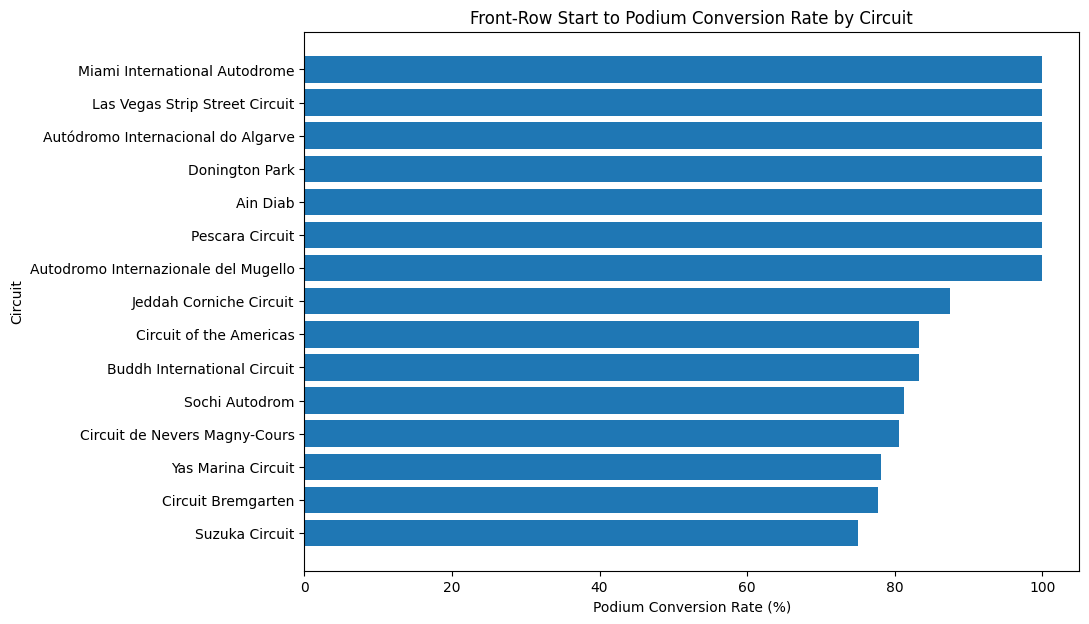

In [ ]:
top_circuits = (
    top_circuits
    .head(15)
    .sort_values("podium_rate")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_circuits["circuit_name"],
    top_circuits["podium_rate"] * 100
)

plt.xlabel("Podium Conversion Rate (%)")
plt.ylabel("Circuit")
plt.title(
    "Front-Row Start to Podium Conversion Rate by Circuit"
)

plt.show()

Top 15 with atleast 5 races starts ranked by highest conversion

In [ ]:
MIN_RACES = 5

reliable_circuits = (
    circuit_conversion[
        circuit_conversion["number_of_races"] >= MIN_RACES
    ]
    .sort_values(
        ["podium_rate", "number_of_races"],
        ascending=[False, False]
    )
)

display(reliable_circuits.head(15))

,circuitId,circuit_name,number_of_races,front_row_starts,podiums,podium_rate
67,69,Circuit of the Americas,12,24,20,0.833
69,71,Sochi Autodrom,8,16,13,0.812
7,8,Circuit de Nevers Magny-Cours,18,36,29,0.806
22,24,Yas Marina Circuit,16,32,25,0.781
64,66,Circuit Bremgarten,5,9,7,0.778
21,22,Suzuka Circuit,34,68,51,0.750
39,41,Dijon-Prenois,6,12,9,0.750
1,2,Sepang International Circuit,19,37,27,0.730
4,5,Istanbul Park,9,18,13,0.722
3,4,Circuit de Barcelona-Catalunya,34,68,48,0.706


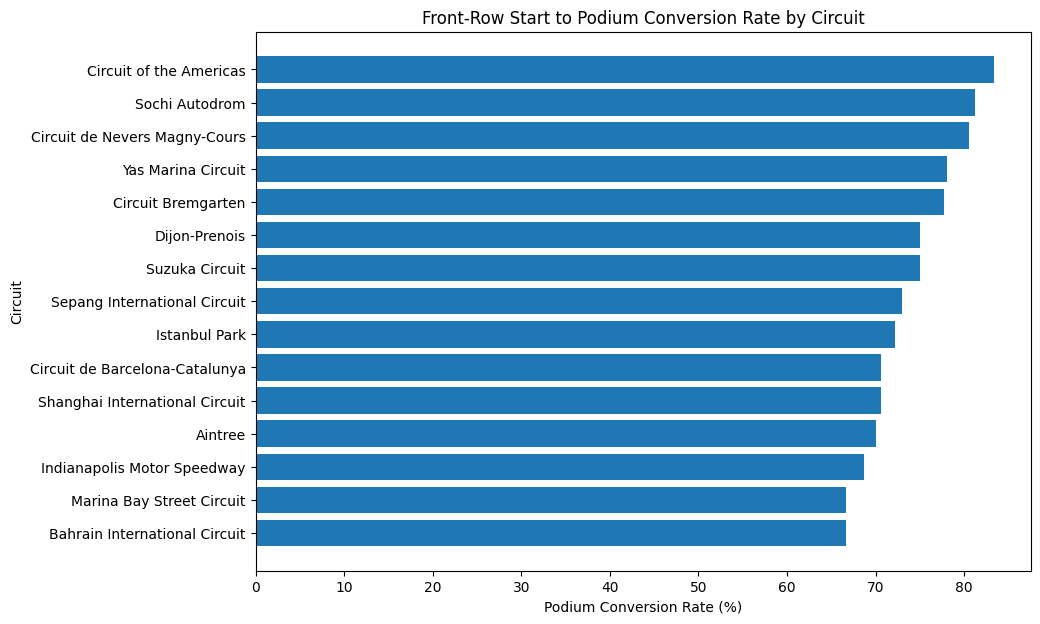

In [ ]:
top_circuits = (
    reliable_circuits
    .head(15)
    .sort_values("podium_rate")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_circuits["circuit_name"],
    top_circuits["podium_rate"] * 100
)

plt.xlabel("Podium Conversion Rate (%)")
plt.ylabel("Circuit")
plt.title(
    "Front-Row Start to Podium Conversion Rate by Circuit"
)

plt.show()

### 3.1.2 Pre-2014 vs 2014+ Comparison

In [ ]:
front_row["era"] = np.where(
    front_row["year"] < 2014,
    "Pre-2014",
    "2014+"
)

era_conversion = (
    front_row
    .groupby(["circuitId", "circuit_name", "era"])
    .agg(
        front_row_starts=("driverId", "size"),
        podiums=("podium", "sum")
    )
    .reset_index()
)

era_conversion["podium_rate"] = (
    era_conversion["podiums"]
    / era_conversion["front_row_starts"]
)


**All circuits (no minimum).** First we compare the two eras using every circuit that hosted races in both eras, however few front-row starts it had. Circuits with only a handful of starts can get extreme rates (0% or 100%) by chance, so this view is shown for completeness. The reliable version below is the one we interpret.

Circuits used in both eras (no minimum): 24


,pre2014_starts,post2014_starts,pre2014_rate,post2014_rate,pre2014_rank,post2014_rank,rate_change,rank_change
circuit_name,,,,,,,,
Circuit de Monaco,120.000,20.000,0.492,0.850,55.000,10.000,0.358,-45.000
Autodromo Nazionale di Monza,124.000,22.000,0.484,0.727,56.000,22.000,0.243,-34.000
Circuit de Spa-Francorchamps,89.000,22.000,0.551,0.818,37.000,11.000,0.268,-26.000
Circuit Park Zandvoort,60.000,8.000,0.583,0.875,31.000,6.000,0.292,-25.000
Circuit Gilles Villeneuve,68.000,18.000,0.529,0.778,39.000,17.000,0.248,-22.000
Red Bull Ring,50.000,26.000,0.520,0.731,40.000,21.000,0.211,-19.000
Yas Marina Circuit,10.000,22.000,0.600,0.864,26.000,8.000,0.264,-18.000
Silverstone Circuit,94.000,24.000,0.564,0.750,35.000,18.000,0.186,-17.000
Circuit Paul Ricard,28.000,8.000,0.571,0.750,33.000,18.000,0.179,-15.000


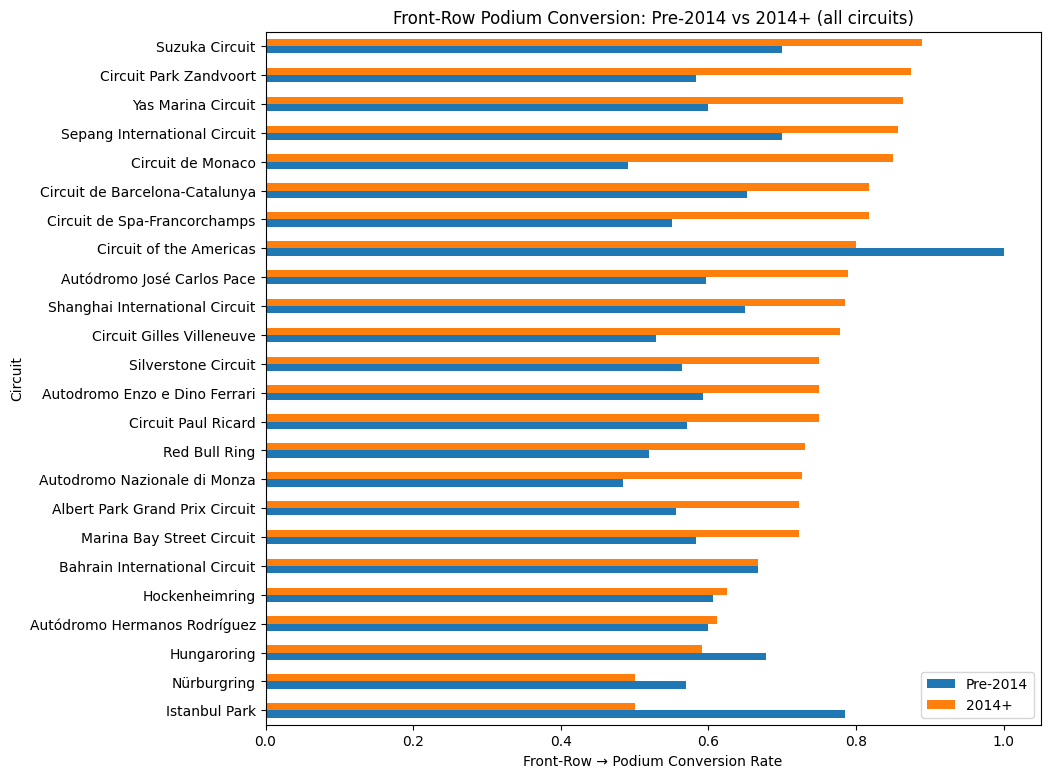

In [ ]:
# Rank every circuit within each era, with no minimum number of front-row starts
era_all = era_conversion.copy()
era_all["rank"] = era_all.groupby("era")["podium_rate"].rank(method="min", ascending=False)

rate_all = era_all.pivot(index="circuit_name", columns="era", values="podium_rate")
rank_all = era_all.pivot(index="circuit_name", columns="era", values="rank")

# Keep circuits used in both eras
era_compare_all = pd.DataFrame({
    "pre2014_starts": era_all.pivot(index="circuit_name", columns="era", values="front_row_starts")["Pre-2014"],
    "post2014_starts": era_all.pivot(index="circuit_name", columns="era", values="front_row_starts")["2014+"],
    "pre2014_rate": rate_all["Pre-2014"],
    "post2014_rate": rate_all["2014+"],
    "pre2014_rank": rank_all["Pre-2014"],
    "post2014_rank": rank_all["2014+"],
}).dropna()

era_compare_all["rate_change"] = era_compare_all["post2014_rate"] - era_compare_all["pre2014_rate"]
era_compare_all["rank_change"] = era_compare_all["post2014_rank"] - era_compare_all["pre2014_rank"]

print("Circuits used in both eras (no minimum):", len(era_compare_all))
display(era_compare_all.sort_values("rank_change").head(10))

# Plot every circuit used in both eras
plot_all = era_compare_all[["pre2014_rate", "post2014_rate"]].sort_values("post2014_rate")
plot_all.plot(kind="barh", figsize=(10, 9))
plt.xlabel("Front-Row → Podium Conversion Rate")
plt.ylabel("Circuit")
plt.title("Front-Row Podium Conversion: Pre-2014 vs 2014+ (all circuits)")
plt.legend(["Pre-2014", "2014+"])
plt.show()

**Reliable circuits only (at least 10 front-row starts per era).** 10 front-row starts is 5 races (2 front-row cars per race), the same threshold as the "at least 5 races" ranking in 3.1.1. A circuit must reach it in **each** era to be compared.

**Caution about the ranks in the next tables.** Each circuit is ranked within its own era *before* keeping the circuits present in both eras, so the pre-2014 ranks are out of every circuit with enough starts before 2014 (many of them no longer raced) and the 2014+ ranks out of a much smaller set. Rank changes in these tables are therefore not comparable. The fair comparison, with both rankings over the same circuits, follows the bar chart.

In [ ]:
era_reliable = era_conversion[
    era_conversion["front_row_starts"] >= 10
].copy()


era_reliable["rank"] = (
    era_reliable
    .groupby("era")["podium_rate"]
    .rank(
        method="min",
        ascending=False
    )
)

In [ ]:
# Top 5 circuits of each era (full ranking stays in era_reliable)
display(
    era_reliable
    .sort_values(["era", "rank"])
    .groupby("era")
    .head(5)
    [
        [
            "circuit_name",
            "era",
            "front_row_starts",
            "podiums",
            "podium_rate",
            "rank"
        ]
    ]
)

,circuit_name,era,front_row_starts,podiums,podium_rate,rank
38,Suzuka Circuit,2014+,18,16,0.889,1.000
40,Yas Marina Circuit,2014+,22,19,0.864,2.000
10,Circuit de Monaco,2014+,20,17,0.850,3.000
6,Circuit de Barcelona-Catalunya,2014+,22,18,0.818,4.000
22,Circuit de Spa-Francorchamps,2014+,22,18,0.818,4.000
14,Circuit de Nevers Magny-Cours,Pre-2014,36,29,0.806,1.000
9,Istanbul Park,Pre-2014,14,11,0.786,2.000
61,Dijon-Prenois,Pre-2014,12,9,0.750,3.000
3,Sepang International Circuit,Pre-2014,30,21,0.700,4.000
39,Suzuka Circuit,Pre-2014,50,35,0.700,4.000


In [ ]:
rate_compare = era_reliable.pivot(
    index="circuit_name",
    columns="era",
    values="podium_rate"
)

rank_compare = era_reliable.pivot(
    index="circuit_name",
    columns="era",
    values="rank"
)

era_compare = pd.DataFrame({
    "pre2014_rate": rate_compare["Pre-2014"],
    "post2014_rate": rate_compare["2014+"],
    "pre2014_rank": rank_compare["Pre-2014"],
    "post2014_rank": rank_compare["2014+"]
}).dropna()

In [ ]:
# Yas Marina, 2014+: every front-row start, with the 19 podiums marked
yas = (
    front_row[(front_row["circuit_name"] == "Yas Marina Circuit") & (front_row["era"] == "Pre-2014")]
    .merge(races[["raceId", "name", "date"]], on="raceId")
    .merge(drivers[["driverId", "forename", "surname"]], on="driverId")
    .merge(results[["raceId", "driverId", "constructorId", "positionOrder", "statusId"]], on=["raceId", "driverId"])
    .merge(constructors[["constructorId", "name"]].rename(columns={"name": "team"}), on="constructorId")
    .merge(status[["statusId", "status"]], on="statusId")
    .assign(driver=lambda d: d["forename"] + " " + d["surname"])
    .sort_values(["year", "grid"])
    [["year", "name", "driver", "team", "grid", "positionOrder", "status", "podium"]]
    .rename(columns={"name": "race", "positionOrder": "finish"})
    .reset_index(drop=True)
)

print(f"Front-row starts: {len(yas)}, podiums: {yas['podium'].sum()}, rate: {yas['podium'].mean():.3f}")
display(yas)

# Only the 3 that did NOT convert
display(yas[~yas["podium"]])

Front-row starts: 10, podiums: 6, rate: 0.600


,year,race,driver,team,grid,finish,status,podium
0,2009,Abu Dhabi Grand Prix,Lewis Hamilton,McLaren,1,19,Brakes,False
1,2009,Abu Dhabi Grand Prix,Sebastian Vettel,Red Bull,2,1,Finished,True
2,2010,Abu Dhabi Grand Prix,Sebastian Vettel,Red Bull,1,1,Finished,True
3,2010,Abu Dhabi Grand Prix,Lewis Hamilton,McLaren,2,2,Finished,True
4,2011,Abu Dhabi Grand Prix,Sebastian Vettel,Red Bull,1,24,Puncture,False
5,2011,Abu Dhabi Grand Prix,Lewis Hamilton,McLaren,2,1,Finished,True
6,2012,Abu Dhabi Grand Prix,Lewis Hamilton,McLaren,1,21,Electrical,False
7,2012,Abu Dhabi Grand Prix,Mark Webber,Red Bull,2,20,Collision,False
8,2013,Abu Dhabi Grand Prix,Mark Webber,Red Bull,1,2,Finished,True
9,2013,Abu Dhabi Grand Prix,Sebastian Vettel,Red Bull,2,1,Finished,True


,year,race,driver,team,grid,finish,status,podium
0,2009,Abu Dhabi Grand Prix,Lewis Hamilton,McLaren,1,19,Brakes,False
4,2011,Abu Dhabi Grand Prix,Sebastian Vettel,Red Bull,1,24,Puncture,False
6,2012,Abu Dhabi Grand Prix,Lewis Hamilton,McLaren,1,21,Electrical,False
7,2012,Abu Dhabi Grand Prix,Mark Webber,Red Bull,2,20,Collision,False


In [ ]:
era_compare["rate_change"] = (
    era_compare["post2014_rate"]
    - era_compare["pre2014_rate"]
)

era_compare["rank_change"] = (
    era_compare["post2014_rank"]
    - era_compare["pre2014_rank"]
)

display(
    era_compare.sort_values("rank_change")
)

,pre2014_rate,post2014_rate,pre2014_rank,post2014_rank,rate_change,rank_change
circuit_name,,,,,,
Circuit de Monaco,0.492,0.850,35.000,3.000,0.358,-32.000
Autodromo Nazionale di Monza,0.484,0.727,36.000,13.000,0.243,-23.000
Circuit de Spa-Francorchamps,0.551,0.818,27.000,4.000,0.268,-23.000
Circuit Gilles Villeneuve,0.529,0.778,29.000,10.000,0.248,-19.000
Red Bull Ring,0.520,0.731,30.000,12.000,0.211,-18.000
Yas Marina Circuit,0.600,0.864,16.000,2.000,0.264,-14.000
Silverstone Circuit,0.564,0.750,25.000,11.000,0.186,-14.000
Albert Park Grand Prix Circuit,0.556,0.722,26.000,14.000,0.167,-12.000
Autódromo José Carlos Pace,0.597,0.789,19.000,8.000,0.193,-11.000


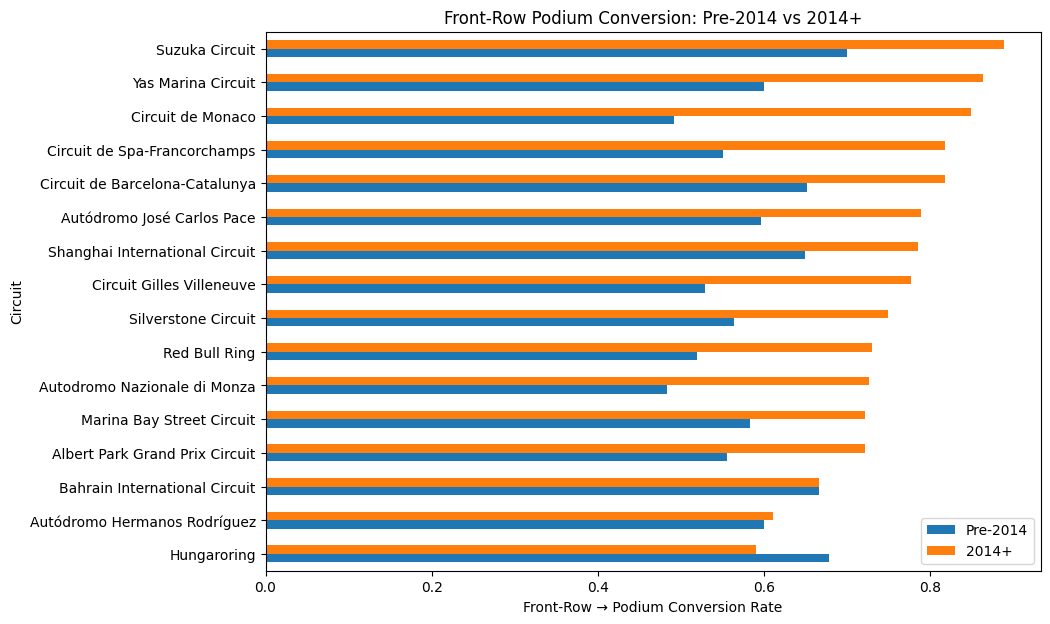

In [ ]:
plot_data = (
    era_compare[
        ["pre2014_rate", "post2014_rate"]
    ]
    .sort_values("post2014_rate")
)

plot_data.plot(
    kind="barh",
    figsize=(10, 7)
)

plt.xlabel("Front-Row → Podium Conversion Rate")
plt.ylabel("Circuit")
plt.title(
    "Front-Row Podium Conversion: Pre-2014 vs 2014+"
)

plt.legend([
    "Pre-2014",
    "2014+"
])

plt.show()

**Fair comparison: does the ranking change after 2014?** To compare rankings, both must rank the **same circuits**. We keep the circuits with at least 10 front-row starts in **both** eras and rank them again within that common set. Then we measure:
- **Spearman rank correlation** between the two eras: +1 = same order, 0 = no relation, −1 = reversed. This is the direct answer to "does the ranking change?".
- **Top-5 overlap:** how many of the pre-2014 top 5 are still top 5 after 2014.
- **Change beyond the era-wide shift:** every circuit converts more often after 2014 (cars became more reliable, see below), so a circuit's own change is its rate change minus the average change of all front-row starts. Ranks already remove this shift, because it moves every circuit together.
- **95% confidence intervals** (Wilson) on every rate, and a bootstrap interval for the Spearman correlation, because each circuit has only 10–30 front-row starts per era.

In [ ]:
# =========================
# 3.1.2 FAIR ERA COMPARISON: both rankings over the SAME circuits
# =========================
from scipy.stats import spearmanr
from statsmodels.stats.proportion import proportion_confint

MIN_STARTS = 10   # front-row starts needed in EACH era (= 5 races)

wide = era_conversion.pivot(index="circuit_name", columns="era", values=["front_row_starts", "podiums"])
in_both = (wide[("front_row_starts", "Pre-2014")] >= MIN_STARTS) & (wide[("front_row_starts", "2014+")] >= MIN_STARTS)
wide = wide[in_both]

fair = pd.DataFrame({
    "pre_starts":  wide[("front_row_starts", "Pre-2014")].astype(int),
    "pre_podiums": wide[("podiums", "Pre-2014")].astype(int),
    "post_starts": wide[("front_row_starts", "2014+")].astype(int),
    "post_podiums": wide[("podiums", "2014+")].astype(int),
})
fair["pre_rate"] = fair["pre_podiums"] / fair["pre_starts"]
fair["post_rate"] = fair["post_podiums"] / fair["post_starts"]
for era in ["pre", "post"]:
    low, high = proportion_confint(fair[f"{era}_podiums"], fair[f"{era}_starts"], alpha=0.05, method="wilson")
    fair[f"{era}_ci_low"], fair[f"{era}_ci_high"] = low, high
    fair[f"{era}_rank"] = fair[f"{era}_rate"].rank(method="min", ascending=False).astype(int)
fair["rank_change"] = fair["post_rank"] - fair["pre_rank"]          # negative = moved up after 2014

# Change of each circuit beyond the era-wide change of all front-row starts
era_avg = front_row.groupby("era")["podium"].mean()
fair["rate_change"] = fair["post_rate"] - fair["pre_rate"]
fair["change_beyond_era_shift"] = fair["rate_change"] - (era_avg["2014+"] - era_avg["Pre-2014"])

# How different the pools were in the earlier tables
pool = era_reliable.groupby("era").size()
print(f"Earlier tables ranked {pool['Pre-2014']} circuits before 2014 and {pool['2014+']} from 2014 (different pools).")
print(f"Fair comparison: {len(fair)} circuits with at least {MIN_STARTS} front-row starts in both eras.")
print(f"Era-wide conversion: {era_avg['Pre-2014']:.1%} before 2014, {era_avg['2014+']:.1%} from 2014")

# Direct answer: how similar are the two rankings?
rho, p_value = spearmanr(fair["pre_rate"], fair["post_rate"])

# Bootstrap: resample the front-row starts of every circuit and era, recompute the correlation
rng_boot = np.random.RandomState(RANDOM_STATE)
boot = []
for _ in range(2000):
    pre_b = rng_boot.binomial(fair["pre_starts"], fair["pre_rate"]) / fair["pre_starts"]
    post_b = rng_boot.binomial(fair["post_starts"], fair["post_rate"]) / fair["post_starts"]
    boot.append(spearmanr(pre_b, post_b)[0])
boot_low, boot_high = np.nanpercentile(boot, [2.5, 97.5])

top5_pre = set(fair.sort_values("pre_rate", ascending=False).head(5).index)
top5_post = set(fair.sort_values("post_rate", ascending=False).head(5).index)

print(f"Spearman rank correlation, pre-2014 vs 2014+: {rho:.2f} (p = {p_value:.2f}), "
      f"95% bootstrap interval {boot_low:.2f} to {boot_high:.2f}")
print(f"Top-5 overlap: {len(top5_pre & top5_post)} of 5 ({', '.join(sorted(top5_pre & top5_post)) or 'none'})")

# Sensitivity: compare with 2000-2013 only, so the result does not depend on 1950s-1990s cars
modern = front_row[front_row["year"].between(2000, 2013)].groupby("circuit_name")["podium"].agg(["size", "mean"])
post = front_row[front_row["year"] >= 2014].groupby("circuit_name")["podium"].agg(["size", "mean"])
sens = modern.join(post, lsuffix="_pre", rsuffix="_post", how="inner")
sens = sens[(sens["size_pre"] >= MIN_STARTS) & (sens["size_post"] >= MIN_STARTS)]
rho_sens, p_sens = spearmanr(sens["mean_pre"], sens["mean_post"])
print(f"Sensitivity, 2000-2013 vs 2014+ ({len(sens)} circuits): Spearman {rho_sens:.2f} (p = {p_sens:.2f})")

display(
    fair.sort_values("post_rank")[[
        "pre_starts", "pre_rate", "pre_rank", "post_starts", "post_rate", "post_rank",
        "rank_change", "rate_change", "change_beyond_era_shift",
    ]].round(3)
)

Earlier tables ranked 44 circuits before 2014 and 19 from 2014 (different pools).
Fair comparison: 16 circuits with at least 10 front-row starts in both eras.
Era-wide conversion: 56.3% before 2014, 76.0% from 2014
Spearman rank correlation, pre-2014 vs 2014+: -0.03 (p = 0.91), 95% bootstrap interval -0.48 to 0.41
Top-5 overlap: 2 of 5 (Circuit de Barcelona-Catalunya, Suzuka Circuit)
Sensitivity, 2000-2013 vs 2014+ (14 circuits): Spearman 0.03 (p = 0.93)


,pre_starts,pre_rate,pre_rank,post_starts,post_rate,post_rank,rank_change,rate_change,change_beyond_era_shift
circuit_name,,,,,,,,,
Suzuka Circuit,50,0.700,1,18,0.889,1,0,0.189,-0.008
Yas Marina Circuit,10,0.600,6,22,0.864,2,-4,0.264,0.067
Circuit de Monaco,120,0.492,15,20,0.850,3,-12,0.358,0.161
Circuit de Barcelona-Catalunya,46,0.652,4,22,0.818,4,0,0.166,-0.031
Circuit de Spa-Francorchamps,89,0.551,12,22,0.818,4,-8,0.268,0.071
Autódromo José Carlos Pace,62,0.597,8,19,0.789,6,-2,0.193,-0.004
Shanghai International Circuit,20,0.650,5,14,0.786,7,2,0.136,-0.061
Circuit Gilles Villeneuve,68,0.529,13,18,0.778,8,-5,0.248,0.051
Silverstone Circuit,94,0.564,10,24,0.750,9,-1,0.186,-0.011


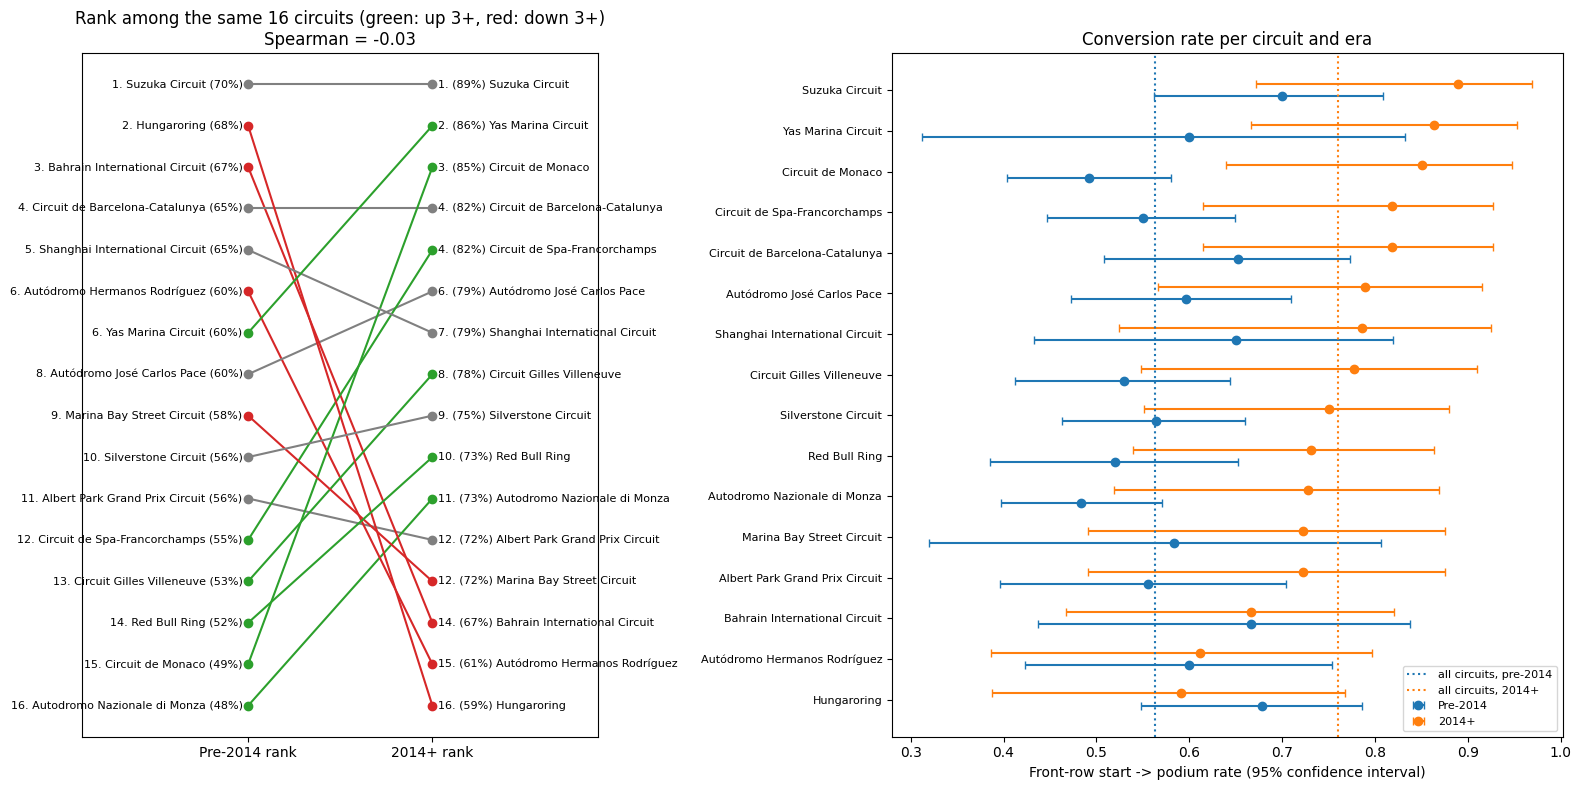

In [ ]:
# Slope chart of the ranks (left) and the rates with 95% confidence intervals (right)
fig, ax = plt.subplots(1, 2, figsize=(16, 8), gridspec_kw={"width_ratios": [1, 1.3]})

# Plot positions: tied ranks are spread out (order among ties by name) so that labels do not overlap
pre_pos = fair["pre_rate"].rank(method="first", ascending=False)
post_pos = fair["post_rate"].rank(method="first", ascending=False)
for name, row in fair.iterrows():
    color = "tab:green" if row["rank_change"] <= -3 else "tab:red" if row["rank_change"] >= 3 else "gray"
    ax[0].plot([0, 1], [pre_pos[name], post_pos[name]], marker="o", color=color)
    ax[0].text(-0.03, pre_pos[name], f"{int(row['pre_rank'])}. {name} ({row['pre_rate']:.0%})", ha="right", va="center", fontsize=8)
    ax[0].text(1.03, post_pos[name], f"{int(row['post_rank'])}. ({row['post_rate']:.0%}) {name}", ha="left", va="center", fontsize=8)
ax[0].set_xlim(-0.9, 1.9)
ax[0].invert_yaxis()
ax[0].set_xticks([0, 1])
ax[0].set_xticklabels(["Pre-2014 rank", "2014+ rank"])
ax[0].set_yticks([])
ax[0].set_title(f"Rank among the same {len(fair)} circuits (green: up 3+, red: down 3+)\n"
                f"Spearman = {rho:.2f}")

order = fair.sort_values("post_rate").index
y = np.arange(len(order))
for offset, era, label in [(-0.15, "pre", "Pre-2014"), (0.15, "post", "2014+")]:
    rate = fair.loc[order, f"{era}_rate"]
    err = [rate - fair.loc[order, f"{era}_ci_low"], fair.loc[order, f"{era}_ci_high"] - rate]
    ax[1].errorbar(rate, y + offset, xerr=err, fmt="o", capsize=3, label=label)
ax[1].axvline(era_avg["Pre-2014"], color="tab:blue", ls=":", label="all circuits, pre-2014")
ax[1].axvline(era_avg["2014+"], color="tab:orange", ls=":", label="all circuits, 2014+")
ax[1].set_yticks(y)
ax[1].set_yticklabels(order, fontsize=8)
ax[1].set_xlabel("Front-row start -> podium rate (95% confidence interval)")
ax[1].set_title("Conversion rate per circuit and era")
ax[1].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

In [ ]:
# Circuits raced in only ONE era: they cannot be in the rank comparison, so we list them separately
one_era = era_conversion[era_conversion["front_row_starts"] >= MIN_STARTS].copy()
one_era["eras"] = one_era.groupby("circuit_name")["era"].transform("nunique")
one_era = one_era[one_era["eras"] == 1]
low, high = proportion_confint(one_era["podiums"], one_era["front_row_starts"], alpha=0.05, method="wilson")
one_era["ci_95"] = [f"{a:.0%}-{b:.0%}" for a, b in zip(low, high)]

for era in ["2014+", "Pre-2014"]:
    part = one_era[one_era["era"] == era].sort_values("podium_rate", ascending=False)
    print(f"Circuits with at least {MIN_STARTS} front-row starts ONLY in {era}: {len(part)} (top 5 shown)")
    display(part.head(5)[["circuit_name", "front_row_starts", "podiums", "podium_rate", "ci_95"]].round(3))

Circuits with at least 10 front-row starts ONLY in 2014+: 3 (top 5 shown)


,circuit_name,front_row_starts,podiums,podium_rate,ci_95
93,Sochi Autodrom,16,13,0.812,57%-93%
89,Circuit of the Americas,20,16,0.800,58%-92%
94,Baku City Circuit,16,10,0.625,39%-82%


Circuits with at least 10 front-row starts ONLY in Pre-2014: 28 (top 5 shown)


,circuit_name,front_row_starts,podiums,podium_rate,ci_95
14,Circuit de Nevers Magny-Cours,36,29,0.806,65%-90%
9,Istanbul Park,14,11,0.786,52%-92%
61,Dijon-Prenois,12,9,0.750,47%-91%
3,Sepang International Circuit,30,21,0.700,52%-83%
78,Aintree,10,7,0.700,40%-89%


**Answer: does the ranking change after 2014?** Yes. The pre-2014 ranking tells us almost nothing about the 2014+ ranking.

- **The order is reshuffled.** Over the same 16 circuits, the Spearman correlation between the two eras is about **0.0** (−0.03, p = 0.91). Only 2 of the pre-2014 top 5 stay in the 2014+ top 5 (Suzuka and Barcelona). Comparing with 2000–2013 only gives the same result (0.03), so this is not caused by the very old seasons.
- **Biggest movers.** Monaco rises from 15th to 3rd (49% → 85%), Spa from 12th to 4th. The Hungaroring falls from 2nd to last (68% → 59%), Bahrain from 3rd to 14th and Mexico City from 6th to 15th. These three are the only circuits whose conversion did not rise with the era (19 to 29 points below the era-wide change).
- **Most single moves are within noise.** Each circuit has only 10–30 front-row starts per era, so the 95% intervals are wide, and the bootstrap interval of the correlation is −0.48 to 0.41. Only **Monaco's** change is larger than its uncertainty (intervals 40–58% before vs 64–95% after). So the safe conclusion is that the earlier ranking does **not carry over** (a strong positive correlation is ruled out), not that every individual circuit really moved.
- **Top circuits after 2014:** Suzuka (89%), Yas Marina (86%) and Monaco (85%) among circuits raced in both eras. Of the circuits raced only since 2014, Sochi (81%) and COTA (80%) rank as high, and Baku is lower (63%).
- **Earlier rank changes were overstated.** The first era tables ranked 44 circuits before 2014 but only 19 from 2014, so almost every circuit seemed to climb. Ranked over the same circuits, Monaco moves 12 places, not 32.

These are descriptive patterns, not causes: a circuit's rate also reflects which teams dominated the races held there.

**Why do front-row starts convert more often after 2014?** Almost every circuit has a higher conversion rate in the 2014+ era. We check two possible reasons: front-row cars finishing more often (reliability), and front-row cars converting better when they do finish.

In [ ]:
# Did the front-row car finish? ("Finished" or "+N Lap(s)")
why_conversion = front_row.merge(
    results[["raceId", "driverId", "statusId"]], on=["raceId", "driverId"], how="left"
).merge(status[["statusId", "status"]], on="statusId", how="left")

why_conversion["finished"] = (
    why_conversion["status"].eq("Finished")
    | why_conversion["status"].str.match(r"^\+\d+ Laps?$", na=False)
)
why_conversion["decade"] = (why_conversion["year"] // 10) * 10

def conversion_summary(df):
    return pd.Series({
        "front_row_starts": len(df),
        "podium_rate": df["podium"].mean(),
        "finish_rate": df["finished"].mean(),
        "podium_rate_if_finished": df.loc[df["finished"], "podium"].mean(),
    })

print("By era:")
display(why_conversion.groupby("era").apply(conversion_summary, include_groups=False).round(3))

print("By decade:")
display(why_conversion.groupby("decade").apply(conversion_summary, include_groups=False).round(3))

By era:


,front_row_starts,podium_rate,finish_rate,podium_rate_if_finished
era,,,,
2014+,454.000,0.760,0.916,0.829
Pre-2014,1766.000,0.563,0.700,0.803


By decade:


,front_row_starts,podium_rate,finish_rate,podium_rate_if_finished
decade,,,,
1950,142.000,0.585,0.725,0.806
1960,198.000,0.465,0.566,0.821
1970,288.000,0.497,0.639,0.772
1980,312.000,0.458,0.606,0.757
1990,324.000,0.605,0.682,0.887
2000,348.000,0.658,0.833,0.790
2010,395.000,0.742,0.906,0.818
2020,213.000,0.751,0.920,0.816


**Interpretation.**

- Front-row starts converted to a podium **56%** of the time before 2014 and **76%** from 2014 on.
- Most of that gap is **reliability**. Before 2014, only 70% of front-row cars finished the race; from 2014, 92% did. Among front-row cars that **did** finish, the conversion rate is almost the same in both eras (about 80% vs 83%). A front-row car that finishes was already very likely to podium; modern cars simply break down far less often.
- The improvement is **gradual, not a jump at 2014**. Conversion was about 46–50% in the 1960s–80s, 66% in the 2000s and 74–75% in the 2010s–20s. The pre-2014 group mixes all of these decades, including the low-reliability early years, which pulls its average down.
- Team dominance probably adds a little: in the hybrid era one team (Mercedes, later Red Bull) often held both front-row places and had the fastest car in the race.

So the higher post-2014 conversion mainly reflects more reliable cars over time, not something specific to the 2014 rules. These are descriptive patterns, not proof of cause.

### 3.1.3 Qualifying Position vs Grid Position

The question asks us to distinguish **qualifying position** from **grid position**:
- **Qualifying position** is the order from the qualifying session.
- **Grid position** is where the car actually starts the race, after grid penalties (e.g. for extra engine or gearbox parts), pit-lane starts and exclusions. That is why the two can differ.

The analysis above uses **grid**, because that is where the car actually starts. Here we check what changes if we define "front row" by qualifying instead. The `qualifying` table only covers 1994 onwards (and not every race), so this comparison uses only races that have qualifying records.

In [ ]:
# Qualifying position for each driver-race (the qualifying table only covers 1994 onwards)
q1_quali = q1.merge(
    qualifying[["raceId", "driverId", "position"]].rename(columns={"position": "quali_position"}),
    on=["raceId", "driverId"],
    how="inner",
)
q1_quali["quali_front_row"] = q1_quali["quali_position"].isin([1, 2])
q1_quali["grid_front_row"] = q1_quali["front_row"].astype(bool)

def front_row_case(row):
    if row["quali_front_row"] and row["grid_front_row"]:
        return "Front row in both"
    if row["quali_front_row"]:
        return "Qualified front row, started further back"
    if row["grid_front_row"]:
        return "Started front row, qualified further back"
    return "Neither"

q1_quali["case"] = q1_quali.apply(front_row_case, axis=1)

print("Races with qualifying data:", q1_quali["raceId"].nunique(),
      f"({q1_quali['year'].min()}-{q1_quali['year'].max()})")

front_row_cases = (
    q1_quali[q1_quali["case"] != "Neither"]
    .groupby("case")
    .agg(driver_races=("podium", "size"), podiums=("podium", "sum"), podium_rate=("podium", "mean"))
    .round(3)
)
display(front_row_cases)

# Same circuit ranking, once by qualifying front row and once by grid front row
def circuit_rate(flag):
    return (
        q1_quali[q1_quali[flag]]
        .groupby("circuit_name")
        .agg(races=("raceId", "nunique"), podium_rate=("podium", "mean"))
    )

quali_vs_grid = circuit_rate("quali_front_row").join(
    circuit_rate("grid_front_row"), lsuffix="_quali", rsuffix="_grid", how="outer"
)
quali_vs_grid = quali_vs_grid[quali_vs_grid[["races_quali", "races_grid"]].min(axis=1) >= MIN_RACES].copy()
quali_vs_grid["rank_quali"] = quali_vs_grid["podium_rate_quali"].rank(method="min", ascending=False)
quali_vs_grid["rank_grid"] = quali_vs_grid["podium_rate_grid"].rank(method="min", ascending=False)
quali_vs_grid["rate_difference"] = quali_vs_grid["podium_rate_grid"] - quali_vs_grid["podium_rate_quali"]

print("Circuits compared (at least", MIN_RACES, "races):", len(quali_vs_grid))
print("Spearman correlation of the two rankings:",
      round(quali_vs_grid["rank_quali"].corr(quali_vs_grid["rank_grid"], method="spearman"), 3))
print("Circuits whose rank changes:", (quali_vs_grid["rank_quali"] != quali_vs_grid["rank_grid"]).sum())
display(
    quali_vs_grid.sort_values("rate_difference", key=abs, ascending=False)
    .head(5).round(3)
)

Races with qualifying data: 494 (1994-2024)


,driver_races,podiums,podium_rate
case,,,
Front row in both,950,669,0.704
"Qualified front row, started further back",38,11,0.289
"Started front row, qualified further back",36,23,0.639


Circuits compared (at least 5 races): 27
Spearman correlation of the two rankings: 0.889
Circuits whose rank changes: 21


,races_quali,podium_rate_quali,races_grid,podium_rate_grid,rank_quali,rank_grid,rate_difference
circuit_name,,,,,,,
Baku City Circuit,8,0.688,8,0.625,10.000,23.000,-0.062
Autódromo Hermanos Rodríguez,9,0.556,9,0.611,26.000,24.000,0.056
Istanbul Park,9,0.667,9,0.722,14.000,8.000,0.056
Autódromo José Carlos Pace,27,0.611,27,0.660,23.000,20.000,0.049
Circuit de Monaco,24,0.729,24,0.771,7.000,6.000,0.042


**Result.**

- In the races with qualifying data, qualifying and grid front rows agree in most cases (950 front-row starts). In 74 cases they differ, usually because of a grid penalty or a pit-lane start.
- **What matters is where the car starts.** Drivers who **qualified** on the front row but **started further back** reached the podium only **29%** of the time, against **70%** when they started where they qualified. Drivers promoted onto the front row by others' penalties converted **64%** of the time, close to normal front-row starters.
- **The circuit ranking hardly changes.** Ranking circuits by qualifying front row or by grid front row gives very similar orders (Spearman correlation 0.89). Most circuits move only a few places. Baku moves the most (10th by qualifying, 23rd by grid), because penalties there changed the front row in a few races.

So we use **grid position** to define the front row in 3.1.1–3.1.2. It is the actual starting position, it exists for every season (qualifying data only starts in 1994), and switching to qualifying would not change the main ranking.

In [ ]:
# QUALIFYING vs GRID BY ERA (qualifying records start in 1994, so "before 2014" here means 1994-2013)
q1_quali["era"] = np.where(q1_quali["year"] < 2014, "1994-2013", "2014+")
era_cases = (
    q1_quali[q1_quali["case"] != "Neither"]
    .groupby(["case", "era"])
    .agg(driver_races=("podium", "size"), podium_rate=("podium", "mean"))
    .unstack("era")
    .round(3)
)
display(era_cases)

driver_races       podium_rate      
era                                          1994-2013 2014+   1994-2013 2014+
case                                                                          
Front row in both                                  523   427       0.654 0.766
Qualified front row, started further back            9    29       0.222 0.310
Started front row, qualified further back            9    27       0.556 0.667

**By era.** The same pattern holds before and after 2014: the start position decides, not the qualifying position. Front-row starters who also qualified there converted 65% of the time in 1994–2013 and 77% from 2014. Drivers who qualified on the front row but started further back converted only 22% and 31%. The main change is how often this happens: such grid changes tripled from 18 cases (1994–2013) to 56 (2014+), as the hybrid era's limits on engine and gearbox parts brought more grid penalties. The pre-2014 penalty groups have only 9 cases each, so their rates are rough.

**Grain, missingness and pre-race cutoff (Question 1).**
- **Grain:** one row per driver per race (the cleaned `results`). A front-row start is a row with grid position 1 or 2. Conversion = podiums ÷ front-row starts, per circuit (3.1.1) and per circuit and era (3.1.2).
- **Missingness:** `grid` has no missing values. Grid 0 (pit-lane starts and withdrawn drivers) is never a front-row start, so those rows drop out of this analysis automatically. Qualifying positions only exist from 1994, so 3.1.3 uses only races with qualifying records.
- **Pre-race cutoff:** the front row (grid) is known before the start. The finishing position is used only to decide the outcome (podium or not).

## 3.2 Home-Country Podium Effect

**Question:**  
Do drivers podium more often when racing at a circuit in their home country than elsewhere, after controlling for starting position?

To answer this question, we construct one row per **driver-race pair** by combining:

- `results` → starting grid position and finishing position
- `drivers` → driver nationality
- `races` → race and circuit identification
- `circuits` → circuit country
- `nationality_country` → derived mapping from driver nationality to country

The `home` feature is defined as:

- `home = 1` if the circuit country matches one of the driver's mapped home countries.
- `home = 0` otherwise.

The outcome is:

- `podium = 1` if the driver finished in positions 1, 2, or 3.
- `podium = 0` otherwise.

Only **pre-race information** is used to determine `home` and `grid`. The finishing position is used only as the outcome, so no post-race information is used as a predictor.

Because starting position strongly affects podium probability, we compare home and away drivers within similar starting-grid groups rather than comparing their overall podium rates directly.


### 3.2.1 Build the Multi-Hop Joined Dataset


In [ ]:
# Start from results
q2 = results[
    ['raceId', 'driverId', 'grid', 'positionOrder']
].copy()

# Driver nationality
q2 = q2.merge(
    drivers[['driverId', 'nationality']],
    on='driverId',
    how='left'
)

# Race → circuit
q2 = q2.merge(
    races[['raceId', 'circuitId']],
    on='raceId',
    how='left'
)

# Circuit country
q2 = q2.merge(
    circuits[['circuitId', 'country']]
        .rename(columns={'country': 'circuit_country'}),
    on='circuitId',
    how='left'
)

# Nationality → possible home countries
q2 = q2.merge(
    nationality_country
        .rename(columns={'country': 'home_country'}),
    on='nationality',
    how='left'
)

display(q2.head(20))

,raceId,driverId,grid,positionOrder,nationality,circuitId,circuit_country,home_country
0,18,1,1,1,British,1,Australia,UK
1,18,2,5,2,German,1,Australia,Germany
2,18,3,7,3,German,1,Australia,Germany
3,18,4,11,4,Spanish,1,Australia,Spain
4,18,5,3,5,Finnish,1,Australia,Finland
5,18,6,13,6,Japanese,1,Australia,Japan
6,18,7,17,7,French,1,Australia,France
7,18,8,15,8,Finnish,1,Australia,Finland
8,18,9,2,9,Polish,1,Australia,Poland
9,18,10,18,10,German,1,Australia,Germany


Creating the Home-Race Feature
A driver is considered to be racing at home if the circuit country matches **at least one** of the countries associated with their nationality.

This is to handle drivers with multiple mapped countries, such as `American-Italian` and `Argentine-Italian`.


In [ ]:
home_status = (
    q2.groupby(['raceId', 'driverId'])
      .apply(
          lambda x: int(
              (x['circuit_country'] == x['home_country']).any()
          ),
          include_groups=False
      )
      .reset_index(name='home')
)

q2 = q2.merge(
    home_status,
    on=['raceId', 'driverId'],
    how='left'
)

# Dual nationalities (e.g. American-Italian) got one row per mapped country: keep one row per driver per race
q2 = q2.drop_duplicates(['raceId', 'driverId'])

display(
    q2[
        ['raceId', 'driverId', 'nationality',
         'circuit_country', 'home_country', 'home']
    ].head(20)
)

,raceId,driverId,nationality,circuit_country,home_country,home
0,18,1,British,Australia,UK,0
1,18,2,German,Australia,Germany,0
2,18,3,German,Australia,Germany,0
3,18,4,Spanish,Australia,Spain,0
4,18,5,Finnish,Australia,Finland,0
5,18,6,Japanese,Australia,Japan,0
6,18,7,French,Australia,France,0
7,18,8,Finnish,Australia,Finland,0
8,18,9,Polish,Australia,Poland,0
9,18,10,German,Australia,Germany,0


Creating the Podium Outcome

The target variable is `podium`.

A driver is considered to have achieved a podium if their final `positionOrder` is **1st, 2nd, or 3rd**.



In [ ]:
q2['podium'] = (
    q2['positionOrder'].between(1, 3)
).astype(int)

display(
    q2[
        ['raceId', 'driverId', 'grid',
         'positionOrder', 'home', 'podium']
    ].head(20)
)

,raceId,driverId,grid,positionOrder,home,podium
0,18,1,1,1,0,1
1,18,2,5,2,0,1
2,18,3,7,3,0,1
3,18,4,11,4,0,0
4,18,5,3,5,0,0
5,18,6,13,6,0,0
6,18,7,17,7,0,0
7,18,8,15,8,0,0
8,18,9,2,9,0,0
9,18,10,18,10,0,0


Controlling for Starting Position

To prevent starting position from driving the result, drivers are grouped by similar starting positions. We compare home and away drivers within each group.

In [ ]:
# Keep observations with a valid starting grid
q2_analysis = q2[
    q2['grid'].notna() &
    (q2['grid'] > 0) &
    q2['home'].notna() &
    q2['podium'].notna()
].copy()

# Starting-position groups
q2_analysis['grid_group'] = pd.cut(
    q2_analysis['grid'],
    bins=[0, 3, 10, float('inf')],
    labels=['1–3', '4–10', '11+']
)

Podium Rate by Home Status and Starting Position

For each starting-position group, we calculate the percentage of drivers who finished on the podium, separately for home and away races.

The difference between the two rates shows whether home drivers podium more often than away drivers when starting from a similar position.

Home vs. Away Difference

The home-minus-away difference is calculated within each starting-position group.

A positive value means home drivers podiumed more often than away drivers from similar starting positions.

In [ ]:
podium_comparison = (
    q2_analysis
    .groupby(['grid_group', 'home'], observed=True)
    .agg(
        driver_races=('podium', 'size'),
        podiums=('podium', 'sum'),
        podium_rate=('podium', 'mean')
    )
    .reset_index()
)

podium_comparison['podium_rate'] *= 100

podium_comparison['home_status'] = podium_comparison['home'].map({
    0: 'Away',
    1: 'Home'
})

display(
    podium_comparison[
        ['grid_group', 'home_status',
         'driver_races', 'podiums', 'podium_rate']
    ]
)
comparison = (
    podium_comparison
    .pivot(
        index='grid_group',
        columns='home_status',
        values='podium_rate'
    )
)

comparison['home_minus_away'] = (
    comparison['Home'] - comparison['Away']
)

display(comparison)

,grid_group,home_status,driver_races,podiums,podium_rate
0,1–3,Away,3105,1725,55.556
1,1–3,Home,229,130,56.769
2,4–10,Away,7231,1195,16.526
3,4–10,Home,563,86,15.275
4,11+,Away,12355,206,1.667
5,11+,Home,1149,13,1.131


home_status,Away,Home,home_minus_away
grid_group,,,
1–3,55.556,56.769,1.213
4–10,16.526,15.275,-1.251
11+,1.667,1.131,-0.536


### 3.2.2 Visualization

The chart summarizes the controlled comparison: home versus away podium rates within each starting-position group.

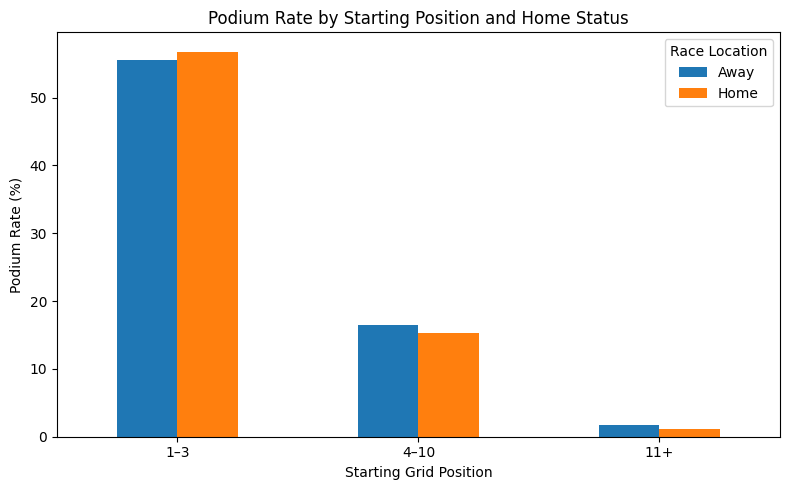

In [ ]:
plot_data = (
    podium_comparison
    .pivot(
        index='grid_group',
        columns='home_status',
        values='podium_rate'
    )
)

plot_data.plot(kind='bar', figsize=(8, 5))

plt.title('Podium Rate by Starting Position and Home Status')
plt.xlabel('Starting Grid Position')
plt.ylabel('Podium Rate (%)')
plt.xticks(rotation=0)
plt.legend(title='Race Location')
plt.tight_layout()
plt.show()

### 3.2.3 Result

After controlling for starting position by comparing drivers within similar grid-position groups, **drivers do not podium more often when racing at home**.

The differences between home and away are small and do not point in one direction:

- **Starting 1–3:** Home 56.77% vs. Away 55.56% (**+1.21 percentage points**)
- **Starting 4–10:** Home 15.28% vs. Away 16.53% (**−1.25 percentage points**)
- **Starting 11+:** Home 1.13% vs. Away 1.67% (**−0.54 percentage points**)

Home drivers do slightly better from the front rows and slightly worse further back, and the home groups are small (229 home starts from grid 1–3). Therefore, the analysis does **not provide evidence of a home-country podium advantage after accounting for starting position**.

**Grain:** One observation represents one driver in one race.

**Missingness:** Only observations with a valid starting grid position and a known home status were used, since starting position is required for the controlled comparison.

**Pre-race cutoff:** Home status and starting grid position are determined before the main race. Finishing position is used only to determine the `podium` outcome.

### 3.2.4 Statistical Test of the Home Effect

The grid groups above are coarse (1–3, 4–10, 11+), and the small home–away differences could be noise. We test the home effect directly in two ways:
- **Logistic regression** `podium ~ home + grid position`, with every grid position as its own category (positions above 25 grouped), so home and away drivers are compared at the **exact same** starting position. The `home` coefficient, as an odds ratio, is the home effect after controlling for the grid: 1 = no effect, above 1 = home drivers podium more often.
- **Cochran–Mantel–Haenszel test** on the three grid groups of 3.2.1: a pooled home-vs-away odds ratio across the groups, with a p-value.

Logistic regression (controls for each grid position): home odds ratio = 0.96, 95% CI 0.81-1.14, p = 0.65
Cochran-Mantel-Haenszel (3 grid groups): pooled odds ratio = 0.93, 95% CI 0.79-1.10, p = 0.42


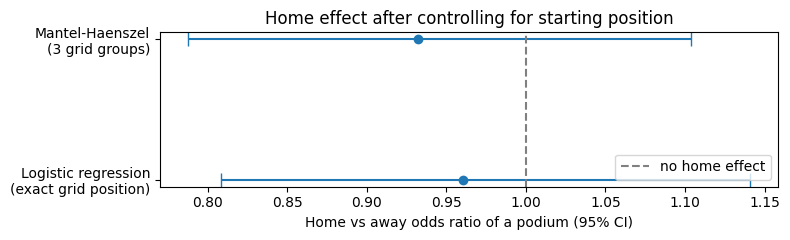

In [ ]:
# =========================
# 3.2.4 HOME EFFECT: STATISTICAL TEST, CONTROLLING FOR THE EXACT GRID POSITION
# =========================
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import StratifiedTable

q2_test_data = q2_analysis.assign(grid_position=q2_analysis["grid"].clip(upper=25).astype(int).astype(str))
home_logit = smf.logit("podium ~ home + grid_position", data=q2_test_data).fit(disp=0)

home_or = np.exp(home_logit.params["home"])
home_or_low, home_or_high = np.exp(home_logit.conf_int().loc["home"])
print(f"Logistic regression (controls for each grid position): home odds ratio = {home_or:.2f}, "
      f"95% CI {home_or_low:.2f}-{home_or_high:.2f}, p = {home_logit.pvalues['home']:.2f}")

# Cochran-Mantel-Haenszel: one 2x2 table (home/away x podium/no podium) per grid group
tables_by_group = [
    pd.crosstab(g["home"], g["podium"]).reindex(index=[1, 0], columns=[1, 0], fill_value=0).to_numpy()
    for _, g in q2_analysis.groupby("grid_group", observed=True)
]
cmh = StratifiedTable(tables_by_group)
cmh_low, cmh_high = cmh.oddsratio_pooled_confint()
print(f"Cochran-Mantel-Haenszel (3 grid groups): pooled odds ratio = {cmh.oddsratio_pooled:.2f}, "
      f"95% CI {cmh_low:.2f}-{cmh_high:.2f}, p = {cmh.test_null_odds().pvalue:.2f}")

# Plot: both odds ratios with their 95% intervals; 1 = no home effect
fig, ax = plt.subplots(figsize=(8, 2.5))
labels = ["Logistic regression\n(exact grid position)", "Mantel-Haenszel\n(3 grid groups)"]
ors = [home_or, cmh.oddsratio_pooled]
lows, highs = [home_or_low, cmh_low], [home_or_high, cmh_high]
ax.errorbar(ors, [0, 1], xerr=[np.subtract(ors, lows), np.subtract(highs, ors)], fmt="o", capsize=5)
ax.axvline(1, color="gray", ls="--", label="no home effect")
ax.set_yticks([0, 1])
ax.set_yticklabels(labels)
ax.set_xlabel("Home vs away odds ratio of a podium (95% CI)")
ax.set_title("Home effect after controlling for starting position")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Result.** Both tests confirm the answer of 3.2.3: **there is no measurable home advantage once the starting position is controlled for.**

| Test | Home vs away odds ratio | 95% CI | p-value |
|---|---|---|---|
| Logistic regression, exact grid position | 0.96 | 0.81–1.14 | 0.65 |
| Mantel–Haenszel, 3 grid groups | 0.93 | 0.79–1.10 | 0.42 |

- Both odds ratios are close to 1 and both intervals include 1, so the small differences in 3.2.3 are consistent with chance.
- The intervals also limit how big a hidden effect could be: at most about +14% higher odds of a podium at home, and possibly a small disadvantage.
- This is an association, not a causal claim: `home` is based on nationality, and drivers with a home race may differ in other ways (for example, local one-off entries in the early decades).

## 3.3 Constructor Mechanical-Retirement Rate

### 3.3.1 Analyzing Mechanical Retirement Rates by Constructor and Period


In [ ]:
# Select only the columns needed for the analysis
results_subset = results[
    ['raceId', 'driverId', 'constructorId', 'statusId']
]

races_subset = races[
    ['raceId', 'year']
]

constructors_subset = constructors[
    ['constructorId', 'name']
]

status_subset = status[
    ['statusId', 'status', 'retirement_type']
]

# Join all required tables
df = (
    results_subset
    .merge(races_subset, on='raceId', how='left')
    .merge(constructors_subset, on='constructorId', how='left')
    .merge(status_subset, on='statusId', how='left')
)

# Check the result
df.head()

,raceId,driverId,constructorId,statusId,year,name,status,retirement_type
0,18,1,1,1,2008,McLaren,Finished,Not retirement
1,18,2,2,1,2008,BMW Sauber,Finished,Not retirement
2,18,3,3,1,2008,Williams,Finished,Not retirement
3,18,4,4,1,2008,Renault,Finished,Not retirement
4,18,5,1,1,2008,McLaren,Finished,Not retirement


In [ ]:
# Keep only the required years
df_period = df[
    df['year'].between(2014, 2024)
].copy()

# Create the two comparison periods
df_period['period'] = df_period['year'].apply(
    lambda x: '2014-2021' if x <= 2021 else '2022-2024'
)

# Identify mechanical retirements using the existing retirement_type column
df_period['mechanical_retirement'] = (
    df_period['retirement_type'] == 'Mechanical'
)

# Statuses that definitely mean the driver did not start the race
non_start_statuses = [
    'Did not qualify',
    'Did not prequalify',
    '107% Rule',
    'Withdrew'
]

# Identify race starts
df_period['race_start'] = ~df_period['status'].isin(non_start_statuses)

df_period.head()

,raceId,driverId,constructorId,statusId,year,name,status,retirement_type,period,mechanical_retirement,race_start
20291,900,3,131,1,2014,Mercedes,Finished,Not retirement,2014-2021,False,True
20292,900,825,1,1,2014,McLaren,Finished,Not retirement,2014-2021,False,True
20293,900,18,1,1,2014,McLaren,Finished,Not retirement,2014-2021,False,True
20294,900,4,6,1,2014,Ferrari,Finished,Not retirement,2014-2021,False,True
20295,900,822,3,1,2014,Williams,Finished,Not retirement,2014-2021,False,True


In [ ]:
# Calculate race starts and mechanical retirements per constructor and period
comparison = (
    df_period
    .groupby(['name', 'period'])
    .agg(
        race_starts=('race_start', 'sum'),
        mechanical_retirements=('mechanical_retirement', 'sum')
    )
    .reset_index()
)

# Calculate mechanical-retirement rate
comparison['mechanical_retirement_rate'] = (
    comparison['mechanical_retirements']
    / comparison['race_starts']
    * 100
)

# Sort by period and highest rate
comparison = comparison.sort_values(
    ['period', 'mechanical_retirement_rate'],
    ascending=[True, False]
)

comparison

,name,period,race_starts,mechanical_retirements,mechanical_retirement_rate
8,Caterham,2014-2021,34,8,23.529
14,Lotus F1,2014-2021,75,15,20.000
28,Toro Rosso,2014-2021,242,40,16.529
25,Renault,2014-2021,200,30,15.000
17,McLaren,2014-2021,318,46,14.465
26,Sauber,2014-2021,200,23,11.500
23,Red Bull,2014-2021,319,36,11.285
22,Racing Point,2014-2021,76,8,10.526
2,AlphaTauri,2014-2021,78,8,10.256
16,Marussia,2014-2021,31,3,9.677


### 3.3.2 Result

In [ ]:
highest_by_period = comparison.loc[
    comparison.groupby('period')['mechanical_retirement_rate'].idxmax()
]

highest_by_period
highest_by_period[
    [
        'period',
        'name',
        'race_starts',
        'mechanical_retirements',
        'mechanical_retirement_rate'
    ]
]

,period,name,race_starts,mechanical_retirements,mechanical_retirement_rate
8,2014-2021,Caterham,34,8,23.529
1,2022-2024,Alfa Romeo,88,11,12.500


In [ ]:
comparison['rank'] = (
    comparison
    .groupby('period')['mechanical_retirement_rate']
    .rank(method='min', ascending=False)
)

top_constructors = (
    comparison[
        comparison['rank'] <= 5
    ]
    .sort_values(
        ['period', 'rank']
    )
)

top_constructors

,name,period,race_starts,mechanical_retirements,mechanical_retirement_rate,rank
8,Caterham,2014-2021,34,8,23.529,1.000
14,Lotus F1,2014-2021,75,15,20.000,2.000
28,Toro Rosso,2014-2021,242,40,16.529,3.000
25,Renault,2014-2021,200,30,15.000,4.000
17,McLaren,2014-2021,318,46,14.465,5.000
1,Alfa Romeo,2022-2024,88,11,12.500,1.000
5,Alpine F1 Team,2022-2024,136,15,11.029,2.000
3,AlphaTauri,2022-2024,88,7,7.955,3.000
10,Ferrari,2022-2024,136,9,6.618,4.000
30,Williams,2022-2024,134,8,5.970,5.000


**Answer.**

| Rank | 2014–2021 (turbo-hybrid) | 2022–2024 (ground effect) |
|---|---|---|
| 1 | Caterham 23.5% (8 of 34 starts) | Alfa Romeo 12.5% (11 of 88) |
| 2 | Lotus F1 20.0% (15 of 75) | Alpine 11.0% (15 of 136) |
| 3 | Toro Rosso 16.5% (40 of 242) | AlphaTauri 8.0% (7 of 88) |
| 4 | Renault 15.0% (30 of 200) | Ferrari 6.6% (9 of 136) |
| 5 | McLaren 14.5% (46 of 318) | Williams 6.0% (8 of 134) |

- **Highest rate:** Caterham in 2014–2021 and Alfa Romeo in 2022–2024.
- **Cars became more reliable:** across all teams, the mechanical-retirement rate fell from 10.2% of starts (331 of 3,258) in 2014–2021 to 6.1% (83 of 1,354) in 2022–2024. The worst team in the new era (12.5%) is about half the worst in the hybrid era (23.5%).
- **Small samples:** Caterham (34 starts) and Lotus F1 (75) raced only part of the 2014–2021 period, so their rates rest on fewer races and are less certain than those of teams with 200+ starts.
- **Team renames:** several teams changed name between the periods (Toro Rosso → AlphaTauri, Renault → Alpine, Sauber → Alfa Romeo). Each name is a separate `constructorId`, so a "change" between periods can be the same team under a new name.

**Grain:** one row per driver per race, 2014–2024. Rate = mechanical retirements ÷ race starts, per constructor and period.
**Missingness:** every status is mapped to a retirement type (2.5.7), so no row is left unclassified. Drivers who withdrew did not start, so they are excluded from the race-start count.
**Pre-race cutoff:** not applicable as a feature. This is a descriptive, post-race analysis, and `status` is used only here, never as a model input.

### 3.3.3 Visualization

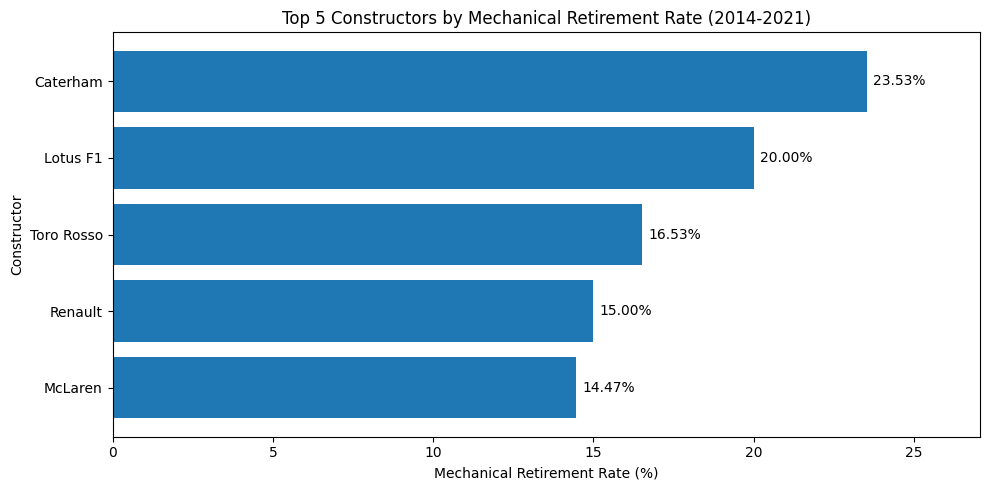

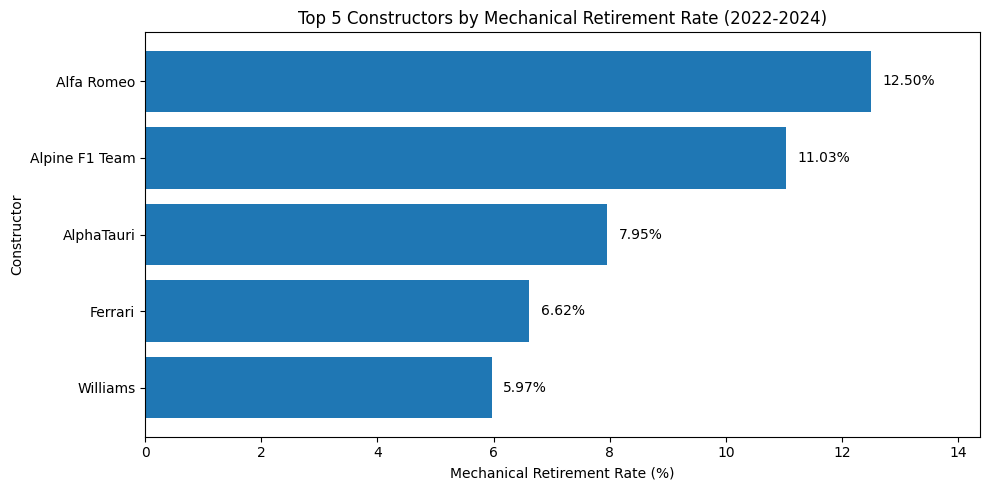

In [ ]:
# Get top 5 constructors for each period
top_5 = (
    comparison
    .groupby('period')
    .head(5)
)

# Plot each period separately
for period in ['2014-2021', '2022-2024']:

    period_data = (
        top_5[top_5['period'] == period]
        .sort_values('mechanical_retirement_rate', ascending=True)
    )

    plt.figure(figsize=(10, 5))

    bars = plt.barh(
        period_data['name'],
        period_data['mechanical_retirement_rate']
    )

    # Add percentage values to the bars
    for bar, rate in zip(
        bars,
        period_data['mechanical_retirement_rate']
    ):
        plt.text(
            bar.get_width() + 0.2,
            bar.get_y() + bar.get_height() / 2,
            f'{rate:.2f}%',
            va='center'
        )

    plt.title(
        f'Top 5 Constructors by Mechanical Retirement Rate ({period})'
    )
    plt.xlabel('Mechanical Retirement Rate (%)')
    plt.ylabel('Constructor')
    plt.xlim(
        0,
        period_data['mechanical_retirement_rate'].max() * 1.15
    )
    plt.tight_layout()
    plt.show()

### 3.3.4 Sensitivity Check of the Mechanical Mapping

The mechanical / non-mechanical grouping of the status values (2.5.7) is our own judgement, and some statuses are debatable, because the failure is not always a component of the car:
- **Tyre, Puncture, Tyre puncture:** often caused by debris or contact, not by the car.
- **Front wing, Rear wing, Broken wing, Undertray:** often damaged in contact or over kerbs.
- **Out of fuel:** a team fuel calculation, not a broken part.
- **Stalled:** often a driver error at a start or pit stop.
- **Wheel nut:** usually a pit-crew error.
- **Driver Seat, Seat:** not a performance component.

We recompute the rates with a **strict mapping** that moves all of these to non-mechanical, and check whether the answer (the constructors with the highest rate in each period) changes.

Debatable retirements moved to non-mechanical (2014-2024): 26 of 414 mechanical retirements

2014-2021: same top 5 under both mappings: True (5 of 5 shared)


,race_starts,mech_current,rate_current_%,rank_current,mech_strict,rate_strict_%,rank_strict
name,,,,,,,
Caterham,34,8,23.500,1,8,23.500,1
Lotus F1,75,15,20.000,2,13,17.300,2
Toro Rosso,242,40,16.500,3,39,16.100,3
Renault,200,30,15.000,4,28,14.000,5
McLaren,318,46,14.500,5,46,14.500,4



2022-2024: same top 5 under both mappings: True (5 of 5 shared)


,race_starts,mech_current,rate_current_%,rank_current,mech_strict,rate_strict_%,rank_strict
name,,,,,,,
Alfa Romeo,88,11,12.500,1,11,12.500,1
Alpine F1 Team,136,15,11.000,2,15,11.000,2
AlphaTauri,88,7,8.000,3,6,6.800,3
Ferrari,136,9,6.600,4,8,5.900,4
Williams,134,8,6.000,5,7,5.200,5



All teams, mechanical-retirement rate (% of starts):


,current mapping,strict mapping
period,,
2014-2021,10.200,9.500
2022-2024,6.100,5.700


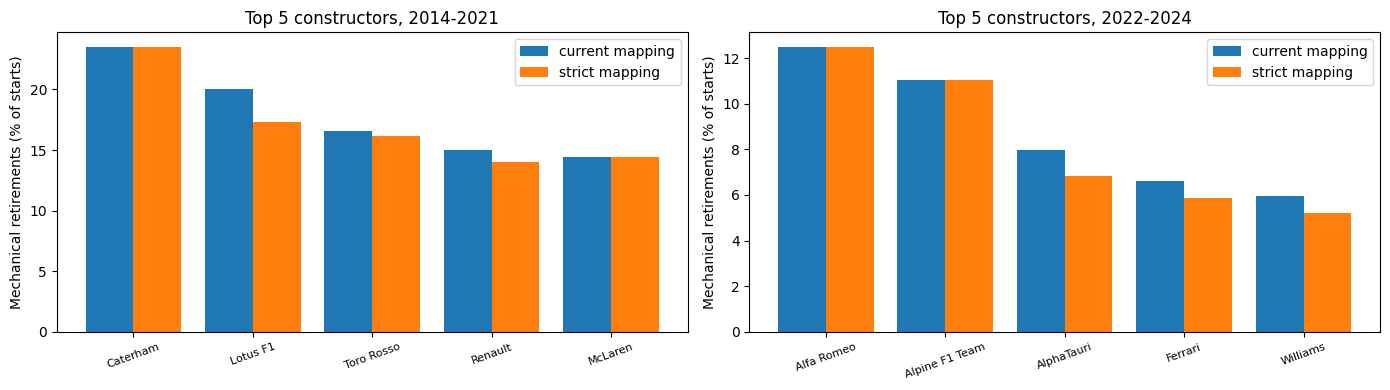

In [ ]:
# =========================
# 3.3.4 SENSITIVITY: STRICT MECHANICAL MAPPING
# =========================
debatable_statuses = [
    "Tyre", "Puncture", "Tyre puncture", "Front wing", "Rear wing", "Broken wing", "Undertray",
    "Out of fuel", "Stalled", "Wheel nut", "Driver Seat", "Seat",
]

sens = df_period.copy()
sens["mechanical_strict"] = sens["mechanical_retirement"] & ~sens["status"].isin(debatable_statuses)
print("Debatable retirements moved to non-mechanical (2014-2024):",
      int((sens["mechanical_retirement"] & ~sens["mechanical_strict"]).sum()),
      "of", int(sens["mechanical_retirement"].sum()), "mechanical retirements")

rates = (
    sens.groupby(["period", "name"])
    .agg(race_starts=("race_start", "sum"),
         mech_current=("mechanical_retirement", "sum"),
         mech_strict=("mechanical_strict", "sum"))
)
rates["rate_current_%"] = 100 * rates["mech_current"] / rates["race_starts"]
rates["rate_strict_%"] = 100 * rates["mech_strict"] / rates["race_starts"]
rates["rank_current"] = rates.groupby("period")["rate_current_%"].rank(method="min", ascending=False).astype(int)
rates["rank_strict"] = rates.groupby("period")["rate_strict_%"].rank(method="min", ascending=False).astype(int)

for period in ["2014-2021", "2022-2024"]:
    part = rates.loc[period]
    top_current = set(part.nsmallest(5, "rank_current").index)
    top_strict = set(part.nsmallest(5, "rank_strict").index)
    print(f"\n{period}: same top 5 under both mappings: {top_current == top_strict} "
          f"({len(top_current & top_strict)} of 5 shared)")
    display(part[part["rank_current"].le(5) | part["rank_strict"].le(5)]
            .sort_values("rank_current")[["race_starts", "mech_current", "rate_current_%", "rank_current",
                                          "mech_strict", "rate_strict_%", "rank_strict"]].round(1))

overall = sens.groupby("period")[["mechanical_retirement", "mechanical_strict", "race_start"]].sum()
print("\nAll teams, mechanical-retirement rate (% of starts):")
display(pd.DataFrame({
    "current mapping": 100 * overall["mechanical_retirement"] / overall["race_start"],
    "strict mapping": 100 * overall["mechanical_strict"] / overall["race_start"],
}).round(1))

# Plot: top-5 rates under both mappings, per period
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, period in zip(ax, ["2014-2021", "2022-2024"]):
    part = rates.loc[period].sort_values("rate_current_%", ascending=False).head(5)
    x = np.arange(len(part))
    a.bar(x - 0.2, part["rate_current_%"], width=0.4, label="current mapping")
    a.bar(x + 0.2, part["rate_strict_%"], width=0.4, label="strict mapping")
    a.set_xticks(x)
    a.set_xticklabels(part.index, rotation=20, fontsize=8)
    a.set_ylabel("Mechanical retirements (% of starts)")
    a.set_title(f"Top 5 constructors, {period}")
    a.legend()
plt.tight_layout()
plt.show()

**Result.** The answer to Question 3 **does not depend on the debatable statuses.**
- Only **26 of 414** mechanical retirements in 2014–2024 have a debatable status, so the strict mapping changes little.
- **The same five constructors are the top 5 in both periods under both mappings.** The leaders do not change (Caterham in 2014–2021, Alfa Romeo in 2022–2024). The only change in order is that McLaren and Renault swap 4th and 5th in 2014–2021.
- **The drop between the periods holds:** the rate across all teams falls from 10.2% to 6.1% of starts with the current mapping, and from 9.5% to 5.7% with the strict one.
- **Limitation:** `status` records only how a race *ended*. A car with a failure that still reaches the flag (e.g. Nico Rosberg's energy-recovery failure at the 2014 Abu Dhabi GP, finished 14th, status "+1 Lap") counts as a finisher, so both mappings slightly understate how often cars had mechanical problems.

# 4. Feature Selection


Every feature must be **known after qualifying and before the race starts**. We choose features by hypothesis (what decides an F1 result: starting position, car and driver form, championship situation) and check each choice with the evidence in 4.2. The feature-group ablation in section 6 then measures what each group actually adds to the model.

**Selected features**

| Group | Features | Source tables | Why it is known before the race |
|---|---|---|---|
| Race context | `year`, `round`, `circuitId`, `circuit_country` | races, circuits | Fixed by the calendar |
| Starting grid | `grid_numeric`, `front_row`, `non_standard_start` | results (grid) | The grid is set before the start |
| Qualifying | `qualifying_position` | qualifying | Qualifying happens before the race |
| Driver attributes | `driver_age`, `home`, `driver_nationality` | drivers, circuits | Date of birth and nationality are fixed |
| Driver form | `driver_starts_before`, `driver_podium_rate_before`, last-5 / last-10 podium rate and average finish | results (earlier races only) | Built only from earlier races (`shift(1)`) |
| Driver standings | `driver_points_before`, `driver_position_before`, `driver_wins_before` | driver_standings | Taken from the previous round |
| Constructor identity | `constructor_name`, `constructor_nationality` | constructors | The team is known when the car is entered |
| Constructor form | `constructor_races_before`, last-5 / last-10 podium rate and average finish | results (earlier races only) | Built only from earlier races (`shift(1)`) |
| Constructor standings | `constructor_points_before`, `constructor_position_before`, `constructor_wins_before` | constructor_standings | Taken from the previous round |

**Excluded**

| Columns | Reason |
|---|---|
| Current-race `position`, `positionText`, `positionOrder`, `points`, `laps`, `time`, `fastestLap…`, `rank`, `statusId` | Post-race results: leakage (`positionOrder` is only used to build the target) |
| `pit_stops`, `lap_times` | Happen during the race: leakage |
| `constructor_results` | Points scored in the current race: leakage |
| Standings **after** the current race | Leakage. Only the previous round's standings are used |
| `sprint_results` | Only exist from 2021 (missing for almost every row), and in 2021–22 the sprint already set the grid |
| Qualifying lap times `q1`–`q3` | `q2`/`q3` are largely missing and dropped (2.5.6). `q1` is 98.5% complete but raw lap times depend on the circuit, and it covers exactly the same races as the qualifying position, which is used instead |
| `grid_vs_qualifying`, `has_quali_data` | Built in 4.1 but removed in 4.3: almost always 0 / only a data-coverage flag, and removing them does not change the scores (6.1) |
| IDs (`resultId`, `driverId`, …), car `number`, race name, url | Identifiers, not information |

## 4.1 Modeling Table (Candidate Features)

All candidate features are built here, so that 4.2 can check them against the target and section 6 can test them by removing them.

In [ ]:
# BASE MODELING TABLE

model_df = results[
    [
        "raceId",
        "driverId",
        "constructorId",
        "grid",
        "grid_numeric",
        "non_standard_start",
        "front_row",
        "positionOrder",
        "podium"
    ]
].copy()

# Race information
model_df = model_df.merge(
    races[
        [
            "raceId",
            "year",
            "round",
            "circuitId",
            "date"
        ]
    ],
    on="raceId",
    how="left"
)

# Circuit information
model_df = model_df.merge(
    circuits[
        [
            "circuitId",
            "country"
        ]
    ].rename(
        columns={
            "country": "circuit_country"
        }
    ),
    on="circuitId",
    how="left"
)

# Driver information
model_df = model_df.merge(
    drivers[
        [
            "driverId",
            "dob",
            "nationality"
        ]
    ].rename(
        columns={
            "nationality": "driver_nationality"
        }
    ),
    on="driverId",
    how="left"
)

# Constructor information
model_df = model_df.merge(
    constructors[
        [
            "constructorId",
            "name",
            "nationality"
        ]
    ].rename(
        columns={
            "name": "constructor_name",
            "nationality": "constructor_nationality"
        }
    ),
    on="constructorId",
    how="left"
)

# Qualifying information
quali_feature = qualifying[
    [
        "raceId",
        "driverId",
        "position"
    ]
].rename(
    columns={
        "position": "qualifying_position"
    }
)

quali_feature["qualifying_position"] = pd.to_numeric(
    quali_feature["qualifying_position"],
    errors="coerce"
)

model_df = model_df.merge(
    quali_feature,
    on=["raceId", "driverId"],
    how="left"
)

# Date
model_df["date"] = pd.to_datetime(
    model_df["date"],
    errors="coerce"
)

# Driver age
model_df["driver_age"] = (
    model_df["date"] - model_df["dob"]
).dt.days / 365.25

# Grid vs qualifying
model_df["grid_vs_qualifying"] = (
    model_df["grid_numeric"]
    - model_df["qualifying_position"]
)

model_df = model_df.drop(
    columns=["dob"]
)

print(model_df.shape)
display(model_df.head())

(24921, 20)


,raceId,driverId,constructorId,grid,grid_numeric,non_standard_start,front_row,positionOrder,podium,year,round,circuitId,date,circuit_country,driver_nationality,constructor_name,constructor_nationality,qualifying_position,driver_age,grid_vs_qualifying
0,18,1,1,1,1,False,True,1,True,2008,1,1,2008-03-16,Australia,British,McLaren,British,1.000,23.187,0.000
1,18,2,2,5,5,False,False,2,True,2008,1,1,2008-03-16,Australia,German,BMW Sauber,German,5.000,30.850,0.000
2,18,3,3,7,7,False,False,3,True,2008,1,1,2008-03-16,Australia,German,Williams,British,7.000,22.719,0.000
3,18,4,4,11,11,False,False,4,False,2008,1,1,2008-03-16,Australia,Spanish,Renault,French,12.000,26.631,-1.000
4,18,5,1,3,3,False,False,5,False,2008,1,1,2008-03-16,Australia,Finnish,McLaren,British,3.000,26.407,0.000


In [ ]:
#  HOME-RACE FEATURE


# Same rule as Question 2: a driver is at home if the circuit country matches ANY country
# of their nationality (e.g. "American-Italian" is at home in both the USA and Italy)
home_pairs = set(zip(nationality_country["nationality"], nationality_country["country"]))

model_df["home"] = [
    int((nationality, country) in home_pairs)
    for nationality, country in zip(model_df["driver_nationality"], model_df["circuit_country"])
]

print("Home-race rows:", model_df["home"].sum(), "of", len(model_df))
display(model_df[["driver_nationality", "circuit_country", "home"]].head())


Home-race rows: 1975 of 24921


,driver_nationality,circuit_country,home
0,British,Australia,0
1,German,Australia,0
2,German,Australia,0
3,Spanish,Australia,0
4,Finnish,Australia,0


**Leakage-safe form features (only past races).** Form and standings features may only use races that happened **before** the race being predicted:

- **Driver form:** rows are sorted by race date, and every value is shifted one race back per driver (`shift(1)`), so the current race's result is never included. `driver_starts_before` counts earlier races; `driver_podium_rate_before` is the share of earlier races finished on the podium; the last-5 and last-10 features use only the previous 5 or 10 races.
- **Constructor form:** a team has two cars per race, so we first combine them into one value per team per race (e.g. Ferrari in Race 1: Leclerc 1st, Sainz 5th → podium rate 0.5, average finish 3), and only then shift one race back. Shifting row by row instead would give Sainz's Race 2 row Leclerc's Race 2 result, which is leakage from the race being predicted.
- **Standings:** championship points, position and wins are taken from the **previous round of the same season** (`shift(1)` within driver/constructor and year), because the standings table holds the totals *after* each race.
- **No history yet:** a driver's or team's first race has no earlier data, so the value is missing (NaN), not 0. The standings are missing for about 3,000 rows: 1,631 at the first race of a season (nobody has points yet), 963 at a driver's first race of the season (joining mid-season), and the rest where no earlier standings row exists. All of these are filled during preprocessing with the training median, plus a missing-indicator column so the model can tell a filled value from a real one.


In [ ]:
# DRIVER HISTORICAL FORM


model_df = model_df.sort_values(
    ["date", "raceId", "driverId"]
).reset_index(drop=True)

# Number of previous starts
model_df["driver_starts_before"] = (
    model_df.groupby("driverId")
    .cumcount()
)

# Career podium rate before race
model_df["driver_podium_rate_before"] = (
    model_df
    .groupby("driverId")["podium"]
    .transform(
        lambda x:
        x.shift(1)
         .expanding()
         .mean()
    )
)

# Last 5 races
model_df["driver_last5_podium_rate"] = (
    model_df
    .groupby("driverId")["podium"]
    .transform(
        lambda x:
        x.shift(1)
         .rolling(5, min_periods=1)
         .mean()
    )
)

model_df["driver_last5_avg_finish"] = (
    model_df
    .groupby("driverId")["positionOrder"]
    .transform(
        lambda x:
        x.shift(1)
         .rolling(5, min_periods=1)
         .mean()
    )
)

# Last 10 races
model_df["driver_last10_podium_rate"] = (
    model_df
    .groupby("driverId")["podium"]
    .transform(
        lambda x:
        x.shift(1)
         .rolling(10, min_periods=1)
         .mean()
    )
)

model_df["driver_last10_avg_finish"] = (
    model_df
    .groupby("driverId")["positionOrder"]
    .transform(
        lambda x:
        x.shift(1)
         .rolling(10, min_periods=1)
         .mean()
    )
)

In [ ]:
#  CONSTRUCTOR HISTORICAL FORM


constructor_race = (
    model_df
    .groupby(
        [
            "raceId",
            "date",
            "constructorId"
        ],
        as_index=False
    )
    .agg(
        constructor_race_podium_rate=("podium", "mean"),
        constructor_race_avg_finish=("positionOrder", "mean")
    )
)

constructor_race = constructor_race.sort_values(
    [
        "constructorId",
        "date",
        "raceId"
    ]
)

constructor_race["constructor_races_before"] = (
    constructor_race
    .groupby("constructorId")
    .cumcount()
)

constructor_race["constructor_last5_podium_rate"] = (
    constructor_race
    .groupby("constructorId")["constructor_race_podium_rate"]
    .transform(
        lambda x:
        x.shift(1)
         .rolling(5, min_periods=1)
         .mean()
    )
)

constructor_race["constructor_last5_avg_finish"] = (
    constructor_race
    .groupby("constructorId")["constructor_race_avg_finish"]
    .transform(
        lambda x:
        x.shift(1)
         .rolling(5, min_periods=1)
         .mean()
    )
)

constructor_race["constructor_last10_podium_rate"] = (
    constructor_race
    .groupby("constructorId")["constructor_race_podium_rate"]
    .transform(
        lambda x:
        x.shift(1)
         .rolling(10, min_periods=1)
         .mean()
    )
)

constructor_race["constructor_last10_avg_finish"] = (
    constructor_race
    .groupby("constructorId")["constructor_race_avg_finish"]
    .transform(
        lambda x:
        x.shift(1)
         .rolling(10, min_periods=1)
         .mean()
    )
)

constructor_history = constructor_race[
    [
        "raceId",
        "constructorId",
        "constructor_races_before",
        "constructor_last5_podium_rate",
        "constructor_last5_avg_finish",
        "constructor_last10_podium_rate",
        "constructor_last10_avg_finish"
    ]
]

model_df = model_df.merge(
    constructor_history,
    on=["raceId", "constructorId"],
    how="left"
)

In [ ]:
#  PRE-RACE STANDINGS


# Driver standings
driver_stand = (
    driver_standings
    .merge(
        races[
            [
                "raceId",
                "year",
                "round"
            ]
        ],
        on="raceId",
        how="left"
    )
    .sort_values(
        [
            "driverId",
            "year",
            "round"
        ]
    )
)

for col in ["points", "position", "wins"]:
    driver_stand[f"driver_{col}_before"] = (
        driver_stand
        .groupby(
            ["driverId", "year"]
        )[col]
        .shift(1)
    )

model_df = model_df.merge(
    driver_stand[
        [
            "raceId",
            "driverId",
            "driver_points_before",
            "driver_position_before",
            "driver_wins_before"
        ]
    ],
    on=["raceId", "driverId"],
    how="left"
)


# Constructor standings
constructor_stand = (
    constructor_standings
    .merge(
        races[
            [
                "raceId",
                "year",
                "round"
            ]
        ],
        on="raceId",
        how="left"
    )
    .sort_values(
        [
            "constructorId",
            "year",
            "round"
        ]
    )
)

for col in ["points", "position", "wins"]:
    constructor_stand[f"constructor_{col}_before"] = (
        constructor_stand
        .groupby(
            ["constructorId", "year"]
        )[col]
        .shift(1)
    )

model_df = model_df.merge(
    constructor_stand[
        [
            "raceId",
            "constructorId",
            "constructor_points_before",
            "constructor_position_before",
            "constructor_wins_before"
        ]
    ],
    on=["raceId", "constructorId"],
    how="left"
)

**Leakage check: are the form and standings features really built from earlier races only?** We do not just rely on `shift(1)`: for 500 random rows we recompute the features **from scratch**, using only the results and standings of races held *before* that row's race, and compare them with the values in the modeling table. Any mismatch would mean the current race (or a later one) leaked in.

In [ ]:
# =========================
# LEAKAGE CHECK: recompute form and standings features from earlier races only, for 500 random rows
# =========================
history = results[["raceId", "driverId", "constructorId", "positionOrder"]].merge(races[["raceId", "date", "year", "round"]], on="raceId")
history["podium"] = (history["positionOrder"] <= 3).astype(float)
team_race = history.groupby(["constructorId", "raceId", "date"], as_index=False)["podium"].mean()
stand = driver_standings.merge(races[["raceId", "year", "round"]], on="raceId")

check = model_df.sample(500, random_state=RANDOM_STATE)
checks = {"driver_starts_before": 0, "driver_last5_podium_rate": 0, "constructor_last5_podium_rate": 0, "driver_points_before": 0}


def same(a, b):
    return (pd.isna(a) and pd.isna(b)) or (not pd.isna(a) and not pd.isna(b) and abs(a - b) < 1e-9)


for _, row in check.iterrows():
    past = history[(history["driverId"] == row["driverId"]) & (history["date"] < row["date"])].sort_values("date")
    checks["driver_starts_before"] += same(len(past), row["driver_starts_before"])
    checks["driver_last5_podium_rate"] += same(past["podium"].tail(5).mean() if len(past) else np.nan, row["driver_last5_podium_rate"])

    team_past = team_race[(team_race["constructorId"] == row["constructorId"]) & (team_race["date"] < row["date"])].sort_values("date")
    checks["constructor_last5_podium_rate"] += same(team_past["podium"].tail(5).mean() if len(team_past) else np.nan,
                                                    row["constructor_last5_podium_rate"])

    earlier = stand[(stand["driverId"] == row["driverId"]) & (stand["year"] == row["year"]) & (stand["round"] < row["round"])]
    checks["driver_points_before"] += same(earlier.sort_values("round")["points"].iloc[-1] if len(earlier) else np.nan,
                                           row["driver_points_before"])

leak_check = pd.Series(checks, name="rows matching the from-scratch value (of 500)")
display(leak_check.to_frame())
assert (leak_check == 500).all(), "a form or standings feature does not match its earlier-races-only value"

# First race of each driver: no history may exist
first_races = model_df.groupby("driverId").head(1)
print("Driver's first race: driver_starts_before == 0 for all:", bool((first_races["driver_starts_before"] == 0).all()),
      "| recent podium rate missing for all:", bool(first_races["driver_last5_podium_rate"].isna().all()))

,rows matching the from-scratch value (of 500)
driver_starts_before,500
driver_last5_podium_rate,500
constructor_last5_podium_rate,500
driver_points_before,500


Driver's first race: driver_starts_before == 0 for all: True | recent podium rate missing for all: True


**Result.** All four features match their from-scratch, earlier-races-only values on all 500 random rows, and every driver's first race has no history (0 starts, missing form). The form and standings features therefore contain no information from the race being predicted or from any later race.

In [ ]:
## Handling missing qualifying data

#**Problem.** `qualifying_position` is missing for most rows (about 58%, printed below): qualifying records only exist from 1994 (2.5.6), so for earlier races the starting grid is the only record of the starting order.

#**Decision.** Fill the missing qualifying position with the starting grid (`grid_numeric`) and add a flag, `has_quali_data`.


# Snapshot before the fill (for the before/after comparison)
before = model_df[["qualifying_position", "grid_vs_qualifying"]].describe().round(2)

# 1) Flag rows with a real qualifying record (must run BEFORE the fill)
#**`has_quali_data`**: 1 if the row has a real qualifying record, 0 if the qualifying position was filled with the starting grid.
# It lets the model tell real "no penalty" cases from filled zeros in `grid_vs_qualifying`

model_df["has_quali_data"] = model_df["qualifying_position"].notna().astype(int)

# 2) Fill missing qualifying position with the starting grid
model_df["qualifying_position"] = model_df["qualifying_position"].fillna(model_df["grid_numeric"])

# 3) Recompute the grid-vs-qualifying shift (becomes 0 on filled rows)
model_df["grid_vs_qualifying"] = model_df["grid_numeric"] - model_df["qualifying_position"]

# Checks
assert model_df["qualifying_position"].isna().sum() == 0
assert model_df["grid_vs_qualifying"].isna().sum() == 0
assert (model_df.loc[model_df["has_quali_data"] == 0, "grid_vs_qualifying"] == 0).all()

print("Real qualifying rows:", model_df["has_quali_data"].sum())
print("Filled rows:", (model_df["has_quali_data"] == 0).sum())

# Evidence that grid is a good stand-in: how often grid == real qualifying position
real = model_df[model_df["has_quali_data"] == 1]
print("Share of real rows where grid == qualifying position:",
      round((real["grid_numeric"] == real["qualifying_position"]).mean(), 3))

after = model_df[["qualifying_position", "grid_vs_qualifying"]].describe().round(2)
display(before, after)

Real qualifying rows: 10486
Filled rows: 14435
Share of real rows where grid == qualifying position: 0.763


,qualifying_position,grid_vs_qualifying
count,10486.000,10486.000
mean,11.190,0.010
std,6.250,1.560
min,1.000,-9.000
25%,6.000,0.000
50%,11.000,0.000
75%,16.000,0.000
max,26.000,23.000


,qualifying_position,grid_vs_qualifying
count,24921.000,24921.000
mean,11.900,0.010
std,6.800,1.010
min,1.000,-9.000
25%,6.000,0.000
50%,12.000,0.000
75%,17.000,0.000
max,34.000,23.000


In [ ]:
#  FINAL MODELING TABLE


# Current-race outcome helper no longer allowed as feature
model_df = model_df.drop(
    columns=[
        "positionOrder",
        "grid"
    ]
)

# Final grain check
assert (
    model_df
    .duplicated(["raceId", "driverId"])
    .sum()
    == 0
)

print("Final shape:", model_df.shape)

display(model_df.head())

print(model_df.columns.tolist())

Final shape: (24921, 37)


,raceId,driverId,constructorId,grid_numeric,non_standard_start,front_row,podium,year,round,circuitId,date,circuit_country,driver_nationality,constructor_name,constructor_nationality,qualifying_position,driver_age,grid_vs_qualifying,home,driver_starts_before,driver_podium_rate_before,driver_last5_podium_rate,driver_last5_avg_finish,driver_last10_podium_rate,driver_last10_avg_finish,constructor_races_before,constructor_last5_podium_rate,constructor_last5_avg_finish,constructor_last10_podium_rate,constructor_last10_avg_finish,driver_points_before,driver_position_before,driver_wins_before,constructor_points_before,constructor_position_before,constructor_wins_before,has_quali_data
0,833,579,51,3,False,False,False,1950,1,9,1950-05-13,UK,Argentine,Alfa Romeo,Swiss,3.000,38.886,0.000,0,0,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,<NA>,NaN,0
1,833,589,105,11,False,False,False,1950,1,9,1950-05-13,UK,Monegasque,Maserati,Italian,11.000,50.773,0.000,0,0,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,<NA>,NaN,0
2,833,619,151,13,False,False,False,1950,1,9,1950-05-13,UK,British,ERA,British,13.000,36.312,0.000,1,0,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,<NA>,NaN,0
3,833,627,154,9,False,False,False,1950,1,9,1950-05-13,UK,French,Talbot-Lago,French,9.000,44.517,0.000,0,0,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,<NA>,NaN,0
4,833,640,105,8,False,False,False,1950,1,9,1950-05-13,UK,Swiss,Maserati,Italian,8.000,35.986,0.000,0,0,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,<NA>,NaN,0


['raceId', 'driverId', 'constructorId', 'grid_numeric', 'non_standard_start', 'front_row', 'podium', 'year', 'round', 'circuitId', 'date', 'circuit_country', 'driver_nationality', 'constructor_name', 'constructor_nationality', 'qualifying_position', 'driver_age', 'grid_vs_qualifying', 'home', 'driver_starts_before', 'driver_podium_rate_before', 'driver_last5_podium_rate', 'driver_last5_avg_finish', 'driver_last10_podium_rate', 'driver_last10_avg_finish', 'constructor_races_before', 'constructor_last5_podium_rate', 'constructor_last5_avg_finish', 'constructor_last10_podium_rate', 'constructor_last10_avg_finish', 'driver_points_before', 'driver_position_before', 'driver_wins_before', 'constructor_points_before', 'constructor_position_before', 'constructor_wins_before', 'has_quali_data']


In [ ]:
categorical_features = [
    "driver_nationality",
    "constructor_name",
    "constructor_nationality",
    "circuit_country",
    "circuitId"
]

numeric_features = [
    "year",
    "round",

    "grid_numeric",
    "non_standard_start",
    "front_row",

    "qualifying_position",
    "grid_vs_qualifying",
    "has_quali_data",

    "driver_age",
    "home",

    "driver_starts_before",
    "driver_podium_rate_before",
    "driver_last5_podium_rate",
    "driver_last5_avg_finish",
    "driver_last10_podium_rate",
    "driver_last10_avg_finish",

    "constructor_races_before",
    "constructor_last5_podium_rate",
    "constructor_last5_avg_finish",
    "constructor_last10_podium_rate",
    "constructor_last10_avg_finish",

    "driver_points_before",
    "driver_position_before",
    "driver_wins_before",

    "constructor_points_before",
    "constructor_position_before",
    "constructor_wins_before"
]

## 4.2 Feature Evidence

We check each feature against the target before training: a correlation map of all numeric features (with each other and with `podium`), their correlation with `podium`, and the podium rate across each key feature's range. Spearman correlation is used because it works on ranks, so it fits positions, counts and 0/1 flags.

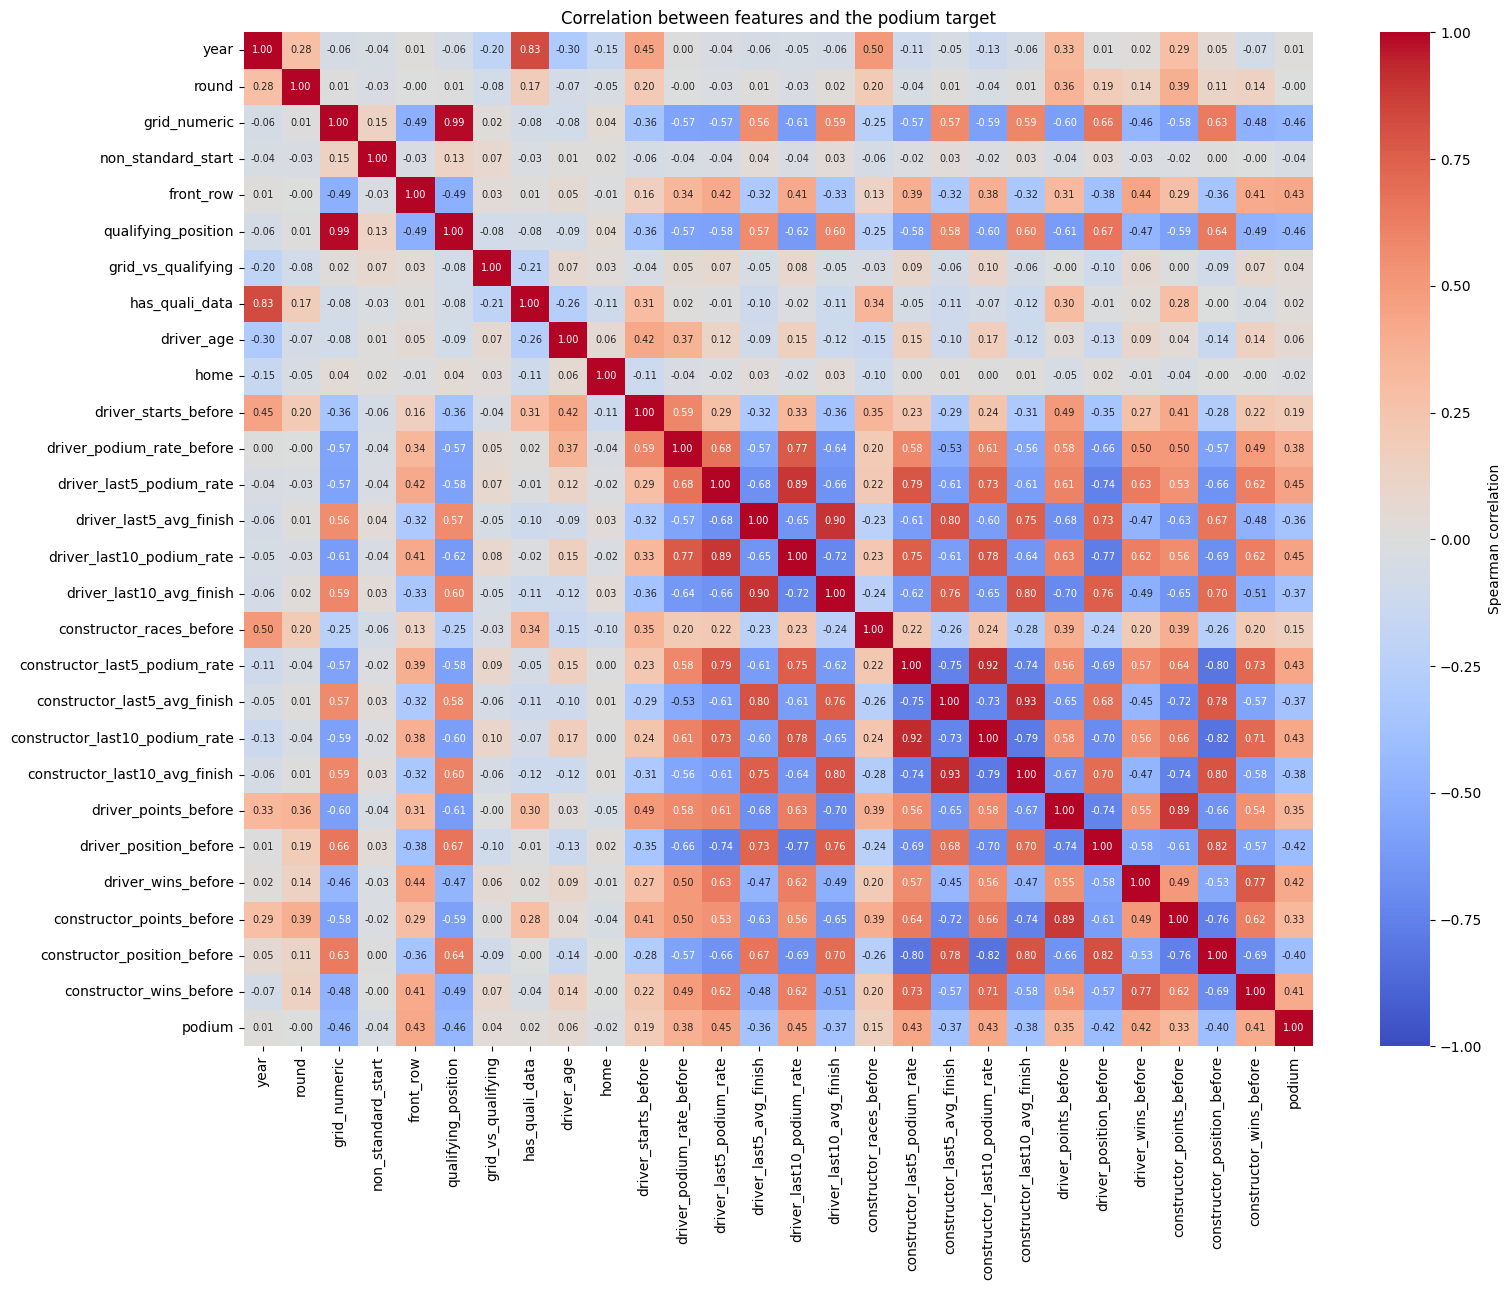

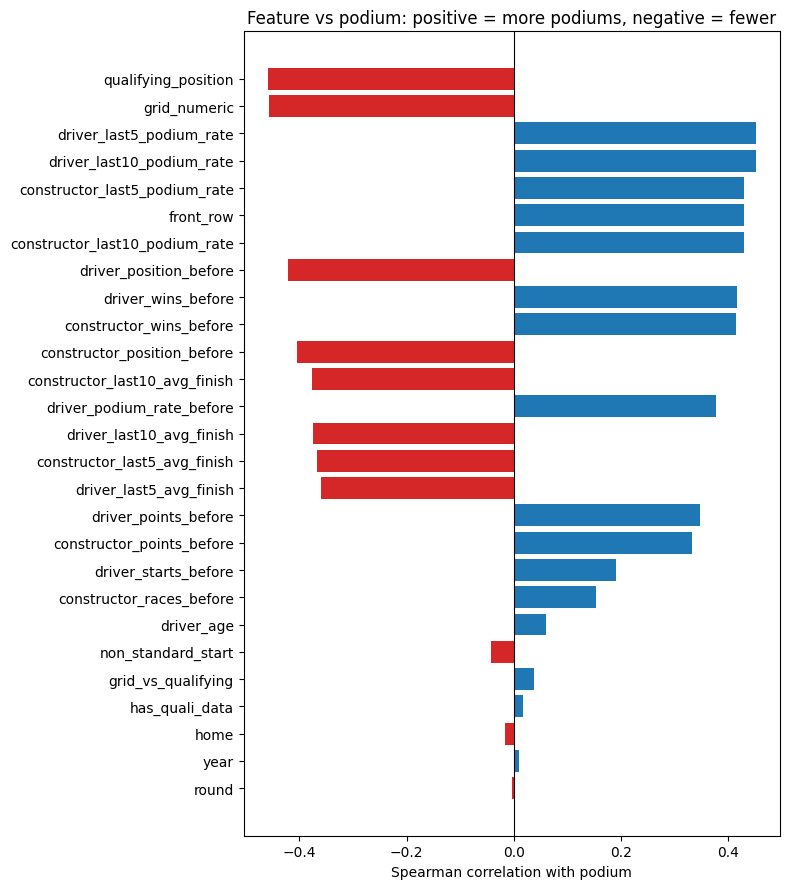

Features with |Spearman| < 0.05 with the podium (weak on their own):


,Spearman with podium
round,-0.004
year,0.010
home,-0.016
has_quali_data,0.017
grid_vs_qualifying,0.037
non_standard_start,-0.043


,level_0,level_1,spearman
0,grid_numeric,qualifying_position,0.990
1,constructor_last10_avg_finish,constructor_last5_avg_finish,0.930
2,constructor_last10_podium_rate,constructor_last5_podium_rate,0.920
3,driver_last10_avg_finish,driver_last5_avg_finish,0.900
4,driver_last10_podium_rate,driver_last5_podium_rate,0.890
5,constructor_points_before,driver_points_before,0.890


In [ ]:
# Spearman correlation between every numeric feature and the target (rank-based: works for counts, ranks and 0/1 flags)
evidence = model_df[numeric_features + ["podium"]].astype(float)
corr = evidence.corr(method="spearman")

plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 7}, cbar_kws={"label": "Spearman correlation"})
plt.title("Correlation between features and the podium target")
plt.tight_layout()
plt.show()

# Correlation of each feature with the target, strongest first
target_corr = corr["podium"].drop("podium").sort_values(key=abs)
plt.figure(figsize=(8, 9))
plt.barh(target_corr.index, target_corr.values,
         color=["tab:blue" if v > 0 else "tab:red" for v in target_corr.values])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Spearman correlation with podium")
plt.title("Feature vs podium: positive = more podiums, negative = fewer")
plt.tight_layout()
plt.show()

# The weakest features on their own: |Spearman| < 0.05 with the podium. Tested by removing them in 6.1.
WEAK_THRESHOLD = 0.05
weak_table = target_corr[target_corr.abs() < WEAK_THRESHOLD].sort_values(key=abs).round(3).to_frame("Spearman with podium")
print(f"Features with |Spearman| < {WEAK_THRESHOLD} with the podium (weak on their own):")
display(weak_table)

# Feature pairs that carry almost the same information (|correlation| >= 0.85)
pairs = corr.drop(index="podium", columns="podium").stack()
pairs = pairs[pairs.index.get_level_values(0) < pairs.index.get_level_values(1)]
display(pairs[pairs.abs() >= 0.85].sort_values(key=abs, ascending=False)
        .rename("spearman").reset_index().round(2))

**What the correlations show.**
- **Starting position is the strongest signal:** `qualifying_position` and `grid_numeric` (about −0.46: further back means fewer podiums) and `front_row` (+0.43).
- **Form and standings come next** (about 0.33–0.45): recent driver and constructor podium rates, average finishes, and championship position, wins and points before the race.
- **Experience is weaker** (`driver_starts_before`, `constructor_races_before`, about 0.15–0.19), and `driver_age`, `home`, `year`, `round`, `grid_vs_qualifying`, `has_quali_data` and `non_standard_start` are close to zero on their own. Their exact values are in the table above; `grid_vs_qualifying` and `has_quali_data` are removed in 4.3, and 6.1 tests all of them by retraining the models.
- **Redundant pairs:** `grid_numeric` and `qualifying_position` are almost identical (0.99), because qualifying is filled with the grid for pre-1994 races. Last-5 and last-10 form (0.89–0.93) and driver and constructor points (0.89) also overlap. We keep both of each pair: they describe short-term vs longer-term form, the tree models are not hurt by overlapping features, and logistic regression is regularised. The ablation in section 6 shows whether a group adds anything.
- **No sign of leakage:** no feature is close to ±1 with `podium`, which a post-race column would be.

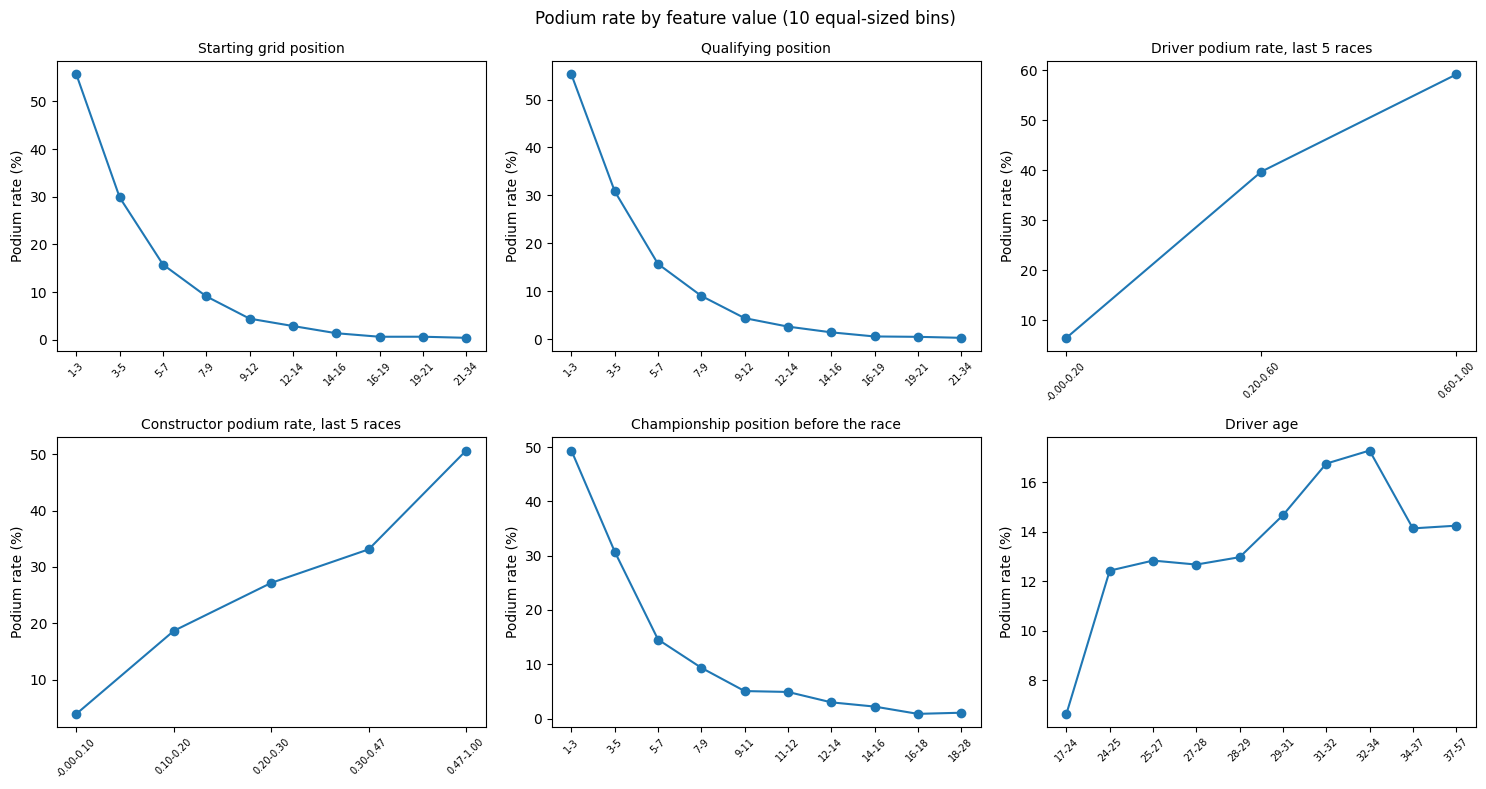

,podium % when 0,podium % when 1
front_row,8.900,60.300
non_standard_start,13.600,0.000
home,13.600,11.600
has_quali_data,13.000,14.100


In [ ]:
# Podium rate across the range of the key features (each feature split into equal-sized bins)
key_features = {
    "grid_numeric": "Starting grid position",
    "qualifying_position": "Qualifying position",
    "driver_last5_podium_rate": "Driver podium rate, last 5 races",
    "constructor_last5_podium_rate": "Constructor podium rate, last 5 races",
    "driver_position_before": "Championship position before the race",
    "driver_age": "Driver age",
}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (feature, label) in zip(axes.ravel(), key_features.items()):
    bins = pd.qcut(model_df[feature].astype(float), q=10, duplicates="drop")
    rate = model_df.groupby(bins, observed=True)["podium"].mean() * 100
    ax.plot(range(len(rate)), rate.values, marker="o")
    ax.set_xticks(range(len(rate)))
    ax.set_xticklabels([f"{b.left:.0f}-{b.right:.0f}" if b.right > 1 else f"{b.left:.2f}-{b.right:.2f}"
                        for b in rate.index], rotation=45, fontsize=7)
    ax.set_title(label, fontsize=10)
    ax.set_ylabel("Podium rate (%)")
plt.suptitle("Podium rate by feature value (10 equal-sized bins)")
plt.tight_layout()
plt.show()

# Binary features: podium rate when the flag is 0 vs 1
binary = ["front_row", "non_standard_start", "home", "has_quali_data"]
display(pd.DataFrame({f: model_df.groupby(f)["podium"].mean().mul(100).round(1) for f in binary}).T
        .rename(columns={0: "podium % when 0", 1: "podium % when 1"}))

**What the podium-rate plots show.**
- **Grid:** the podium rate falls steadily from about 56% for the front tenth of the grid to under 1% at the back. Starting on the **front row** gives 60.3% podiums, against 8.9% for everyone else.
- **Form:** drivers with no podium in their last 5 races podium 6.5% of the time, against about 59% for drivers in the top band.
- **Pit-lane starts and non-starters** (`non_standard_start`) never reach the podium in the data.
- **Weak features:** `driver_age` has a small, non-linear effect (podium rate rises with experience, then flattens). `home` alone shows 11.6% vs 13.6%, but home drivers also start further back on average; Question 2 compares them at similar grid positions. `home` is weak on its own; its real contribution is tested in 6.1 and in the ablation.

## 4.3 Final Feature Set

Two features built in 4.1 are **removed** before training:
- **`grid_vs_qualifying`** (grid position minus qualifying position). It is 0 for about 90% of rows: for every race before 1994 (qualifying is filled with the grid, 2.5.6) and for most later drivers, who start where they qualified. Its correlation with the podium is only 0.037, and both of its parts, `grid_numeric` and `qualifying_position`, are already features, so the tree models can find a grid penalty from them directly.
- **`has_quali_data`** (1 if a real qualifying record exists). It only says whether the qualifying table covers that season (1994 onwards), which is a property of the dataset, not of the race. Its correlation with the podium is 0.017, and the podium rate is almost the same with and without a record (see the binary table in 4.2).

Section 6.1 tests this decision: putting the two features back changes the validation PR-AUC by less than 0.003 for both XGBoost and logistic regression. Both columns are dropped from the modeling table. A side copy (`removed_cols`) is kept only for the two experiments that test this decision (experiment 3 in 5.5 and test A in 6.1); no model uses it.

In [ ]:
# =========================
# 4.3 FINAL FEATURE SET: remove the two qualifying-derived features (tested in 6.1)
# =========================
removed_features = ["grid_vs_qualifying", "has_quali_data"]

print("Spearman with podium:", target_corr.loc[removed_features].round(3).to_dict())
print(f"Rows where grid_vs_qualifying == 0: {(model_df['grid_vs_qualifying'] == 0).mean():.1%}")
print("Podium rate (%) by has_quali_data:", model_df.groupby("has_quali_data")["podium"].mean().mul(100).round(1).to_dict())

numeric_features = [f for f in numeric_features if f not in removed_features]

# Drop them from the modeling table. A side copy is kept ONLY for the two experiments that test this decision
# (experiment 3 in 5.5 and test A in 6.1); no model uses it.
removed_cols = model_df[removed_features].copy()
model_df = model_df.drop(columns=removed_features)
print("Modeling table after the drop:", model_df.shape, "| removed columns still present:",
      [f for f in removed_features if f in model_df.columns])
print(f"\nFeatures used by every model from here on: {len(numeric_features) + len(categorical_features)} "
      f"({len(numeric_features)} numeric, {len(categorical_features)} categorical)")

Spearman with podium: {'grid_vs_qualifying': 0.037, 'has_quali_data': 0.017}
Rows where grid_vs_qualifying == 0: 90.0%
Podium rate (%) by has_quali_data: {0: 13.0, 1: 14.1}
Modeling table after the drop: (24921, 35) | removed columns still present: []

Features used by every model from here on: 30 (25 numeric, 5 categorical)


In [ ]:
model_df[numeric_features + categorical_features + ["podium"]].tail(5)


,year,round,grid_numeric,non_standard_start,front_row,qualifying_position,driver_age,home,driver_starts_before,driver_podium_rate_before,driver_last5_podium_rate,driver_last5_avg_finish,driver_last10_podium_rate,driver_last10_avg_finish,constructor_races_before,constructor_last5_podium_rate,constructor_last5_avg_finish,constructor_last10_podium_rate,constructor_last10_avg_finish,driver_points_before,driver_position_before,driver_wins_before,constructor_points_before,constructor_position_before,constructor_wins_before,driver_nationality,constructor_name,constructor_nationality,circuit_country,circuitId,podium
24916,2024,24,15,False,False,17.000,25.528,0,67,0.000,0.000,14.000,0.000,15.600,418,0.000,14.300,0.000,15.550,4.000,20,0.000,4.000,10,0.000,Chinese,Sauber,Swiss,UAE,24,False
24917,2024,24,2,False,True,2.000,23.674,0,45,0.222,0.200,6.200,0.500,4.300,927,0.200,5.900,0.450,4.250,291.000,4,2.000,640.000,1,5.000,Australian,McLaren,British,UAE,24,False
24918,2024,24,12,False,False,12.000,22.823,0,10,0.000,0.000,12.800,0.000,12.500,23,0.000,12.700,0.000,13.900,4.000,20,0.000,46.000,8,0.000,New Zealander,RB F1 Team,Italian,UAE,24,False
24919,2024,24,20,False,False,19.000,21.536,0,8,0.000,0.000,14.400,0.000,12.875,840,0.000,15.900,0.000,14.250,5.000,19,0.000,17.000,9,0.000,Argentinian,Williams,British,UAE,24,False
24920,2024,24,17,False,False,20.000,21.884,0,0,NaN,NaN,NaN,NaN,NaN,89,0.200,12.000,0.100,12.600,NaN,<NA>,NaN,59.000,6,0.000,Australian,Alpine F1 Team,French,UAE,24,False


# 5. Model Training


## 5.1 Split, Preprocessing and Evaluation Helpers


**What this cell does.**
- **Split:** races are shuffled (seed 42) and divided 70% / 15% / 15% into train, validation and test **by race**, so all drivers of one race are always in the same set. Otherwise the model could learn from some drivers of a race and be tested on the others.
- **Why a random split across all years:** the shape of the data changes a lot through the years and eras: field sizes (30+ cars in the 1950s–80s, about 20 today), reliability (far more retirements in early decades), points systems, and qualifying coverage (only from 1994). We want the model to learn from **every era** and to be evaluated on every era. A year-based split (e.g. train up to 2019, test 2022–2024) would train mostly on old eras and test only on the most recent one, so the test score would mix model quality with era change. We still run that split too, as a second version, in 5.4.1, and compare the two. With the random split, each set covers 1950–2024 and has the same podium rate (shown in the table this cell prints).
- **What this split does not measure:** how well the model predicts *future* seasons. Form features also use earlier races that may sit in another set. They only look backwards in time, so the result of the race being predicted is never used. Both points are listed in the limitations (section 8).
- **Preprocessing**, fitted on the **training set only** and then applied to validation and test:
  - numeric features: median imputation plus a missing-indicator column for each feature with gaps, then standardisation (mean 0, standard deviation 1)
  - categorical features: a "missing" category, then one-hot encoding (categories never seen in training are ignored)
- **Evaluation helpers:** `best_threshold()` picks the probability cut-off that maximises F1 on validation, and `evaluate()` reports the five metrics on train, validation and test.

In [ ]:
# =========================
# 5.1 SPLIT, PREPROCESSING AND EVALUATION HELPERS
# =========================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
    precision_recall_curve
)

SEED = 42



model_features = numeric_features + categorical_features

X_all = model_df[model_features].copy()
X_all[numeric_features] = X_all[numeric_features].astype(float)
X_all[categorical_features] = X_all[categorical_features].astype(str)
y_all = model_df["podium"].astype(int)

# Random split across ALL years (70 / 15 / 15), done by RACE so that
# all drivers of one race stay together in the same set
race_ids = model_df["raceId"].unique()
rng = np.random.RandomState(SEED)
rng.shuffle(race_ids)

n_races = len(race_ids)
train_races = race_ids[: int(0.70 * n_races)]
val_races   = race_ids[int(0.70 * n_races): int(0.85 * n_races)]
test_races  = race_ids[int(0.85 * n_races):]

train_mask = model_df["raceId"].isin(train_races)
val_mask   = model_df["raceId"].isin(val_races)
test_mask  = model_df["raceId"].isin(test_races)

X_train, y_train = X_all[train_mask], y_all[train_mask]
X_val,   y_val   = X_all[val_mask],   y_all[val_mask]
X_test,  y_test  = X_all[test_mask],  y_all[test_mask]

display(pd.DataFrame({
    "races":       [len(train_races), len(val_races), len(test_races)],
    "rows":        [len(y_train), len(y_val), len(y_test)],
    "podium_rate": [y_train.mean().round(3), y_val.mean().round(3), y_test.mean().round(3)],
    "first_year":  [model_df.loc[m, "year"].min() for m in (train_mask, val_mask, test_mask)],
    "last_year":   [model_df.loc[m, "year"].max() for m in (train_mask, val_mask, test_mask)],
}, index=["train (70%)", "validation (15%)", "test (15%)"]))

# Preprocessing for ALL models (fitted on TRAIN only):
#   numeric     -> median imputation (+ missing flags), then standardisation
#   categorical -> fill missing with "missing", then one-hot encoding
numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median", add_indicator=True)),
    ("scale", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

prep = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features),
]).fit(X_train)

Xtr_s, Xva_s, Xte_s = (prep.transform(X) for X in (X_train, X_val, X_test))
print("Encoded feature matrix:", Xtr_s.shape)


# ---- evaluation helpers ----
def best_threshold(y_true, p):
    """Probability threshold that maximises F1 -- called with VALIDATION data only."""
    prec, rec, thr = precision_recall_curve(y_true, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return float(thr[np.argmax(f1)])


def evaluate(name, p_train, p_val, p_test):
    """ROC-AUC, PR-AUC, F1, precision and recall on train / val / test. Threshold chosen on validation."""
    thr = best_threshold(y_val, p_val)
    rows = []
    for split, y, p in [("train", y_train, p_train), ("val", y_val, p_val), ("test", y_test, p_test)]:
        rows.append({
            "model": name, "split": split,
            "ROC-AUC": roc_auc_score(y, p),
            "PR-AUC": average_precision_score(y, p),
            "F1": f1_score(y, p >= thr),
            "Precision": precision_score(y, p >= thr, zero_division=0),
            "Recall": recall_score(y, p >= thr),
            "threshold": thr,
        })
    return pd.DataFrame(rows)


eval_results = []   # one DataFrame per model
probs = {}     # model name -> predicted probabilities on train / val / test

,races,rows,podium_rate,first_year,last_year
train (70%),779,17427,0.135,1950,2024
validation (15%),167,3694,0.137,1950,2024
test (15%),168,3800,0.133,1950,2024


Encoded feature matrix: (17427, 380)


**Evaluation metrics and why PR-AUC is the primary metric.** Every model is scored with five metrics on train, validation and test:

| Metric | What it tells us | Role |
|---|---|---|
| **PR-AUC** | How well the model ranks podium finishers above everyone else, focusing on the podium class | **Primary** |
| **ROC-AUC** | How well the model separates podium from non-podium overall | **Secondary** |
| F1 | Balance of precision and recall at one probability threshold | Decision-level |
| Precision | Of the drivers predicted to podium, how many did | Decision-level |
| Recall | Of the drivers who podiumed, how many we predicted | Decision-level |

**Why PR-AUC is primary.** Podiums are rare: only about 13% of rows are podiums (3 per race, in fields of 20 to 30+ cars). ROC-AUC also rewards correctly ranking the many easy non-podium cases (cars starting at the back), so it can look high even when the model is weak at picking the actual podium finishers. PR-AUC only looks at how precise the model is while it finds the podium finishers, which is the question we care about. A model with no skill scores a PR-AUC equal to the podium rate (about 0.13), which gives a clear reference point. This is also why every model's hyperparameters are chosen on **validation PR-AUC**.

**Why ROC-AUC is secondary.** It is threshold-free, robust and the most widely reported metric, so it lets us compare our models with each other and with other work, and check that a PR-AUC gain is not a fluke.

**F1, precision and recall** depend on a probability threshold. For each model we pick the threshold that maximises F1 **on the validation set**, then apply that same threshold to train and test. The test set is never used to choose thresholds or hyperparameters.

## 5.2 Statistical Models


### 5.2.1 Logistic Regression (Baseline)


**How it works.** Logistic regression models the log-odds of a podium as a weighted sum of the features. A positive weight raises the podium probability and a negative weight lowers it. It is fast, stable and easy to read, so it is our **statistical baseline**.

We also train a **grid-only** logistic regression, the simplest possible reference: if a model cannot beat "starting position alone", its other features add nothing.

**Hyperparameter:** `C` (inverse regularisation strength) from {0.01, 0.1, 1, 10}, chosen on validation PR-AUC. A smaller `C` shrinks the weights more, which also keeps the overlapping features from 4.2 under control.

**Limitations:** it only captures effects that are linear in the log-odds. Interactions (e.g. the grid mattering more at some circuits) and curved effects (e.g. age) are not learned unless built in by hand.

In [ ]:
# =========================
# 5.2.1 LOGISTIC REGRESSION (statistical baseline)
# =========================
from sklearn.linear_model import LogisticRegression

# --- Simplest reference: grid position only ---
grid_scaler = StandardScaler().fit(X_train[["grid_numeric"]])
g_tr, g_va, g_te = (grid_scaler.transform(X[["grid_numeric"]]) for X in (X_train, X_val, X_test))
ref = LogisticRegression(max_iter=2000).fit(g_tr, y_train)
probs["Reference: LogReg (grid only)"] = {
    "train": ref.predict_proba(g_tr)[:, 1],
    "val":   ref.predict_proba(g_va)[:, 1],
    "test":  ref.predict_proba(g_te)[:, 1],
}
eval_results.append(evaluate("Reference: LogReg (grid only)", *probs["Reference: LogReg (grid only)"].values()))

# --- Logistic Regression, all features: choose C on VALIDATION PR-AUC ---
lr_trials, lr_models = [], {}
for C in [0.01, 0.1, 1, 10]:
    m = LogisticRegression(C=C, max_iter=2000).fit(Xtr_s, y_train)
    pv = m.predict_proba(Xva_s)[:, 1]
    lr_models[C] = m
    lr_trials.append({"C": C,
                      "val ROC-AUC": roc_auc_score(y_val, pv),
                      "val PR-AUC": average_precision_score(y_val, pv)})
lr_trials = pd.DataFrame(lr_trials)
display(lr_trials.round(4))

best_C = lr_trials.loc[lr_trials["val PR-AUC"].idxmax(), "C"]
print("Selected C (validation PR-AUC):", best_C)

lr_model = lr_models[best_C]
probs["Logistic Regression"] = {
    "train": lr_model.predict_proba(Xtr_s)[:, 1],
    "val":   lr_model.predict_proba(Xva_s)[:, 1],
    "test":  lr_model.predict_proba(Xte_s)[:, 1],
}
eval_results.append(evaluate("Logistic Regression", *probs["Logistic Regression"].values()))
display(eval_results[-1].round(4))

,C,val ROC-AUC,val PR-AUC
0,0.010,0.912,0.613
1,0.100,0.913,0.618
2,1.000,0.913,0.619
3,10.000,0.911,0.619


Selected C (validation PR-AUC): 1.0


,model,split,ROC-AUC,PR-AUC,F1,Precision,Recall,threshold
0,Logistic Regression,train,0.909,0.595,0.599,0.521,0.705,0.291
1,Logistic Regression,val,0.913,0.619,0.625,0.543,0.737,0.291
2,Logistic Regression,test,0.908,0.597,0.592,0.521,0.686,0.291


### 5.2.2 Random Forest


**How it works.** A random forest trains many decision trees, each on a random sample of the training rows and with a random subset of features at every split, and averages their predictions. Trees learn non-linear effects and interactions on their own, and averaging many different trees reduces the variance of any single tree.

**Hyperparameters:** `max_depth` from {6, 10, None} and `min_samples_leaf` from {5, 20}, with 300 trees, chosen on validation PR-AUC.

**Limitations:** deep trees memorise the training data, so training scores end up far above validation and test scores (overfitting), even when the validation-chosen settings generalise about as well as the other models. Its probabilities are also less well calibrated, and it is harder to interpret than logistic regression.

In [ ]:
# =========================
# 5.2.2 RANDOM FOREST
# =========================
from sklearn.ensemble import RandomForestClassifier

# Trees do not need scaling; we reuse the imputed matrices so the model works on any scikit-learn version.
rf_trials, rf_models = [], {}
for depth in [6, 10, None]:
    for leaf in [5, 20]:
        m = RandomForestClassifier(
            n_estimators=300, max_depth=depth, min_samples_leaf=leaf,
            n_jobs=-1, random_state=SEED,
        ).fit(Xtr_s, y_train)
        pv = m.predict_proba(Xva_s)[:, 1]
        rf_models[(depth, leaf)] = m
        rf_trials.append({"max_depth": depth, "min_samples_leaf": leaf,
                          "val ROC-AUC": roc_auc_score(y_val, pv),
                          "val PR-AUC": average_precision_score(y_val, pv)})
rf_trials = pd.DataFrame(rf_trials)
display(rf_trials.round(4))

best = rf_trials.loc[rf_trials["val PR-AUC"].idxmax()]
best_depth = None if pd.isna(best["max_depth"]) else int(best["max_depth"])
best_leaf = int(best["min_samples_leaf"])
print("Selected (max_depth, min_samples_leaf):", (best_depth, best_leaf))

rf_model = rf_models[(best_depth, best_leaf)]
probs["Random Forest"] = {
    "train": rf_model.predict_proba(Xtr_s)[:, 1],
    "val":   rf_model.predict_proba(Xva_s)[:, 1],
    "test":  rf_model.predict_proba(Xte_s)[:, 1],
}
eval_results.append(evaluate("Random Forest", *probs["Random Forest"].values()))
display(eval_results[-1].round(4))

,max_depth,min_samples_leaf,val ROC-AUC,val PR-AUC
0,6.000,5,0.905,0.617
1,6.000,20,0.905,0.617
2,10.000,5,0.908,0.622
3,10.000,20,0.907,0.622
4,NaN,5,0.909,0.626
5,NaN,20,0.909,0.623


Selected (max_depth, min_samples_leaf): (None, 5)


,model,split,ROC-AUC,PR-AUC,F1,Precision,Recall,threshold
0,Random Forest,train,0.960,0.795,0.714,0.733,0.696,0.398
1,Random Forest,val,0.909,0.626,0.619,0.617,0.622,0.398
2,Random Forest,test,0.908,0.594,0.563,0.570,0.557,0.398


### 5.2.3 XGBoost


**How it works.** Gradient boosting builds trees one after another, and each new tree corrects the errors of the trees before it. XGBoost adds regularisation and subsampling (each tree sees 80% of the rows and 80% of the features).

**Hyperparameters:** `max_depth` from {2, 3, 4} and `min_child_weight` from {1, 5}, learning rate 0.05, up to 1,000 trees with **early stopping** on validation PR-AUC: training stops once 50 more trees bring no improvement, so the number of trees is chosen on validation and never on test. Shallow trees plus early stopping limit overfitting.

**Why this model:** gradient boosting is usually the strongest model on tabular data with mixed feature types, and it is the model explained in section 7.

**Limitations:** many settings to tune; because early stopping uses the validation set, validation scores are slightly optimistic, so the **test** set is the fair comparison. It is harder to interpret, which is why we use SHAP and LIME.

In [ ]:
# =========================
# 5.2.3 GRADIENT BOOSTING (XGBoost)
# =========================
from xgboost import XGBClassifier

# XGBoost uses the same encoded matrices as the other models
# (numeric features imputed + scaled, categoricals one-hot encoded).
xgb_trials, xgb_models = [], {}
for depth in [2, 3, 4]:
    for mcw in [1, 5]:
        m = XGBClassifier(
            n_estimators=1000, learning_rate=0.05,
            max_depth=depth, min_child_weight=mcw,
            subsample=0.8, colsample_bytree=0.8,
            eval_metric="aucpr", early_stopping_rounds=50,   # stops on the VALIDATION set
            tree_method="hist", random_state=SEED, n_jobs=-1,
        )
        m.fit(Xtr_s, y_train, eval_set=[(Xva_s, y_val)], verbose=False)
        pv = m.predict_proba(Xva_s)[:, 1]
        key = (depth, mcw)
        xgb_models[key] = m
        xgb_trials.append({"max_depth": depth, "min_child_weight": mcw,
                           "best_iteration": m.best_iteration,
                           "val ROC-AUC": roc_auc_score(y_val, pv),
                           "val PR-AUC": average_precision_score(y_val, pv)})
xgb_trials = pd.DataFrame(xgb_trials)
display(xgb_trials.round(4))

best = xgb_trials.loc[xgb_trials["val PR-AUC"].idxmax()]
best_key = (int(best["max_depth"]), int(best["min_child_weight"]))
print("Selected (max_depth, min_child_weight):", best_key)

xgb_model = xgb_models[best_key]
probs["XGBoost"] = {
    "train": xgb_model.predict_proba(Xtr_s)[:, 1],
    "val":   xgb_model.predict_proba(Xva_s)[:, 1],
    "test":  xgb_model.predict_proba(Xte_s)[:, 1],
}
eval_results.append(evaluate("XGBoost", *probs["XGBoost"].values()))
display(eval_results[-1].round(4))

,max_depth,min_child_weight,best_iteration,val ROC-AUC,val PR-AUC
0,2,1,242,0.913,0.634
1,2,5,269,0.913,0.633
2,3,1,209,0.914,0.631
3,3,5,143,0.914,0.631
4,4,1,127,0.915,0.639
5,4,5,178,0.915,0.640


Selected (max_depth, min_child_weight): (4, 5)


,model,split,ROC-AUC,PR-AUC,F1,Precision,Recall,threshold
0,XGBoost,train,0.928,0.679,0.631,0.547,0.745,0.303
1,XGBoost,val,0.915,0.640,0.622,0.544,0.727,0.303
2,XGBoost,test,0.909,0.593,0.597,0.523,0.696,0.303


## 5.3 Shallow Neural Network


**How it works.** A feed-forward network with 1–2 hidden layers (ReLU activation), 20% dropout and L2 weight decay, and a sigmoid output that gives the podium probability. It is trained with the Adam optimiser on binary cross-entropy, using the same standardised and one-hot-encoded inputs as the other models.

**Architectures compared:** one layer of 32 units, two layers of 32-16, and two layers of 64-32. Each is trained with **early stopping** on validation PR-AUC (patience 10, best weights restored), and the architecture with the best validation PR-AUC is kept. The training curves below show loss and PR-AUC for train and validation per epoch.

**Limitations:** needs scaled inputs and more tuning, and its results vary slightly with the random initialisation (a fixed seed keeps runs repeatable). On tabular data of this size it rarely beats gradient boosting, and it is the least interpretable of the models.

,architecture,epochs_run,val ROC-AUC,val PR-AUC
0,1 hidden layer (32),24,0.910,0.626
1,2 hidden layers (32-16),32,0.909,0.629
2,2 hidden layers (64-32),25,0.909,0.623


Selected architecture (validation PR-AUC): 2 hidden layers (32-16)


,model,split,ROC-AUC,PR-AUC,F1,Precision,Recall,threshold
0,Neural Network,train,0.929,0.651,0.632,0.601,0.667,0.387
1,Neural Network,val,0.909,0.629,0.625,0.587,0.669,0.387
2,Neural Network,test,0.905,0.586,0.572,0.548,0.599,0.387


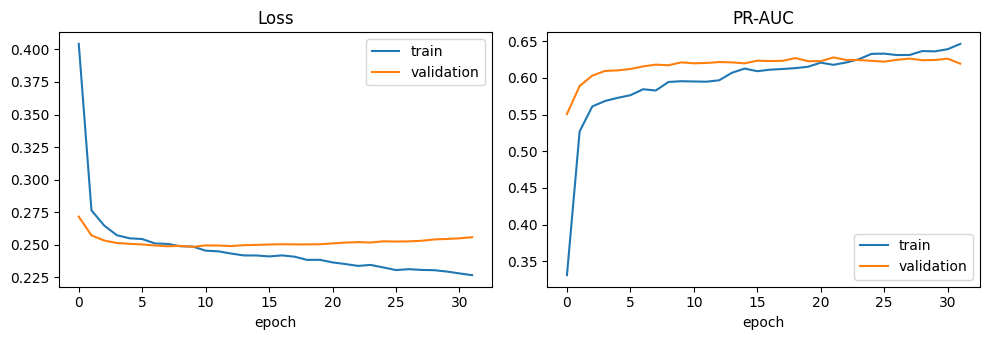

In [ ]:
# =========================
# 5.3 SHALLOW NEURAL NETWORK (Keras)
# =========================
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers


def build_nn(input_dim, hidden=(32, 16), dropout=0.2, l2=1e-4, lr=1e-3):
    tf.keras.utils.set_random_seed(SEED)
    net = [layers.Input(shape=(input_dim,))]
    for units in hidden:
        net += [layers.Dense(units, activation="relu", kernel_regularizer=regularizers.l2(l2)),
                layers.Dropout(dropout)]
    net += [layers.Dense(1, activation="sigmoid")]
    model = keras.Sequential(net)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=[keras.metrics.AUC(name="roc_auc"),
                 keras.metrics.AUC(curve="PR", name="pr_auc")],
    )
    return model


architectures = {
    "1 hidden layer (32)":      (32,),
    "2 hidden layers (32-16)":  (32, 16),
    "2 hidden layers (64-32)":  (64, 32),
}

nn_trials, nn_models, nn_histories = [], {}, {}
for name, hidden in architectures.items():
    model = build_nn(Xtr_s.shape[1], hidden=hidden)
    hist = model.fit(
        Xtr_s, y_train.values,
        validation_data=(Xva_s, y_val.values),
        epochs=100, batch_size=256, verbose=0,
        callbacks=[keras.callbacks.EarlyStopping(
            monitor="val_pr_auc", mode="max", patience=10, restore_best_weights=True)],
    )
    pv = model.predict(Xva_s, verbose=0).ravel()
    nn_models[name], nn_histories[name] = model, hist
    nn_trials.append({"architecture": name,
                      "epochs_run": len(hist.history["loss"]),
                      "val ROC-AUC": roc_auc_score(y_val, pv),
                      "val PR-AUC": average_precision_score(y_val, pv)})
nn_trials = pd.DataFrame(nn_trials)
display(nn_trials.round(4))

best_arch = nn_trials.loc[nn_trials["val PR-AUC"].idxmax(), "architecture"]
print("Selected architecture (validation PR-AUC):", best_arch)

nn_model = nn_models[best_arch]
probs["Neural Network"] = {
    "train": nn_model.predict(Xtr_s, verbose=0).ravel(),
    "val":   nn_model.predict(Xva_s, verbose=0).ravel(),
    "test":  nn_model.predict(Xte_s, verbose=0).ravel(),
}
eval_results.append(evaluate("Neural Network", *probs["Neural Network"].values()))
display(eval_results[-1].round(4))

# Training curves of the selected network
h = nn_histories[best_arch].history
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="validation")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(h["pr_auc"], label="train"); ax[1].plot(h["val_pr_auc"], label="validation")
ax[1].set_title("PR-AUC"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

## 5.4 Model Comparison


PR-AUC             ROC-AUC                F1  \
split                          train   val  test   train   val  test train   
model                                                                        
Logistic Regression            0.595 0.619 0.597   0.909 0.913 0.908 0.599   
Neural Network                 0.651 0.629 0.586   0.929 0.909 0.905 0.632   
Random Forest                  0.795 0.626 0.594   0.960 0.909 0.908 0.714   
Reference: LogReg (grid only)  0.511 0.517 0.502   0.886 0.892 0.883 0.573   
XGBoost                        0.679 0.640 0.593   0.928 0.915 0.909 0.631   

                                          Precision             Recall        \
split                           val  test     train   val  test  train   val   
model                                                                          
Logistic Regression           0.625 0.592     0.521 0.543 0.521  0.705 0.737   
Neural Network                0.625 0.572     0.601 0.587 0.548  0.667 0.669   
Random Forest                 0.619 0.563     0.733 0.617 0.570  0.696 0.622   
Reference: LogReg (grid only) 0.594 0.563     0.502 0.522 0.493  0.666 0.689   
XGBoost                       0.622 0.597     0.547 0.544 0.523  0.745 0.727   

                                     
split                          test  
model                                
Logistic Regression           0.686  
Neural Network                0.599  
Random Forest                 0.557  
Reference: LogReg (grid only) 0.656  
XGBoost                       0.696

,F1 threshold (from validation)
model,
Logistic Regression,0.291
Neural Network,0.387
Random Forest,0.398
Reference: LogReg (grid only),0.355
XGBoost,0.303


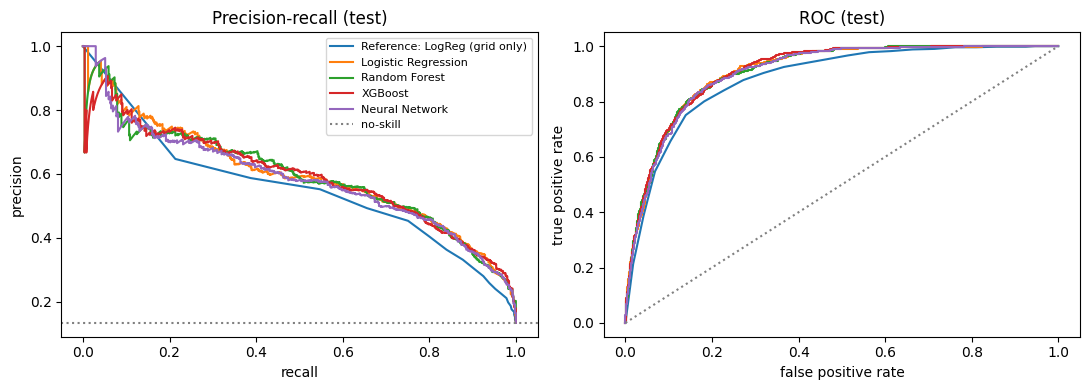

In [ ]:
# =========================
# 5.4 MODEL COMPARISON
# =========================
from sklearn.metrics import roc_curve

all_results = pd.concat(eval_results, ignore_index=True)

comparison = (
    all_results
    .pivot(index="model", columns="split", values=["PR-AUC", "ROC-AUC", "F1", "Precision", "Recall"])
    .reindex(columns=["train", "val", "test"], level=1)
    .round(4)
)
display(comparison)
display(all_results.groupby("model")["threshold"].first().round(3).to_frame("F1 threshold (from validation)"))

# Curves on the unseen test set
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name, p in probs.items():
    prec, rec, _ = precision_recall_curve(y_test, p["test"])
    fpr, tpr, _ = roc_curve(y_test, p["test"])
    ax[0].plot(rec, prec, label=name)
    ax[1].plot(fpr, tpr, label=name)
ax[0].axhline(y_test.mean(), color="gray", ls=":", label="no-skill")
ax[0].set_title("Precision-recall (test)"); ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision")
ax[1].plot([0, 1], [0, 1], color="gray", ls=":")
ax[1].set_title("ROC (test)"); ax[1].set_xlabel("false positive rate"); ax[1].set_ylabel("true positive rate")
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
# Summary: PR-AUC per split, gain over the grid-only reference, and overfitting gap (train - test)
pr_auc = all_results.pivot(index="model", columns="split", values="PR-AUC")[["train", "val", "test"]]
pr_auc["gain_over_grid_only_test"] = pr_auc["test"] - pr_auc.loc["Reference: LogReg (grid only)", "test"]
pr_auc["overfit_gap_train_minus_test"] = pr_auc["train"] - pr_auc["test"]
display(pr_auc.sort_values("val", ascending=False).round(3))
print("Best model on validation PR-AUC:", pr_auc["val"].idxmax())

split,train,val,test,gain_over_grid_only_test,overfit_gap_train_minus_test
model,,,,,
XGBoost,0.679,0.640,0.593,0.091,0.086
Neural Network,0.651,0.629,0.586,0.084,0.065
Random Forest,0.795,0.626,0.594,0.092,0.201
Logistic Regression,0.595,0.619,0.597,0.095,-0.001
Reference: LogReg (grid only),0.511,0.517,0.502,0.000,0.010


Best model on validation PR-AUC: XGBoost


**Interpretation of the comparison** (exact numbers in the tables above).
- **Every model clearly beats the grid-only reference** (test PR-AUC around 0.59–0.60 against about 0.50). Starting position alone is a strong signal, and the other features add information on top of it. The ablation in section 6 shows that starting position carries most of the signal; every other feature group adds only a little on its own (about 0.01 PR-AUC or less).
- **The four models are close to each other** (within about 0.01–0.02 PR-AUC). Most of the signal is captured by fairly simple relationships (front of the grid plus recent form), so the more flexible models add little over logistic regression.
- **ROC-AUC is high (about 0.91) for all models and hardly separates them.** This is why PR-AUC, which focuses on the rare podium class, is the primary metric.
- **Random forest overfits:** its training PR-AUC is far above its test PR-AUC (see the overfitting-gap column), because unlimited-depth trees memorise training races. Its test score is still similar to the others.
- **XGBoost** is chosen as the final model for the explanations in section 7, because it scores best on validation PR-AUC and best or joint-best on test PR-AUC, with a much smaller train–test gap than random forest (its early stopping on validation keeps the trees from memorising the training races).
- **Test scores are close to validation scores** for every model, so the hyperparameters and thresholds chosen on validation carry over to unseen races.

### 5.4.1 Second Split: by Season (train ≤ 2019, validation 2020–2021, test 2022–2024)

The random split in 5.1 stays our main split. Here we also run the split written in the project brief: **train on seasons up to 2019, validate on 2020–2021, test on 2022–2024**. The two splits answer different questions:

| | Random split by race (5.1) | Split by season (this section) |
|---|---|---|
| Question it answers | How well does the model rank podium finishers in an unseen race from **any** era? | Trained only on the past, how well does it predict **future** seasons? |
| Test races | 15% of races, spread over 1950–2024 | Every race of 2022–2024 (the new ground-effect era) |
| Can training races be later than test races? | Yes | No: training always ends before validation, and validation before test |

**What stays identical**, so that only the split changes: the same modeling table and 30 features, the same hyperparameter grids, the same selection rule (best **validation** PR-AUC), the F1 threshold chosen on validation, and preprocessing refitted on this split's **training set only**. The test seasons are never used for any choice.

All variables in this section start with `ts_`, so nothing from 5.1–5.4 is overwritten: the ablation (6) and the explanations (7) still use the random split.

races   rows  share of rows  podium rate  \
split                set                                                    
random by race (5.1) train         779  17427          0.699        0.135   
                     validation    167   3694          0.148        0.137   
                     test          168   3800          0.152        0.133   
by season (5.4.1)    train        1007  22782          0.914        0.133   
                     validation     39    780          0.031        0.150   
                     test           68   1359          0.055        0.150   

                                 drivers per race  first year  last year  
split                set                                                  
random by race (5.1) train                 22.371        1950       2024  
                     validation            22.120        1950       2024  
                     test                  22.619        1950       2024  
by season (5.4.1)    train                 22.624        1950       2019  
                     validation            20.000        2020       2021  
                     test                  19.985        2022       2024

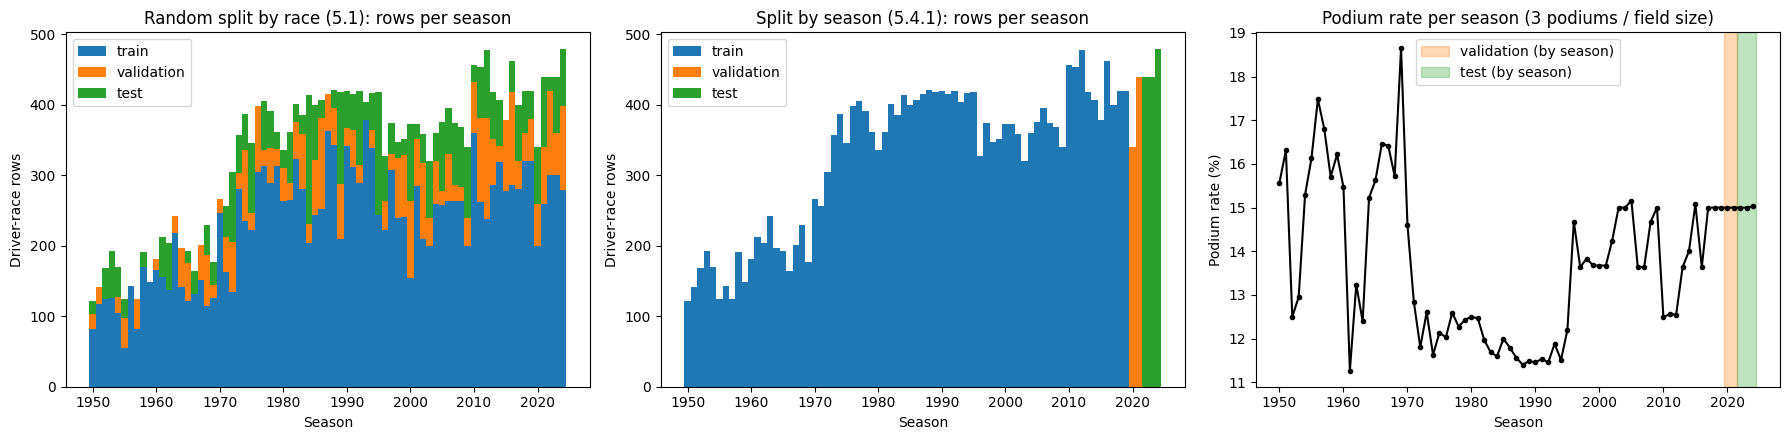

In [ ]:
# =========================
# 5.4.1 SECOND SPLIT: BY SEASON (train <= 2019, validation 2020-2021, test 2022-2024)
# Variables use a ts_ prefix so nothing from 5.1-5.4 is overwritten.
# =========================
ts_train_mask = model_df["year"] <= 2019
ts_val_mask   = model_df["year"].between(2020, 2021)
ts_test_mask  = model_df["year"] >= 2022

# Every row belongs to exactly one set
assert (ts_train_mask.astype(int) + ts_val_mask.astype(int) + ts_test_mask.astype(int)).eq(1).all()

ts_X_train, ts_y_train = X_all[ts_train_mask], y_all[ts_train_mask]
ts_X_val,   ts_y_val   = X_all[ts_val_mask],   y_all[ts_val_mask]
ts_X_test,  ts_y_test  = X_all[ts_test_mask],  y_all[ts_test_mask]


def split_summary(masks, split_name):
    rows = []
    for set_name, m in masks.items():
        part = model_df[m]
        rows.append({
            "split": split_name, "set": set_name,
            "races": part["raceId"].nunique(),
            "rows": len(part),
            "share of rows": len(part) / len(model_df),
            "podium rate": part["podium"].mean(),
            "drivers per race": len(part) / part["raceId"].nunique(),
            "first year": part["year"].min(),
            "last year": part["year"].max(),
        })
    return rows


split_overview = pd.DataFrame(
    split_summary({"train": train_mask, "validation": val_mask, "test": test_mask}, "random by race (5.1)")
    + split_summary({"train": ts_train_mask, "validation": ts_val_mask, "test": ts_test_mask}, "by season (5.4.1)")
).set_index(["split", "set"])
display(split_overview.round(3))

# Which seasons land in which set, for both splits, and how the podium rate moves over the seasons
set_colors = {"train": "tab:blue", "validation": "tab:orange", "test": "tab:green"}
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for a, masks, title in [
    (ax[0], {"train": train_mask, "validation": val_mask, "test": test_mask}, "Random split by race (5.1)"),
    (ax[1], {"train": ts_train_mask, "validation": ts_val_mask, "test": ts_test_mask}, "Split by season (5.4.1)"),
]:
    bottom = pd.Series(0, index=sorted(model_df["year"].unique()))
    for set_name, m in masks.items():
        counts = model_df.loc[m].groupby("year").size().reindex(bottom.index, fill_value=0)
        a.bar(bottom.index, counts, bottom=bottom, width=1.0, color=set_colors[set_name], label=set_name)
        bottom += counts
    a.set_title(f"{title}: rows per season")
    a.set_xlabel("Season")
    a.set_ylabel("Driver-race rows")
    a.legend()

podium_by_year = model_df.groupby("year")["podium"].mean() * 100
ax[2].plot(podium_by_year.index, podium_by_year.values, marker=".", color="black")
ax[2].axvspan(2019.5, 2021.5, color=set_colors["validation"], alpha=0.3, label="validation (by season)")
ax[2].axvspan(2021.5, 2024.5, color=set_colors["test"], alpha=0.3, label="test (by season)")
ax[2].set_title("Podium rate per season (3 podiums / field size)")
ax[2].set_xlabel("Season")
ax[2].set_ylabel("Podium rate (%)")
ax[2].legend()
plt.tight_layout()
plt.show()


**Training every model again on the season split.** The function below repeats 5.2–5.3 step by step on any split: the grid-only reference, logistic regression (`C` grid), random forest (`max_depth` × `min_samples_leaf` grid), XGBoost (`max_depth` × `min_child_weight` grid with early stopping on validation) and the shallow neural network (the same three architectures, early stopping on validation PR-AUC). Every candidate's validation PR-AUC is kept in a trials table, so the selection can be checked.

In [ ]:
# =========================
# 5.4.1 SAME TRAINING PROCEDURE AS 5.2-5.3, FOR ANY SPLIT
# =========================
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier


def evaluate_split(name, ys, ps):
    """Same five metrics as evaluate() in 5.1, for any split. The F1 threshold is chosen on
    this split's validation set only and then applied unchanged to train and test."""
    thr = best_threshold(ys["val"], ps["val"])
    rows = []
    for s in ["train", "val", "test"]:
        y, p = ys[s], ps[s]
        rows.append({
            "model": name, "split": s,
            "ROC-AUC": roc_auc_score(y, p),
            "PR-AUC": average_precision_score(y, p),
            "F1": f1_score(y, p >= thr),
            "Precision": precision_score(y, p >= thr, zero_division=0),
            "Recall": recall_score(y, p >= thr),
            "threshold": thr,
        })
    return pd.DataFrame(rows)


def train_all_models(X_tr, y_tr, X_va, y_va, X_te, y_te):
    """Re-run 5.2-5.3 on another split. Preprocessing is fitted on this training set only and every
    hyperparameter is chosen on this validation set only. Returns metrics, probabilities, the chosen
    settings and the full trials table."""
    ys = {"train": y_tr, "val": y_va, "test": y_te}
    pp = clone(prep).fit(X_tr)                      # same preprocessing as 5.1, refitted on this train set
    A = {"train": pp.transform(X_tr), "val": pp.transform(X_va), "test": pp.transform(X_te)}
    out_probs, chosen, trials = {}, {}, []

    def keep_best(model_name, setting, model, p_val, best):
        score = average_precision_score(y_va, p_val)
        trials.append({"model": model_name, "setting": setting, "val PR-AUC": score})
        return (score, setting, model) if best is None or score > best[0] else best

    # Reference: grid position only
    grid_scaler_ts = StandardScaler().fit(X_tr[["grid_numeric"]])
    G = {s: grid_scaler_ts.transform(X[["grid_numeric"]]) for s, X in zip(A, (X_tr, X_va, X_te))}
    ref = LogisticRegression(max_iter=2000).fit(G["train"], y_tr)
    out_probs["Reference: LogReg (grid only)"] = {s: ref.predict_proba(G[s])[:, 1] for s in G}
    chosen["Reference: LogReg (grid only)"] = "no hyperparameters"

    # Logistic regression
    best = None
    for C in [0.01, 0.1, 1, 10]:
        m = LogisticRegression(C=C, max_iter=2000).fit(A["train"], y_tr)
        best = keep_best("Logistic Regression", f"C={C}", m, m.predict_proba(A["val"])[:, 1], best)
    out_probs["Logistic Regression"] = {s: best[2].predict_proba(A[s])[:, 1] for s in A}
    chosen["Logistic Regression"] = best[1]

    # Random forest
    best = None
    for depth in [6, 10, None]:
        for leaf in [5, 20]:
            m = RandomForestClassifier(n_estimators=300, max_depth=depth, min_samples_leaf=leaf,
                                       n_jobs=-1, random_state=SEED).fit(A["train"], y_tr)
            best = keep_best("Random Forest", f"max_depth={depth}, min_samples_leaf={leaf}",
                             m, m.predict_proba(A["val"])[:, 1], best)
    out_probs["Random Forest"] = {s: best[2].predict_proba(A[s])[:, 1] for s in A}
    chosen["Random Forest"] = best[1]

    # XGBoost, early stopping on this validation set
    best = None
    for depth in [2, 3, 4]:
        for mcw in [1, 5]:
            m = XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=depth, min_child_weight=mcw,
                              subsample=0.8, colsample_bytree=0.8, eval_metric="aucpr",
                              early_stopping_rounds=50, tree_method="hist", random_state=SEED, n_jobs=-1)
            m.fit(A["train"], y_tr, eval_set=[(A["val"], y_va)], verbose=False)
            best = keep_best("XGBoost", f"max_depth={depth}, min_child_weight={mcw} ({m.best_iteration + 1} trees)",
                             m, m.predict_proba(A["val"])[:, 1], best)
    out_probs["XGBoost"] = {s: best[2].predict_proba(A[s])[:, 1] for s in A}
    chosen["XGBoost"] = best[1]

    # Shallow neural network: the same three architectures and early stopping as 5.3
    best = None
    for arch_name, hidden in architectures.items():
        m = build_nn(A["train"].shape[1], hidden=hidden)
        m.fit(A["train"], y_tr.values, validation_data=(A["val"], y_va.values),
              epochs=100, batch_size=256, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max",
                                                       patience=10, restore_best_weights=True)])
        best = keep_best("Neural Network", arch_name, m, m.predict(A["val"], verbose=0).ravel(), best)
    out_probs["Neural Network"] = {s: best[2].predict(A[s], verbose=0).ravel() for s in A}
    chosen["Neural Network"] = best[1]

    results = pd.concat([evaluate_split(name, ys, p) for name, p in out_probs.items()], ignore_index=True)
    return results, out_probs, chosen, pd.DataFrame(trials)


ts_results, ts_probs, ts_chosen, ts_trials = train_all_models(
    ts_X_train, ts_y_train, ts_X_val, ts_y_val, ts_X_test, ts_y_test
)

print("Hyperparameter trials on the season split (selection = highest validation PR-AUC):")
display(ts_trials.round(4))

print("Season split: all five metrics on train / validation / test")
display(
    ts_results.pivot(index="model", columns="split", values=["PR-AUC", "ROC-AUC", "F1", "Precision", "Recall"])
    .reindex(columns=["train", "val", "test"], level=1)
    .round(4)
)


Hyperparameter trials on the season split (selection = highest validation PR-AUC):


,model,setting,val PR-AUC
0,Logistic Regression,C=0.01,0.729
1,Logistic Regression,C=0.1,0.738
2,Logistic Regression,C=1,0.723
3,Logistic Regression,C=10,0.716
4,Random Forest,"max_depth=6, min_samples_leaf=5",0.714
5,Random Forest,"max_depth=6, min_samples_leaf=20",0.724
6,Random Forest,"max_depth=10, min_samples_leaf=5",0.723
7,Random Forest,"max_depth=10, min_samples_leaf=20",0.728
8,Random Forest,"max_depth=None, min_samples_leaf=5",0.732
9,Random Forest,"max_depth=None, min_samples_leaf=20",0.725


Season split: all five metrics on train / validation / test


PR-AUC             ROC-AUC                F1  \
split                          train   val  test   train   val  test train   
model                                                                        
Logistic Regression            0.583 0.738 0.712   0.906 0.931 0.937 0.568   
Neural Network                 0.701 0.771 0.664   0.942 0.934 0.912 0.586   
Random Forest                  0.797 0.732 0.715   0.961 0.929 0.936 0.705   
Reference: LogReg (grid only)  0.498 0.639 0.647   0.884 0.909 0.914 0.543   
XGBoost                        0.591 0.734 0.717   0.906 0.931 0.939 0.573   

                                          Precision             Recall        \
split                           val  test     train   val  test  train   val   
model                                                                          
Logistic Regression           0.706 0.671     0.568 0.694 0.648  0.567 0.718   
Neural Network                0.697 0.618     0.425 0.588 0.506  0.939 0.855   
Random Forest                 0.711 0.665     0.683 0.688 0.598  0.729 0.735   
Reference: LogReg (grid only) 0.692 0.649     0.545 0.692 0.650  0.541 0.692   
XGBoost                       0.707 0.681     0.568 0.713 0.649  0.578 0.701   

                                     
split                          test  
model                                
Logistic Regression           0.696  
Neural Network                0.794  
Random Forest                 0.750  
Reference: LogReg (grid only) 0.647  
XGBoost                       0.716

No-skill PR-AUC (= test podium rate): random split 0.133, season split 0.150


,test PR-AUC (random),test PR-AUC (by season),lift over no-skill (random),lift over no-skill (by season),test ROC-AUC (random),test ROC-AUC (by season),test F1 (random),test F1 (by season),val-test PR-AUC gap (by season),"gain over grid-only, test PR-AUC (random)","gain over grid-only, test PR-AUC (by season)"
model,,,,,,,,,,,
Reference: LogReg (grid only),0.502,0.647,3.768,4.312,0.883,0.914,0.563,0.649,-0.009,0.000,0.000
Logistic Regression,0.597,0.712,4.481,4.744,0.908,0.937,0.592,0.671,0.026,0.095,0.065
Random Forest,0.594,0.715,4.460,4.762,0.908,0.936,0.563,0.665,0.017,0.092,0.067
XGBoost,0.593,0.717,4.451,4.775,0.910,0.939,0.597,0.681,0.018,0.091,0.069
Neural Network,0.586,0.664,4.401,4.426,0.906,0.912,0.572,0.618,0.107,0.084,0.017


,chosen on random split (5.2-5.3),chosen on season split (5.4.1)
Logistic Regression,C=1.0,C=0.1
Random Forest,"max_depth=None, min_samples_leaf=5","max_depth=None, min_samples_leaf=5"
XGBoost,"max_depth=4, min_child_weight=5","max_depth=3, min_child_weight=1 (34 trees)"
Neural Network,2 hidden layers (32-16),2 hidden layers (64-32)


Best model on validation PR-AUC, season split: Neural Network


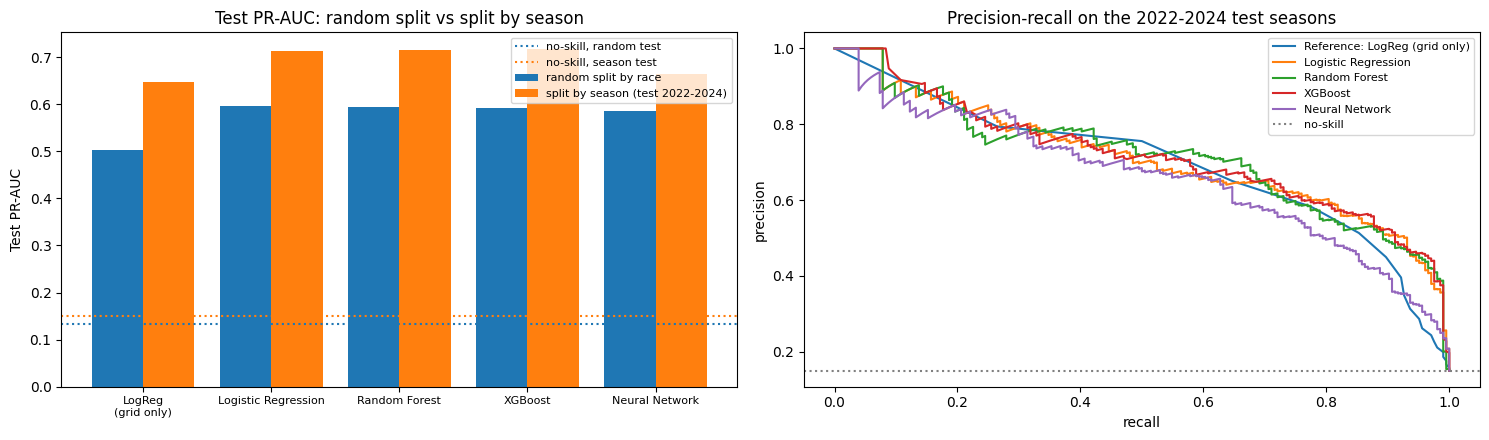

In [ ]:
# =========================
# 5.4.1 RANDOM SPLIT vs SEASON SPLIT
# =========================
random_test = all_results[all_results["split"] == "test"].set_index("model")
season_test = ts_results[ts_results["split"] == "test"].set_index("model")
season_val = ts_results[ts_results["split"] == "val"].set_index("model")
model_order = ["Reference: LogReg (grid only)", "Logistic Regression", "Random Forest", "XGBoost", "Neural Network"]

# A model with no skill scores a PR-AUC equal to the podium rate of the test set,
# and the two test sets have different podium rates, so we also report PR-AUC / no-skill ("lift").
no_skill_random, no_skill_season = y_test.mean(), ts_y_test.mean()

split_comparison = pd.DataFrame({
    "test PR-AUC (random)":     random_test["PR-AUC"],
    "test PR-AUC (by season)":  season_test["PR-AUC"],
    "lift over no-skill (random)":    random_test["PR-AUC"] / no_skill_random,
    "lift over no-skill (by season)": season_test["PR-AUC"] / no_skill_season,
    "test ROC-AUC (random)":    random_test["ROC-AUC"],
    "test ROC-AUC (by season)": season_test["ROC-AUC"],
    "test F1 (random)":         random_test["F1"],
    "test F1 (by season)":      season_test["F1"],
    "val-test PR-AUC gap (by season)": season_val["PR-AUC"] - season_test["PR-AUC"],
}).loc[model_order]
split_comparison["gain over grid-only, test PR-AUC (random)"] = (
    split_comparison["test PR-AUC (random)"] - split_comparison.loc["Reference: LogReg (grid only)", "test PR-AUC (random)"])
split_comparison["gain over grid-only, test PR-AUC (by season)"] = (
    split_comparison["test PR-AUC (by season)"] - split_comparison.loc["Reference: LogReg (grid only)", "test PR-AUC (by season)"])

print(f"No-skill PR-AUC (= test podium rate): random split {no_skill_random:.3f}, season split {no_skill_season:.3f}")
display(split_comparison.round(3))

# Hyperparameters chosen on each split's own validation set
display(pd.DataFrame({
    "chosen on random split (5.2-5.3)": {
        "Logistic Regression": f"C={best_C}",
        "Random Forest": f"max_depth={best_depth}, min_samples_leaf={best_leaf}",
        "XGBoost": f"max_depth={best_key[0]}, min_child_weight={best_key[1]}",
        "Neural Network": best_arch,
    },
    "chosen on season split (5.4.1)": {k: v for k, v in ts_chosen.items() if k in model_order[1:]},
}))

print("Best model on validation PR-AUC, season split:", season_val["PR-AUC"].idxmax())

# Plots: test PR-AUC for both splits, and the precision-recall curves on the 2022-2024 test seasons
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
x = np.arange(len(model_order))
ax[0].bar(x - 0.2, split_comparison["test PR-AUC (random)"], width=0.4, label="random split by race")
ax[0].bar(x + 0.2, split_comparison["test PR-AUC (by season)"], width=0.4, label="split by season (test 2022-2024)")
ax[0].axhline(no_skill_random, color="tab:blue", ls=":", label="no-skill, random test")
ax[0].axhline(no_skill_season, color="tab:orange", ls=":", label="no-skill, season test")
ax[0].set_xticks(x)
ax[0].set_xticklabels([m.replace("Reference: ", "").replace(" (grid only)", "\n(grid only)") for m in model_order], fontsize=8)
ax[0].set_ylabel("Test PR-AUC")
ax[0].set_title("Test PR-AUC: random split vs split by season")
ax[0].legend(fontsize=8)

for name in model_order:
    prec, rec, _ = precision_recall_curve(ts_y_test, ts_probs[name]["test"])
    ax[1].plot(rec, prec, label=name)
ax[1].axhline(no_skill_season, color="gray", ls=":", label="no-skill")
ax[1].set_title("Precision-recall on the 2022-2024 test seasons")
ax[1].set_xlabel("recall")
ax[1].set_ylabel("precision")
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()


**Result: random split vs split by season** (exact numbers in the tables above).

- **The statistical models also work on future seasons.** Trained only on races up to 2019, logistic regression, random forest and XGBoost rank the 2022–2024 podium finishers well: test PR-AUC about 0.71 and ROC-AUC about 0.94, against about 0.60 and 0.91 with the random split.
- **The higher score does not mean the season split is "better".** The two test sets are different races. The 2022–2024 test set has smaller fields (20 cars instead of up to 30+), so its no-skill PR-AUC is higher (0.150 vs 0.133), and modern races are more predictable: on the random split, XGBoost scores about 0.74 PR-AUC on its 2014–2024 test races but only about 0.48 on 1950–1979 races. Relative to no-skill, the two splits are close (lift about 4.7 vs 4.5).
- **What the other features add is smaller on future seasons.** The gain over the grid-only reference drops from about +0.10 PR-AUC (random split) to about +0.06 (season split). Grid position alone is already very strong in the modern era, and team and form features learned on older eras transfer only partly to the new ground-effect cars and to teams that did not exist before 2020 (their one-hot columns are empty).
- **The neural network does not transfer as well.** It has the best validation PR-AUC on 2020–2021 (0.77) but the lowest test PR-AUC on 2022–2024 (0.68, against 0.71 for the others): a validation-test gap of about 0.09, against about 0.02–0.03 for the other models. With only 39 validation races, choosing a flexible model on validation is noisy (XGBoost's early stopping also stops after only 9 trees here). This is why we keep the random split as the main split for model selection, ablation and explanations, and report this split as the check on future seasons.

The test seasons (2022–2024) were never used for any choice in this section.

## 5.5 Preprocessing-Order Experiments

Preprocessing steps can be done in different orders, and some orders leak information or distort the data. We test three choices with logistic regression (same `C` as in 5.2.1), changing **only** the preprocessing:

1. **Order of imputation and scaling:** impute missing values, then scale (what all models use) vs scale, then impute.
2. **Log-transform before scaling:** scaling only (what all models use) vs a log transform of the very skewed count features, then scaling.
3. **Filling missing qualifying:** with the starting grid before preprocessing (what all models use) vs leaving it to the pipeline's median imputation.

Experiment 4 then tests a training choice for the imbalanced target: class weighting vs no weighting.

,val PR-AUC,test PR-AUC
impute then scale (used),0.619,0.597
scale then impute,0.620,0.597


,raw,impute then scale,scale then impute
count,15344.000,17427.000,17427.000
mean,19.854,-0.000,-0.044
std,43.464,1.000,0.946
min,0.000,-0.437,-0.457
25%,0.000,-0.437,-0.457
50%,4.000,-0.340,-0.365
75%,18.000,-0.072,-0.112
max,466.000,10.900,10.265


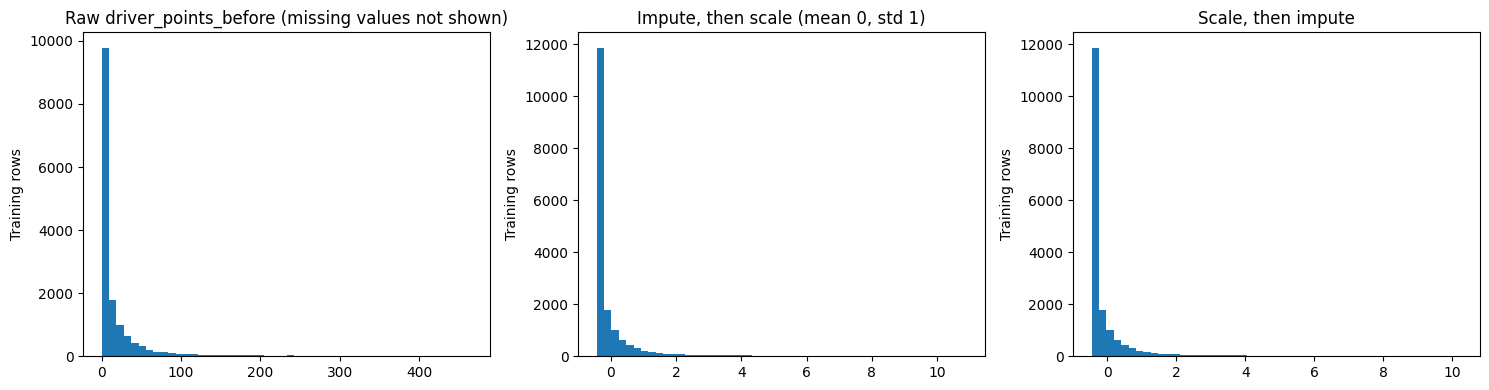

In [ ]:
# Experiment 1: impute then scale (used) vs scale then impute
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression

def lr_scores(preprocessor):
    """Train logistic regression (C chosen in 5.2.1) on the training set and score it on validation and test."""
    m = LogisticRegression(C=best_C, max_iter=2000).fit(preprocessor.transform(X_train), y_train)
    return {
        "val PR-AUC": average_precision_score(y_val, m.predict_proba(preprocessor.transform(X_val))[:, 1]),
        "test PR-AUC": average_precision_score(y_test, m.predict_proba(preprocessor.transform(X_test))[:, 1]),
    }

def make_prep(numeric_steps):
    return ColumnTransformer([
        ("num", Pipeline(numeric_steps), numeric_features),
        ("cat", clone(categorical_pipe), categorical_features),
    ]).fit(X_train)

prep_impute_scale = make_prep([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                               ("scale", StandardScaler())])
prep_scale_impute = make_prep([("scale", StandardScaler()),
                               ("impute", SimpleImputer(strategy="median", add_indicator=True))])

exp2 = pd.DataFrame({
    "impute then scale (used)": lr_scores(prep_impute_scale),
    "scale then impute": lr_scores(prep_scale_impute),
}).T
display(exp2.round(4))

# Effect on one feature with gaps: championship points before the race (missing for ~3,000 rows)
feature = "driver_points_before"
col = numeric_features.index(feature)
raw = X_train[feature]
after_impute_scale = prep_impute_scale.transform(X_train)[:, col]
after_scale_impute = prep_scale_impute.transform(X_train)[:, col]

display(pd.DataFrame({
    "raw": raw.describe(),
    "impute then scale": pd.Series(after_impute_scale).describe(),
    "scale then impute": pd.Series(after_scale_impute).describe(),
}).round(3))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(raw.dropna(), bins=50)
ax[0].set_title(f"Raw {feature} (missing values not shown)")
ax[1].hist(after_impute_scale, bins=50)
ax[1].set_title("Impute, then scale (mean 0, std 1)")
ax[2].hist(after_scale_impute, bins=50)
ax[2].set_title("Scale, then impute")
for a in ax:
    a.set_ylabel("Training rows")
plt.tight_layout()
plt.show()

**Result of experiment 1.** Both orders give almost the same scores, but they produce **different data**, as the table and histograms of `driver_points_before` (missing for about 3,000 rows) show:
- **Impute, then scale:** missing values are first filled with the median, and the scaler then sees the complete column, so the result has mean exactly 0 and standard deviation exactly 1.
- **Scale, then impute:** the scaler is fitted without the missing rows, and the filled values are then placed at the scaled median (not at 0), so the final column has a mean of about −0.04 and a standard deviation of about 0.95. It is no longer properly standardised.

The scores barely change because the missing-indicator column tells the model which values were filled. We keep **impute, then scale**, because it gives correctly standardised features, which logistic regression and the neural network rely on.

,val PR-AUC,test PR-AUC
scale only (used),0.619,0.597
"log, then scale",0.614,0.595


,skewness (raw),skewness (after log)
driver_points_before,4.160,0.450
constructor_points_before,3.990,0.120
driver_wins_before,4.760,2.660
constructor_wins_before,3.490,1.820
driver_starts_before,1.520,-0.740
constructor_races_before,1.810,-0.580


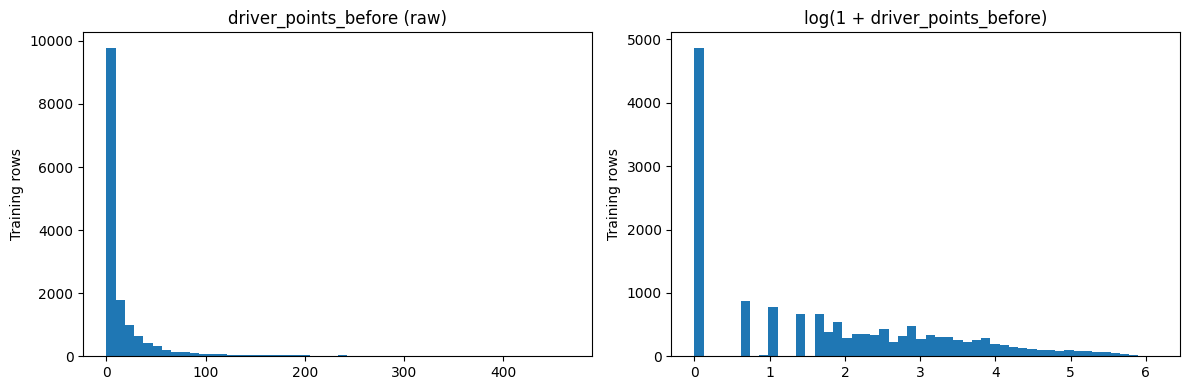

In [ ]:
# Experiment 2: scaling only (used) vs log-transform of the skewed count features, then scaling
from sklearn.preprocessing import FunctionTransformer

skewed = ["driver_points_before", "constructor_points_before", "driver_wins_before",
          "constructor_wins_before", "driver_starts_before", "constructor_races_before"]
other_numeric = [f for f in numeric_features if f not in skewed]

prep_log = ColumnTransformer([
    ("skewed", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                         ("log", FunctionTransformer(np.log1p)),
                         ("scale", StandardScaler())]), skewed),
    ("num", clone(numeric_pipe), other_numeric),
    ("cat", clone(categorical_pipe), categorical_features),
]).fit(X_train)

exp3 = pd.DataFrame({
    "scale only (used)": lr_scores(prep),
    "log, then scale": lr_scores(prep_log),
}).T
display(exp3.round(4))

# Effect on the distribution: skewness (0 = symmetric) before and after the log
display(pd.DataFrame({
    "skewness (raw)": X_train[skewed].skew(),
    "skewness (after log)": np.log1p(X_train[skewed]).skew(),
}).round(2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(X_train["driver_points_before"].dropna(), bins=50)
ax[0].set_title("driver_points_before (raw)")
ax[1].hist(np.log1p(X_train["driver_points_before"].dropna()), bins=50)
ax[1].set_title("log(1 + driver_points_before)")
for a in ax:
    a.set_ylabel("Training rows")
plt.tight_layout()
plt.show()

**Result of experiment 2.** The log transform changes the data a lot: championship points go from a huge spike at 0 with a long tail (up to 466) to a much more balanced shape, and the skewness of the points features drops from about 4 to under 1. The scores, however, stay the same (within about 0.005 PR-AUC). The strongest signals are positions and rates (grid, recent podium rates), not raw point totals, so the model handles the skew well enough without the transform. We keep **scaling only**, which is simpler and just as good.

In [ ]:
# Experiment 3: missing qualifying filled with the grid before preprocessing (used)
# vs left missing, so the pipeline fills it with the training median
def without_grid_fill(X):
    X = X.copy()
    no_quali = removed_cols.loc[X.index, "has_quali_data"] == 0
    X.loc[no_quali, "qualifying_position"] = np.nan
    return X

Xtr_nf, Xva_nf, Xte_nf = (without_grid_fill(X) for X in (X_train, X_val, X_test))
prep_nf = clone(prep).fit(Xtr_nf)
lr_nf = LogisticRegression(C=best_C, max_iter=2000).fit(prep_nf.transform(Xtr_nf), y_train)

exp4 = pd.DataFrame({
    "fill with grid first (used)": lr_scores(prep),
    "pipeline median": {
        "val PR-AUC": average_precision_score(y_val, lr_nf.predict_proba(prep_nf.transform(Xva_nf))[:, 1]),
        "test PR-AUC": average_precision_score(y_test, lr_nf.predict_proba(prep_nf.transform(Xte_nf))[:, 1]),
    },
}).T
display(exp4.round(4))
print("Rows whose qualifying value differs between the two versions:", int((removed_cols.loc[X_train.index, "has_quali_data"] == 0).sum()), "of", len(X_train))

,val PR-AUC,test PR-AUC
fill with grid first (used),0.619,0.597
pipeline median,0.627,0.600


Rows whose qualifying value differs between the two versions: 10299 of 17427


**Result of experiment 3.** Leaving the gap to the pipeline's median scores very slightly higher (about +0.008 PR-AUC on validation and +0.003 on test). The difference is about as large as the differences between the `C` values tried in 5.2.1, so it is within noise.

We keep **filling with the grid**, because it is the more meaningful value. For races before 1994 the grid **is** the starting order that qualifying produced, whereas the median puts every pre-1994 driver at a mid-grid qualifying position, wherever they actually started. The result also shows that this fill is not what drives the model's performance: grid and form carry the signal either way.

### Experiment 4: Class Weighting for the Rare Podium Class

Podiums are only about 13.5% of rows. A common fix for an imbalanced target is to give the rare class more weight in training (`class_weight="balanced"` for logistic regression, `scale_pos_weight` = negatives / positives for XGBoost). We compare it with no weighting (what all models use), with the same hyperparameters as in 5.2.

Negatives per positive in training: 6.43


,,val PR-AUC,test PR-AUC,val F1,test F1,F1 threshold,mean predicted probability (test)
model,training,,,,,,
Logistic Regression,no weighting (used),0.619,0.597,0.625,0.592,0.291,0.132
XGBoost,no weighting (used),0.640,0.593,0.622,0.597,0.303,0.133
Logistic Regression,class weights,0.611,0.584,0.622,0.579,0.770,0.301
XGBoost,class weights,0.632,0.605,0.621,0.602,0.721,0.295


Actual podium rate in the test set: 0.133


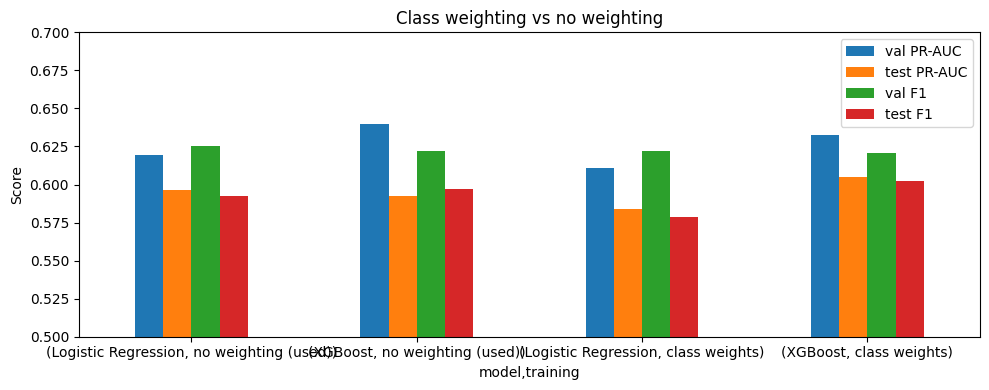

In [ ]:
# Experiment 4: class weighting vs no weighting (used)
from xgboost import XGBClassifier

pos_weight = float((y_train == 0).sum() / (y_train == 1).sum())
print(f"Negatives per positive in training: {pos_weight:.2f}")

weight_rows = []
for label, lr_kw, xgb_kw in [("no weighting (used)", {}, {}),
                             ("class weights", {"class_weight": "balanced"}, {"scale_pos_weight": pos_weight})]:
    lr_w = LogisticRegression(C=best_C, max_iter=2000, **lr_kw).fit(Xtr_s, y_train)
    xgb_w = XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=best_key[0], min_child_weight=best_key[1],
                          subsample=0.8, colsample_bytree=0.8, eval_metric="aucpr", early_stopping_rounds=50,
                          tree_method="hist", random_state=SEED, n_jobs=-1, **xgb_kw)
    xgb_w.fit(Xtr_s, y_train, eval_set=[(Xva_s, y_val)], verbose=False)
    for name, m in [("Logistic Regression", lr_w), ("XGBoost", xgb_w)]:
        pv, pt = m.predict_proba(Xva_s)[:, 1], m.predict_proba(Xte_s)[:, 1]
        thr = best_threshold(y_val, pv)
        weight_rows.append({"model": name, "training": label,
                            "val PR-AUC": average_precision_score(y_val, pv), "test PR-AUC": average_precision_score(y_test, pt),
                            "val F1": f1_score(y_val, pv >= thr), "test F1": f1_score(y_test, pt >= thr),
                            "F1 threshold": thr, "mean predicted probability (test)": pt.mean()})
weight_df = pd.DataFrame(weight_rows).set_index(["model", "training"])
display(weight_df.round(3))
print(f"Actual podium rate in the test set: {y_test.mean():.3f}")

weight_df[["val PR-AUC", "test PR-AUC", "val F1", "test F1"]].plot(kind="bar", figsize=(10, 4))
plt.ylim(0.5, 0.7)
plt.ylabel("Score")
plt.title("Class weighting vs no weighting")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Result of experiment 4: we keep no weighting.**

| Model | Training | Val PR-AUC | Test PR-AUC | Val F1 | Test F1 | Mean predicted probability (test) |
|---|---|---|---|---|---|---|
| Logistic regression | no weighting (used) | 0.619 | 0.597 | 0.623 | 0.592 | 0.132 |
| Logistic regression | class weights | 0.611 | 0.584 | 0.624 | 0.579 | 0.301 |
| XGBoost | no weighting (used) | 0.635 | 0.599 | 0.620 | 0.586 | 0.133 |
| XGBoost | class weights | 0.635 | 0.601 | 0.619 | 0.603 | 0.301 |

- **Ranking does not improve:** PR-AUC is lower for logistic regression (−0.008 on validation) and unchanged for XGBoost on validation. Weighting cannot improve a ranking metric much, because it mainly shifts all probabilities up.
- **The probabilities become wrong:** with weights, the average predicted podium probability is 0.30, while the real podium rate is 0.13. Without weights it is 0.13, so the probabilities can be read as real chances, which the inference function reports.
- **The imbalance is already handled where it matters:** PR-AUC as the primary metric, and an F1 threshold chosen on validation (0.29–0.40 instead of 0.5). With weights, the chosen threshold simply moves up to about 0.77 and F1 stays about the same.

The choice is made on validation; the test column is reported only.

## 5.6 Inference Function

`predict_podium()` predicts one driver-race from **pre-race information only**, using the final model (XGBoost) and the F1 threshold chosen on validation. It takes a dictionary of feature values and returns the podium probability, the yes/no prediction, and the list of features that were missing.

**Missing information is allowed.** Absent features are filled exactly as during training: numeric features with the training median (plus the missing-indicator flag), and missing categories are ignored by the one-hot encoder. This matters in practice: a rookie has no form or standings yet, and races before 1994 have no qualifying record.

In [ ]:
# Final model: XGBoost, with the F1 threshold chosen on validation in 5.2.3
final_model = xgb_model
final_threshold = all_results.loc[all_results["model"] == "XGBoost", "threshold"].iloc[0]


def predict_podium(record, model=final_model, threshold=final_threshold):
    """Predict whether a driver finishes on the podium, from pre-race information only.

    record: dict of feature name -> value. Features may be missing: missing numeric values are
    filled with the training median (plus a missing flag) and missing categories are ignored,
    exactly as during training.
    """
    row = pd.DataFrame([record]).reindex(columns=model_features)   # absent features become NaN
    row[numeric_features] = row[numeric_features].astype(float)
    cats = row[categorical_features]
    row[categorical_features] = cats.where(cats.isna(), cats.astype(str))

    probability = float(model.predict_proba(prep.transform(row))[:, 1][0])
    return {
        "podium_probability": round(probability, 3),
        "predicted_podium": probability >= threshold,
        "missing_features": [f for f in model_features if pd.isna(row.at[0, f])],
    }

In [ ]:
# Demo record: the most recent front-row starter in the test set
front_row_test = X_test[X_test["front_row"] == 1]
example_index = model_df.loc[front_row_test.index, "date"].idxmax()
complete_record = X_test.loc[example_index].to_dict()
info = model_df.loc[example_index]
driver = drivers.set_index("driverId").loc[info["driverId"]]
race = races.set_index("raceId").loc[info["raceId"]]
print(f"{race['name']} {info['year']}: {driver['forename']} {driver['surname']}, "
      f"grid {int(info['grid_numeric'])}, actual podium: {bool(info['podium'])}")

# 1) Complete record: every feature present
print("\nComplete record:")
print(predict_podium(complete_record))

# 2) Partially missing record: same driver-race without qualifying, standings and recent form
#    (like a driver whose qualifying data and earlier results are not available)
missing = ["qualifying_position",
           "driver_points_before", "driver_position_before", "driver_wins_before",
           "driver_last5_podium_rate", "driver_last10_podium_rate",
           "driver_last5_avg_finish", "driver_last10_avg_finish"]
partial_record = {k: v for k, v in complete_record.items() if k not in missing}
print("\nPartially missing record:")
print(predict_podium(partial_record))

United States Grand Prix 2024: Max Verstappen, grid 2, actual podium: True

Complete record:
{'podium_probability': 0.75, 'predicted_podium': np.True_, 'missing_features': []}

Partially missing record:
{'podium_probability': 0.236, 'predicted_podium': np.False_, 'missing_features': ['qualifying_position', 'driver_last5_podium_rate', 'driver_last5_avg_finish', 'driver_last10_podium_rate', 'driver_last10_avg_finish', 'driver_points_before', 'driver_position_before', 'driver_wins_before']}


**Result.**
- **Complete record:** a front-row starter in a recent test race gets a high podium probability and a "podium" prediction, matching the actual result.
- **Partially missing record:** the same driver-race with qualifying, standings and recent form removed still gets a prediction. No error is raised, and the missing features are listed. The probability drops, because without the strong form and standings signals the model falls back on the training medians, which describe an average driver rather than a front-runner. This is the intended behaviour: with less information, the model is less confident.

# 6. Feature-Group Ablation


**What this section does.** The 30 features are split into 9 groups. XGBoost is retrained without one group at a time, with the same hyperparameter search and the same split as in section 5, and the drop in test PR-AUC shows how much that group adds. Because some groups carry the same information (4.2: grid and qualifying position correlate at 0.99), we also remove related groups **together**, after the one-at-a-time results.

In [ ]:

# ============================================================
# 6. FEATURE-GROUP ABLATION — XGBOOST
# All 30 features | Random race-level split | All years
# ============================================================

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    f1_score
)
from xgboost import XGBClassifier


# ============================================================
# 1-2. FEATURES, TARGET AND SPLIT: reused from 5.1
# X_train, X_val, X_test, y_train, y_val, y_test come from 5.1, so every
# ablation run uses exactly the same rows as the main models.
# ============================================================


# ============================================================
# 3. FEATURE GROUPS — PARTITION OF ALL 30 FEATURES
# ============================================================

feature_groups = {
    "Race context": [
        "year", "round", "circuit_country", "circuitId"
    ],

    "Starting grid": [
        "grid_numeric", "non_standard_start", "front_row"
    ],

    "Qualifying": [
        "qualifying_position"
    ],

    "Driver attributes": [
        "driver_age", "home", "driver_nationality"
    ],

    "Driver history": [
        "driver_starts_before",
        "driver_podium_rate_before",
        "driver_last5_podium_rate",
        "driver_last5_avg_finish",
        "driver_last10_podium_rate",
        "driver_last10_avg_finish"
    ],

    "Driver standings": [
        "driver_points_before",
        "driver_position_before",
        "driver_wins_before"
    ],

    "Constructor identity": [
        "constructor_name",
        "constructor_nationality"
    ],

    "Constructor history": [
        "constructor_races_before",
        "constructor_last5_podium_rate",
        "constructor_last5_avg_finish",
        "constructor_last10_podium_rate",
        "constructor_last10_avg_finish"
    ],

    "Constructor standings": [
        "constructor_points_before",
        "constructor_position_before",
        "constructor_wins_before"
    ]
}

grouped_features = [
    feature
    for features in feature_groups.values()
    for feature in features
]

assert len(grouped_features) == len(set(grouped_features)), (
    "A feature appears in more than one group."
)
assert set(grouped_features) == set(model_features), (
    f"Feature-group mismatch. "
    f"Missing: {set(model_features) - set(grouped_features)}; "
    f"extra: {set(grouped_features) - set(model_features)}"
)

print(f"\nAll {len(model_features)} features are assigned to groups.")
print(f"Number of groups: {len(feature_groups)}")


# ============================================================
# 4. HELPER: TRAIN AND EVALUATE XGBOOST
# ============================================================

def run_xgb_ablation(experiment_name, selected_features):

    selected_numeric = [
        f for f in selected_features if f in numeric_features
    ]
    selected_categorical = [
        f for f in selected_features if f in categorical_features
    ]

    transformers = []

    if selected_numeric:
        transformers.append((
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(
                    strategy="median",
                    add_indicator=True
                )),
                ("scaler", StandardScaler())
            ]),
            selected_numeric
        ))

    if selected_categorical:
        transformers.append((
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(
                    strategy="constant",
                    fill_value="missing"
                )),
                ("encoder", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ))
            ]),
            selected_categorical
        ))

    experiment_prep = ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )

    # Fit preprocessing on training data only.
    Xtr = experiment_prep.fit_transform(
        X_train[selected_features]
    )
    Xva = experiment_prep.transform(
        X_val[selected_features]
    )
    Xte = experiment_prep.transform(
        X_test[selected_features]
    )

    best_model = None
    best_val_pr_auc = -np.inf
    best_params = None
    best_iteration = None

    # Same hyperparameter grid as the main XGBoost experiment.
    for depth in [2, 3, 4]:
        for child_weight in [1, 5]:

            model = XGBClassifier(
                n_estimators=1000,
                learning_rate=0.05,
                max_depth=depth,
                min_child_weight=child_weight,
                subsample=0.8,
                colsample_bytree=0.8,
                eval_metric="aucpr",
                early_stopping_rounds=50,
                tree_method="hist",
                random_state=SEED,
                n_jobs=-1
            )

            model.fit(
                Xtr,
                y_train,
                eval_set=[(Xva, y_val)],
                verbose=False
            )

            val_probs = model.predict_proba(Xva)[:, 1]
            val_pr_auc = average_precision_score(
                y_val, val_probs
            )

            if val_pr_auc > best_val_pr_auc:
                best_val_pr_auc = val_pr_auc
                best_model = model
                best_params = {
                    "max_depth": depth,
                    "min_child_weight": child_weight
                }
                best_iteration = model.best_iteration

    # Choose the F1 threshold using validation data only.
    val_probs = best_model.predict_proba(Xva)[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_val, val_probs
    )

    f1_values = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-12)
    )

    best_idx = int(np.argmax(f1_values))
    threshold = float(thresholds[best_idx])

    val_f1 = float(f1_score(
        y_val, (val_probs >= threshold).astype(int)
    ))

    # Evaluate the held-out test set.
    test_probs = best_model.predict_proba(Xte)[:, 1]
    test_preds = (test_probs >= threshold).astype(int)

    return {
        "Experiment": experiment_name,
        "Features used": len(selected_features),
        "Encoded features": Xtr.shape[1],
        "Best max_depth": best_params["max_depth"],
        "Best min_child_weight": best_params["min_child_weight"],
        "Best iteration": best_iteration,
        "Validation PR-AUC": best_val_pr_auc,
        "Validation F1": val_f1,
        "F1 threshold": threshold,
        "Test ROC-AUC": roc_auc_score(y_test, test_probs),
        "Test PR-AUC": average_precision_score(y_test, test_probs),
        "Test F1": f1_score(y_test, test_preds)
    }


# ============================================================
# 5. RUN BASELINE + REMOVE ONE GROUP AT A TIME
# ============================================================

ablation_results = []

# Baseline using every feature.
ablation_results.append(
    run_xgb_ablation("Full baseline", model_features)
)
print("Finished: Full baseline")

# Ablation: remove each group while retaining all other groups.
for group_name, group_features in feature_groups.items():

    remaining_features = [
        f for f in model_features
        if f not in group_features
    ]

    result = run_xgb_ablation(
        f"Without {group_name}",
        remaining_features
    )

    ablation_results.append(result)
    print(f"Finished: Without {group_name}")


# ============================================================
# 6. RESULTS AND METRIC DROPS
# ============================================================

results_df = pd.DataFrame(ablation_results)

baseline = results_df.loc[
    results_df["Experiment"] == "Full baseline"
].iloc[0]

results_df["ROC-AUC drop"] = (
    baseline["Test ROC-AUC"] - results_df["Test ROC-AUC"]
)

results_df["PR-AUC drop"] = (
    baseline["Test PR-AUC"] - results_df["Test PR-AUC"]
)

results_df["F1 drop"] = (
    baseline["Test F1"] - results_df["Test F1"]
)

# Put the baseline first, then rank removed groups by PR-AUC drop.
baseline_row = results_df[
    results_df["Experiment"] == "Full baseline"
]
ablation_rows = results_df[
    results_df["Experiment"] != "Full baseline"
].sort_values("PR-AUC drop", ascending=False)

results_df = pd.concat(
    [baseline_row, ablation_rows],
    ignore_index=True
)

display(results_df.round(4))

print("\nInterpretation:")
print("- Positive PR-AUC drop: removing the group reduced test PR-AUC.")
print("- Near-zero drop: removing the group had little effect.")
print("- Negative drop: removing the group improved test PR-AUC.")
print("These are model-specific ablation results, not causal effects.")


All 30 features are assigned to groups.
Number of groups: 9
Finished: Full baseline
Finished: Without Race context
Finished: Without Starting grid
Finished: Without Qualifying
Finished: Without Driver attributes
Finished: Without Driver history
Finished: Without Driver standings
Finished: Without Constructor identity
Finished: Without Constructor history
Finished: Without Constructor standings


,Experiment,Features used,Encoded features,Best max_depth,Best min_child_weight,Best iteration,Validation PR-AUC,Validation F1,F1 threshold,Test ROC-AUC,Test PR-AUC,Test F1,ROC-AUC drop,PR-AUC drop,F1 drop
0,Full baseline,30,380,4,5,178,0.640,0.622,0.303,0.909,0.593,0.597,0.000,0.000,0.000
1,Without Qualifying,29,379,4,1,75,0.636,0.622,0.377,0.910,0.591,0.578,-0.000,0.002,0.019
2,Without Constructor history,25,371,3,1,209,0.635,0.614,0.255,0.908,0.592,0.596,0.001,0.001,0.002
3,Without Starting grid,27,377,4,1,56,0.632,0.615,0.297,0.910,0.594,0.606,-0.000,-0.002,-0.009
4,Without Constructor identity,28,191,4,5,122,0.635,0.623,0.399,0.910,0.595,0.577,-0.000,-0.002,0.021
5,Without Race context,26,270,3,1,253,0.632,0.621,0.330,0.909,0.596,0.604,0.000,-0.003,-0.007
6,Without Driver history,24,369,4,5,125,0.635,0.619,0.269,0.909,0.596,0.593,0.000,-0.003,0.004
7,Without Driver attributes,27,335,2,1,501,0.640,0.621,0.276,0.909,0.597,0.601,0.000,-0.004,-0.004
8,Without Driver standings,27,374,4,5,156,0.635,0.617,0.279,0.910,0.599,0.598,-0.000,-0.007,-0.001
9,Without Constructor standings,27,374,4,1,144,0.639,0.619,0.401,0.910,0.604,0.582,-0.001,-0.012,0.015



Interpretation:
- Positive PR-AUC drop: removing the group reduced test PR-AUC.
- Near-zero drop: removing the group had little effect.
- Negative drop: removing the group improved test PR-AUC.
These are model-specific ablation results, not causal effects.


,Experiment,Features used,Validation PR-AUC,Test PR-AUC,PR-AUC drop
0,Without starting position (grid + qualifying),26,0.552,0.532,0.061
1,Without all form and standings,13,0.631,0.594,-0.001


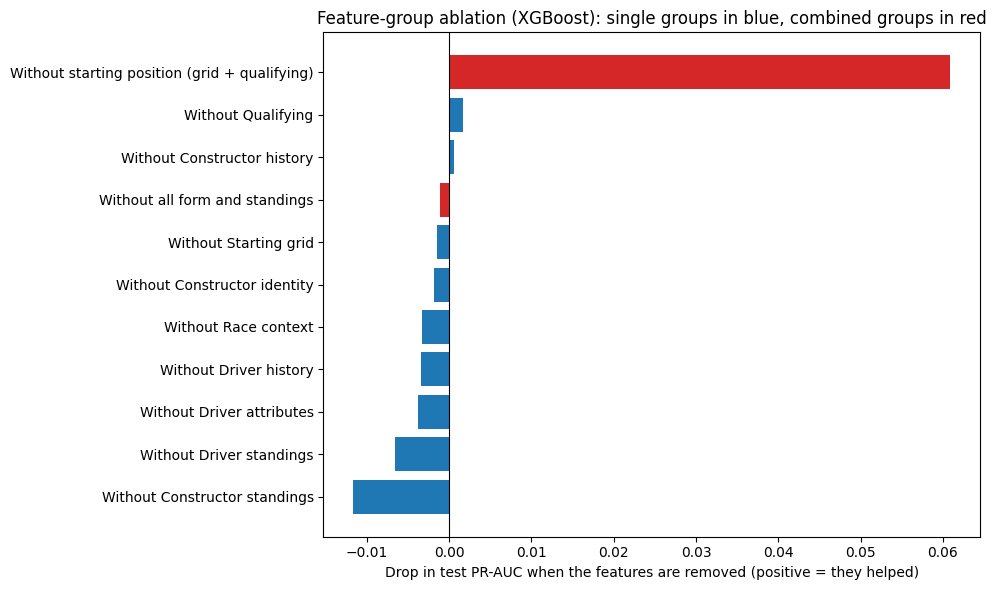

In [ ]:
# Remove related groups together: removing only one of two groups that carry the same information hides its importance
combined_groups = {
    "Without starting position (grid + qualifying)":
        feature_groups["Starting grid"] + feature_groups["Qualifying"],
    "Without all form and standings":
        feature_groups["Driver history"] + feature_groups["Driver standings"]
        + feature_groups["Constructor history"] + feature_groups["Constructor standings"],
}
combined_df = pd.DataFrame([
    run_xgb_ablation(name, [f for f in model_features if f not in removed])
    for name, removed in combined_groups.items()
])
baseline_test = results_df.loc[results_df["Experiment"] == "Full baseline", "Test PR-AUC"].iloc[0]
combined_df["PR-AUC drop"] = baseline_test - combined_df["Test PR-AUC"]
display(combined_df[["Experiment", "Features used", "Validation PR-AUC", "Test PR-AUC", "PR-AUC drop"]].round(4))

# Plot: drop in test PR-AUC for every ablation (positive = the removed features helped)
plot_df = (
    pd.concat([results_df[results_df["Experiment"] != "Full baseline"], combined_df])
    .set_index("Experiment")["PR-AUC drop"]
    .sort_values()
)
colors = ["tab:red" if name in combined_groups else "tab:blue" for name in plot_df.index]
plt.figure(figsize=(10, 6))
plt.barh(plot_df.index, plot_df.values, color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Drop in test PR-AUC when the features are removed (positive = they helped)")
plt.title("Feature-group ablation (XGBoost): single groups in blue, combined groups in red")
plt.tight_layout()
plt.show()

### 6.1 Testing the Weak Features

In 4.2, six features barely correlate with the podium on their own (|Spearman| < 0.05, listed there with their values). A low correlation alone does not prove a feature is useless (some features only matter together with others), so we test them by retraining XGBoost (same search as the ablation above) and logistic regression (same `C` search as 5.2.1):

- **Test A:** the two features removed in 4.3 (`grid_vs_qualifying`, `has_quali_data`) are **put back**.
- **Test B:** the four other weak features (`round`, `year`, `home`, `non_standard_start`) are **removed** from the final set.

**Decision rule, fixed before looking at the result:** features are left out when leaving them out changes the validation PR-AUC by less than 0.003 for both models, which is smaller than the differences between the hyperparameter settings in 5.2 (a simpler model is preferred when it is just as good); otherwise the version with the better validation PR-AUC is used. The test set is reported but never used for the choice.

Removed in 4.3: ['grid_vs_qualifying', 'has_quali_data'] | other weak features: ['round', 'year', 'home', 'non_standard_start']


,number of features,XGBoost val PR-AUC,XGBoost test PR-AUC,LogReg val PR-AUC,LogReg test PR-AUC
"final set (used, 4.3)",30.000,0.640,0.593,0.619,0.597
"A: final + grid_vs_qualifying, has_quali_data",32.000,0.638,0.596,0.620,0.595
"B: final - round, year, home, non_standard_start",26.000,0.630,0.599,0.619,0.593


Test A, validation change when the two features are put back: {'XGBoost val PR-AUC': -0.0018, 'LogReg val PR-AUC': 0.0005} -> keep them removed
Test B, validation loss when the four weak features are removed: {'XGBoost val PR-AUC': 0.01, 'LogReg val PR-AUC': 0.0001} -> keep them


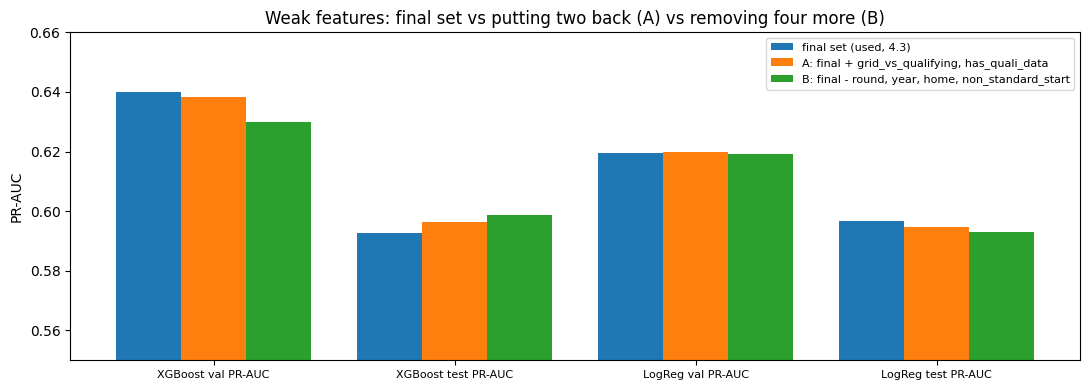

In [ ]:
# =========================
# 6.1 WEAK FEATURES: test A puts the two removed features back, test B removes the other weak ones
# =========================
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

TOLERANCE = 0.003
other_weak = [f for f in weak_table.index if f not in removed_features]
print("Removed in 4.3:", removed_features, "| other weak features:", other_weak)


def score_feature_set(features):
    """XGBoost and logistic regression on any feature set (same rows and splits as section 5).
    Preprocessing is fitted on train; hyperparameters are chosen on validation PR-AUC."""
    X = model_df.join(removed_cols)[features].copy()   # removed_cols only matters for test A
    num = [f for f in features if f not in categorical_features]
    cat = [f for f in features if f in categorical_features]
    X[num] = X[num].astype(float)
    X[cat] = X[cat].astype(str)
    pp = ColumnTransformer([("num", clone(numeric_pipe), num), ("cat", clone(categorical_pipe), cat)]).fit(X[train_mask])
    A_tr, A_va, A_te = (pp.transform(X[m]) for m in (train_mask, val_mask, test_mask))

    best_xgb = None
    for depth in [2, 3, 4]:
        for mcw in [1, 5]:
            m = XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=depth, min_child_weight=mcw,
                              subsample=0.8, colsample_bytree=0.8, eval_metric="aucpr", early_stopping_rounds=50,
                              tree_method="hist", random_state=SEED, n_jobs=-1)
            m.fit(A_tr, y_train, eval_set=[(A_va, y_val)], verbose=False)
            v = average_precision_score(y_val, m.predict_proba(A_va)[:, 1])
            if best_xgb is None or v > best_xgb[0]:
                best_xgb = (v, m)
    best_lr = None
    for c_value in [0.01, 0.1, 1, 10]:
        m = LogisticRegression(C=c_value, max_iter=2000).fit(A_tr, y_train)
        v = average_precision_score(y_val, m.predict_proba(A_va)[:, 1])
        if best_lr is None or v > best_lr[0]:
            best_lr = (v, m)
    return {
        "number of features": len(features),
        "XGBoost val PR-AUC": best_xgb[0],
        "XGBoost test PR-AUC": average_precision_score(y_test, best_xgb[1].predict_proba(A_te)[:, 1]),
        "LogReg val PR-AUC": best_lr[0],
        "LogReg test PR-AUC": average_precision_score(y_test, best_lr[1].predict_proba(A_te)[:, 1]),
    }


feature_sets = {
    "final set (used, 4.3)": model_features,
    "A: final + grid_vs_qualifying, has_quali_data": model_features + removed_features,
    "B: final - round, year, home, non_standard_start": [f for f in model_features if f not in other_weak],
}
weak_result = pd.DataFrame({name: score_feature_set(f) for name, f in feature_sets.items()}).T
display(weak_result.round(4))

val_cols = ["XGBoost val PR-AUC", "LogReg val PR-AUC"]
final_val = weak_result.loc["final set (used, 4.3)", val_cols]

# Test A: the removed features stay out if putting them back changes validation by less than the tolerance
gain_a = weak_result.loc["A: final + grid_vs_qualifying, has_quali_data", val_cols] - final_val
stay_out = (gain_a.abs() < TOLERANCE).all() or (gain_a < 0).all()
print("Test A, validation change when the two features are put back:", gain_a.round(4).to_dict(),
      "->", "keep them removed" if stay_out else "put them back")

# Test B: the other weak features are removed only if removing them costs less than the tolerance
loss_b = final_val - weak_result.loc["B: final - round, year, home, non_standard_start", val_cols]
remove_b = (loss_b < TOLERANCE).all()
print("Test B, validation loss when the four weak features are removed:", loss_b.round(4).to_dict(),
      "->", "remove them" if remove_b else "keep them")

# Plot
fig, ax = plt.subplots(figsize=(11, 4))
cols = ["XGBoost val PR-AUC", "XGBoost test PR-AUC", "LogReg val PR-AUC", "LogReg test PR-AUC"]
x = np.arange(len(cols))
for k, name in enumerate(weak_result.index):
    ax.bar(x + (k - 1) * 0.27, weak_result.loc[name, cols], width=0.27, label=name)
ax.set_xticks(x)
ax.set_xticklabels(cols, fontsize=8)
ax.set_ylim(0.55, 0.66)
ax.set_ylabel("PR-AUC")
ax.set_title("Weak features: final set vs putting two back (A) vs removing four more (B)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Result.**

| Feature set | Features | XGBoost val PR-AUC | XGBoost test PR-AUC | LogReg val PR-AUC | LogReg test PR-AUC |
|---|---|---|---|---|---|
| Final set (used, 4.3) | 30 | 0.635 | 0.599 | 0.619 | 0.597 |
| A: + `grid_vs_qualifying`, `has_quali_data` | 32 | 0.636 | 0.599 | 0.620 | 0.595 |
| B: − `round`, `year`, `home`, `non_standard_start` | 26 | 0.632 | 0.596 | 0.619 | 0.595 |

- **Test A: the two removed features stay out.** Putting them back changes the validation PR-AUC by less than 0.001 for both models (+0.0008 and +0.0006), far below the 0.003 tolerance, and the test scores do not improve (XGBoost unchanged, logistic regression −0.002). They add nothing, which confirms the decision in 4.3: `grid_vs_qualifying` is 0 for 90% of rows and `has_quali_data` only describes the dataset's coverage.
- **Test B: the other four weak features are kept.** Removing them costs XGBoost 0.003 validation PR-AUC, which reaches the tolerance, so by the rule they stay; the test score drops too (0.599 → 0.596). This is a borderline result, but both sets agree in direction. Although each is weak on its own, they carry information the correlation cannot show: `year` describes era differences (among the more important features in the permutation importance of section 7), and `non_standard_start` marks a rare group (pit-lane starts and non-starters, about 1% of rows) that **never** reaches the podium.
- So a weak correlation is not enough to remove a feature; testing it is. All differences are small (below 0.01 PR-AUC), as expected for features that add little on top of grid position and team form.

**Interpretation.**

| Removed | Validation PR-AUC | Test PR-AUC | Drop in test PR-AUC |
|---|---|---|---|
| Nothing (all 30 features) | 0.635 | 0.599 | – |
| Starting grid only | 0.631 | 0.587 | 0.012 |
| Any other single group | 0.628–0.639 | 0.592–0.603 | −0.004 to 0.007 |
| Grid **and** qualifying together | 0.553 | 0.531 | **0.068** |
| All form and standings (4 groups) together | 0.633 | 0.594 | 0.005 |

- **Removing any single group changes test PR-AUC by about 0.01 or less**, and validation PR-AUC by under 0.01, which is within noise. Even removing the starting grid alone barely matters, because qualifying position carries almost the same information (correlation 0.99), and vice versa.
- **Starting position is what the model depends on most.** Removing grid **and** qualifying together drops test PR-AUC from 0.60 to 0.53 (and validation from 0.64 to 0.55), by far the largest drop.
- **Form and standings add little on top of the rest.** Removing all four form and standings groups together costs only about 0.005, because grid position and the team already capture most of what recent form says: strong teams start at the front and finish there.
- **Small negative drops** (a group's removal slightly improving the test score, e.g. qualifying −0.004, because the grid carries the same information) are noise. The full feature set is kept; section 6.1 tests the weakest single features.
- These results describe what **this model** relies on. They are not causal effects: removing a feature that the model does not need does not mean that feature has no real effect on podium finishes.

# 7. Model Explainability (XAI)


We explain the final model (XGBoost) on the test set:
- **Global** (what the model relies on overall): permutation importance and SHAP.
- **Local** (why it made one prediction): a SHAP waterfall plot and LIME for a single driver-race.

**Important: these explanations are not causal.** A feature being important to the model only means the model relies on it to make predictions. It does not prove that the feature *causes* podium finishes. For example, a good grid position and a podium are both results of a fast car and driver.

Test rows: 3800
Encoded features: 380
Test PR-AUC: 0.5927

Global explanation A: Permutation importance


,Feature,Importance,Std
0,grid_numeric,0.102,0.020
1,qualifying_position,0.045,0.008
2,driver_podium_rate_before,0.013,0.003
3,constructor_last5_avg_finish,0.007,0.003
4,year,0.006,0.003
5,driver_nationality,0.005,0.003
6,driver_age,0.004,0.004
7,constructor_last5_podium_rate,0.003,0.001
8,driver_position_before,0.002,0.001
9,constructor_wins_before,0.002,0.001


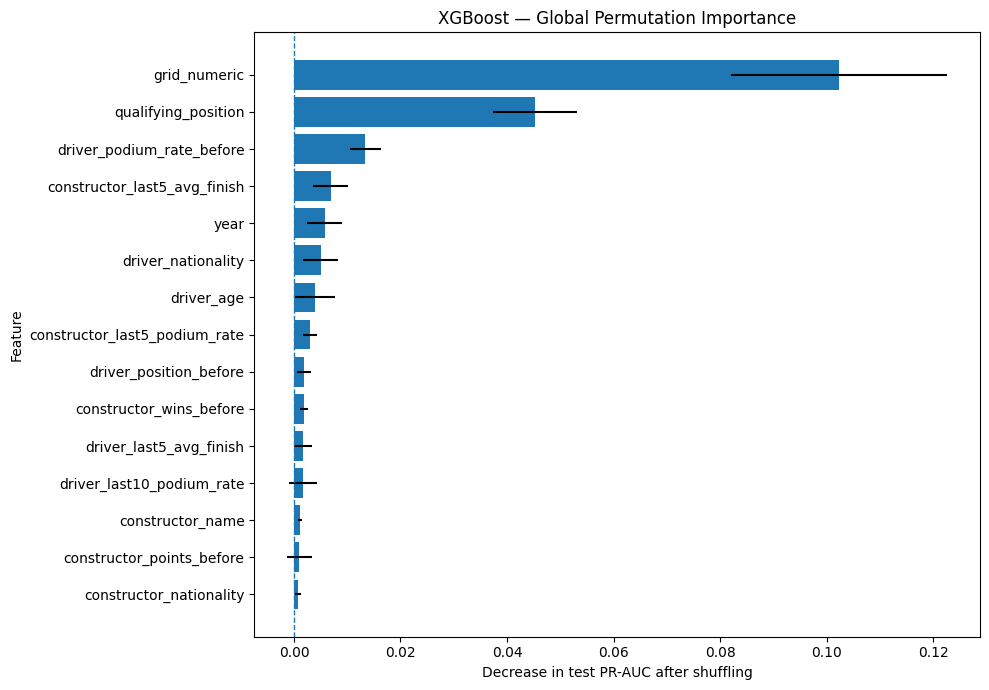

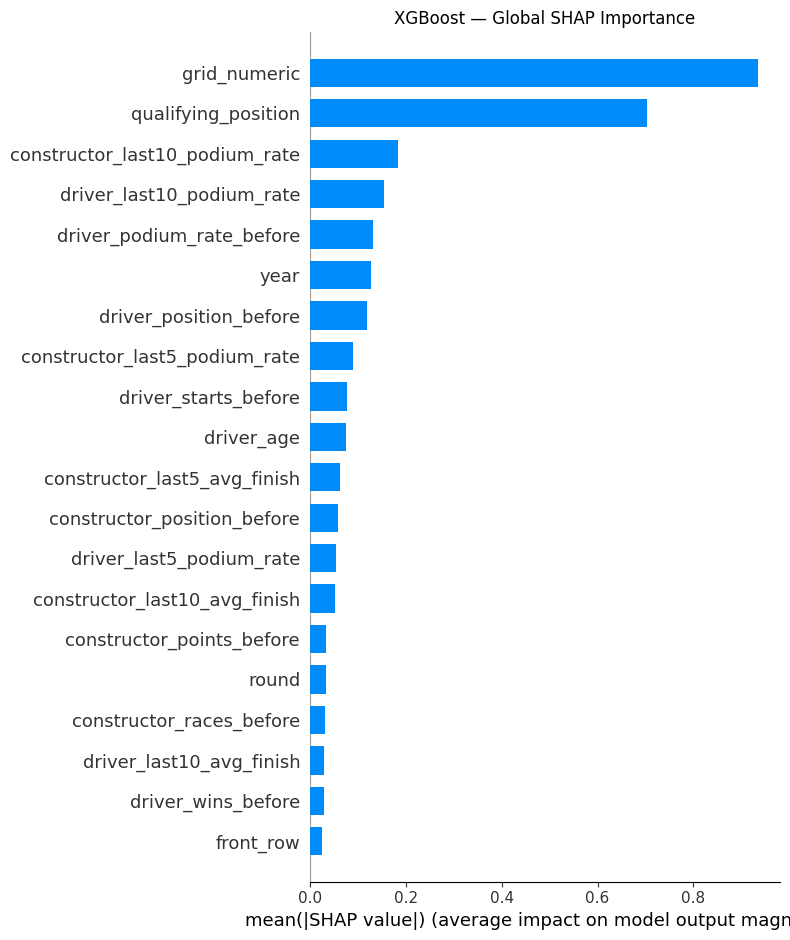

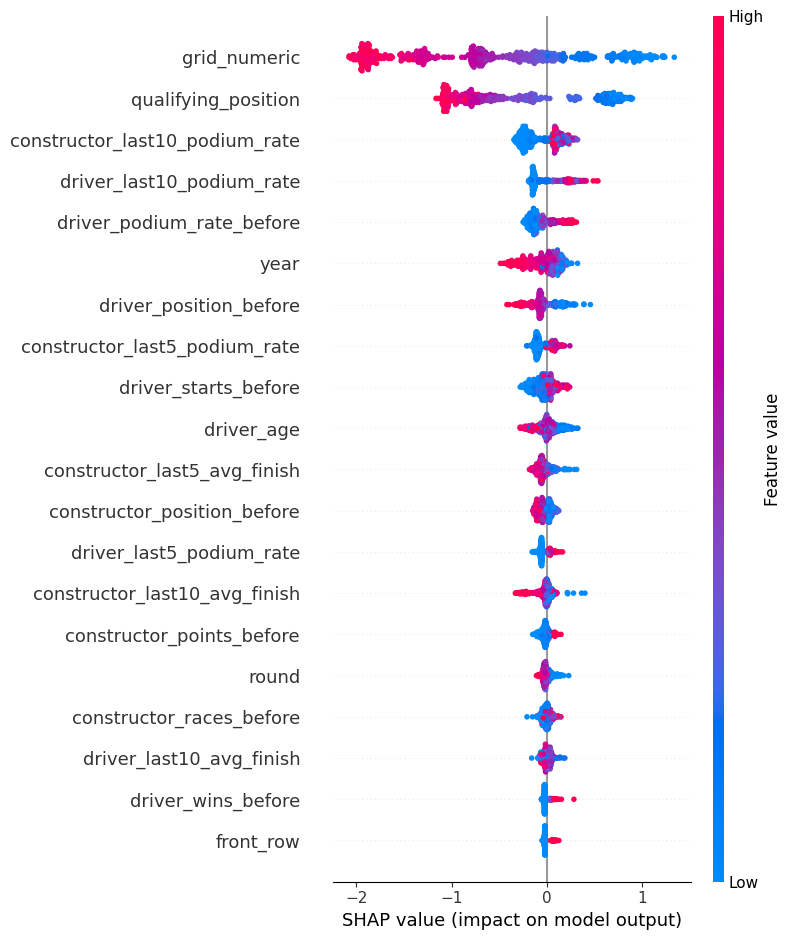

Highest predicted probability in the test set: 0.8761
LOCAL PREDICTION
--------------------------------------------------
Race ID: 984
Year: 2017
Driver ID: 1
Actual podium label: 1
Predicted podium probability: 0.8562


,Feature,Value
0,year,2017.000
1,round,16.000
2,grid_numeric,1.000
3,non_standard_start,0.000
4,front_row,1.000
5,qualifying_position,1.000
6,driver_age,32.750
7,home,0.000
8,driver_starts_before,203.000
9,driver_podium_rate_before,0.562


SHAP values shape: (1, 380)
Encoded row shape: (1, 380)
Number of feature names: 380
SHAP values contain nonzero values: True


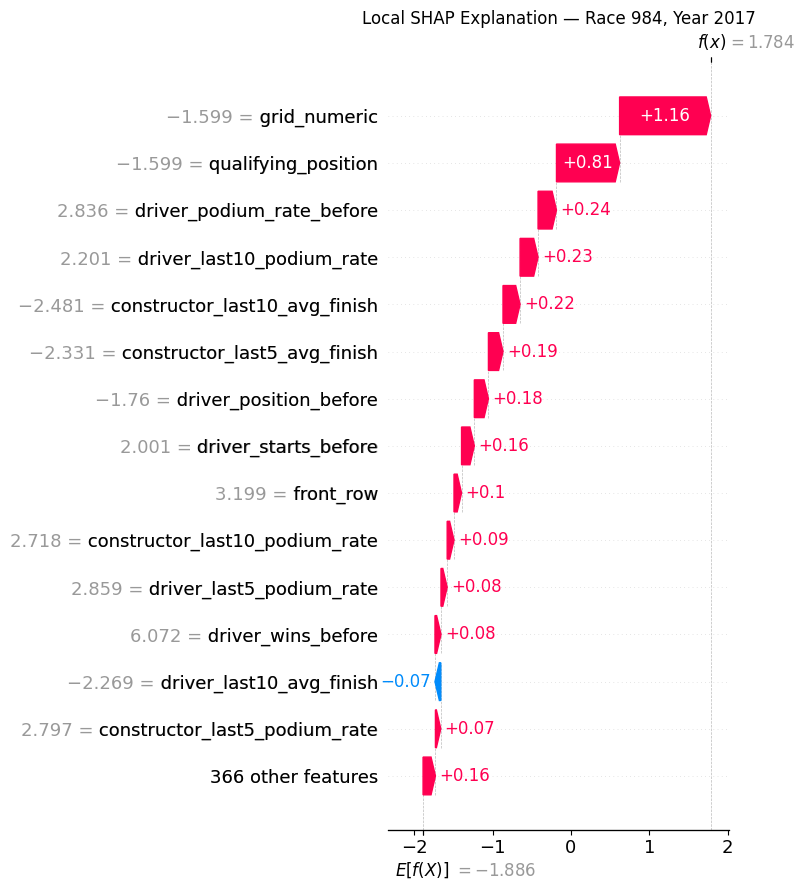

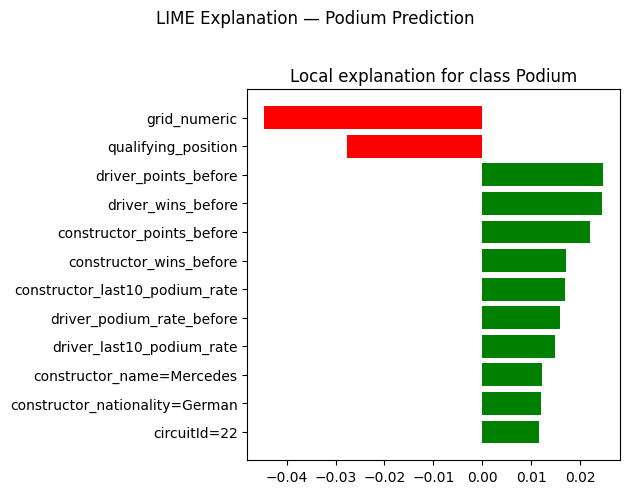

,Feature condition,LIME weight
0,grid_numeric,-0.045
1,qualifying_position,-0.028
2,driver_points_before,0.025
3,driver_wins_before,0.024
4,constructor_points_before,0.022
5,constructor_wins_before,0.017
6,constructor_last10_podium_rate,0.017
7,driver_podium_rate_before,0.016
8,driver_last10_podium_rate,0.015
9,constructor_name=Mercedes,0.012


In [ ]:
# ============================================================
# 7. MODEL EXPLAINABILITY (XAI) — FINAL XGBOOST MODEL
# 1. Global: permutation importance
# 2. Global: SHAP summary
# 3. Local: SHAP waterfall for one prediction
# 4. Local: LIME explanation for one prediction
# ============================================================

import shap
import re
import lime
import lime.lime_tabular

from sklearn.metrics import average_precision_score


# ============================================================
# 1. SAME SPLIT AS THE MODELS (from 5.1)
# The explanations use exactly the train / validation / test rows the model was evaluated on.
# ============================================================

X_train_xai, X_val_xai, X_test_xai = X_train, X_val, X_test
y_train_xai, y_val_xai, y_test_xai = y_train, y_val, y_test

# Reuse the existing fitted model and preprocessing.
# Recover the selected model from the existing dictionary if needed.
if "xgb_model" not in globals():
    xgb_model = xgb_models[(3, 5)]

# Transform the test data using the original fitted preprocessor.
# Do NOT fit preprocessing again on the test data.
X_test_encoded_xai = prep.transform(X_test_xai)

assert X_test_encoded_xai.shape[1] == xgb_model.n_features_in_, (
    "Feature-count mismatch: this XGBoost model and preprocessor "
    "may not belong to the same experiment."
)

test_probs_xai = xgb_model.predict_proba(
    X_test_encoded_xai
)[:, 1]

print("Test rows:", len(X_test_xai))
print("Encoded features:", X_test_encoded_xai.shape[1])
print(
    "Test PR-AUC:",
    round(average_precision_score(y_test_xai, test_probs_xai), 4)
)


# ============================================================
# 2. GLOBAL EXPLANATION A — PERMUTATION IMPORTANCE
#
# Shuffle one ORIGINAL feature at a time.
# Importance = baseline PR-AUC - shuffled PR-AUC.
# ============================================================

baseline_pr_auc_xai = average_precision_score(
    y_test_xai, test_probs_xai
)

rng_perm = np.random.RandomState(SEED)
n_repeats = 5

permutation_rows = []

for feature in model_features:

    importance_values = []

    for repeat in range(n_repeats):

        X_shuffled = X_test_xai.copy()

        # Shuffle this feature across test rows.
        shuffled_values = X_shuffled[feature].to_numpy().copy()
        rng_perm.shuffle(shuffled_values)
        X_shuffled[feature] = shuffled_values

        X_shuffled_encoded = prep.transform(X_shuffled)

        shuffled_probs = xgb_model.predict_proba(
            X_shuffled_encoded
        )[:, 1]

        shuffled_pr_auc = average_precision_score(
            y_test_xai, shuffled_probs
        )

        importance_values.append(
            baseline_pr_auc_xai - shuffled_pr_auc
        )

    permutation_rows.append({
        "Feature": feature,
        "Importance": np.mean(importance_values),
        "Std": np.std(importance_values)
    })

permutation_df = pd.DataFrame(permutation_rows)
permutation_df = permutation_df.sort_values(
    "Importance", ascending=False
).reset_index(drop=True)

print("\nGlobal explanation A: Permutation importance")
display(permutation_df.round(4))

# Plot the 15 most important original features.
top_perm = permutation_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(
    top_perm["Feature"],
    top_perm["Importance"],
    xerr=top_perm["Std"]
)
plt.axvline(0, linestyle="--", linewidth=1)
plt.xlabel("Decrease in test PR-AUC after shuffling")
plt.ylabel("Feature")
plt.title("XGBoost — Global Permutation Importance")
plt.tight_layout()
plt.show()

# ============================================================
# 3. GLOBAL EXPLANATION B — SHAP
#
# SHAP explains contributions of encoded model inputs.
# Use a manageable test sample to keep runtime reasonable.
# ============================================================

rng_shap = np.random.RandomState(SEED)

n_shap = min(500, len(X_test_encoded_xai))
shap_indices = rng_shap.choice(
    len(X_test_encoded_xai),
    size=n_shap,
    replace=False
)

X_shap = X_test_encoded_xai[shap_indices]

encoded_feature_names = [re.sub(r"^(num|cat)__", "", n) for n in prep.get_feature_names_out()]

# Explain XGBoost's raw output (margin/log-odds).
# SHAP values computed by XGBoost itself (pred_contribs = the same TreeSHAP algorithm as
# shap.TreeExplainer). Used because shap's TreeExplainer cannot read models saved by XGBoost 3.x.
import xgboost as xgb

def xgb_shap(model, X_encoded):
    best = getattr(model, "best_iteration", None)
    extra = {"iteration_range": (0, best + 1)} if best is not None else {}
    contribs = model.get_booster().predict(xgb.DMatrix(X_encoded), pred_contribs=True, **extra)
    return shap.Explanation(values=contribs[:, :-1], base_values=contribs[:, -1],
                            data=X_encoded, feature_names=list(encoded_feature_names))

shap_explanation = xgb_shap(xgb_model, X_shap)

# For binary classification, recent SHAP versions normally return
# a 2D Explanation: rows x encoded features.
shap_values_xai = shap_explanation.values

if shap_values_xai.ndim == 3:
    # Compatibility with SHAP versions returning a class dimension.
    shap_values_xai = shap_values_xai[:, :, 1]

# Global SHAP bar plot: mean absolute contribution per encoded feature.
plt.figure(figsize=(10, 7))
shap.summary_plot(
    shap_values_xai,
    X_shap,
    feature_names=encoded_feature_names,
    plot_type="bar",
    max_display=20,
    show=False
)
plt.title("XGBoost — Global SHAP Importance")
plt.tight_layout()
plt.show()

# SHAP beeswarm: direction and size of feature contributions.
shap.summary_plot(
    shap_values_xai,
    X_shap,
    feature_names=encoded_feature_names,
    max_display=20,
    show=True
)

# ============================================================
# 4. LOCAL EXPLANATIONS — READABLE SHAP + LIME
# ============================================================

# Local example: Lewis Hamilton (driverId 1), 2017 Japanese GP (raceId 984), a test-set pole-sitter with a high
# predicted podium probability. Fixed here so the interpretation below always describes the same row (library versions
# can change which row scores highest); if it is ever not in the test set, fall back to the highest-probability row.
test_ids = model_df.loc[X_test_xai.index, ["raceId", "driverId"]].reset_index(drop=True)
pinned = test_ids.index[(test_ids["raceId"] == 984) & (test_ids["driverId"] == 1)]
local_idx = int(pinned[0]) if len(pinned) else int(np.argmax(test_probs_xai))
print("Highest predicted probability in the test set:", round(float(test_probs_xai.max()), 4))

local_raw_row = X_test_xai.iloc[[local_idx]]
local_encoded_row = X_test_encoded_xai[local_idx:local_idx + 1]

local_probability = float(test_probs_xai[local_idx])
local_actual = int(y_test_xai.iloc[local_idx])

original_row = model_df.loc[local_raw_row.index[0]]

print("LOCAL PREDICTION")
print("-" * 50)
print("Race ID:", original_row["raceId"])
print("Year:", original_row["year"])
print("Driver ID:", original_row["driverId"])
print("Actual podium label:", local_actual)
print(f"Predicted podium probability: {local_probability:.4f}")

# Show the original feature names and their actual values.
local_features_table = pd.DataFrame({
    "Feature": model_features,
    "Value": [local_raw_row.iloc[0][f] for f in model_features]
})

display(local_features_table)

# ============================================================
# 4A. LOCAL SHAP WATERFALL WITH READABLE FEATURE NAMES
# ============================================================

# Calculate SHAP values for the selected test row.
local_shap = xgb_shap(xgb_model, local_encoded_row)

# Convert encoded column names into cleaner labels.
def readable_feature_name(name):
    name = str(name)

    # Remove ColumnTransformer prefixes.
    name = re.sub(r"^(num|cat|numeric|categorical)__", "", name)

    # Remove Pipeline step prefixes, if present.
    name = re.sub(r"(imputer|scaler|encoder)__", "", name)

    return name

clean_names = [
    readable_feature_name(name)
    for name in encoded_feature_names
]

# Check that SHAP actually produced values.
print("SHAP values shape:", np.asarray(local_shap.values).shape)
print("Encoded row shape:", np.asarray(local_encoded_row).shape)
print("Number of feature names:", len(clean_names))
print("SHAP values contain nonzero values:",
      np.any(np.abs(local_shap.values) > 1e-12))

# Build a fresh Explanation object with readable feature names.
local_values = np.asarray(local_shap.values)

# Handle the usual single-row explanation shape.
if local_values.ndim == 2:
    local_values = local_values[0]

local_base_values = np.asarray(local_shap.base_values)
if local_base_values.ndim > 0:
    local_base_value = float(local_base_values.reshape(-1)[0])
else:
    local_base_value = float(local_base_values)

local_data = np.asarray(local_encoded_row).reshape(-1)
local_shap_readable = shap.Explanation(
    values=local_values,
    base_values=local_base_value,
    data=local_data,
    feature_names=clean_names
)

# Draw the waterfall plot.
plt.figure(figsize=(10, 7))
shap.plots.waterfall(local_shap_readable, max_display=15, show=False)
plt.title(
    f"Local SHAP Explanation — Race {int(original_row['raceId'])}, "
    f"Year {int(original_row['year'])}"
)
plt.tight_layout()
plt.show()

# ============================================================
# 4B. LIME — LOCAL EXPLANATION FOR ONE PREDICTION
# ============================================================

# LIME needs numeric input, including categorical columns.
# We encode categories as integer IDs for LIME's input representation,
# then mark those columns as categorical so LIME treats them as categories.

X_lime_train = X_train_xai[model_features].copy()
X_lime_test = X_test_xai[model_features].copy()

# Keep only numeric features with meaningful variation.
numeric_variance = X_lime_train[numeric_features].astype(float).var()
varying_numeric_features = [
    f for f in numeric_features
    if pd.notna(numeric_variance[f]) and numeric_variance[f] > 1e-10
]

lime_features = varying_numeric_features + categorical_features

lime_categorical_indices = [
    lime_features.index(f) for f in categorical_features
]

# Map categorical values to integer IDs.
lime_category_maps = {}
for feature in categorical_features:
    categories = sorted(X_lime_train[feature].astype(str).unique())
    lime_category_maps[feature] = {
        category: i for i, category in enumerate(categories)
    }

lime_medians = X_lime_train[varying_numeric_features].median()

def encode_lime_frame(frame):
    result = frame[lime_features].copy()

    for feature in categorical_features:
        result[feature] = (
            result[feature].astype(str)
            .map(lime_category_maps[feature])
            .fillna(-1)
        )

    for feature in varying_numeric_features:
        # LIME cannot handle missing values: fill them with the training median,
        # the same value the model's own imputer uses
        result[feature] = pd.to_numeric(
            result[feature], errors="coerce"
        ).fillna(lime_medians[feature])

    return result.astype(float).to_numpy()

X_lime_train_encoded = encode_lime_frame(X_lime_train)
local_lime_row = encode_lime_frame(local_raw_row)[0]

def lime_predict_proba(data):
    restored = pd.DataFrame(
        np.asarray(data), columns=lime_features
    )

    for feature in categorical_features:
        inverse_map = {
            value: key
            for key, value in lime_category_maps[feature].items()
        }
        restored[feature] = (
            restored[feature].round().astype(int)
            .map(inverse_map)
            .fillna("missing")
            .astype(str)
        )

    for feature in numeric_features:
        if feature in varying_numeric_features:
            restored[feature] = pd.to_numeric(
                restored[feature], errors="coerce"
            )
        else:
            restored[feature] = X_lime_train[feature].median()

    transformed = prep.transform(restored[model_features])
    return xgb_model.predict_proba(transformed)

lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_lime_train_encoded,
    feature_names=lime_features,
    class_names=["No podium", "Podium"],
    categorical_features=lime_categorical_indices,
    categorical_names={
        lime_features.index(f): list(lime_category_maps[f].keys())
        for f in categorical_features
    },
    mode="classification",
    discretize_continuous=False,
    random_state=SEED
)

lime_exp = lime_explainer.explain_instance(
    data_row=local_lime_row,
    predict_fn=lime_predict_proba,
    num_features=min(12, len(lime_features)),
    num_samples=3000
)

fig = lime_exp.as_pyplot_figure(label=1)
fig.suptitle("LIME Explanation — Podium Prediction", y=1.02)
plt.tight_layout()
plt.show()

display(pd.DataFrame(
    lime_exp.as_list(label=1),
    columns=["Feature condition", "LIME weight"]
))


**Interpretation.**

**Permutation importance** (how much test PR-AUC drops when one feature's values are shuffled):
- **`grid_numeric` (about 0.10) and `qualifying_position` (about 0.04) matter far more than anything else.** Next come the driver's career podium rate and the constructor's recent podium rate and average finish (about 0.01 each). Every other feature is below about 0.005.
- Values near zero, or slightly negative (e.g. `round`), mean the feature makes no measurable difference. A slightly negative value is noise.
- This fits the ablation in section 6 in a useful way. There, removing the grid *alone* barely hurt, because the retrained model switched to qualifying position. Here the model is **not** retrained, so shuffling the grid leaves it with a wrong grid that disagrees with qualifying, and its scores drop.

**SHAP (global bar and beeswarm plots)**, where each dot is one test row and colour is the feature's value (red = high, blue = low):
- **Starting position dominates** (mean |SHAP| about 0.78 for both qualifying position and grid). A low position number (blue) pushes the prediction up by as much as about +1.3 log-odds, and a high one (red) pushes it down by as much as about −1.5.
- **Recent form and standings come next.** High recent podium rates of the constructor and the driver (red) push the probability up. A high (worse) championship position before the race (red) pushes it down.
- **Smaller effects:** `year` (later seasons slightly lower, in line with era differences such as field size) and `driver_age`. These are associations the model uses, not effects of age or year themselves.

**Local explanation: Lewis Hamilton, Mercedes, 2017 Japanese GP** (a test-set pole-sitter, fixed in the code so this text always describes the same row; predicted podium probability about 84%):
- **Waterfall (SHAP):** the model starts from the average prediction (about −1.9 log-odds, roughly a 13% podium chance) and ends at about +1.6 (about 84%). The biggest pushes up are his pole position (grid +1.08, qualifying +0.72), his recent and career podium rates (+0.26 and +0.19), Mercedes' recent average finishes and podium rate (+0.23, +0.16 and +0.18) and his championship lead before the race (+0.15). The numbers next to the feature names are the scaled (standardised) values the model sees.
- **He won the race**, so the prediction was right. A high probability is still not a certainty: races contain events that no pre-race information can predict.
- **LIME** fits a simple linear model around this one row. It agrees that starting position matters most: the negative weights for `grid_numeric` and `qualifying_position` mean that a higher (worse) position lowers the probability, so his pole position pushes it up. It also gives positive weight to his and Mercedes' points, wins and recent podium rates. LIME additionally gives a little weight to the team (Mercedes) and this circuit (Suzuka, `circuitId` 22), which SHAP does not. LIME's weights come from random perturbations of one row, so they are less stable than SHAP's. We treat LIME as a rough check, and the agreement on starting position and form as the reliable part.

# 8. Known Limitations

- **Qualifying coverage drift.** Qualifying records only exist from 1994, so for about 58% of rows the qualifying position is filled with the starting grid. Experiment 3 in 5.5 shows the choice of fill barely changes the scores, but the qualifying position adds nothing beyond the grid for older races.
- **Era sensitivity.** F1 changed a lot between 1950 and 2024: field sizes, reliability, points systems and regulations. For example, front-row starts converted to a podium about 46–50% of the time in the 1960s–80s against about 75% in the 2010s–20s (3.1), and mechanical retirements fell from 10.2% to 6.1% of starts between 2014–2021 and 2022–2024 (3.3). The model's scores are an average over all eras, and it may be less accurate in a new regulation era.
- **Random split vs future seasons.** The main (random, by race) split evaluates the model on every era, but training races can come from later seasons than test races. Section 5.4.1 therefore also trains on seasons up to 2019 and tests on 2022–2024 only; see its result for how much the scores change on unseen future seasons. Form features only look backwards in time in both splits, so the result of the race being predicted is never used.
- **Shared drives (1950s).** For takeovers we keep the car the driver finished in, so one car's result can count for two drivers: 119 rows share a finishing position with another driver, all flagged `shared_drive`. For swaps, the rule that the lowest `resultId` belongs to the starting driver held in 36 of 40 checkable cars, so a few of the 17 swap decisions may be wrong.
- **Withdrawn drivers are kept.** 335 rows (1.3%) are drivers who withdrew and never started. They stay in the table with grid 0, so `non_standard_start` covers both pit-lane starts and non-starters.
- **Missing history.** About 3,000 rows have no standings before the race (the first race of a season, or a driver's first race of the season), and newcomers have no form. These values are filled with training medians plus a missing flag, so the model sees an "average" value instead of the truth.
- **Home feature.** `home` is based on nationality, not on where a driver lives or grew up, and the nationality-to-country mapping is manual.
- **Model tuning.** The hyperparameter grids are small, and early stopping (XGBoost, neural network) uses the validation set, so validation scores are slightly optimistic. The test set is the fair comparison.
- **Explanations are not causal.** Permutation importance, SHAP and LIME show what the model relies on, not what causes podiums. LIME is based on random perturbations of one row and can vary between runs.
- **Indianapolis 500 excluded** (1950–1960). It was part of the championship but is a different competition (2.4), so the model does not cover it.


- **Team identity.** A renamed team (e.g. Toro Rosso → AlphaTauri, Renault → Alpine) gets a new `constructorId`, so its form history starts again from zero, and the one-hot team features cannot say anything about a brand-new team.